In [47]:
#import zipfile
import mne
import os
from sklearn.model_selection import train_test_split
from mne.decoding import CSP
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    cohen_kappa_score
)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split

In [48]:
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_validate
import gc
import pandas as pd

In [49]:
#%pip install torch braindecode

In [50]:
import torch
import braindecode

print("Torch:", torch.__version__)
print("Braindecode:", braindecode.__version__)

Torch: 2.14.0
Braindecode: 1.8.1


In [51]:
from braindecode.models import EEGNet
from torch.utils.data import TensorDataset, DataLoader
import random
from scipy.io import loadmat
import torch.nn as nn
import torch.nn.functional as F

In [52]:
# zip_path = "/Users/irina/Desktop/master project/BCICIV_2a_gdf.zip"
# extract_path = "/Users/irina/Desktop/master project/BCICIV_2a_gdf"

# with zipfile.ZipFile(zip_path, "r") as zip_ref:
#     zip_ref.extractall(extract_path)

# print("Готово, архив распакован")

In [53]:
# files = os.listdir(extract_path)
# print(files)

In [54]:
file_path = "/Users/irina/Desktop/master project/BCICIV_2a_gdf/A01T.gdf"

raw = mne.io.read_raw_gdf(
    file_path,
    preload=True
)

print(raw)

<RawGDF | A01T.gdf, 25 x 672528 (2690.1 s), ~128.3 MiB, data loaded>


In [55]:
print("Количество каналов:", raw.info["nchan"])
print("Частота дискретизации:", raw.info["sfreq"], "Гц")
print("Длительность:", raw.times[-1], "сек")
print("Длительность:", raw.times[-1] / 60, "мин")

print("\nНазвания каналов:")
print(raw.ch_names)

Количество каналов: 25
Частота дискретизации: 250.0 Гц
Длительность: 2690.108 сек
Длительность: 44.83513333333334 мин

Названия каналов:
['EEG-Fz', 'EEG-0', 'EEG-1', 'EEG-2', 'EEG-3', 'EEG-4', 'EEG-5', 'EEG-C3', 'EEG-6', 'EEG-Cz', 'EEG-7', 'EEG-C4', 'EEG-8', 'EEG-9', 'EEG-10', 'EEG-11', 'EEG-12', 'EEG-13', 'EEG-14', 'EEG-Pz', 'EEG-15', 'EEG-16', 'EOG-left', 'EOG-central', 'EOG-right']


In [56]:
for i, channel in enumerate(raw.ch_names):
    print(i, channel)

0 EEG-Fz
1 EEG-0
2 EEG-1
3 EEG-2
4 EEG-3
5 EEG-4
6 EEG-5
7 EEG-C3
8 EEG-6
9 EEG-Cz
10 EEG-7
11 EEG-C4
12 EEG-8
13 EEG-9
14 EEG-10
15 EEG-11
16 EEG-12
17 EEG-13
18 EEG-14
19 EEG-Pz
20 EEG-15
21 EEG-16
22 EOG-left
23 EOG-central
24 EOG-right


In [57]:
raw.set_channel_types({
    "EOG-left": "eog",
    "EOG-central": "eog",
    "EOG-right": "eog"
})

print(raw.get_channel_types())

['eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eog', 'eog', 'eog']


In [58]:
events, event_id = mne.events_from_annotations(raw)

print("События:")
print(event_id)

print("\nКоличество событий:", len(events))
print("\nПервые 10 событий:")
print(events[:10])

События:
{'1023': 1, '1072': 2, '276': 3, '277': 4, '32766': 5, '768': 6, '769': 7, '770': 8, '771': 9, '772': 10}

Количество событий: 603

Первые 10 событий:
[[    0     0     5]
 [    0     0     3]
 [29683     0     5]
 [29683     0     4]
 [49955     0     5]
 [49955     0     2]
 [91518     0     5]
 [91868     0     6]
 [92368     0    10]
 [93871     0     6]]


In [59]:
motor_imagery_event_id = {
    "left_hand": event_id["769"],
    "right_hand": event_id["770"],
    "feet": event_id["771"],
    "tongue": event_id["772"]
}

In [60]:
for name, code in motor_imagery_event_id.items():
    count = (events[:, 2] == code).sum()
    print(name, count)

left_hand 72
right_hand 72
feet 72
tongue 72


перед вырезанием эпох нам сначала нужно сделать базовую фильтрацию EEG. Для motor imagery обычно смотрят диапазон примерно 8–30 Гц, потому что там находятся важные для движений mu и beta ритмы.

In [61]:
raw_filtered = raw.copy().filter(
    l_freq=8,
    h_freq=30
)

print("Фильтрация завершена")

Фильтрация завершена


режем длинную 45-минутную запись на отдельные попытки.

In [62]:
epochs = mne.Epochs(
    raw_filtered,
    events,
    event_id=motor_imagery_event_id,
    tmin=0.5,
    tmax=4.0,
    baseline=None,
    preload=True
)

print(epochs)

<Epochs | 288 events (all good), 0.5 – 4 s (baseline off), ~48.1 MiB, data loaded,
 'left_hand': 72
 'right_hand': 72
 'feet': 72
 'tongue': 72>


In [63]:
X = epochs.get_data()
y = epochs.events[:, 2]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("Уникальные классы:", set(y))

X shape: (288, 25, 876)
y shape: (288,)
Уникальные классы: {np.int64(8), np.int64(9), np.int64(10), np.int64(7)}


In [64]:
epochs_eeg = epochs.copy().pick("eeg")

X = epochs_eeg.get_data()
y = epochs_eeg.events[:, 2]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (288, 22, 876)
y shape: (288,)


делаем train/test spli

In [65]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (230, 22, 876)
X_test: (58, 22, 876)
y_train: (230,)
y_test: (58,)


baseline для motor imagery: CSP + LDA.

In [66]:
csp = CSP(n_components=6, reg=None, log=True, norm_trace=False)
lda = LinearDiscriminantAnalysis()

model = Pipeline([
    ("csp", csp),
    ("lda", lda)
])

model.fit(X_train, y_train)

print("Модель обучена")

Модель обучена


In [67]:
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Balanced accuracy:", balanced_accuracy_score(y_test, y_pred))
print("Macro F1:", f1_score(y_test, y_pred, average="macro"))
print("Cohen's kappa:", cohen_kappa_score(y_test, y_pred))


Accuracy: 0.7068965517241379
Balanced accuracy: 0.713095238095238
Macro F1: 0.693048713738369
Cohen's kappa: 0.6105845181674565


На первом этапе был собран базовый пайплайн классификации motor imagery для одного испытуемого из BCI Competition IV 2a. 

ЭЭГ была отфильтрована в диапазоне 8–30 Гц, разделена на эпохи 0.5–4 с после предъявления команды, из данных исключены EOG-каналы. В качестве baseline использована модель CSP + LDA.

На тестовой выборке получены: accuracy 0.707, balanced accuracy 0.713, macro-F1 0.693, Cohen’s kappa 0.611. Результат заметно выше случайного уровня 25% для четырёх классов, поэтому можно считать, что базовый пайплайн работает корректно и извлекает полезную информацию из ЭЭГ. При этом текущий результат получен на случайном train/test split внутри одной сессии одного испытуемого, поэтому далее потребуется более строгая схема валидации и анализ ошибок по классам.

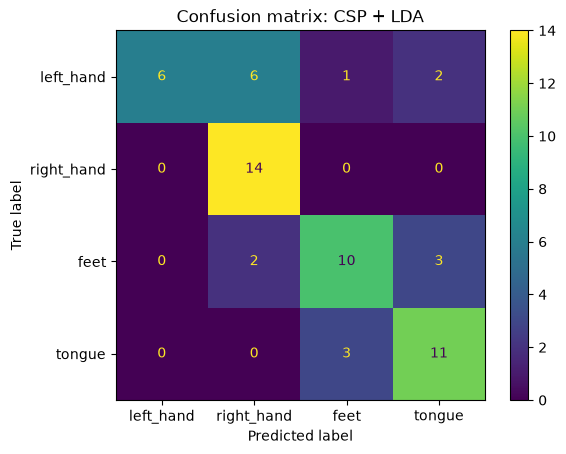

In [68]:
labels = [7, 8, 9, 10]
class_names = ["left_hand", "right_hand", "feet", "tongue"]

cm = confusion_matrix(y_test, y_pred, labels=labels)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot()
plt.title("Confusion matrix: CSP + LDA")
plt.show()

По confusion matrix видно, что модель лучше всего распознаёт класс right_hand, а хуже всего — left_hand. Основная ошибка связана с тем, что сигналы для левой руки часто классифицируются как правая рука. Классы feet и tongue различаются лучше, хотя между ними тоже есть отдельные ошибки. Это показывает, что общий baseline уже работает, но качество по классам неоднородно.

попробуем CSP + SVM

In [69]:
svm = SVC(kernel="rbf", C=1)

model_svm = Pipeline([
    ("csp", CSP(n_components=6, reg=None, log=True, norm_trace=False)),
    ("svm", svm)
])

model_svm.fit(X_train, y_train)

print("CSP + SVM обучена")

CSP + SVM обучена


In [70]:
y_pred_svm = model_svm.predict(X_test)

In [71]:
print("Accuracy:", accuracy_score(y_test, y_pred_svm))
print("Balanced accuracy:", balanced_accuracy_score(y_test, y_pred_svm))
print("Macro F1:", f1_score(y_test, y_pred_svm, average="macro"))
print("Cohen's kappa:", cohen_kappa_score(y_test, y_pred_svm))

Accuracy: 0.7586206896551724
Balanced accuracy: 0.7619047619047619
Macro F1: 0.7569952397538604
Cohen's kappa: 0.6787974683544303


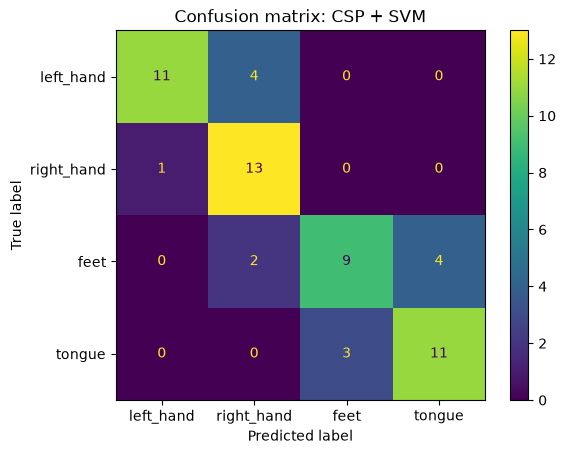

In [72]:
cm_svm = confusion_matrix(y_test, y_pred_svm, labels=[7, 8, 9, 10])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_svm,
    display_labels=["left_hand", "right_hand", "feet", "tongue"]
)

disp.plot()
plt.title("Confusion matrix: CSP + SVM")
plt.show()

Замена LDA на SVM улучшила качество классификации motor imagery. Balanced accuracy выросла с 0.713 до 0.762, macro-F1 — с 0.693 до 0.757, Cohen’s kappa — с 0.611 до 0.679. Особенно заметно улучшилось распознавание класса left_hand: число правильных классификаций выросло с 6 до 11 из 15. Это говорит о том, что признаки CSP достаточно информативны, а более гибкий классификатор SVM лучше разделяет классы.

Подготовим данные для EEGNe

In [73]:
mean = X_train.mean(axis=(0, 2), keepdims=True)
std = X_train.std(axis=(0, 2), keepdims=True)

X_train_norm = (X_train - mean) / std
X_test_norm = (X_test - mean) / std

print("X_train_norm:", X_train_norm.shape)
print("X_test_norm:", X_test_norm.shape)

X_train_norm: (230, 22, 876)
X_test_norm: (58, 22, 876)


validation split

In [74]:
X_train_nn, X_val_nn, y_train_nn, y_val_nn = train_test_split(
    X_train_norm,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Train:", X_train_nn.shape, y_train_nn.shape)
print("Validation:", X_val_nn.shape, y_val_nn.shape)
print("Test:", X_test_norm.shape, y_test.shape)

Train: (184, 22, 876) (184,)
Validation: (46, 22, 876) (46,)
Test: (58, 22, 876) (58,)


In [75]:
label_map = {
    7: 0,   # left_hand
    8: 1,   # right_hand
    9: 2,   # feet
    10: 3   # tongue
}

y_train_nn_0 = np.array([label_map[v] for v in y_train_nn])
y_val_nn_0 = np.array([label_map[v] for v in y_val_nn])
y_test_0 = np.array([label_map[v] for v in y_test])

print(np.unique(y_train_nn_0))

[0 1 2 3]


In [76]:
eegnet = EEGNet(
    n_chans=22,
    n_outputs=4,
    n_times=876,
    sfreq=250
)

print(eegnet)

Layer (type (var_name):depth-idx)                            Input Shape               Output Shape              Param #                   Kernel Shape
EEGNet (EEGNet)                                              [1, 22, 876]              [1, 4]                    --                        --
├─Ensure4d (ensuredims): 1-1                                 [1, 22, 876]              [1, 22, 876, 1]           --                        --
├─Rearrange (dimshuffle): 1-2                                [1, 22, 876, 1]           [1, 1, 22, 876]           --                        --
├─Conv2d (conv_temporal): 1-3                                [1, 1, 22, 876]           [1, 8, 22, 877]           512                       [1, 64]
├─BatchNorm2d (bnorm_temporal): 1-4                          [1, 8, 22, 877]           [1, 8, 22, 877]           16                        --
├─ParametrizedConv2dWithConstraint (conv_spatial): 1-5       [1, 8, 22, 877]           [1, 16, 1, 877]           --                  

превратить наши NumPy-массивы в формат PyTorch и подготовить данные для обучения.

In [77]:
X_train_tensor = torch.tensor(X_train_nn, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_nn_0, dtype=torch.long)

X_val_tensor = torch.tensor(X_val_nn, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val_nn_0, dtype=torch.long)

X_test_tensor = torch.tensor(X_test_norm, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test_0, dtype=torch.long)

print("Train:", X_train_tensor.shape, y_train_tensor.shape)
print("Validation:", X_val_tensor.shape, y_val_tensor.shape)
print("Test:", X_test_tensor.shape, y_test_tensor.shape)

Train: torch.Size([184, 22, 876]) torch.Size([184])
Validation: torch.Size([46, 22, 876]) torch.Size([46])
Test: torch.Size([58, 22, 876]) torch.Size([58])


создадим DataLoader:

In [78]:
train_loader = DataLoader(
    TensorDataset(X_train_tensor, y_train_tensor),
    batch_size=16,
    shuffle=True
)

val_loader = DataLoader(
    TensorDataset(X_val_tensor, y_val_tensor),
    batch_size=16,
    shuffle=False
)

test_loader = DataLoader(
    TensorDataset(X_test_tensor, y_test_tensor),
    batch_size=16,
    shuffle=False
)

print("Количество train-батчей:", len(train_loader))

Количество train-батчей: 12


задаём функцию ошибки и оптимизатор

In [79]:
import torch.nn as nn

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    eegnet.parameters(),
    lr=0.001
)

print("Loss и optimizer готовы")

Loss и optimizer готовы


сам цикл обучения. Для начала сделаем 30 эпох:

In [80]:
num_epochs = 30

for epoch in range(num_epochs):
    eegnet.train()

    train_loss = 0
    train_correct = 0
    train_total = 0

    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()

        outputs = eegnet(X_batch)
        loss = criterion(outputs, y_batch)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()

        preds = outputs.argmax(dim=1)
        train_correct += (preds == y_batch).sum().item()
        train_total += y_batch.size(0)

    eegnet.eval()

    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            outputs = eegnet(X_batch)

            preds = outputs.argmax(dim=1)

            val_correct += (preds == y_batch).sum().item()
            val_total += y_batch.size(0)

    train_acc = train_correct / train_total
    val_acc = val_correct / val_total

    print(
        f"Epoch {epoch+1:02d} | "
        f"loss={train_loss / len(train_loader):.4f} | "
        f"train_acc={train_acc:.3f} | "
        f"val_acc={val_acc:.3f}"
    )

Epoch 01 | loss=1.3746 | train_acc=0.293 | val_acc=0.304
Epoch 02 | loss=1.2829 | train_acc=0.467 | val_acc=0.217
Epoch 03 | loss=1.1816 | train_acc=0.505 | val_acc=0.239
Epoch 04 | loss=1.0514 | train_acc=0.620 | val_acc=0.304
Epoch 05 | loss=0.9290 | train_acc=0.625 | val_acc=0.239
Epoch 06 | loss=0.8700 | train_acc=0.630 | val_acc=0.217
Epoch 07 | loss=0.7791 | train_acc=0.668 | val_acc=0.217
Epoch 08 | loss=0.8053 | train_acc=0.641 | val_acc=0.283
Epoch 09 | loss=0.7451 | train_acc=0.668 | val_acc=0.283
Epoch 10 | loss=0.6813 | train_acc=0.696 | val_acc=0.283
Epoch 11 | loss=0.7000 | train_acc=0.696 | val_acc=0.304
Epoch 12 | loss=0.5987 | train_acc=0.772 | val_acc=0.326
Epoch 13 | loss=0.5918 | train_acc=0.804 | val_acc=0.261
Epoch 14 | loss=0.6052 | train_acc=0.739 | val_acc=0.326
Epoch 15 | loss=0.5407 | train_acc=0.815 | val_acc=0.348
Epoch 16 | loss=0.5354 | train_acc=0.810 | val_acc=0.326
Epoch 17 | loss=0.5295 | train_acc=0.815 | val_acc=0.348
Epoch 18 | loss=0.4855 | train_

По логу видно такую картину: train_acc вырос до 0.891, а val_acc к 30-й эпохе только до 0.587. Это признак того, что сеть уже начинает переобучаться: на обучающих данных она становится очень хорошей, а на новых данных качество заметно ниже.

In [81]:
eegnet.eval()

y_pred_eegnet = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        outputs = eegnet(X_batch)
        preds = outputs.argmax(dim=1)
        y_pred_eegnet.extend(preds.cpu().numpy())

y_pred_eegnet = np.array(y_pred_eegnet)

In [82]:
print("Accuracy:", accuracy_score(y_test_0, y_pred_eegnet))
print("Balanced accuracy:", balanced_accuracy_score(y_test_0, y_pred_eegnet))
print("Macro F1:", f1_score(y_test_0, y_pred_eegnet, average="macro"))
print("Cohen's kappa:", cohen_kappa_score(y_test_0, y_pred_eegnet))

Accuracy: 0.5517241379310345
Balanced accuracy: 0.5571428571428572
Macro F1: 0.5302998010798523
Cohen's kappa: 0.4027722772277228


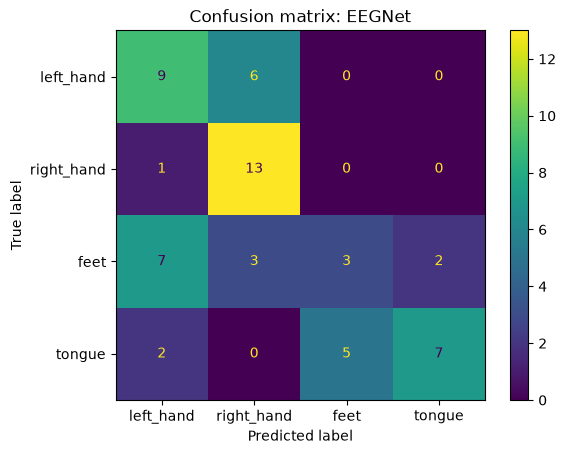

In [83]:
cm_eegnet = confusion_matrix(
    y_test_0,
    y_pred_eegnet,
    labels=[0, 1, 2, 3]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_eegnet,
    display_labels=["left_hand", "right_hand", "feet", "tongue"]
)

disp.plot()
plt.title("Confusion matrix: EEGNet")
plt.show()

На текущем объёме данных классические модели CSP + LDA/SVM показали существенно более высокое качество, чем EEGNet. Лучший результат получен для CSP + SVM: balanced accuracy 0.762 и macro-F1 0.757. EEGNet достигла balanced accuracy 0.455, при этом наблюдалось переобучение: качество на train заметно превышало validation. Вероятная причина — недостаточный объём данных для обучения нейросети на одном испытуемом.

5-fold cross-validation для CSP + SVM. Сейчас наш результат 0.762 balanced accuracy зависит от одного конкретного случайного разбиения на train/test. Нам надо проверить, не повезло ли нам с этим split.

In [84]:
model_svm_cv = Pipeline([
    (
        "csp",
        CSP(
            n_components=6,
            reg=None,
            log=True,
            norm_trace=False
        )
    ),
    (
        "svm",
        SVC(
            kernel="rbf",
            C=1
        )
    )
])

In [85]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [86]:
scores = cross_validate(
    model_svm_cv,
    X,
    y,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "balanced_accuracy": "balanced_accuracy",
        "f1_macro": "f1_macro"
    }
)

In [87]:
print("Accuracy:", scores["test_accuracy"])
print("Balanced accuracy:", scores["test_balanced_accuracy"])
print("Macro F1:", scores["test_f1_macro"])

Accuracy: [0.81034483 0.81034483 0.77586207 0.75438596 0.80701754]
Balanced accuracy: [0.80833333 0.81071429 0.7797619  0.75952381 0.80357143]
Macro F1: [0.81137385 0.80968595 0.7669136  0.74578704 0.80444843]


In [88]:
print(
    "Mean balanced accuracy:",
    scores["test_balanced_accuracy"].mean()
)

print(
    "Std balanced accuracy:",
    scores["test_balanced_accuracy"].std()
)

Mean balanced accuracy: 0.7923809523809524
Std balanced accuracy: 0.019771942373358758


Для испытуемого A01 модель CSP + SVM показала стабильное качество при 5-fold cross-validation. Средняя balanced accuracy составила 0.792 ± 0.020. Небольшой разброс между фолдами говорит о том, что результат не является следствием одного удачного разбиения train/test.

перейдем к другим людям:
>Этап 1
A01–A09
→ CSP + SVM
→ 5-fold CV
→ таблица по каждому испытуемому

>Этап 2
A01–A09
→ EEGNet
→ train/val/test или CV
→ таблица по каждому испытуемому

>Этап 3
сравнение:
CSP+SVM vs EEGNet

прогоняем CSP + SVM на всех 9 испытуемых.

In [89]:
def evaluate_subject(file_path):
    raw = mne.io.read_raw_gdf(file_path, preload=True, verbose=False)

    raw.set_channel_types({
        "EOG-left": "eog",
        "EOG-central": "eog",
        "EOG-right": "eog"
    })

    raw_filtered = raw.copy().filter(
        l_freq=8,
        h_freq=30,
        verbose=False
    )

    events, event_id = mne.events_from_annotations(
        raw_filtered,
        verbose=False
    )

    motor_imagery_event_id = {
        "left_hand": event_id["769"],
        "right_hand": event_id["770"],
        "feet": event_id["771"],
        "tongue": event_id["772"]
    }

    epochs = mne.Epochs(
        raw_filtered,
        events,
        event_id=motor_imagery_event_id,
        tmin=0.5,
        tmax=4.0,
        baseline=None,
        preload=True,
        verbose=False
    )

    epochs_eeg = epochs.copy().pick("eeg")

    X = epochs_eeg.get_data()
    y = epochs_eeg.events[:, 2]

    model = Pipeline([
        (
            "csp",
            CSP(
                n_components=6,
                reg=None,
                log=True,
                norm_trace=False
            )
        ),
        (
            "svm",
            SVC(
                kernel="rbf",
                C=1
            )
        )
    ])

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    scores = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "balanced_accuracy": "balanced_accuracy",
            "f1_macro": "f1_macro"
        }
    )

    return {
        "accuracy_mean": scores["test_accuracy"].mean(),
        "balanced_accuracy_mean": scores["test_balanced_accuracy"].mean(),
        "balanced_accuracy_std": scores["test_balanced_accuracy"].std(),
        "f1_macro_mean": scores["test_f1_macro"].mean()
    }

In [90]:
file_path_a01 = "/Users/irina/Desktop/master project/BCICIV_2a_gdf/A01T.gdf"


In [91]:
mne.set_log_level("ERROR")

result_a01 = evaluate_subject(file_path_a01)

print(f"Accuracy: {result_a01['accuracy_mean']:.3f}")
print(
    f"Balanced accuracy: "
    f"{result_a01['balanced_accuracy_mean']:.3f} "
    f"± {result_a01['balanced_accuracy_std']:.3f}"
)
print(f"Macro F1: {result_a01['f1_macro_mean']:.3f}")

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Accuracy: 0.792
Balanced accuracy: 0.792 ± 0.020
Macro F1: 0.788


In [92]:
base_path = "/Users/irina/Desktop/master project/BCICIV_2a_gdf"

results = []

for subject_num in range(1, 10):
    subject = f"A{subject_num:02d}"
    file_path = os.path.join(base_path, f"{subject}T.gdf")

    print(f"Обрабатываем {subject}...")

    result = evaluate_subject(file_path)

    results.append({
        "subject": subject,
        "accuracy_mean": result["accuracy_mean"],
        "balanced_accuracy_mean": result["balanced_accuracy_mean"],
        "balanced_accuracy_std": result["balanced_accuracy_std"],
        "f1_macro_mean": result["f1_macro_mean"]
    })

    gc.collect()

results_df = pd.DataFrame(results)

results_df

Обрабатываем A01...


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Обрабатываем A02...


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Обрабатываем A03...


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


... (9 outputs left out)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Обрабатываем A09...


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


,subject,accuracy_mean,balanced_accuracy_mean,balanced_accuracy_std,f1_macro_mean
0,A01,0.791591,0.792381,0.019772,0.787642
1,A02,0.642710,0.642857,0.079425,0.638861
2,A03,0.850454,0.850000,0.040769,0.851726
3,A04,0.461645,0.461905,0.028562,0.457740
4,A05,0.385662,0.387381,0.031529,0.368661
5,A06,0.423835,0.423571,0.037739,0.419558
6,A07,0.798669,0.799762,0.051779,0.798233
7,A08,0.823230,0.822143,0.067333,0.821928
8,A09,0.610889,0.610952,0.045147,0.599927


При оценке CSP + SVM отдельно для каждого из 9 испытуемых качество классификации существенно различается. Средняя balanced accuracy составила около 0.64, при этом результаты варьировались от 0.39 до 0.85. Это показывает выраженную межсубъектную вариабельность EEG и подтверждает, что качество motor imagery классификации сильно зависит от индивидуальных особенностей сигнала.

In [93]:
mean_ba = results_df["balanced_accuracy_mean"].mean()
std_ba = results_df["balanced_accuracy_mean"].std()

mean_acc = results_df["accuracy_mean"].mean()
mean_f1 = results_df["f1_macro_mean"].mean()

print(f"Mean Accuracy: {mean_acc:.3f}")
print(f"Mean Balanced Accuracy: {mean_ba:.3f} ± {std_ba:.3f}")
print(f"Mean Macro F1: {mean_f1:.3f}")

Mean Accuracy: 0.643
Mean Balanced Accuracy: 0.643 ± 0.183
Mean Macro F1: 0.638


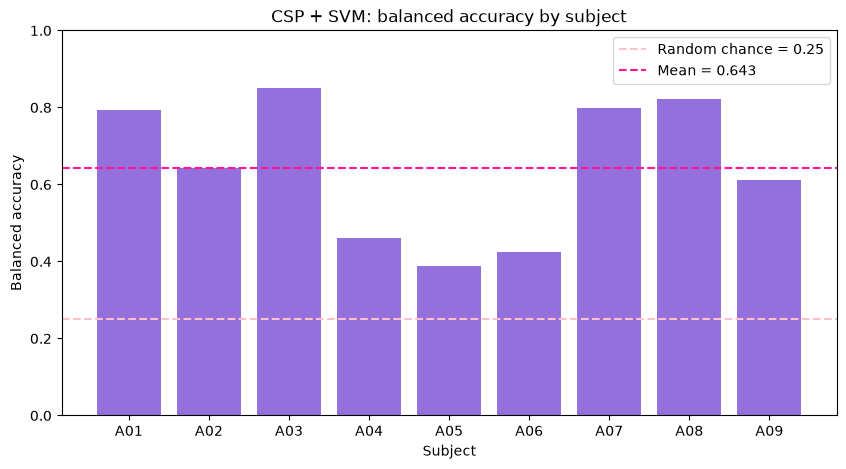

In [94]:
plt.figure(figsize=(10, 5))

plt.bar(
    results_df["subject"],
    results_df["balanced_accuracy_mean"],
    color="mediumpurple"
)

plt.axhline(
    y=0.25,
    linestyle="--",
    color="pink",
    label="Random chance = 0.25"
)

plt.axhline(
    y=mean_ba,
    linestyle="--",
    color="deeppink",
    label=f"Mean = {mean_ba:.3f}"
)

plt.ylim(0, 1)
plt.xlabel("Subject")
plt.ylabel("Balanced accuracy")
plt.title("CSP + SVM: balanced accuracy by subject")
plt.legend()

plt.show()

переходим к EEGNet по всем 9 испытуемым

функция, которая только готовит данные для одного испытуемого

In [95]:
def prepare_subject_for_eegnet(file_path):
    raw = mne.io.read_raw_gdf(
        file_path,
        preload=True,
        verbose=False
    )

    raw.set_channel_types({
        "EOG-left": "eog",
        "EOG-central": "eog",
        "EOG-right": "eog"
    })

    raw_filtered = raw.copy().filter(
        l_freq=8,
        h_freq=30,
        verbose=False
    )

    events, event_id = mne.events_from_annotations(
        raw_filtered,
        verbose=False
    )

    motor_imagery_event_id = {
        "left_hand": event_id["769"],
        "right_hand": event_id["770"],
        "feet": event_id["771"],
        "tongue": event_id["772"]
    }

    epochs = mne.Epochs(
        raw_filtered,
        events,
        event_id=motor_imagery_event_id,
        tmin=0.5,
        tmax=4.0,
        baseline=None,
        preload=True,
        verbose=False
    )

    epochs_eeg = epochs.copy().pick("eeg")

    X = epochs_eeg.get_data()
    y = epochs_eeg.events[:, 2]

    label_map = {
        motor_imagery_event_id["left_hand"]: 0,
        motor_imagery_event_id["right_hand"]: 1,
        motor_imagery_event_id["feet"]: 2,
        motor_imagery_event_id["tongue"]: 3
    }

    y = np.array([label_map[v] for v in y])

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    mean = X_train.mean(axis=(0, 2), keepdims=True)
    std = X_train.std(axis=(0, 2), keepdims=True)

    X_train = (X_train - mean) / std
    X_test = (X_test - mean) / std

    X_train, X_val, y_train, y_val = train_test_split(
        X_train,
        y_train,
        test_size=0.2,
        random_state=42,
        stratify=y_train
    )

    return X_train, X_val, X_test, y_train, y_val, y_test

In [96]:
file_path_a01 = "/Users/irina/Desktop/master project/BCICIV_2a_gdf/A01T.gdf"

X_train_nn, X_val_nn, X_test_nn, y_train_nn, y_val_nn, y_test_nn = \
    prepare_subject_for_eegnet(file_path_a01)

print("Train:", X_train_nn.shape, y_train_nn.shape)
print("Validation:", X_val_nn.shape, y_val_nn.shape)
print("Test:", X_test_nn.shape, y_test_nn.shape)

print("Train classes:", np.unique(y_train_nn))
print("Validation classes:", np.unique(y_val_nn))
print("Test classes:", np.unique(y_test_nn))

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Train: (184, 22, 876) (184,)
Validation: (46, 22, 876) (46,)
Test: (58, 22, 876) (58,)
Train classes: [0 1 2 3]
Validation classes: [0 1 2 3]
Test classes: [0 1 2 3]


функция обучения EEGNet для одного испытуемого.

In [97]:
def train_eegnet(
    X_train,
    X_val,
    X_test,
    y_train,
    y_val,
    y_test,
    num_epochs=30,
    batch_size=16,
    learning_rate=0.001
):
    X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
    y_train_tensor = torch.tensor(y_train, dtype=torch.long)

    X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
    y_val_tensor = torch.tensor(y_val, dtype=torch.long)

    X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
    y_test_tensor = torch.tensor(y_test, dtype=torch.long)

    train_loader = DataLoader(
        TensorDataset(X_train_tensor, y_train_tensor),
        batch_size=batch_size,
        shuffle=True
    )

    val_loader = DataLoader(
        TensorDataset(X_val_tensor, y_val_tensor),
        batch_size=batch_size,
        shuffle=False
    )

    test_loader = DataLoader(
        TensorDataset(X_test_tensor, y_test_tensor),
        batch_size=batch_size,
        shuffle=False
    )

    model = EEGNet(
        n_chans=22,
        n_outputs=4,
        n_times=876,
        sfreq=250
    )

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    best_val_acc = 0
    best_state = None

    for epoch in range(num_epochs):
        model.train()

        for X_batch, y_batch in train_loader:
            optimizer.zero_grad()

            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)

            loss.backward()
            optimizer.step()

        model.eval()

        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                outputs = model(X_batch)
                preds = outputs.argmax(dim=1)

                val_correct += (preds == y_batch).sum().item()
                val_total += y_batch.size(0)

        val_acc = val_correct / val_total

        if val_acc > best_val_acc:
            best_val_acc = val_acc

            best_state = {
                k: v.cpu().clone()
                for k, v in model.state_dict().items()
            }

    model.load_state_dict(best_state)

    model.eval()

    y_pred = []

    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            outputs = model(X_batch)
            preds = outputs.argmax(dim=1)

            y_pred.extend(preds.cpu().numpy())

    y_pred = np.array(y_pred)

    return {
        "accuracy": accuracy_score(y_test, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
        "f1_macro": f1_score(y_test, y_pred, average="macro"),
        "kappa": cohen_kappa_score(y_test, y_pred),
        "best_val_accuracy": best_val_acc
    }

обчаем на АО1


In [98]:
X_train_nn, X_val_nn, X_test_nn, y_train_nn, y_val_nn, y_test_nn = \
    prepare_subject_for_eegnet(file_path_a01)

result_eegnet_a01 = train_eegnet(
    X_train_nn,
    X_val_nn,
    X_test_nn,
    y_train_nn,
    y_val_nn,
    y_test_nn
)

print(f"Accuracy: {result_eegnet_a01['accuracy']:.3f}")
print(f"Balanced accuracy: {result_eegnet_a01['balanced_accuracy']:.3f}")
print(f"Macro F1: {result_eegnet_a01['f1_macro']:.3f}")
print(f"Kappa: {result_eegnet_a01['kappa']:.3f}")
print(f"Best validation accuracy: {result_eegnet_a01['best_val_accuracy']:.3f}")

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Accuracy: 0.517
Balanced accuracy: 0.527
Macro F1: 0.475
Kappa: 0.359
Best validation accuracy: 0.630


Для A01 использование лучшей версии EEGNet по validation accuracy улучшило balanced accuracy с 0.455 до 0.543. Однако модель всё ещё уступает CSP+SVM, который на том же испытуемом показал около 0.79 balanced accuracy.

In [99]:
eegnet_results = []

for subject_num in range(1, 10):
    subject = f"A{subject_num:02d}"
    file_path = os.path.join(base_path, f"{subject}T.gdf")

    print(f"Обрабатываем {subject}...")

    # фиксируем случайность
    random.seed(42)
    np.random.seed(42)
    torch.manual_seed(42)

    X_train_nn, X_val_nn, X_test_nn, y_train_nn, y_val_nn, y_test_nn = \
        prepare_subject_for_eegnet(file_path)

    result = train_eegnet(
        X_train_nn,
        X_val_nn,
        X_test_nn,
        y_train_nn,
        y_val_nn,
        y_test_nn
    )

    eegnet_results.append({
        "subject": subject,
        "accuracy": result["accuracy"],
        "balanced_accuracy": result["balanced_accuracy"],
        "f1_macro": result["f1_macro"],
        "kappa": result["kappa"],
        "best_val_accuracy": result["best_val_accuracy"]
    })

    gc.collect()

eegnet_results_df = pd.DataFrame(eegnet_results)

eegnet_results_df

Обрабатываем A01...


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Обрабатываем A02...


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Обрабатываем A03...


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


... (9 outputs left out)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Обрабатываем A09...


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


,subject,accuracy,balanced_accuracy,f1_macro,kappa,best_val_accuracy
0,A01,0.603448,0.609524,0.584374,0.471683,0.630435
1,A02,0.310345,0.305952,0.295046,0.076433,0.326087
2,A03,0.724138,0.720238,0.713169,0.630867,0.608696
3,A04,0.275862,0.275000,0.237442,0.036011,0.369565
4,A05,0.224138,0.221429,0.171569,-0.036949,0.434783
5,A06,0.310345,0.305952,0.291094,0.074222,0.413043
6,A07,0.275862,0.271429,0.198544,0.029095,0.326087
7,A08,0.517241,0.510714,0.491032,0.351697,0.543478
8,A09,0.551724,0.545238,0.498724,0.401350,0.652174


EEGNet на данных отдельных испытуемых показывает существенно более низкое и более вариабельное качество по сравнению с CSP+SVM. Вероятная причина — недостаточный объём обучающих примеров для нейросетевой модели при subject-specific обучении.

In [100]:
comparison_df = results_df[
    ["subject", "balanced_accuracy_mean"]
].merge(
    eegnet_results_df[
        ["subject", "balanced_accuracy"]
    ],
    on="subject"
)

comparison_df = comparison_df.rename(columns={
    "balanced_accuracy_mean": "csp_svm_ba",
    "balanced_accuracy": "eegnet_ba"
})

comparison_df

,subject,csp_svm_ba,eegnet_ba
0,A01,0.792381,0.609524
1,A02,0.642857,0.305952
2,A03,0.850000,0.720238
3,A04,0.461905,0.275000
4,A05,0.387381,0.221429
5,A06,0.423571,0.305952
6,A07,0.799762,0.271429
7,A08,0.822143,0.510714
8,A09,0.610952,0.545238


In [101]:
print(
    "CSP + SVM mean BA:",
    comparison_df["csp_svm_ba"].mean()
)

print(
    "EEGNet mean BA:",
    comparison_df["eegnet_ba"].mean()
)

CSP + SVM mean BA: 0.6434391534391535
EEGNet mean BA: 0.4183862433862433


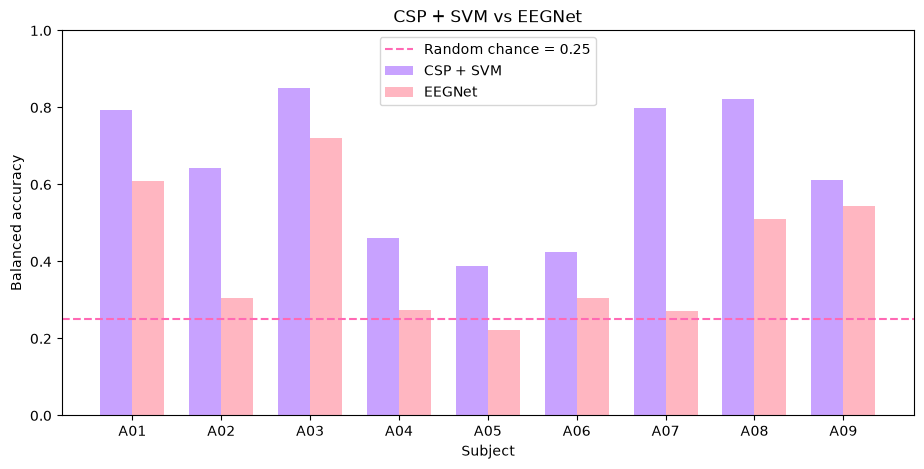

In [102]:
x = np.arange(len(comparison_df))
width = 0.36

plt.figure(figsize=(11, 5))

plt.bar(
    x - width / 2,
    comparison_df["csp_svm_ba"],
    width,
    label="CSP + SVM",
    color="#C8A2FF"
)

plt.bar(
    x + width / 2,
    comparison_df["eegnet_ba"],
    width,
    label="EEGNet",
    color="#FFB6C1"
)

plt.axhline(
    y=0.25,
    linestyle="--",
    color="#FF69B4",
    label="Random chance = 0.25"
)

plt.xticks(x, comparison_df["subject"])

plt.ylim(0, 1)
plt.xlabel("Subject")
plt.ylabel("Balanced accuracy")
plt.title("CSP + SVM vs EEGNet")
plt.legend()

plt.show()

В текущей subject-specific постановке объём данных недостаточен для стабильного обучения EEGNet. Классический CSP+SVM лучше работает на небольшом числе эпох.

Промежуточный вывод. CSP+SVM показывает более стабильное качество по всем испытуемым, тогда как EEGNet сильно зависит от конкретного человека и на части субъектов работает близко к случайному уровню. Вероятная причина — небольшой объём данных при обучении EEGNet отдельно на каждом испытуемом. Поэтому текущий вариант EEGNet пока нельзя считать достаточным нейросетевым baseline.

Дальше: переходим на более корректный протокол: AxxT используем для обучения и validation, а отдельную сессию AxxE — только для финального теста. На этом протоколе повторно сравним CSP+SVM и EEGNet по всем 9 испытуемым. Если EEGNet всё ещё будет нестабильна, попробуем увеличить объём обучающих данных за счёт нескольких испытуемых / pretraining. К denoising перейдём только после получения приемлемого baseline на исходном EEG.

Ссылки:
> https://chatgpt.com/c/6aa4fddd-1530-83ed-bacf-aebe06f9d98b#:~:text=EEGNet%2Dstyle%20benchmark%20results%20on%20GitHub

> https://www.mdpi.com/1099-4300/28/3/310

> https://www.mdpi.com/2076-3425/16/2/230

## протокол AxxT → train/validation, AxxE → test.

функция делает весь preprocessing для одного испытуемого сразу из двух файлов:

AxxT.gdf — для обучения,
AxxE.gdf — для финальной проверки.

In [103]:
# import zipfile
# import os

# labels_zip = "/Users/irina/Desktop/master project/true_labels.zip"
# labels_path = "/Users/irina/Desktop/master project/true_labels"

# with zipfile.ZipFile(labels_zip, "r") as zip_ref:
#     zip_ref.extractall(labels_path)

# print(os.listdir(labels_path))

In [104]:
labels_file = "/Users/irina/Desktop/master project/true_labels/A01E.mat"

mat = loadmat(labels_file)

print(mat.keys())

dict_keys(['__header__', '__version__', '__globals__', 'classlabel'])


In [105]:
y_test_true = mat["classlabel"].ravel()

print("Количество меток:", len(y_test_true))
print("Уникальные классы:", np.unique(y_test_true))
print("Первые 20 меток:", y_test_true[:20])

Количество меток: 288
Уникальные классы: [1 2 3 4]
Первые 20 меток: [1 2 2 1 2 1 2 3 2 4 1 3 2 1 4 4 4 4 4 1]


функция подготовки данных, которая принимает три файла:

A01T.gdf      → train/validation
A01E.gdf      → test EEG
A01E.mat      → настоящие test labels

A01T.gdf
→ фильтрация 8–30 Гц
→ выделение motor imagery эпох
→ 22 EEG-канала
→ train / validation
→ нормализация

A01E.gdf
→ такая же предобработка
→ 288 test-эпох

A01E.mat
→ настоящие test-метки

In [106]:
def prepare_subject_train_eval(
    train_file_path,
    eval_file_path,
    eval_labels_path
):
    # ---------- TRAIN SESSION ----------
    raw_train = mne.io.read_raw_gdf(
        train_file_path,
        preload=True,
        verbose=False
    )

    raw_train.set_channel_types({
        "EOG-left": "eog",
        "EOG-central": "eog",
        "EOG-right": "eog"
    })

    raw_train_filtered = raw_train.copy().filter(
        l_freq=8,
        h_freq=30,
        verbose=False
    )

    events_train, event_id_train = mne.events_from_annotations(
        raw_train_filtered,
        verbose=False
    )

    train_event_id = {
        "left_hand": event_id_train["769"],
        "right_hand": event_id_train["770"],
        "feet": event_id_train["771"],
        "tongue": event_id_train["772"]
    }

    epochs_train = mne.Epochs(
        raw_train_filtered,
        events_train,
        event_id=train_event_id,
        tmin=0.5,
        tmax=4.0,
        baseline=None,
        preload=True,
        verbose=False
    )

    epochs_train = epochs_train.copy().pick("eeg")

    X_train_full = epochs_train.get_data()
    y_train_full = epochs_train.events[:, 2]

    train_label_map = {
        train_event_id["left_hand"]: 0,
        train_event_id["right_hand"]: 1,
        train_event_id["feet"]: 2,
        train_event_id["tongue"]: 3
    }

    y_train_full = np.array([
        train_label_map[v] for v in y_train_full
    ])

    # ---------- EVAL SESSION ----------
    raw_test = mne.io.read_raw_gdf(
        eval_file_path,
        preload=True,
        verbose=False
    )

    raw_test.set_channel_types({
        "EOG-left": "eog",
        "EOG-central": "eog",
        "EOG-right": "eog"
    })

    raw_test_filtered = raw_test.copy().filter(
        l_freq=8,
        h_freq=30,
        verbose=False
    )

    events_test, event_id_test = mne.events_from_annotations(
        raw_test_filtered,
        verbose=False
    )

    # В evaluation-файле все motor imagery trials имеют код 783
    test_event_id = {
        "unknown_cue": event_id_test["783"]
    }

    epochs_test = mne.Epochs(
        raw_test_filtered,
        events_test,
        event_id=test_event_id,
        tmin=0.5,
        tmax=4.0,
        baseline=None,
        preload=True,
        verbose=False
    )

    epochs_test = epochs_test.copy().pick("eeg")

    X_test = epochs_test.get_data()

    # ---------- TRUE LABELS ----------
    mat = loadmat(eval_labels_path)

    y_test = mat["classlabel"].ravel()

    # В .mat классы 1,2,3,4 → для PyTorch делаем 0,1,2,3
    y_test = y_test - 1

    # ---------- TRAIN / VALIDATION ----------
    X_train, X_val, y_train, y_val = train_test_split(
        X_train_full,
        y_train_full,
        test_size=0.2,
        random_state=42,
        stratify=y_train_full
    )

    # ---------- NORMALIZATION ----------
    # Важно: mean/std считаем ТОЛЬКО по train
    mean = X_train.mean(axis=(0, 2), keepdims=True)
    std = X_train.std(axis=(0, 2), keepdims=True)

    X_train = (X_train - mean) / std
    X_val = (X_val - mean) / std
    X_test = (X_test - mean) / std

    return X_train, X_val, X_test, y_train, y_val, y_test

In [107]:
train_file_a01 = "/Users/irina/Desktop/master project/BCICIV_2a_gdf/A01T.gdf"
eval_file_a01 = "/Users/irina/Desktop/master project/BCICIV_2a_gdf/A01E.gdf"
labels_file_a01 = "/Users/irina/Desktop/master project/true_labels/A01E.mat"

X_train_te, X_val_te, X_test_te, y_train_te, y_val_te, y_test_te = \
    prepare_subject_train_eval(
        train_file_a01,
        eval_file_a01,
        labels_file_a01
    )

print("Train:", X_train_te.shape, y_train_te.shape)
print("Validation:", X_val_te.shape, y_val_te.shape)
print("Test:", X_test_te.shape, y_test_te.shape)

print("Train classes:", np.unique(y_train_te))
print("Validation classes:", np.unique(y_val_te))
print("Test classes:", np.unique(y_test_te))

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Train: (230, 22, 876) (230,)
Validation: (58, 22, 876) (58,)
Test: (288, 22, 876) (288,)
Train classes: [0 1 2 3]
Validation classes: [0 1 2 3]
Test classes: [0 1 2 3]


функция обучает EEGNet и потом проверяет её на test-наборе.

получает уже подготовленные X_train, X_val, X_test и соответствующие метки y_*;
переводит их из NumPy в формат PyTorch;
разбивает данные на батчи через DataLoader;
создаёт модель EEGNet;
задаёт CrossEntropyLoss и оптимизатор Adam;
обучает сеть несколько эпох на train;
после каждой эпохи считает accuracy на validation;
запоминает ту версию модели, где validation accuracy была лучшей;
после окончания обучения возвращается именно к этой лучшей версии;
прогоняет её по X_test;
считает итоговые метрики: accuracy, balanced accuracy, macro-F1, kappa;
ещё возвращает номер лучшей эпохи и предсказания y_pred.

In [108]:
def train_eegnet(
    X_train,
    X_val,
    X_test,
    y_train,
    y_val,
    y_test,
    num_epochs=30,
    batch_size=16,
    learning_rate=0.001
):
    # Переводим numpy-массивы в PyTorch tensors
    X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
    y_train_tensor = torch.tensor(y_train, dtype=torch.long)

    X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
    y_val_tensor = torch.tensor(y_val, dtype=torch.long)

    X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
    y_test_tensor = torch.tensor(y_test, dtype=torch.long)

    # Создаем DataLoader
    train_loader = DataLoader(
        TensorDataset(X_train_tensor, y_train_tensor),
        batch_size=batch_size,
        shuffle=True
    )

    val_loader = DataLoader(
        TensorDataset(X_val_tensor, y_val_tensor),
        batch_size=batch_size,
        shuffle=False
    )

    test_loader = DataLoader(
        TensorDataset(X_test_tensor, y_test_tensor),
        batch_size=batch_size,
        shuffle=False
    )

    # Создаем EEGNet
    model = EEGNet(
        n_chans=22,
        n_outputs=4,
        n_times=876,
        sfreq=250
    )

    # Функция ошибки
    criterion = nn.CrossEntropyLoss()

    # Оптимизатор
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    # Будем сохранять лучшую модель по validation accuracy
    best_val_acc = 0
    best_state = None
    best_epoch = 0

    # ---------- TRAINING ----------
    for epoch in range(num_epochs):
        model.train()

        train_correct = 0
        train_total = 0
        train_loss = 0

        for X_batch, y_batch in train_loader:
            optimizer.zero_grad()

            outputs = model(X_batch)

            loss = criterion(outputs, y_batch)

            loss.backward()
            optimizer.step()

            train_loss += loss.item()

            preds = outputs.argmax(dim=1)

            train_correct += (preds == y_batch).sum().item()
            train_total += y_batch.size(0)

        train_acc = train_correct / train_total

        # ---------- VALIDATION ----------
        model.eval()

        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                outputs = model(X_batch)

                preds = outputs.argmax(dim=1)

                val_correct += (preds == y_batch).sum().item()
                val_total += y_batch.size(0)

        val_acc = val_correct / val_total

        # Сохраняем лучшую версию модели
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_epoch = epoch + 1

            best_state = {
                k: v.cpu().clone()
                for k, v in model.state_dict().items()
            }

        print(
            f"Epoch {epoch + 1:02d} | "
            f"loss={train_loss / len(train_loader):.4f} | "
            f"train_acc={train_acc:.3f} | "
            f"val_acc={val_acc:.3f}"
        )

    # Возвращаем лучшую версию модели
    model.load_state_dict(best_state)

    # ---------- TEST ----------
    model.eval()

    y_pred = []

    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            outputs = model(X_batch)

            preds = outputs.argmax(dim=1)

            y_pred.extend(preds.cpu().numpy())

    y_pred = np.array(y_pred)

    # ---------- METRICS ----------
    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    balanced_accuracy = balanced_accuracy_score(
        y_test,
        y_pred
    )

    f1_macro = f1_score(
        y_test,
        y_pred,
        average="macro"
    )

    kappa = cohen_kappa_score(
        y_test,
        y_pred
    )

    return {
        "accuracy": accuracy,
        "balanced_accuracy": balanced_accuracy,
        "f1_macro": f1_macro,
        "kappa": kappa,
        "best_val_accuracy": best_val_acc,
        "best_epoch": best_epoch,
        "y_pred": y_pred,
        "model": model
    }

In [109]:
result_eegnet_a01_te = train_eegnet(
    X_train_te,
    X_val_te,
    X_test_te,
    y_train_te,
    y_val_te,
    y_test_te
)

print("\nИТОГ:")
print(f"Accuracy: {result_eegnet_a01_te['accuracy']:.3f}")
print(f"Balanced accuracy: {result_eegnet_a01_te['balanced_accuracy']:.3f}")
print(f"Macro F1: {result_eegnet_a01_te['f1_macro']:.3f}")
print(f"Kappa: {result_eegnet_a01_te['kappa']:.3f}")
print(f"Best validation accuracy: {result_eegnet_a01_te['best_val_accuracy']:.3f}")
print(f"Best epoch: {result_eegnet_a01_te['best_epoch']}")

Epoch 01 | loss=1.3816 | train_acc=0.309 | val_acc=0.241
Epoch 02 | loss=1.3030 | train_acc=0.396 | val_acc=0.241
Epoch 03 | loss=1.1714 | train_acc=0.517 | val_acc=0.241
Epoch 04 | loss=1.0372 | train_acc=0.548 | val_acc=0.241
Epoch 05 | loss=0.9153 | train_acc=0.552 | val_acc=0.241
Epoch 06 | loss=0.8275 | train_acc=0.674 | val_acc=0.241
Epoch 07 | loss=0.8065 | train_acc=0.683 | val_acc=0.241
Epoch 08 | loss=0.7567 | train_acc=0.700 | val_acc=0.241
Epoch 09 | loss=0.7367 | train_acc=0.661 | val_acc=0.241
Epoch 10 | loss=0.6759 | train_acc=0.761 | val_acc=0.259
Epoch 11 | loss=0.6302 | train_acc=0.778 | val_acc=0.310
Epoch 12 | loss=0.6370 | train_acc=0.735 | val_acc=0.259
Epoch 13 | loss=0.5494 | train_acc=0.783 | val_acc=0.362
Epoch 14 | loss=0.5770 | train_acc=0.791 | val_acc=0.310
Epoch 15 | loss=0.5337 | train_acc=0.787 | val_acc=0.379
Epoch 16 | loss=0.4817 | train_acc=0.826 | val_acc=0.414
Epoch 17 | loss=0.5685 | train_acc=0.752 | val_acc=0.414
Epoch 18 | loss=0.4786 | train_

In [110]:
print(f"Accuracy: {result_eegnet_a01_te['accuracy']:.3f}")
print(f"Balanced accuracy: {result_eegnet_a01_te['balanced_accuracy']:.3f}")
print(f"Macro F1: {result_eegnet_a01_te['f1_macro']:.3f}")
print(f"Kappa: {result_eegnet_a01_te['kappa']:.3f}")
print(f"Best validation accuracy: {result_eegnet_a01_te['best_val_accuracy']:.3f}")
print(f"Best epoch: {result_eegnet_a01_te['best_epoch']}")

Accuracy: 0.611
Balanced accuracy: 0.611
Macro F1: 0.592
Kappa: 0.481
Best validation accuracy: 0.655
Best epoch: 27


In [111]:
eegnet_te_results = []

for subject_num in range(1, 10):
    subject = f"A{subject_num:02d}"

    train_file = os.path.join(
        base_path,
        f"{subject}T.gdf"
    )

    eval_file = os.path.join(
        base_path,
        f"{subject}E.gdf"
    )

    labels_file = os.path.join(
        "/Users/irina/Desktop/master project/true_labels",
        f"{subject}E.mat"
    )

    print(f"Обрабатываем {subject}...")

    # Чтобы результаты были воспроизводимыми
    random.seed(42)
    np.random.seed(42)
    torch.manual_seed(42)

    # Готовим train / val / test
    X_train_te, X_val_te, X_test_te, y_train_te, y_val_te, y_test_te = \
        prepare_subject_train_eval(
            train_file,
            eval_file,
            labels_file
        )

    # Обучаем EEGNet
    result = train_eegnet(
        X_train_te,
        X_val_te,
        X_test_te,
        y_train_te,
        y_val_te,
        y_test_te,
        num_epochs=30,
        batch_size=16,
        learning_rate=0.001
    )

    eegnet_te_results.append({
        "subject": subject,
        "accuracy": result["accuracy"],
        "balanced_accuracy": result["balanced_accuracy"],
        "f1_macro": result["f1_macro"],
        "kappa": result["kappa"],
        "best_val_accuracy": result["best_val_accuracy"],
        "best_epoch": result["best_epoch"]
    })

    gc.collect()

eegnet_te_results_df = pd.DataFrame(eegnet_te_results)

eegnet_te_results_df

Обрабатываем A01...


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Epoch 01 | loss=1.3917 | train_acc=0.274 | val_acc=0.259
Epoch 02 | loss=1.3513 | train_acc=0.296 | val_acc=0.207
Epoch 03 | loss=1.3189 | train_acc=0.404 | val_acc=0.190
Epoch 04 | loss=1.2475 | train_acc=0.509 | val_acc=0.224
Epoch 05 | loss=1.1142 | train_acc=0.600 | val_acc=0.241
Epoch 06 | loss=0.9528 | train_acc=0.622 | val_acc=0.276
Epoch 07 | loss=0.8696 | train_acc=0.635 | val_acc=0.276
Epoch 08 | loss=0.7896 | train_acc=0.683 | val_acc=0.241
Epoch 09 | loss=0.7716 | train_acc=0.670 | val_acc=0.241
Epoch 10 | loss=0.6977 | train_acc=0.713 | val_acc=0.241
Epoch 11 | loss=0.7162 | train_acc=0.704 | val_acc=0.241
Epoch 12 | loss=0.7442 | train_acc=0.700 | val_acc=0.310
Epoch 13 | loss=0.6309 | train_acc=0.713 | val_acc=0.310
Epoch 14 | loss=0.5841 | train_acc=0.761 | val_acc=0.276
Epoch 15 | loss=0.5807 | train_acc=0.765 | val_acc=0.362
Epoch 16 | loss=0.5437 | train_acc=0.778 | val_acc=0.345
Epoch 17 | loss=0.5919 | train_acc=0.739 | val_acc=0.345
Epoch 18 | loss=0.5105 | train_

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Epoch 01 | loss=1.3712 | train_acc=0.278 | val_acc=0.293
Epoch 02 | loss=1.3674 | train_acc=0.304 | val_acc=0.276
Epoch 03 | loss=1.3554 | train_acc=0.304 | val_acc=0.259
Epoch 04 | loss=1.3278 | train_acc=0.435 | val_acc=0.259
Epoch 05 | loss=1.3006 | train_acc=0.452 | val_acc=0.207
Epoch 06 | loss=1.2810 | train_acc=0.500 | val_acc=0.293
Epoch 07 | loss=1.2595 | train_acc=0.517 | val_acc=0.259
Epoch 08 | loss=1.2207 | train_acc=0.548 | val_acc=0.224
Epoch 09 | loss=1.2085 | train_acc=0.548 | val_acc=0.207
Epoch 10 | loss=1.1601 | train_acc=0.583 | val_acc=0.224
Epoch 11 | loss=1.1594 | train_acc=0.509 | val_acc=0.310
Epoch 12 | loss=1.1216 | train_acc=0.596 | val_acc=0.310
Epoch 13 | loss=1.1146 | train_acc=0.570 | val_acc=0.276
Epoch 14 | loss=1.0665 | train_acc=0.578 | val_acc=0.328
Epoch 15 | loss=1.0776 | train_acc=0.570 | val_acc=0.362
Epoch 16 | loss=1.0238 | train_acc=0.604 | val_acc=0.276
Epoch 17 | loss=0.9920 | train_acc=0.600 | val_acc=0.328
Epoch 18 | loss=0.9700 | train_

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


... (10 outputs left out)

Epoch 01 | loss=1.3755 | train_acc=0.252 | val_acc=0.293
Epoch 02 | loss=1.3327 | train_acc=0.339 | val_acc=0.276
Epoch 03 | loss=1.2765 | train_acc=0.448 | val_acc=0.328
Epoch 04 | loss=1.1797 | train_acc=0.500 | val_acc=0.379
Epoch 05 | loss=1.0968 | train_acc=0.513 | val_acc=0.414
Epoch 06 | loss=1.0468 | train_acc=0.596 | val_acc=0.345
Epoch 07 | loss=1.0323 | train_acc=0.617 | val_acc=0.328
Epoch 08 | loss=0.9645 | train_acc=0.587 | val_acc=0.310
Epoch 09 | loss=0.9653 | train_acc=0.635 | val_acc=0.328
Epoch 10 | loss=0.8898 | train_acc=0.674 | val_acc=0.310
Epoch 11 | loss=0.8762 | train_acc=0.683 | val_acc=0.293
Epoch 12 | loss=0.8699 | train_acc=0.661 | val_acc=0.310
Epoch 13 | loss=0.7873 | train_acc=0.717 | val_acc=0.310
Epoch 14 | loss=0.7650 | train_acc=0.765 | val_acc=0.310
Epoch 15 | loss=0.7328 | train_acc=0.696 | val_acc=0.310
Epoch 16 | loss=0.6769 | train_acc=0.743 | val_acc=0.379
Epoch 17 | loss=0.6633 | train_acc=0.743 | val_acc=0.379
Epoch 18 | loss=0.6430 | train_

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Epoch 01 | loss=1.3775 | train_acc=0.274 | val_acc=0.293
Epoch 02 | loss=1.3173 | train_acc=0.404 | val_acc=0.310
Epoch 03 | loss=1.2559 | train_acc=0.483 | val_acc=0.345
Epoch 04 | loss=1.1640 | train_acc=0.552 | val_acc=0.362
Epoch 05 | loss=1.0491 | train_acc=0.630 | val_acc=0.328
Epoch 06 | loss=0.9686 | train_acc=0.604 | val_acc=0.345
Epoch 07 | loss=0.9086 | train_acc=0.648 | val_acc=0.379
Epoch 08 | loss=0.8107 | train_acc=0.696 | val_acc=0.362
Epoch 09 | loss=0.7428 | train_acc=0.709 | val_acc=0.310
Epoch 10 | loss=0.7016 | train_acc=0.761 | val_acc=0.414
Epoch 11 | loss=0.6330 | train_acc=0.757 | val_acc=0.500
Epoch 12 | loss=0.6295 | train_acc=0.765 | val_acc=0.431
Epoch 13 | loss=0.6008 | train_acc=0.778 | val_acc=0.466
Epoch 14 | loss=0.5820 | train_acc=0.796 | val_acc=0.500
Epoch 15 | loss=0.5215 | train_acc=0.826 | val_acc=0.552
Epoch 16 | loss=0.5063 | train_acc=0.826 | val_acc=0.552
Epoch 17 | loss=0.5212 | train_acc=0.796 | val_acc=0.569
Epoch 18 | loss=0.4399 | train_

,subject,accuracy,balanced_accuracy,f1_macro,kappa,best_val_accuracy,best_epoch
0,A01,0.649306,0.649306,0.625439,0.532407,0.655172,28
1,A02,0.343750,0.343750,0.339274,0.125000,0.413793,30
2,A03,0.746528,0.746528,0.723468,0.662037,0.724138,30
3,A04,0.368056,0.368056,0.339557,0.157407,0.482759,27
4,A05,0.246528,0.246528,0.216908,-0.004630,0.293103,4
5,A06,0.361111,0.361111,0.330498,0.148148,0.413793,29
6,A07,0.451389,0.451389,0.421063,0.268519,0.310345,30
7,A08,0.590278,0.590278,0.568293,0.453704,0.741379,29
8,A09,0.718750,0.718750,0.719320,0.625000,0.758621,29


In [112]:
mean_acc_eegnet = eegnet_te_results_df["accuracy"].mean()
std_acc_eegnet = eegnet_te_results_df["accuracy"].std()

mean_ba_eegnet = eegnet_te_results_df["balanced_accuracy"].mean()
std_ba_eegnet = eegnet_te_results_df["balanced_accuracy"].std()

mean_f1_eegnet = eegnet_te_results_df["f1_macro"].mean()
std_f1_eegnet = eegnet_te_results_df["f1_macro"].std()

mean_kappa_eegnet = eegnet_te_results_df["kappa"].mean()
std_kappa_eegnet = eegnet_te_results_df["kappa"].std()

print(f"Accuracy: {mean_acc_eegnet:.3f} ± {std_acc_eegnet:.3f}")
print(f"Balanced accuracy: {mean_ba_eegnet:.3f} ± {std_ba_eegnet:.3f}")
print(f"Macro F1: {mean_f1_eegnet:.3f} ± {std_f1_eegnet:.3f}")
print(f"Kappa: {mean_kappa_eegnet:.3f} ± {std_kappa_eegnet:.3f}")

Accuracy: 0.497 ± 0.183
Balanced accuracy: 0.497 ± 0.183
Macro F1: 0.476 ± 0.187
Kappa: 0.330 ± 0.243


EEGNet в текущем виде работает нестабильно и сильно зависит от субъекта.

делаем CSP + SVM на точно таком же протоколе AxxT → AxxE, чтобы сравнение с EEGNet было честным.

Сделаем отдельную функцию для одного испытуемого. Она:

берёт AxxT.gdf как train,
берёт AxxE.gdf как test,
true labels для AxxE берёт из .mat,
делает ту же фильтрацию 8–30 Гц,
те же эпохи 0.5–4 с,
оставляет 22 EEG-канала,
обучает CSP+SVM на T,
тестирует на E.

In [113]:
def evaluate_csp_svm_train_eval(
    train_file_path,
    eval_file_path,
    eval_labels_path
):
    # ---------- TRAIN ----------
    raw_train = mne.io.read_raw_gdf(
        train_file_path,
        preload=True,
        verbose=False
    )

    raw_train.set_channel_types({
        "EOG-left": "eog",
        "EOG-central": "eog",
        "EOG-right": "eog"
    })

    raw_train_filtered = raw_train.copy().filter(
        l_freq=8,
        h_freq=30,
        verbose=False
    )

    events_train, event_id_train = mne.events_from_annotations(
        raw_train_filtered,
        verbose=False
    )

    train_event_id = {
        "left_hand": event_id_train["769"],
        "right_hand": event_id_train["770"],
        "feet": event_id_train["771"],
        "tongue": event_id_train["772"]
    }

    epochs_train = mne.Epochs(
        raw_train_filtered,
        events_train,
        event_id=train_event_id,
        tmin=0.5,
        tmax=4.0,
        baseline=None,
        preload=True,
        verbose=False
    )

    epochs_train = epochs_train.copy().pick("eeg")

    X_train = epochs_train.get_data()
    y_train = epochs_train.events[:, 2]

    train_label_map = {
        train_event_id["left_hand"]: 0,
        train_event_id["right_hand"]: 1,
        train_event_id["feet"]: 2,
        train_event_id["tongue"]: 3
    }

    y_train = np.array([
        train_label_map[v] for v in y_train
    ])

    # ---------- TEST ----------
    raw_test = mne.io.read_raw_gdf(
        eval_file_path,
        preload=True,
        verbose=False
    )

    raw_test.set_channel_types({
        "EOG-left": "eog",
        "EOG-central": "eog",
        "EOG-right": "eog"
    })

    raw_test_filtered = raw_test.copy().filter(
        l_freq=8,
        h_freq=30,
        verbose=False
    )

    events_test, event_id_test = mne.events_from_annotations(
        raw_test_filtered,
        verbose=False
    )

    test_event_id = {
        "unknown_cue": event_id_test["783"]
    }

    epochs_test = mne.Epochs(
        raw_test_filtered,
        events_test,
        event_id=test_event_id,
        tmin=0.5,
        tmax=4.0,
        baseline=None,
        preload=True,
        verbose=False
    )

    epochs_test = epochs_test.copy().pick("eeg")

    X_test = epochs_test.get_data()

    # ---------- TRUE LABELS ----------
    mat = loadmat(eval_labels_path)

    y_test = mat["classlabel"].ravel() - 1

    # ---------- MODEL ----------
    model = Pipeline([
        (
            "csp",
            CSP(
                n_components=6,
                reg=None,
                log=True,
                norm_trace=False
            )
        ),
        (
            "svm",
            SVC(
                kernel="rbf",
                C=1
            )
        )
    ])

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    # ---------- METRICS ----------
    return {
        "accuracy": float(
            accuracy_score(y_test, y_pred)
        ),
        "balanced_accuracy": float(
            balanced_accuracy_score(y_test, y_pred)
        ),
        "f1_macro": float(
            f1_score(y_test, y_pred, average="macro")
        ),
        "kappa": float(
            cohen_kappa_score(y_test, y_pred)
        )
    }

проверим только A01:

In [114]:
result_csp_a01_te = evaluate_csp_svm_train_eval(
    train_file_a01,
    eval_file_a01,
    labels_file_a01
)

print(f"Accuracy: {result_csp_a01_te['accuracy']:.3f}")
print(f"Balanced accuracy: {result_csp_a01_te['balanced_accuracy']:.3f}")
print(f"Macro F1: {result_csp_a01_te['f1_macro']:.3f}")
print(f"Kappa: {result_csp_a01_te['kappa']:.3f}")

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Accuracy: 0.750
Balanced accuracy: 0.750
Macro F1: 0.738
Kappa: 0.667


In [115]:
csp_te_results = []

labels_base_path = "/Users/irina/Desktop/master project/true_labels"

for subject_num in range(1, 10):
    subject = f"A{subject_num:02d}"

    train_file = os.path.join(
        base_path,
        f"{subject}T.gdf"
    )

    eval_file = os.path.join(
        base_path,
        f"{subject}E.gdf"
    )

    labels_file = os.path.join(
        labels_base_path,
        f"{subject}E.mat"
    )

    print(f"Обрабатываем {subject}...")

    result = evaluate_csp_svm_train_eval(
        train_file,
        eval_file,
        labels_file
    )

    csp_te_results.append({
        "subject": subject,
        "accuracy": result["accuracy"],
        "balanced_accuracy": result["balanced_accuracy"],
        "f1_macro": result["f1_macro"],
        "kappa": result["kappa"]
    })

    gc.collect()

csp_te_results_df = pd.DataFrame(csp_te_results)

csp_te_results_df

Обрабатываем A01...


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Обрабатываем A02...


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Обрабатываем A03...


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


... (9 outputs left out)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Обрабатываем A09...


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


,subject,accuracy,balanced_accuracy,f1_macro,kappa
0,A01,0.750000,0.750000,0.737630,0.666667
1,A02,0.576389,0.576389,0.534645,0.435185
2,A03,0.739583,0.739583,0.727484,0.652778
3,A04,0.600694,0.600694,0.593070,0.467593
4,A05,0.381944,0.381944,0.308885,0.175926
5,A06,0.465278,0.465278,0.461389,0.287037
6,A07,0.579861,0.579861,0.501723,0.439815
7,A08,0.763889,0.763889,0.766515,0.685185
8,A09,0.753472,0.753472,0.738127,0.671296


In [116]:
mean_acc_csp = csp_te_results_df["accuracy"].mean()
std_acc_csp = csp_te_results_df["accuracy"].std()

mean_ba_csp = csp_te_results_df["balanced_accuracy"].mean()
std_ba_csp = csp_te_results_df["balanced_accuracy"].std()

mean_f1_csp = csp_te_results_df["f1_macro"].mean()
std_f1_csp = csp_te_results_df["f1_macro"].std()

mean_kappa_csp = csp_te_results_df["kappa"].mean()
std_kappa_csp = csp_te_results_df["kappa"].std()

print(f"Accuracy: {mean_acc_csp:.3f} ± {std_acc_csp:.3f}")
print(f"Balanced accuracy: {mean_ba_csp:.3f} ± {std_ba_csp:.3f}")
print(f"Macro F1: {mean_f1_csp:.3f} ± {std_f1_csp:.3f}")
print(f"Kappa: {mean_kappa_csp:.3f} ± {std_kappa_csp:.3f}")

Accuracy: 0.623 ± 0.139
Balanced accuracy: 0.623 ± 0.139
Macro F1: 0.597 ± 0.158
Kappa: 0.498 ± 0.185


In [117]:
comparison_te_df = csp_te_results_df[
    ["subject", "balanced_accuracy"]
].merge(
    eegnet_te_results_df[
        ["subject", "balanced_accuracy"]
    ],
    on="subject",
    suffixes=("_csp_svm", "_eegnet")
)

comparison_te_df

,subject,balanced_accuracy_csp_svm,balanced_accuracy_eegnet
0,A01,0.750000,0.649306
1,A02,0.576389,0.343750
2,A03,0.739583,0.746528
3,A04,0.600694,0.368056
4,A05,0.381944,0.246528
5,A06,0.465278,0.361111
6,A07,0.579861,0.451389
7,A08,0.763889,0.590278
8,A09,0.753472,0.718750


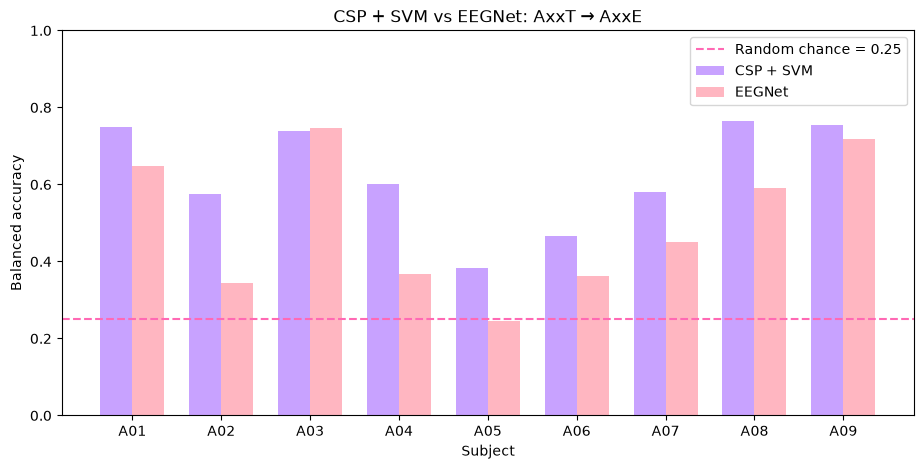

In [118]:
x = np.arange(len(comparison_te_df))
width = 0.36

plt.figure(figsize=(11, 5))

plt.bar(
    x - width / 2,
    comparison_te_df["balanced_accuracy_csp_svm"],
    width,
    label="CSP + SVM",
    color="#C8A2FF"
)

plt.bar(
    x + width / 2,
    comparison_te_df["balanced_accuracy_eegnet"],
    width,
    label="EEGNet",
    color="#FFB6C1"
)

plt.axhline(
    y=0.25,
    linestyle="--",
    color="#FF69B4",
    label="Random chance = 0.25"
)

plt.xticks(
    x,
    comparison_te_df["subject"]
)

plt.ylim(0, 1)
plt.xlabel("Subject")
plt.ylabel("Balanced accuracy")
plt.title("CSP + SVM vs EEGNet: AxxT → AxxE")
plt.legend()

plt.show()

После перехода на межсессионный протокол AxxT → AxxE результаты стали более реалистичными: EEGNet уверенно работает у части испытуемых, но в среднем всё ещё уступает CSP+SVM и остаётся нестабильной между субъектами. Это значит, что текущая subject-specific EEGNet, обученная только на одной тренировочной сессии конкретного человека, вероятно, недоиспользует возможности нейросетевого подхода.

### попробуем подтюнить EEGnet

оставляем preprocessing и архитектуру как есть, меняем только:

num_epochs = 100
batch_size = 32

In [119]:
result_eegnet_a01_long = train_eegnet(
    X_train_te,
    X_val_te,
    X_test_te,
    y_train_te,
    y_val_te,
    y_test_te,
    num_epochs=100,
    batch_size=32,
    learning_rate=0.001
)

print("\nИТОГ:")
print(f"Accuracy: {result_eegnet_a01_long['accuracy']:.3f}")
print(f"Balanced accuracy: {result_eegnet_a01_long['balanced_accuracy']:.3f}")
print(f"Macro F1: {result_eegnet_a01_long['f1_macro']:.3f}")
print(f"Kappa: {result_eegnet_a01_long['kappa']:.3f}")
print(f"Best validation accuracy: {result_eegnet_a01_long['best_val_accuracy']:.3f}")
print(f"Best epoch: {result_eegnet_a01_long['best_epoch']}")

Epoch 01 | loss=1.3709 | train_acc=0.257 | val_acc=0.293
Epoch 02 | loss=1.2909 | train_acc=0.461 | val_acc=0.259
Epoch 03 | loss=1.2275 | train_acc=0.504 | val_acc=0.293
Epoch 04 | loss=1.1086 | train_acc=0.539 | val_acc=0.259
Epoch 05 | loss=1.0376 | train_acc=0.587 | val_acc=0.259
Epoch 06 | loss=0.9462 | train_acc=0.583 | val_acc=0.259
Epoch 07 | loss=0.9114 | train_acc=0.643 | val_acc=0.259
Epoch 08 | loss=0.8753 | train_acc=0.596 | val_acc=0.259
Epoch 09 | loss=0.8136 | train_acc=0.709 | val_acc=0.259
Epoch 10 | loss=0.8030 | train_acc=0.670 | val_acc=0.276
Epoch 11 | loss=0.7830 | train_acc=0.657 | val_acc=0.293
Epoch 12 | loss=0.7471 | train_acc=0.713 | val_acc=0.293
Epoch 13 | loss=0.6814 | train_acc=0.722 | val_acc=0.293
Epoch 14 | loss=0.7480 | train_acc=0.713 | val_acc=0.362
Epoch 15 | loss=0.6451 | train_acc=0.778 | val_acc=0.397
Epoch 16 | loss=0.6614 | train_acc=0.770 | val_acc=0.328
Epoch 17 | loss=0.5862 | train_acc=0.757 | val_acc=0.310
Epoch 18 | loss=0.6123 | train_

In [120]:
print(f"Accuracy: {result_eegnet_a01_long['accuracy']:.3f}")
print(f"Balanced accuracy: {result_eegnet_a01_long['balanced_accuracy']:.3f}")
print(f"Macro F1: {result_eegnet_a01_long['f1_macro']:.3f}")
print(f"Kappa: {result_eegnet_a01_long['kappa']:.3f}")
print(f"Best validation accuracy: {result_eegnet_a01_long['best_val_accuracy']:.3f}")
print(f"Best epoch: {result_eegnet_a01_long['best_epoch']}")

Accuracy: 0.615
Balanced accuracy: 0.615
Macro F1: 0.613
Kappa: 0.486
Best validation accuracy: 0.810
Best epoch: 85


Увеличение числа эпох до 100 повысило validation accuracy с 0.655 до 0.810, однако качество на независимой сессии A01E не улучшилось: balanced accuracy снизилась с 0.649 до 0.615. Это указывает на переобучение под тренировочную сессию A01T и показывает, что простое увеличение длительности обучения не решает проблему межсессионного переноса.

Теперь пробуем снизить переобучение с помощью weight_decay и scheduler.

In [121]:
def train_eegnet_regularized(
    X_train,
    X_val,
    X_test,
    y_train,
    y_val,
    y_test,
    num_epochs=100,
    batch_size=32,
    learning_rate=0.001,
    weight_decay=1e-4
):
    X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
    y_train_tensor = torch.tensor(y_train, dtype=torch.long)

    X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
    y_val_tensor = torch.tensor(y_val, dtype=torch.long)

    X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
    y_test_tensor = torch.tensor(y_test, dtype=torch.long)

    train_loader = DataLoader(
        TensorDataset(X_train_tensor, y_train_tensor),
        batch_size=batch_size,
        shuffle=True
    )

    val_loader = DataLoader(
        TensorDataset(X_val_tensor, y_val_tensor),
        batch_size=batch_size,
        shuffle=False
    )

    test_loader = DataLoader(
        TensorDataset(X_test_tensor, y_test_tensor),
        batch_size=batch_size,
        shuffle=False
    )

    model = EEGNet(
        n_chans=22,
        n_outputs=4,
        n_times=876,
        sfreq=250
    )

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=8
    )

    best_val_acc = 0
    best_state = None
    best_epoch = 0

    for epoch in range(num_epochs):
        model.train()

        train_correct = 0
        train_total = 0
        train_loss = 0

        for X_batch, y_batch in train_loader:
            optimizer.zero_grad()

            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)

            loss.backward()
            optimizer.step()

            train_loss += loss.item()

            preds = outputs.argmax(dim=1)
            train_correct += (preds == y_batch).sum().item()
            train_total += y_batch.size(0)

        train_acc = train_correct / train_total

        model.eval()

        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                outputs = model(X_batch)
                preds = outputs.argmax(dim=1)

                val_correct += (preds == y_batch).sum().item()
                val_total += y_batch.size(0)

        val_acc = val_correct / val_total

        scheduler.step(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_epoch = epoch + 1

            best_state = {
                k: v.cpu().clone()
                for k, v in model.state_dict().items()
            }

        current_lr = optimizer.param_groups[0]["lr"]

        print(
            f"Epoch {epoch + 1:03d} | "
            f"loss={train_loss / len(train_loader):.4f} | "
            f"train_acc={train_acc:.3f} | "
            f"val_acc={val_acc:.3f} | "
            f"lr={current_lr:.6f}"
        )

    model.load_state_dict(best_state)
    model.eval()

    y_pred = []

    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            outputs = model(X_batch)
            preds = outputs.argmax(dim=1)
            y_pred.extend(preds.cpu().numpy())

    y_pred = np.array(y_pred)

    return {
        "accuracy": accuracy_score(y_test, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
        "f1_macro": f1_score(y_test, y_pred, average="macro"),
        "kappa": cohen_kappa_score(y_test, y_pred),
        "best_val_accuracy": best_val_acc,
        "best_epoch": best_epoch,
        "y_pred": y_pred,
        "model": model
    }

In [122]:
result_eegnet_a01_reg = train_eegnet_regularized(
    X_train_te,
    X_val_te,
    X_test_te,
    y_train_te,
    y_val_te,
    y_test_te
)

print("\nИТОГ:")
print(f"Accuracy: {result_eegnet_a01_reg['accuracy']:.3f}")
print(f"Balanced accuracy: {result_eegnet_a01_reg['balanced_accuracy']:.3f}")
print(f"Macro F1: {result_eegnet_a01_reg['f1_macro']:.3f}")
print(f"Kappa: {result_eegnet_a01_reg['kappa']:.3f}")
print(f"Best validation accuracy: {result_eegnet_a01_reg['best_val_accuracy']:.3f}")
print(f"Best epoch: {result_eegnet_a01_reg['best_epoch']}")

Epoch 001 | loss=1.4060 | train_acc=0.248 | val_acc=0.207 | lr=0.001000
Epoch 002 | loss=1.3428 | train_acc=0.322 | val_acc=0.190 | lr=0.001000
Epoch 003 | loss=1.3006 | train_acc=0.443 | val_acc=0.155 | lr=0.001000
Epoch 004 | loss=1.2606 | train_acc=0.504 | val_acc=0.259 | lr=0.001000
Epoch 005 | loss=1.2029 | train_acc=0.548 | val_acc=0.276 | lr=0.001000
Epoch 006 | loss=1.1328 | train_acc=0.596 | val_acc=0.259 | lr=0.001000
Epoch 007 | loss=1.0572 | train_acc=0.622 | val_acc=0.276 | lr=0.001000
Epoch 008 | loss=0.9617 | train_acc=0.661 | val_acc=0.259 | lr=0.001000
Epoch 009 | loss=0.8711 | train_acc=0.661 | val_acc=0.259 | lr=0.001000
Epoch 010 | loss=0.8485 | train_acc=0.687 | val_acc=0.259 | lr=0.001000
Epoch 011 | loss=0.7957 | train_acc=0.674 | val_acc=0.276 | lr=0.001000
Epoch 012 | loss=0.8117 | train_acc=0.691 | val_acc=0.310 | lr=0.001000
Epoch 013 | loss=0.7673 | train_acc=0.687 | val_acc=0.310 | lr=0.001000
Epoch 014 | loss=0.7777 | train_acc=0.735 | val_acc=0.310 | lr=0

In [123]:
print(f"Accuracy: {result_eegnet_a01_reg['accuracy']:.3f}")
print(f"Balanced accuracy: {result_eegnet_a01_reg['balanced_accuracy']:.3f}")
print(f"Macro F1: {result_eegnet_a01_reg['f1_macro']:.3f}")
print(f"Kappa: {result_eegnet_a01_reg['kappa']:.3f}")
print(f"Best validation accuracy: {result_eegnet_a01_reg['best_val_accuracy']:.3f}")
print(f"Best epoch: {result_eegnet_a01_reg['best_epoch']}")

Accuracy: 0.698
Balanced accuracy: 0.698
Macro F1: 0.697
Kappa: 0.597
Best validation accuracy: 0.776
Best epoch: 79


Регуляризация и адаптивное снижение learning rate заметно улучшили обобщающую способность EEGNet. На независимой сессии A01E balanced accuracy выросла примерно до 0.70, а Macro F1 — до 0.697. Это подтверждает, что основной проблемой базовой конфигурации было переобучение.

In [124]:
eegnet_reg_te_results = []

for subject_num in range(1, 10):
    subject = f"A{subject_num:02d}"

    train_file = os.path.join(
        base_path,
        f"{subject}T.gdf"
    )

    eval_file = os.path.join(
        base_path,
        f"{subject}E.gdf"
    )

    labels_file = os.path.join(
        labels_base_path,
        f"{subject}E.mat"
    )

    print(f"Обрабатываем {subject}...")

    # фиксируем случайность
    random.seed(42)
    np.random.seed(42)
    torch.manual_seed(42)

    # подготовка данных
    X_train_te, X_val_te, X_test_te, y_train_te, y_val_te, y_test_te = \
        prepare_subject_train_eval(
            train_file,
            eval_file,
            labels_file
        )

    # обучение регуляризованной EEGNet
    result = train_eegnet_regularized(
        X_train_te,
        X_val_te,
        X_test_te,
        y_train_te,
        y_val_te,
        y_test_te,
        num_epochs=100,
        batch_size=32,
        learning_rate=0.001,
        weight_decay=1e-4
    )

    eegnet_reg_te_results.append({
        "subject": subject,
        "accuracy": result["accuracy"],
        "balanced_accuracy": result["balanced_accuracy"],
        "f1_macro": result["f1_macro"],
        "kappa": result["kappa"],
        "best_val_accuracy": result["best_val_accuracy"],
        "best_epoch": result["best_epoch"]
    })

    gc.collect()

eegnet_reg_te_results_df = pd.DataFrame(
    eegnet_reg_te_results
)

eegnet_reg_te_results_df

Обрабатываем A01...


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Epoch 001 | loss=1.3915 | train_acc=0.261 | val_acc=0.310 | lr=0.001000
Epoch 002 | loss=1.3721 | train_acc=0.287 | val_acc=0.276 | lr=0.001000
Epoch 003 | loss=1.3443 | train_acc=0.365 | val_acc=0.207 | lr=0.001000
Epoch 004 | loss=1.3198 | train_acc=0.391 | val_acc=0.190 | lr=0.001000
Epoch 005 | loss=1.2638 | train_acc=0.478 | val_acc=0.224 | lr=0.001000
Epoch 006 | loss=1.2021 | train_acc=0.574 | val_acc=0.241 | lr=0.001000
Epoch 007 | loss=1.1238 | train_acc=0.578 | val_acc=0.241 | lr=0.001000
Epoch 008 | loss=1.0318 | train_acc=0.587 | val_acc=0.241 | lr=0.001000
Epoch 009 | loss=0.9335 | train_acc=0.657 | val_acc=0.241 | lr=0.001000
Epoch 010 | loss=0.8664 | train_acc=0.626 | val_acc=0.241 | lr=0.000500
Epoch 011 | loss=0.7778 | train_acc=0.665 | val_acc=0.241 | lr=0.000500
Epoch 012 | loss=0.8267 | train_acc=0.613 | val_acc=0.241 | lr=0.000500
Epoch 013 | loss=0.7834 | train_acc=0.670 | val_acc=0.241 | lr=0.000500
Epoch 014 | loss=0.7672 | train_acc=0.674 | val_acc=0.241 | lr=0

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Epoch 001 | loss=1.3782 | train_acc=0.235 | val_acc=0.207 | lr=0.001000
Epoch 002 | loss=1.3716 | train_acc=0.304 | val_acc=0.259 | lr=0.001000
Epoch 003 | loss=1.3637 | train_acc=0.335 | val_acc=0.241 | lr=0.001000
Epoch 004 | loss=1.3478 | train_acc=0.335 | val_acc=0.241 | lr=0.001000
Epoch 005 | loss=1.3258 | train_acc=0.409 | val_acc=0.207 | lr=0.001000
Epoch 006 | loss=1.3207 | train_acc=0.452 | val_acc=0.241 | lr=0.001000
Epoch 007 | loss=1.2971 | train_acc=0.448 | val_acc=0.276 | lr=0.001000
Epoch 008 | loss=1.2786 | train_acc=0.470 | val_acc=0.293 | lr=0.001000
Epoch 009 | loss=1.2852 | train_acc=0.465 | val_acc=0.241 | lr=0.001000
Epoch 010 | loss=1.2335 | train_acc=0.543 | val_acc=0.310 | lr=0.001000
Epoch 011 | loss=1.2369 | train_acc=0.483 | val_acc=0.310 | lr=0.001000
Epoch 012 | loss=1.2365 | train_acc=0.517 | val_acc=0.328 | lr=0.001000
Epoch 013 | loss=1.2209 | train_acc=0.478 | val_acc=0.293 | lr=0.001000
Epoch 014 | loss=1.1706 | train_acc=0.561 | val_acc=0.328 | lr=0

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


... (10 outputs left out)

Epoch 001 | loss=1.3728 | train_acc=0.243 | val_acc=0.345 | lr=0.001000
Epoch 002 | loss=1.3528 | train_acc=0.313 | val_acc=0.345 | lr=0.001000
Epoch 003 | loss=1.3159 | train_acc=0.352 | val_acc=0.328 | lr=0.001000
Epoch 004 | loss=1.2748 | train_acc=0.439 | val_acc=0.310 | lr=0.001000
Epoch 005 | loss=1.1912 | train_acc=0.452 | val_acc=0.328 | lr=0.001000
Epoch 006 | loss=1.1895 | train_acc=0.565 | val_acc=0.362 | lr=0.001000
Epoch 007 | loss=1.1100 | train_acc=0.583 | val_acc=0.345 | lr=0.001000
Epoch 008 | loss=1.0326 | train_acc=0.587 | val_acc=0.362 | lr=0.001000
Epoch 009 | loss=1.0515 | train_acc=0.574 | val_acc=0.328 | lr=0.001000
Epoch 010 | loss=0.9979 | train_acc=0.630 | val_acc=0.293 | lr=0.001000
Epoch 011 | loss=0.9783 | train_acc=0.657 | val_acc=0.362 | lr=0.001000
Epoch 012 | loss=0.9567 | train_acc=0.630 | val_acc=0.293 | lr=0.001000
Epoch 013 | loss=0.9519 | train_acc=0.648 | val_acc=0.293 | lr=0.001000
Epoch 014 | loss=0.9593 | train_acc=0.596 | val_acc=0.276 | lr=0

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Epoch 001 | loss=1.3766 | train_acc=0.226 | val_acc=0.207 | lr=0.001000
Epoch 002 | loss=1.3401 | train_acc=0.370 | val_acc=0.328 | lr=0.001000
Epoch 003 | loss=1.3113 | train_acc=0.400 | val_acc=0.379 | lr=0.001000
Epoch 004 | loss=1.2600 | train_acc=0.474 | val_acc=0.345 | lr=0.001000
Epoch 005 | loss=1.1997 | train_acc=0.596 | val_acc=0.328 | lr=0.001000
Epoch 006 | loss=1.1481 | train_acc=0.543 | val_acc=0.345 | lr=0.001000
Epoch 007 | loss=1.1098 | train_acc=0.591 | val_acc=0.345 | lr=0.001000
Epoch 008 | loss=1.0134 | train_acc=0.626 | val_acc=0.310 | lr=0.001000
Epoch 009 | loss=0.9799 | train_acc=0.626 | val_acc=0.310 | lr=0.001000
Epoch 010 | loss=0.9381 | train_acc=0.700 | val_acc=0.310 | lr=0.001000
Epoch 011 | loss=0.8292 | train_acc=0.687 | val_acc=0.310 | lr=0.001000
Epoch 012 | loss=0.8381 | train_acc=0.657 | val_acc=0.310 | lr=0.000500
Epoch 013 | loss=0.7746 | train_acc=0.700 | val_acc=0.293 | lr=0.000500
Epoch 014 | loss=0.7754 | train_acc=0.704 | val_acc=0.293 | lr=0

,subject,accuracy,balanced_accuracy,f1_macro,kappa,best_val_accuracy,best_epoch
0,A01,0.652778,0.652778,0.642516,0.537037,0.655172,61
1,A02,0.340278,0.340278,0.325598,0.120370,0.448276,84
2,A03,0.704861,0.704861,0.653911,0.606481,0.758621,80
3,A04,0.409722,0.409722,0.404902,0.212963,0.500000,84
4,A05,0.250000,0.250000,0.165938,0.000000,0.241379,1
5,A06,0.437500,0.437500,0.427399,0.250000,0.500000,84
6,A07,0.461806,0.461806,0.423696,0.282407,0.534483,80
7,A08,0.673611,0.673611,0.674061,0.564815,0.810345,92
8,A09,0.704861,0.704861,0.684311,0.606481,0.689655,94


Регуляризация и scheduler немного улучшили среднее качество EEGNet и снизили разброс между испытуемыми, однако модель всё ещё существенно уступает CSP+SVM у части субъектов. Это говорит о том, что проблема не сводится только к переобучению: вероятно, ограничивает небольшой объём subject-specific данных и межсессионный сдвиг.

Что бы увеличить объём данных для EEGNet за счёт предварительного обучения на других испытуемых. Сначала EEGNet будет обучаться на A02T–A09T, после чего модель будет дообучена на тренировочной сессии целевого испытуемого A01T. Сессия A01E останется полностью изолированной и будет использоваться только для финальной оценки, чтобы исключить утечку данных.

A02T–A09T
    
    ↓

pretraining EEGNet
    
    ↓

A01T
   
    ↓

fine-tuning
    
    ↓

A01E
    
    ↓

FINAL TEST

Собираем данные A02T–A09T для pretraining

In [125]:
def prepare_pretrain_subject(file_path):
    raw = mne.io.read_raw_gdf(
        file_path,
        preload=True,
        verbose=False
    )

    raw.set_channel_types({
        "EOG-left": "eog",
        "EOG-central": "eog",
        "EOG-right": "eog"
    })

    raw_filtered = raw.copy().filter(
        l_freq=8,
        h_freq=30,
        verbose=False
    )

    events, event_id = mne.events_from_annotations(
        raw_filtered,
        verbose=False
    )

    motor_imagery_event_id = {
        "left_hand": event_id["769"],
        "right_hand": event_id["770"],
        "feet": event_id["771"],
        "tongue": event_id["772"]
    }

    epochs = mne.Epochs(
        raw_filtered,
        events,
        event_id=motor_imagery_event_id,
        tmin=0.5,
        tmax=4.0,
        baseline=None,
        preload=True,
        verbose=False
    )

    epochs = epochs.copy().pick("eeg")

    X = epochs.get_data()
    y = epochs.events[:, 2]

    label_map = {
        motor_imagery_event_id["left_hand"]: 0,
        motor_imagery_event_id["right_hand"]: 1,
        motor_imagery_event_id["feet"]: 2,
        motor_imagery_event_id["tongue"]: 3
    }

    y = np.array([label_map[v] for v in y])

    return X, y

In [126]:
X_pretrain_list = []
y_pretrain_list = []

for subject_num in range(2, 10):
    subject = f"A{subject_num:02d}"

    file_path = os.path.join(
        base_path,
        f"{subject}T.gdf"
    )

    print(f"Добавляем {subject}...")

    X_subject, y_subject = prepare_pretrain_subject(
        file_path
    )

    X_pretrain_list.append(X_subject)
    y_pretrain_list.append(y_subject)

X_pretrain = np.concatenate(
    X_pretrain_list,
    axis=0
)

y_pretrain = np.concatenate(
    y_pretrain_list,
    axis=0
)

print("X:", X_pretrain.shape)
print("y:", y_pretrain.shape)
print("Классы:", np.unique(y_pretrain))

Добавляем A02...


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Добавляем A03...


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Добавляем A04...


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


... (7 outputs left out)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Добавляем A09...


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


X: (2304, 22, 876)
y: (2304,)
Классы: [0 1 2 3]


In [127]:
X_pre_train, X_pre_val, y_pre_train, y_pre_val = train_test_split(
    X_pretrain,
    y_pretrain,
    test_size=0.2,
    random_state=42,
    stratify=y_pretrain
)

mean_pre = X_pre_train.mean(axis=(0, 2), keepdims=True)
std_pre = X_pre_train.std(axis=(0, 2), keepdims=True)

X_pre_train = (X_pre_train - mean_pre) / std_pre
X_pre_val = (X_pre_val - mean_pre) / std_pre

print("Pretrain train:", X_pre_train.shape, y_pre_train.shape)
print("Pretrain val:", X_pre_val.shape, y_pre_val.shape)

Pretrain train: (1843, 22, 876) (1843,)
Pretrain val: (461, 22, 876) (461,)


функция, которая обучит сеть на X_pre_train, будет смотреть на X_pre_val и сохранит лучшую версию по validation accuracy.

In [128]:
def pretrain_eegnet(
    X_train,
    X_val,
    y_train,
    y_val,
    num_epochs=100,
    batch_size=32,
    learning_rate=0.001,
    weight_decay=1e-4
):
    X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
    y_train_tensor = torch.tensor(y_train, dtype=torch.long)

    X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
    y_val_tensor = torch.tensor(y_val, dtype=torch.long)

    train_loader = DataLoader(
        TensorDataset(X_train_tensor, y_train_tensor),
        batch_size=batch_size,
        shuffle=True
    )

    val_loader = DataLoader(
        TensorDataset(X_val_tensor, y_val_tensor),
        batch_size=batch_size,
        shuffle=False
    )

    model = EEGNet(
        n_chans=22,
        n_outputs=4,
        n_times=876,
        sfreq=250
    )

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=8
    )

    best_val_acc = 0
    best_state = None
    best_epoch = 0

    for epoch in range(num_epochs):
        model.train()

        train_correct = 0
        train_total = 0

        for X_batch, y_batch in train_loader:
            optimizer.zero_grad()

            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)

            loss.backward()
            optimizer.step()

            preds = outputs.argmax(dim=1)

            train_correct += (preds == y_batch).sum().item()
            train_total += y_batch.size(0)

        train_acc = train_correct / train_total

        model.eval()

        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                outputs = model(X_batch)
                preds = outputs.argmax(dim=1)

                val_correct += (preds == y_batch).sum().item()
                val_total += y_batch.size(0)

        val_acc = val_correct / val_total

        scheduler.step(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_epoch = epoch + 1

            best_state = {
                k: v.cpu().clone()
                for k, v in model.state_dict().items()
            }

        print(
            f"Epoch {epoch + 1:03d} | "
            f"train_acc={train_acc:.3f} | "
            f"val_acc={val_acc:.3f}"
        )

    model.load_state_dict(best_state)

    return model, best_val_acc, best_epoch

In [129]:
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

pretrained_model, pretrain_val_acc, pretrain_best_epoch = pretrain_eegnet(
    X_pre_train,
    X_pre_val,
    y_pre_train,
    y_pre_val
)

print("\nPretraining завершён")
print(f"Best validation accuracy: {pretrain_val_acc:.3f}")
print(f"Best epoch: {pretrain_best_epoch}")


Epoch 001 | train_acc=0.254 | val_acc=0.280
Epoch 002 | train_acc=0.311 | val_acc=0.299
Epoch 003 | train_acc=0.343 | val_acc=0.312
Epoch 004 | train_acc=0.372 | val_acc=0.345
Epoch 005 | train_acc=0.425 | val_acc=0.397
Epoch 006 | train_acc=0.456 | val_acc=0.375
Epoch 007 | train_acc=0.450 | val_acc=0.460
Epoch 008 | train_acc=0.480 | val_acc=0.445
Epoch 009 | train_acc=0.490 | val_acc=0.456
Epoch 010 | train_acc=0.487 | val_acc=0.477
Epoch 011 | train_acc=0.510 | val_acc=0.477
Epoch 012 | train_acc=0.513 | val_acc=0.451
Epoch 013 | train_acc=0.515 | val_acc=0.495
Epoch 014 | train_acc=0.522 | val_acc=0.486
Epoch 015 | train_acc=0.523 | val_acc=0.453
Epoch 016 | train_acc=0.523 | val_acc=0.475
Epoch 017 | train_acc=0.531 | val_acc=0.479
Epoch 018 | train_acc=0.540 | val_acc=0.501
Epoch 019 | train_acc=0.540 | val_acc=0.484
Epoch 020 | train_acc=0.544 | val_acc=0.482
Epoch 021 | train_acc=0.549 | val_acc=0.488
Epoch 022 | train_acc=0.553 | val_acc=0.495
Epoch 023 | train_acc=0.564 | va

Тогда делаем чистый pretraining split по субъектам:

A02T–A08T → pretraining train
A09T       → pretraining validation

A01 пока вообще не трогаем

In [130]:
X_pre_train_list = []
y_pre_train_list = []

# A02T–A08T → pretraining train
for subject_num in range(2, 9):
    subject = f"A{subject_num:02d}"

    file_path = os.path.join(
        base_path,
        f"{subject}T.gdf"
    )

    print(f"Добавляем {subject} в pretrain train...")

    X_subject, y_subject = prepare_pretrain_subject(
        file_path
    )

    X_pre_train_list.append(X_subject)
    y_pre_train_list.append(y_subject)

X_pre_train = np.concatenate(
    X_pre_train_list,
    axis=0
)

y_pre_train = np.concatenate(
    y_pre_train_list,
    axis=0
)


# A09T → pretraining validation
file_path_a09 = os.path.join(
    base_path,
    "A09T.gdf"
)

X_pre_val, y_pre_val = prepare_pretrain_subject(
    file_path_a09
)

print("Pretrain train:", X_pre_train.shape, y_pre_train.shape)
print("Pretrain val:", X_pre_val.shape, y_pre_val.shape)

Добавляем A02 в pretrain train...


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Добавляем A03 в pretrain train...


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Добавляем A04 в pretrain train...


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


... (5 outputs left out)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Добавляем A08 в pretrain train...


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Pretrain train: (2016, 22, 876) (2016,)
Pretrain val: (288, 22, 876) (288,)


In [131]:
mean_pre = X_pre_train.mean(
    axis=(0, 2),
    keepdims=True
)

std_pre = X_pre_train.std(
    axis=(0, 2),
    keepdims=True
)

X_pre_train = (
    X_pre_train - mean_pre
) / std_pre

X_pre_val = (
    X_pre_val - mean_pre
) / std_pre

print("Нормализация готова")

Нормализация готова


In [132]:
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

pretrained_model_clean, pretrain_val_acc_clean, pretrain_best_epoch_clean = \
    pretrain_eegnet(
        X_pre_train,
        X_pre_val,
        y_pre_train,
        y_pre_val,
        num_epochs=100,
        batch_size=32,
        learning_rate=0.001,
        weight_decay=1e-4
    )

print("\nPretraining завершён")
print(f"Best validation accuracy: {pretrain_val_acc_clean:.3f}")
print(f"Best epoch: {pretrain_best_epoch_clean}")

Epoch 001 | train_acc=0.244 | val_acc=0.309
Epoch 002 | train_acc=0.298 | val_acc=0.333
Epoch 003 | train_acc=0.338 | val_acc=0.406
Epoch 004 | train_acc=0.363 | val_acc=0.462
Epoch 005 | train_acc=0.409 | val_acc=0.389
Epoch 006 | train_acc=0.430 | val_acc=0.500
Epoch 007 | train_acc=0.440 | val_acc=0.469
Epoch 008 | train_acc=0.447 | val_acc=0.476
Epoch 009 | train_acc=0.470 | val_acc=0.514
Epoch 010 | train_acc=0.467 | val_acc=0.472
Epoch 011 | train_acc=0.467 | val_acc=0.431
Epoch 012 | train_acc=0.473 | val_acc=0.469
Epoch 013 | train_acc=0.501 | val_acc=0.451
Epoch 014 | train_acc=0.486 | val_acc=0.462
Epoch 015 | train_acc=0.509 | val_acc=0.420
Epoch 016 | train_acc=0.510 | val_acc=0.479
Epoch 017 | train_acc=0.491 | val_acc=0.483
Epoch 018 | train_acc=0.516 | val_acc=0.531
Epoch 019 | train_acc=0.513 | val_acc=0.521
Epoch 020 | train_acc=0.523 | val_acc=0.580
Epoch 021 | train_acc=0.515 | val_acc=0.413
Epoch 022 | train_acc=0.530 | val_acc=0.590
Epoch 023 | train_acc=0.523 | va

Предобучение EEGNet на данных A02–A08 с валидацией на отдельном испытуемом A09 дало validation accuracy 0.608. Это выше случайного уровня и показывает, что модель извлекает переносимые между субъектами признаки, однако качество пока остаётся умеренным. Следующий этап — проверить, улучшит ли такое предобучение fine-tuning на целевом испытуемом A01.

In [133]:
def finetune_eegnet(
    pretrained_model,
    X_train,
    X_val,
    X_test,
    y_train,
    y_val,
    y_test,
    num_epochs=50,
    batch_size=32,
    learning_rate=1e-4,
    weight_decay=1e-4
):
    X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
    y_train_tensor = torch.tensor(y_train, dtype=torch.long)

    X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
    y_val_tensor = torch.tensor(y_val, dtype=torch.long)

    X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
    y_test_tensor = torch.tensor(y_test, dtype=torch.long)

    train_loader = DataLoader(
        TensorDataset(X_train_tensor, y_train_tensor),
        batch_size=batch_size,
        shuffle=True
    )

    val_loader = DataLoader(
        TensorDataset(X_val_tensor, y_val_tensor),
        batch_size=batch_size,
        shuffle=False
    )

    test_loader = DataLoader(
        TensorDataset(X_test_tensor, y_test_tensor),
        batch_size=batch_size,
        shuffle=False
    )

    # Берём уже предобученную модель
    model = pretrained_model

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=6
    )

    best_val_acc = 0
    best_state = None
    best_epoch = 0

    for epoch in range(num_epochs):
        model.train()

        train_correct = 0
        train_total = 0

        for X_batch, y_batch in train_loader:
            optimizer.zero_grad()

            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)

            loss.backward()
            optimizer.step()

            preds = outputs.argmax(dim=1)

            train_correct += (preds == y_batch).sum().item()
            train_total += y_batch.size(0)

        train_acc = train_correct / train_total

        model.eval()

        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                outputs = model(X_batch)
                preds = outputs.argmax(dim=1)

                val_correct += (preds == y_batch).sum().item()
                val_total += y_batch.size(0)

        val_acc = val_correct / val_total

        scheduler.step(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_epoch = epoch + 1

            best_state = {
                k: v.cpu().clone()
                for k, v in model.state_dict().items()
            }

        print(
            f"Epoch {epoch + 1:03d} | "
            f"train_acc={train_acc:.3f} | "
            f"val_acc={val_acc:.3f}"
        )

    model.load_state_dict(best_state)

    model.eval()

    y_pred = []

    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            outputs = model(X_batch)
            preds = outputs.argmax(dim=1)

            y_pred.extend(preds.cpu().numpy())

    y_pred = np.array(y_pred)

    return {
        "accuracy": accuracy_score(y_test, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
        "f1_macro": f1_score(y_test, y_pred, average="macro"),
        "kappa": cohen_kappa_score(y_test, y_pred),
        "best_val_accuracy": best_val_acc,
        "best_epoch": best_epoch,
        "model": model
    }

In [134]:
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

result_finetune_a01 = finetune_eegnet(
    pretrained_model_clean,
    X_train_te,
    X_val_te,
    X_test_te,
    y_train_te,
    y_val_te,
    y_test_te,
    num_epochs=50,
    batch_size=32,
    learning_rate=1e-4,
    weight_decay=1e-4
)

print("\nИТОГ FINE-TUNING:")
print(f"Accuracy: {result_finetune_a01['accuracy']:.3f}")
print(f"Balanced accuracy: {result_finetune_a01['balanced_accuracy']:.3f}")
print(f"Macro F1: {result_finetune_a01['f1_macro']:.3f}")
print(f"Kappa: {result_finetune_a01['kappa']:.3f}")
print(f"Best validation accuracy: {result_finetune_a01['best_val_accuracy']:.3f}")
print(f"Best epoch: {result_finetune_a01['best_epoch']}")

Epoch 001 | train_acc=0.552 | val_acc=0.621
Epoch 002 | train_acc=0.604 | val_acc=0.638
Epoch 003 | train_acc=0.574 | val_acc=0.655
Epoch 004 | train_acc=0.565 | val_acc=0.655
Epoch 005 | train_acc=0.539 | val_acc=0.690
Epoch 006 | train_acc=0.587 | val_acc=0.707
Epoch 007 | train_acc=0.578 | val_acc=0.707
Epoch 008 | train_acc=0.565 | val_acc=0.724
Epoch 009 | train_acc=0.609 | val_acc=0.724
Epoch 010 | train_acc=0.596 | val_acc=0.724
Epoch 011 | train_acc=0.626 | val_acc=0.724
Epoch 012 | train_acc=0.648 | val_acc=0.724
Epoch 013 | train_acc=0.635 | val_acc=0.724
Epoch 014 | train_acc=0.657 | val_acc=0.724
Epoch 015 | train_acc=0.643 | val_acc=0.724
Epoch 016 | train_acc=0.652 | val_acc=0.724
Epoch 017 | train_acc=0.665 | val_acc=0.724
Epoch 018 | train_acc=0.678 | val_acc=0.724
Epoch 019 | train_acc=0.622 | val_acc=0.724
Epoch 020 | train_acc=0.674 | val_acc=0.724
Epoch 021 | train_acc=0.674 | val_acc=0.724
Epoch 022 | train_acc=0.652 | val_acc=0.724
Epoch 023 | train_acc=0.678 | va

Предобучение на A02–A08 с последующим fine-tuning на A01T не улучшило качество относительно subject-specific обучения с регуляризацией. Лучшее качество по-прежнему даёт EEGNet, обученная непосредственно на A01T с регуляризацией. Вероятно, для эффективного переноса требуется более аккуратная стратегия адаптации, например частичное замораживание слоёв или более низкий learning rate.

### Euclidean Alignment перед EEGNet

Идея эксперимента: попробовать Euclidean Alignment перед EEGNet, чтобы уменьшить межсессионный сдвиг между AxxT и AxxE. Идею берём из работ и репозитория eegnet-v2, где alignment используется перед EEGNet для BCI Competition IV-2a и даёт заметный прирост качества. В нашем эксперименте alignment будет выполняться без использования test labels, то есть AxxE останется закрытым по меткам.

In [135]:
from scipy.linalg import fractional_matrix_power

def euclidean_alignment(X):
    covariances = []

    for trial in X:
        cov = trial @ trial.T / trial.shape[1]
        covariances.append(cov)

    reference_cov = np.mean(covariances, axis=0)

    whitening_matrix = fractional_matrix_power(
        reference_cov,
        -0.5
    ).real

    X_aligned = np.array([
        whitening_matrix @ trial
        for trial in X
    ])

    return X_aligned

In [136]:
def prepare_subject_train_eval_aligned(
    train_file_path,
    eval_file_path,
    eval_labels_path
):
    # ---------- TRAIN SESSION ----------
    raw_train = mne.io.read_raw_gdf(
        train_file_path,
        preload=True,
        verbose=False
    )

    raw_train.set_channel_types({
        "EOG-left": "eog",
        "EOG-central": "eog",
        "EOG-right": "eog"
    })

    raw_train_filtered = raw_train.copy().filter(
        l_freq=8,
        h_freq=30,
        verbose=False
    )

    events_train, event_id_train = mne.events_from_annotations(
        raw_train_filtered,
        verbose=False
    )

    train_event_id = {
        "left_hand": event_id_train["769"],
        "right_hand": event_id_train["770"],
        "feet": event_id_train["771"],
        "tongue": event_id_train["772"]
    }

    epochs_train = mne.Epochs(
        raw_train_filtered,
        events_train,
        event_id=train_event_id,
        tmin=0.5,
        tmax=4.0,
        baseline=None,
        preload=True,
        verbose=False
    )

    epochs_train = epochs_train.copy().pick("eeg")

    X_train_full = epochs_train.get_data()
    y_train_full = epochs_train.events[:, 2]

    train_label_map = {
        train_event_id["left_hand"]: 0,
        train_event_id["right_hand"]: 1,
        train_event_id["feet"]: 2,
        train_event_id["tongue"]: 3
    }

    y_train_full = np.array([
        train_label_map[v] for v in y_train_full
    ])

    # ---------- TEST SESSION ----------
    raw_test = mne.io.read_raw_gdf(
        eval_file_path,
        preload=True,
        verbose=False
    )

    raw_test.set_channel_types({
        "EOG-left": "eog",
        "EOG-central": "eog",
        "EOG-right": "eog"
    })

    raw_test_filtered = raw_test.copy().filter(
        l_freq=8,
        h_freq=30,
        verbose=False
    )

    events_test, event_id_test = mne.events_from_annotations(
        raw_test_filtered,
        verbose=False
    )

    test_event_id = {
        "unknown_cue": event_id_test["783"]
    }

    epochs_test = mne.Epochs(
        raw_test_filtered,
        events_test,
        event_id=test_event_id,
        tmin=0.5,
        tmax=4.0,
        baseline=None,
        preload=True,
        verbose=False
    )

    epochs_test = epochs_test.copy().pick("eeg")

    X_test = epochs_test.get_data()

    # ---------- TRUE LABELS ----------
    mat = loadmat(eval_labels_path)
    y_test = mat["classlabel"].ravel() - 1

    # ---------- ALIGNMENT ----------
    X_train_full = euclidean_alignment(X_train_full)
    X_test = euclidean_alignment(X_test)

    # ---------- TRAIN / VALIDATION ----------
    X_train, X_val, y_train, y_val = train_test_split(
        X_train_full,
        y_train_full,
        test_size=0.2,
        random_state=42,
        stratify=y_train_full
    )

    # ---------- NORMALIZATION ----------
    mean = X_train.mean(axis=(0, 2), keepdims=True)
    std = X_train.std(axis=(0, 2), keepdims=True)

    X_train = (X_train - mean) / std
    X_val = (X_val - mean) / std
    X_test = (X_test - mean) / std

    return X_train, X_val, X_test, y_train, y_val, y_test

После этого проверяем только A01:



In [137]:
X_train_al, X_val_al, X_test_al, y_train_al, y_val_al, y_test_al = \
    prepare_subject_train_eval_aligned(
        train_file_a01,
        eval_file_a01,
        labels_file_a01
    )

print("Train:", X_train_al.shape, y_train_al.shape)
print("Validation:", X_val_al.shape, y_val_al.shape)
print("Test:", X_test_al.shape, y_test_al.shape)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Train: (230, 22, 876) (230,)
Validation: (58, 22, 876) (58,)
Test: (288, 22, 876) (288,)


In [138]:
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

result_eegnet_a01_aligned = train_eegnet_regularized(
    X_train_al,
    X_val_al,
    X_test_al,
    y_train_al,
    y_val_al,
    y_test_al,
    num_epochs=100,
    batch_size=32,
    learning_rate=0.001,
    weight_decay=1e-4
)

print("\nИТОГ EEGNet + Alignment:")
print(f"Accuracy: {result_eegnet_a01_aligned['accuracy']:.3f}")
print(f"Balanced accuracy: {result_eegnet_a01_aligned['balanced_accuracy']:.3f}")
print(f"Macro F1: {result_eegnet_a01_aligned['f1_macro']:.3f}")
print(f"Kappa: {result_eegnet_a01_aligned['kappa']:.3f}")
print(f"Best validation accuracy: {result_eegnet_a01_aligned['best_val_accuracy']:.3f}")
print(f"Best epoch: {result_eegnet_a01_aligned['best_epoch']}")

Epoch 001 | loss=1.3800 | train_acc=0.230 | val_acc=0.224 | lr=0.001000
Epoch 002 | loss=1.3711 | train_acc=0.330 | val_acc=0.259 | lr=0.001000
Epoch 003 | loss=1.3332 | train_acc=0.374 | val_acc=0.190 | lr=0.001000
Epoch 004 | loss=1.3153 | train_acc=0.448 | val_acc=0.224 | lr=0.001000
Epoch 005 | loss=1.2762 | train_acc=0.465 | val_acc=0.241 | lr=0.001000
Epoch 006 | loss=1.2066 | train_acc=0.587 | val_acc=0.241 | lr=0.001000
Epoch 007 | loss=1.1047 | train_acc=0.570 | val_acc=0.207 | lr=0.001000
Epoch 008 | loss=0.9882 | train_acc=0.643 | val_acc=0.259 | lr=0.001000
Epoch 009 | loss=0.8994 | train_acc=0.613 | val_acc=0.276 | lr=0.001000
Epoch 010 | loss=0.8344 | train_acc=0.639 | val_acc=0.293 | lr=0.001000
Epoch 011 | loss=0.7808 | train_acc=0.696 | val_acc=0.328 | lr=0.001000
Epoch 012 | loss=0.8260 | train_acc=0.648 | val_acc=0.345 | lr=0.001000
Epoch 013 | loss=0.7567 | train_acc=0.691 | val_acc=0.310 | lr=0.001000
Epoch 014 | loss=0.7159 | train_acc=0.722 | val_acc=0.310 | lr=0

In [139]:
print(f"Accuracy: {result_eegnet_a01_aligned['accuracy']:.3f}")
print(f"Balanced accuracy: {result_eegnet_a01_aligned['balanced_accuracy']:.3f}")
print(f"Macro F1: {result_eegnet_a01_aligned['f1_macro']:.3f}")
print(f"Kappa: {result_eegnet_a01_aligned['kappa']:.3f}")

Accuracy: 0.708
Balanced accuracy: 0.708
Macro F1: 0.704
Kappa: 0.611


In [140]:
eegnet_aligned_results = []

for subject_num in range(1, 10):
    subject = f"A{subject_num:02d}"

    train_file = os.path.join(
        base_path,
        f"{subject}T.gdf"
    )

    eval_file = os.path.join(
        base_path,
        f"{subject}E.gdf"
    )

    labels_file = os.path.join(
        labels_base_path,
        f"{subject}E.mat"
    )

    print(f"Обрабатываем {subject}...")

    # фиксируем случайность
    random.seed(42)
    np.random.seed(42)
    torch.manual_seed(42)

    # подготовка aligned-данных
    X_train_al, X_val_al, X_test_al, y_train_al, y_val_al, y_test_al = \
        prepare_subject_train_eval_aligned(
            train_file,
            eval_file,
            labels_file
        )

    # обучение
    result = train_eegnet_regularized(
        X_train_al,
        X_val_al,
        X_test_al,
        y_train_al,
        y_val_al,
        y_test_al,
        num_epochs=100,
        batch_size=32,
        learning_rate=0.001,
        weight_decay=1e-4
    )

    eegnet_aligned_results.append({
        "subject": subject,
        "accuracy": result["accuracy"],
        "balanced_accuracy": result["balanced_accuracy"],
        "f1_macro": result["f1_macro"],
        "kappa": result["kappa"],
        "best_val_accuracy": result["best_val_accuracy"],
        "best_epoch": result["best_epoch"]
    })

    gc.collect()

eegnet_aligned_results_df = pd.DataFrame(
    eegnet_aligned_results
)

eegnet_aligned_results_df

Обрабатываем A01...


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Epoch 001 | loss=1.3800 | train_acc=0.230 | val_acc=0.224 | lr=0.001000
Epoch 002 | loss=1.3711 | train_acc=0.330 | val_acc=0.259 | lr=0.001000
Epoch 003 | loss=1.3332 | train_acc=0.374 | val_acc=0.190 | lr=0.001000
Epoch 004 | loss=1.3153 | train_acc=0.448 | val_acc=0.224 | lr=0.001000
Epoch 005 | loss=1.2762 | train_acc=0.465 | val_acc=0.241 | lr=0.001000
Epoch 006 | loss=1.2066 | train_acc=0.587 | val_acc=0.241 | lr=0.001000
Epoch 007 | loss=1.1047 | train_acc=0.570 | val_acc=0.207 | lr=0.001000
Epoch 008 | loss=0.9882 | train_acc=0.643 | val_acc=0.259 | lr=0.001000
Epoch 009 | loss=0.8994 | train_acc=0.613 | val_acc=0.276 | lr=0.001000
Epoch 010 | loss=0.8344 | train_acc=0.639 | val_acc=0.293 | lr=0.001000
Epoch 011 | loss=0.7808 | train_acc=0.696 | val_acc=0.328 | lr=0.001000
Epoch 012 | loss=0.8260 | train_acc=0.648 | val_acc=0.345 | lr=0.001000
Epoch 013 | loss=0.7567 | train_acc=0.691 | val_acc=0.310 | lr=0.001000
Epoch 014 | loss=0.7159 | train_acc=0.722 | val_acc=0.310 | lr=0

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Epoch 001 | loss=1.3901 | train_acc=0.230 | val_acc=0.310 | lr=0.001000
Epoch 002 | loss=1.3844 | train_acc=0.252 | val_acc=0.276 | lr=0.001000
Epoch 003 | loss=1.3566 | train_acc=0.361 | val_acc=0.345 | lr=0.001000
Epoch 004 | loss=1.3487 | train_acc=0.370 | val_acc=0.328 | lr=0.001000
Epoch 005 | loss=1.3486 | train_acc=0.413 | val_acc=0.293 | lr=0.001000
Epoch 006 | loss=1.3180 | train_acc=0.439 | val_acc=0.259 | lr=0.001000
Epoch 007 | loss=1.3109 | train_acc=0.487 | val_acc=0.276 | lr=0.001000
Epoch 008 | loss=1.2969 | train_acc=0.483 | val_acc=0.293 | lr=0.001000
Epoch 009 | loss=1.2783 | train_acc=0.548 | val_acc=0.224 | lr=0.001000
Epoch 010 | loss=1.2432 | train_acc=0.622 | val_acc=0.259 | lr=0.001000
Epoch 011 | loss=1.2550 | train_acc=0.539 | val_acc=0.241 | lr=0.001000
Epoch 012 | loss=1.2215 | train_acc=0.587 | val_acc=0.241 | lr=0.000500
Epoch 013 | loss=1.2052 | train_acc=0.613 | val_acc=0.207 | lr=0.000500
Epoch 014 | loss=1.1888 | train_acc=0.604 | val_acc=0.241 | lr=0

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


... (10 outputs left out)

Epoch 001 | loss=1.3641 | train_acc=0.304 | val_acc=0.310 | lr=0.001000
Epoch 002 | loss=1.3399 | train_acc=0.317 | val_acc=0.362 | lr=0.001000
Epoch 003 | loss=1.3159 | train_acc=0.413 | val_acc=0.259 | lr=0.001000
Epoch 004 | loss=1.2727 | train_acc=0.443 | val_acc=0.241 | lr=0.001000
Epoch 005 | loss=1.1910 | train_acc=0.517 | val_acc=0.276 | lr=0.001000
Epoch 006 | loss=1.1592 | train_acc=0.561 | val_acc=0.293 | lr=0.001000
Epoch 007 | loss=1.0994 | train_acc=0.574 | val_acc=0.310 | lr=0.001000
Epoch 008 | loss=0.9862 | train_acc=0.639 | val_acc=0.328 | lr=0.001000
Epoch 009 | loss=1.0004 | train_acc=0.578 | val_acc=0.328 | lr=0.001000
Epoch 010 | loss=0.9184 | train_acc=0.604 | val_acc=0.328 | lr=0.001000
Epoch 011 | loss=0.8677 | train_acc=0.704 | val_acc=0.328 | lr=0.000500
Epoch 012 | loss=0.8212 | train_acc=0.709 | val_acc=0.328 | lr=0.000500
Epoch 013 | loss=0.8769 | train_acc=0.661 | val_acc=0.328 | lr=0.000500
Epoch 014 | loss=0.8825 | train_acc=0.683 | val_acc=0.345 | lr=0

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Epoch 001 | loss=1.3687 | train_acc=0.261 | val_acc=0.155 | lr=0.001000
Epoch 002 | loss=1.3569 | train_acc=0.317 | val_acc=0.259 | lr=0.001000
Epoch 003 | loss=1.3010 | train_acc=0.465 | val_acc=0.328 | lr=0.001000
Epoch 004 | loss=1.2526 | train_acc=0.539 | val_acc=0.362 | lr=0.001000
Epoch 005 | loss=1.1973 | train_acc=0.587 | val_acc=0.276 | lr=0.001000
Epoch 006 | loss=1.1433 | train_acc=0.617 | val_acc=0.276 | lr=0.001000
Epoch 007 | loss=1.0985 | train_acc=0.639 | val_acc=0.293 | lr=0.001000
Epoch 008 | loss=0.9937 | train_acc=0.609 | val_acc=0.276 | lr=0.001000
Epoch 009 | loss=0.9518 | train_acc=0.639 | val_acc=0.259 | lr=0.001000
Epoch 010 | loss=0.8757 | train_acc=0.678 | val_acc=0.259 | lr=0.001000
Epoch 011 | loss=0.8053 | train_acc=0.713 | val_acc=0.293 | lr=0.001000
Epoch 012 | loss=0.7775 | train_acc=0.704 | val_acc=0.276 | lr=0.001000
Epoch 013 | loss=0.7768 | train_acc=0.700 | val_acc=0.259 | lr=0.000500
Epoch 014 | loss=0.7113 | train_acc=0.730 | val_acc=0.276 | lr=0

,subject,accuracy,balanced_accuracy,f1_macro,kappa,best_val_accuracy,best_epoch
0,A01,0.708333,0.708333,0.704226,0.611111,0.724138,77
1,A02,0.475694,0.475694,0.463450,0.300926,0.689655,66
2,A03,0.857639,0.857639,0.856310,0.810185,0.913793,55
3,A04,0.423611,0.423611,0.365445,0.231481,0.448276,46
4,A05,0.461806,0.461806,0.410072,0.282407,0.568966,46
5,A06,0.329861,0.329861,0.300001,0.106481,0.413793,53
6,A07,0.600694,0.600694,0.590241,0.467593,0.775862,64
7,A08,0.659722,0.659722,0.654677,0.546296,0.655172,81
8,A09,0.597222,0.597222,0.603900,0.462963,0.775862,41


Для сравнения у нас было:

обычная EEGNet на T → E: 0.497 ± 0.183
регуляризованная EEGNet: примерно 0.515 ± 0.172
EEGNet + alignment: 0.568 ± 0.163

То есть alignment уже даёт системный прирост, не только на A01.

Особенно хорошо выросли:

A03 → 0.858
A01 → 0.708
A08 → 0.660
A07 → 0.601

Euclidean Alignment улучшил среднее качество EEGNet на межсессионном протоколе: balanced accuracy выросла примерно с 0.50 до 0.57, а разброс между испытуемыми немного снизился. Особенно заметный прирост наблюдается у части субъектов, однако для нескольких испытуемых качество остаётся низким. Это показывает, что межсессионный сдвиг действительно является одной из причин нестабильности EEGNet, но не единственной.

In [141]:
comparison_final_df = (
    csp_te_results_df[
        ["subject", "balanced_accuracy"]
    ]
    .rename(columns={
        "balanced_accuracy": "csp_svm"
    })
    .merge(
        eegnet_reg_te_results_df[
            ["subject", "balanced_accuracy"]
        ].rename(columns={
            "balanced_accuracy": "eegnet"
        }),
        on="subject"
    )
    .merge(
        eegnet_aligned_results_df[
            ["subject", "balanced_accuracy"]
        ].rename(columns={
            "balanced_accuracy": "eegnet_alignment"
        }),
        on="subject"
    )
)

comparison_final_df

,subject,csp_svm,eegnet,eegnet_alignment
0,A01,0.750000,0.652778,0.708333
1,A02,0.576389,0.340278,0.475694
2,A03,0.739583,0.704861,0.857639
3,A04,0.600694,0.409722,0.423611
4,A05,0.381944,0.250000,0.461806
5,A06,0.465278,0.437500,0.329861
6,A07,0.579861,0.461806,0.600694
7,A08,0.763889,0.673611,0.659722
8,A09,0.753472,0.704861,0.597222


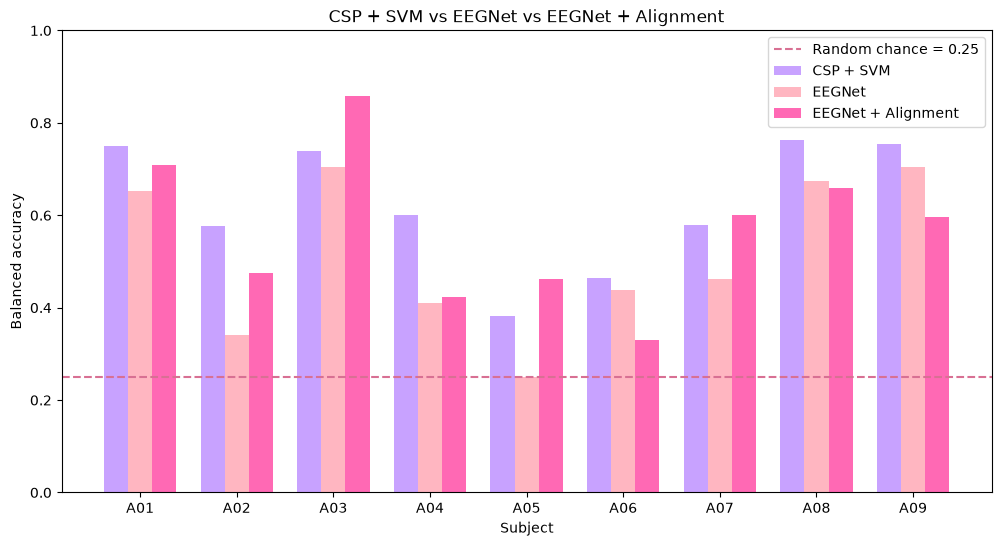

In [142]:
x = np.arange(len(comparison_final_df))
width = 0.25

plt.figure(figsize=(12, 6))

plt.bar(
    x - width,
    comparison_final_df["csp_svm"],
    width,
    label="CSP + SVM",
    color="#C8A2FF"
)

plt.bar(
    x,
    comparison_final_df["eegnet"],
    width,
    label="EEGNet",
    color="#FFB6C1"
)

plt.bar(
    x + width,
    comparison_final_df["eegnet_alignment"],
    width,
    label="EEGNet + Alignment",
    color="#FF69B4"
)

plt.axhline(
    y=0.25,
    linestyle="--",
    color="#D87093",
    label="Random chance = 0.25"
)

plt.xticks(
    x,
    comparison_final_df["subject"]
)

plt.ylim(0, 1)
plt.xlabel("Subject")
plt.ylabel("Balanced accuracy")
plt.title("CSP + SVM vs EEGNet vs EEGNet + Alignment")
plt.legend()

plt.show()

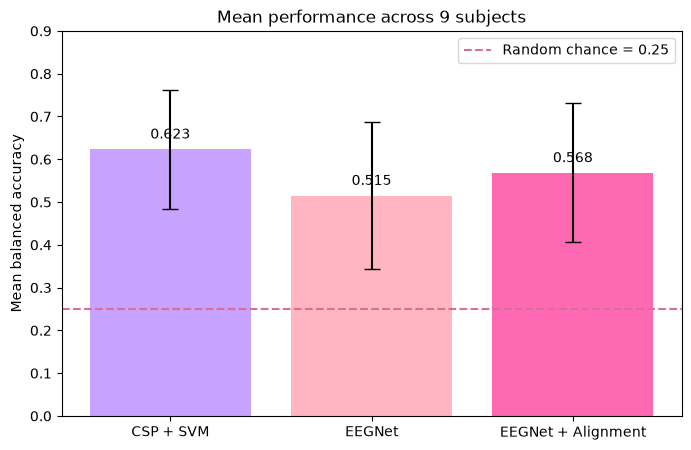

In [143]:
model_names = [
    "CSP + SVM",
    "EEGNet",
    "EEGNet + Alignment"
]

mean_scores = [
    comparison_final_df["csp_svm"].mean(),
    comparison_final_df["eegnet"].mean(),
    comparison_final_df["eegnet_alignment"].mean()
]

std_scores = [
    comparison_final_df["csp_svm"].std(),
    comparison_final_df["eegnet"].std(),
    comparison_final_df["eegnet_alignment"].std()
]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    model_names,
    mean_scores,
    yerr=std_scores,
    capsize=6,
    color=[
        "#C8A2FF",
        "#FFB6C1",
        "#FF69B4"
    ]
)

plt.axhline(
    y=0.25,
    linestyle="--",
    color="#D87093",
    label="Random chance = 0.25"
)

for bar, value in zip(bars, mean_scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.025,
        f"{value:.3f}",
        ha="center"
    )

plt.ylim(0, 0.9)
plt.ylabel("Mean balanced accuracy")
plt.title("Mean performance across 9 subjects")
plt.legend()

plt.show()

Euclidean Alignment улучшает устойчивость EEGNet к межсессионному сдвигу: средняя balanced accuracy выросла с 0.515 до 0.568. Однако классический CSP+SVM всё ещё остаётся более сильным baseline со средней balanced accuracy 0.623. Эффект alignment неоднороден между испытуемыми, что подтверждает выраженную индивидуальную вариабельность EEG.

### CAR + Alignment

Следующий эксперимент: добавить common average reference (CAR) перед фильтрацией и epoching, а затем применить Euclidean Alignment. CAR вычитает из каждого EEG-канала средний сигнал по всем EEG-каналам и может уменьшить общий фон и зависимость от референса. После этого проверим, улучшится ли перенос AxxT → AxxE.

идея отсюда
https://www.sciencedirect.com/science/article/pii/S1110016825001681?utm_source=chatgpt.com

Функция подготовки: Она делает тот же пайплайн, что и раньше, но перед фильтрацией добавляет CAR и затем применяет alignment.

In [144]:
def prepare_subject_train_eval_car_aligned(
    train_file_path,
    eval_file_path,
    eval_labels_path
):
    # ---------- TRAIN SESSION ----------
    raw_train = mne.io.read_raw_gdf(
        train_file_path,
        preload=True,
        verbose=False
    )

    # Правильно помечаем EOG
    raw_train.set_channel_types({
        "EOG-left": "eog",
        "EOG-central": "eog",
        "EOG-right": "eog"
    })

    # Common Average Reference только по EEG-каналам
    raw_train.set_eeg_reference(
        ref_channels="average",
        projection=False,
        verbose=False
    )

    # Band-pass 8–30 Hz
    raw_train_filtered = raw_train.copy().filter(
        l_freq=8,
        h_freq=30,
        verbose=False
    )

    events_train, event_id_train = mne.events_from_annotations(
        raw_train_filtered,
        verbose=False
    )

    train_event_id = {
        "left_hand": event_id_train["769"],
        "right_hand": event_id_train["770"],
        "feet": event_id_train["771"],
        "tongue": event_id_train["772"]
    }

    epochs_train = mne.Epochs(
        raw_train_filtered,
        events_train,
        event_id=train_event_id,
        tmin=0.5,
        tmax=4.0,
        baseline=None,
        preload=True,
        verbose=False
    )

    epochs_train = epochs_train.copy().pick("eeg")

    X_train_full = epochs_train.get_data()
    y_train_full = epochs_train.events[:, 2]

    train_label_map = {
        train_event_id["left_hand"]: 0,
        train_event_id["right_hand"]: 1,
        train_event_id["feet"]: 2,
        train_event_id["tongue"]: 3
    }

    y_train_full = np.array([
        train_label_map[v]
        for v in y_train_full
    ])

    # ---------- TEST SESSION ----------
    raw_test = mne.io.read_raw_gdf(
        eval_file_path,
        preload=True,
        verbose=False
    )

    raw_test.set_channel_types({
        "EOG-left": "eog",
        "EOG-central": "eog",
        "EOG-right": "eog"
    })

    # Тот же CAR для test-сессии
    raw_test.set_eeg_reference(
        ref_channels="average",
        projection=False,
        verbose=False
    )

    raw_test_filtered = raw_test.copy().filter(
        l_freq=8,
        h_freq=30,
        verbose=False
    )

    events_test, event_id_test = mne.events_from_annotations(
        raw_test_filtered,
        verbose=False
    )

    test_event_id = {
        "unknown_cue": event_id_test["783"]
    }

    epochs_test = mne.Epochs(
        raw_test_filtered,
        events_test,
        event_id=test_event_id,
        tmin=0.5,
        tmax=4.0,
        baseline=None,
        preload=True,
        verbose=False
    )

    epochs_test = epochs_test.copy().pick("eeg")

    X_test = epochs_test.get_data()

    # ---------- TRUE TEST LABELS ----------
    mat = loadmat(eval_labels_path)

    y_test = mat["classlabel"].ravel() - 1

    # ---------- EUCLIDEAN ALIGNMENT ----------
    X_train_full = euclidean_alignment(
        X_train_full
    )

    X_test = euclidean_alignment(
        X_test
    )

    # ---------- TRAIN / VALIDATION ----------
    X_train, X_val, y_train, y_val = train_test_split(
        X_train_full,
        y_train_full,
        test_size=0.2,
        random_state=42,
        stratify=y_train_full
    )

    # ---------- NORMALIZATION ----------
    # Статистики только по TRAIN
    mean = X_train.mean(
        axis=(0, 2),
        keepdims=True
    )

    std = X_train.std(
        axis=(0, 2),
        keepdims=True
    )

    X_train = (X_train - mean) / std
    X_val = (X_val - mean) / std
    X_test = (X_test - mean) / std

    return (
        X_train,
        X_val,
        X_test,
        y_train,
        y_val,
        y_test
    )

In [145]:
X_train_car, X_val_car, X_test_car, \
y_train_car, y_val_car, y_test_car = \
    prepare_subject_train_eval_car_aligned(
        train_file_a01,
        eval_file_a01,
        labels_file_a01
    )

print("Train:", X_train_car.shape)
print("Validation:", X_val_car.shape)
print("Test:", X_test_car.shape)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Train: (230, 22, 876)
Validation: (58, 22, 876)
Test: (288, 22, 876)


Теперь запускаем ту же регуляризованную EEGNet уже на X_train_car / X_val_car / X_test_car:

In [146]:
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

result_eegnet_a01_car_aligned = train_eegnet_regularized(
    X_train_car,
    X_val_car,
    X_test_car,
    y_train_car,
    y_val_car,
    y_test_car,
    num_epochs=100,
    batch_size=32,
    learning_rate=0.001,
    weight_decay=1e-4
)

print("\nИТОГ EEGNet + CAR + Alignment:")
print(f"Accuracy: {result_eegnet_a01_car_aligned['accuracy']:.3f}")
print(f"Balanced accuracy: {result_eegnet_a01_car_aligned['balanced_accuracy']:.3f}")
print(f"Macro F1: {result_eegnet_a01_car_aligned['f1_macro']:.3f}")
print(f"Kappa: {result_eegnet_a01_car_aligned['kappa']:.3f}")
print(f"Best validation accuracy: {result_eegnet_a01_car_aligned['best_val_accuracy']:.3f}")
print(f"Best epoch: {result_eegnet_a01_car_aligned['best_epoch']}")

Epoch 001 | loss=1.3739 | train_acc=0.261 | val_acc=0.328 | lr=0.001000
Epoch 002 | loss=1.3495 | train_acc=0.317 | val_acc=0.293 | lr=0.001000
Epoch 003 | loss=1.2795 | train_acc=0.457 | val_acc=0.345 | lr=0.001000
Epoch 004 | loss=1.2227 | train_acc=0.496 | val_acc=0.328 | lr=0.001000
Epoch 005 | loss=1.1147 | train_acc=0.535 | val_acc=0.362 | lr=0.001000
Epoch 006 | loss=1.0166 | train_acc=0.587 | val_acc=0.379 | lr=0.001000
Epoch 007 | loss=0.9308 | train_acc=0.570 | val_acc=0.328 | lr=0.001000
Epoch 008 | loss=0.8839 | train_acc=0.678 | val_acc=0.328 | lr=0.001000
Epoch 009 | loss=0.8268 | train_acc=0.617 | val_acc=0.310 | lr=0.001000
Epoch 010 | loss=0.7861 | train_acc=0.670 | val_acc=0.259 | lr=0.001000
Epoch 011 | loss=0.7461 | train_acc=0.691 | val_acc=0.276 | lr=0.001000
Epoch 012 | loss=0.7731 | train_acc=0.691 | val_acc=0.276 | lr=0.001000
Epoch 013 | loss=0.7446 | train_acc=0.683 | val_acc=0.293 | lr=0.001000
Epoch 014 | loss=0.7399 | train_acc=0.696 | val_acc=0.259 | lr=0

Добавление CAR перед Euclidean Alignment ухудшило качество на независимой сессии: при приемлемой validation accuracy модель практически потеряла способность переноситься на A01E. Следовательно, в текущем пайплайне CAR не подходит и дальше использовать его не будем.

### test-time adaptation (TTA) после alignment.

Следующий эксперимент — test-time adaptation (TTA) после alignment.
Идея взята из репозитория eegnet-v2, где для BCI Competition IV-2a после covariance alignment используют information-maximization test-time adaptation: на неразмеченных test-триалах адаптируются только параметры BatchNorm, при этом истинные y_test не используются. Цель — уменьшить остаточный сдвиг между train- и test-сессиями после alignment. В их экспериментах alignment улучшал результат, а IM-TTA давал дополнительный прирост; plain entropy adaptation без diversity-term работала хуже.

Важно для отсутствия утечки: AxxE.mat с истинными метками не участвует ни в адаптации, ни в выборе параметров. TTA использует только сигналы X_test; метки подключаются уже после адаптации исключительно для финального расчёта метрик. Такой подход относится к transductive/test-time adaptation, а не к supervised дообучению на test.

Полная функция TTA без использования y_test.

Идея: берём уже обученную EEGNet + Alignment, разрешаем дообучаться только параметрам BatchNorm и несколько шагов адаптируем их на X_test_al.

In [147]:
def adapt_eegnet_tta(
    model,
    X_test,
    batch_size=32,
    adaptation_steps=5,
    learning_rate=1e-4,
    diversity_weight=1.0
):
    # Копируем модель, чтобы не испортить исходную
    import copy
    model_tta = copy.deepcopy(model)

    # Замораживаем вообще все параметры
    for param in model_tta.parameters():
        param.requires_grad = False

    # Разрешаем обновлять только BatchNorm
    bn_params = []

    for module in model_tta.modules():
        if isinstance(module, (nn.BatchNorm1d, nn.BatchNorm2d)):
            module.train()

            if module.weight is not None:
                module.weight.requires_grad = True
                bn_params.append(module.weight)

            if module.bias is not None:
                module.bias.requires_grad = True
                bn_params.append(module.bias)

    # Test labels здесь НЕТ
    X_test_tensor = torch.tensor(
        X_test,
        dtype=torch.float32
    )

    test_loader = DataLoader(
        TensorDataset(X_test_tensor),
        batch_size=batch_size,
        shuffle=True
    )

    optimizer = torch.optim.Adam(
        bn_params,
        lr=learning_rate
    )

    # ---------- TEST-TIME ADAPTATION ----------
    for step in range(adaptation_steps):
        losses = []

        for (X_batch,) in test_loader:
            optimizer.zero_grad()

            logits = model_tta(X_batch)

            probabilities = torch.softmax(
                logits,
                dim=1
            )

            # 1. Entropy minimization:
            # хотим, чтобы предсказания каждого trial
            # становились более уверенными
            sample_entropy = -(
                probabilities *
                torch.log(probabilities + 1e-8)
            ).sum(dim=1).mean()

            # 2. Diversity:
            # не даём модели предсказывать один класс для всех
            mean_probability = probabilities.mean(dim=0)

            diversity_entropy = -(
                mean_probability *
                torch.log(mean_probability + 1e-8)
            ).sum()

            # Information Maximization objective
            loss = (
                sample_entropy
                - diversity_weight * diversity_entropy
            )

            loss.backward()
            optimizer.step()

            losses.append(loss.item())

        print(
            f"TTA step {step + 1:02d} | "
            f"loss={np.mean(losses):.4f}"
        )

    return model_tta

Теперь адаптируем нашу лучшую модель EEGNet + Alignment:

In [148]:
model_a01_tta = adapt_eegnet_tta(
    result_eegnet_a01_aligned["model"],
    X_test_al,
    batch_size=32,
    adaptation_steps=5,
    learning_rate=1e-4,
    diversity_weight=1.0
)

TTA step 01 | loss=-0.8435
TTA step 02 | loss=-0.8482
TTA step 03 | loss=-0.8458
TTA step 04 | loss=-0.8184
TTA step 05 | loss=-0.8566


После адаптации отдельно считаем предсказания:

In [149]:
model_a01_tta.eval()

X_test_tensor = torch.tensor(
    X_test_al,
    dtype=torch.float32
)

with torch.no_grad():
    outputs = model_a01_tta(X_test_tensor)
    y_pred_tta = outputs.argmax(dim=1).cpu().numpy()

И только теперь, когда адаптация закончилась, используем y_test_al для оценки:

In [150]:
print(
    "Accuracy:",
    round(
        accuracy_score(
            y_test_al,
            y_pred_tta
        ),
        3
    )
)

print(
    "Balanced accuracy:",
    round(
        balanced_accuracy_score(
            y_test_al,
            y_pred_tta
        ),
        3
    )
)

print(
    "Macro F1:",
    round(
        f1_score(
            y_test_al,
            y_pred_tta,
            average="macro"
        ),
        3
    )
)

print(
    "Kappa:",
    round(
        cohen_kappa_score(
            y_test_al,
            y_pred_tta
        ),
        3
    )
)

Accuracy: 0.333
Balanced accuracy: 0.333
Macro F1: 0.291
Kappa: 0.111


Test-time adaptation в текущей реализации ухудшила качество EEGNet: balanced accuracy снизилась с 0.708 до 0.333. Поэтому данный вариант TTA не подходит для текущего пайплайна и исключается из дальнейших экспериментов.

### Эксперимент: воспроизведение готового baseline eegnet-v2.


До этого мы собирали EEGNet-пайплайн сами и постепенно добавляли отдельные улучшения — регуляризацию, alignment и pretraining. Но наши результаты оставались ниже опубликованных. Поэтому теперь мы не будем менять отдельные части по одной, а попробуем воспроизвести готовую реализацию целиком: тот же preprocessing, ту же архитектуру EEGNet, тот же train/validation/test protocol и те же настройки обучения, что использованы авторами репозитория eegnet-v2.

Первый запуск делаем без alignment и без test-time adaptation. Это нужен как контрольный baseline: если он даст качество, близкое к опубликованному, значит проблема была именно в отличиях нашего собственного pipeline, а не в самом датасете.

Главные отличия от нашего старого preprocessing:

Было у нас:
8–30 Hz
0.5–4.0 с
876 samples
нормализация по train

У них:
0.5–100 Hz
1000 samples
per-trial, per-channel standardization

In [151]:
def per_trial_standardize(X):
    X = X.astype(np.float32)

    mean = X.mean(
        axis=2,
        keepdims=True
    )

    std = X.std(
        axis=2,
        keepdims=True
    ) + 1e-8

    return ((X - mean) / std).astype(np.float32)

In [152]:
def prepare_subject_eegnet_v2(
    train_file_path,
    eval_file_path,
    eval_labels_path
):
    # =========================
    # TRAIN SESSION
    # =========================
    raw_train = mne.io.read_raw_gdf(
        train_file_path,
        preload=True,
        verbose=False
    )

    raw_train.set_channel_types({
        "EOG-left": "eog",
        "EOG-central": "eog",
        "EOG-right": "eog"
    })

    raw_train = raw_train.copy().filter(
        l_freq=0.5,
        h_freq=100.0,
        verbose=False
    )

    events_train, event_id_train = \
        mne.events_from_annotations(
            raw_train,
            verbose=False
        )

    train_event_id = {
        "left_hand": event_id_train["769"],
        "right_hand": event_id_train["770"],
        "feet": event_id_train["771"],
        "tongue": event_id_train["772"]
    }

    # 1000 samples при 250 Hz = 4 секунды
    epochs_train = mne.Epochs(
        raw_train,
        events_train,
        event_id=train_event_id,
        tmin=0.0,
        tmax=3.996,
        baseline=None,
        preload=True,
        verbose=False
    )

    epochs_train = epochs_train.copy().pick("eeg")

    X_train_full = epochs_train.get_data()

    # на всякий случай фиксируем ровно 1000 отсчётов
    X_train_full = X_train_full[:, :, :1000]

    y_train_full = epochs_train.events[:, 2]

    train_label_map = {
        train_event_id["left_hand"]: 0,
        train_event_id["right_hand"]: 1,
        train_event_id["feet"]: 2,
        train_event_id["tongue"]: 3
    }

    y_train_full = np.array([
        train_label_map[v]
        for v in y_train_full
    ])

    # =========================
    # TEST SESSION
    # =========================
    raw_test = mne.io.read_raw_gdf(
        eval_file_path,
        preload=True,
        verbose=False
    )

    raw_test.set_channel_types({
        "EOG-left": "eog",
        "EOG-central": "eog",
        "EOG-right": "eog"
    })

    raw_test = raw_test.copy().filter(
        l_freq=0.5,
        h_freq=100.0,
        verbose=False
    )

    events_test, event_id_test = \
        mne.events_from_annotations(
            raw_test,
            verbose=False
        )

    test_event_id = {
        "unknown_cue": event_id_test["783"]
    }

    epochs_test = mne.Epochs(
        raw_test,
        events_test,
        event_id=test_event_id,
        tmin=0.0,
        tmax=3.996,
        baseline=None,
        preload=True,
        verbose=False
    )

    epochs_test = epochs_test.copy().pick("eeg")

    X_test = epochs_test.get_data()
    X_test = X_test[:, :, :1000]

    # =========================
    # TRUE TEST LABELS
    # =========================
    mat = loadmat(eval_labels_path)

    y_test = (
        mat["classlabel"]
        .ravel()
        .astype(int)
        - 1
    )

    # =========================
    # TRAIN / VALIDATION
    # =========================
    X_train, X_val, y_train, y_val = \
        train_test_split(
            X_train_full,
            y_train_full,
            test_size=0.2,
            random_state=42,
            stratify=y_train_full
        )

    # =========================
    # eegnet-v2 STANDARDIZATION
    # =========================
    X_train = per_trial_standardize(X_train)
    X_val = per_trial_standardize(X_val)
    X_test = per_trial_standardize(X_test)

    return (
        X_train,
        X_val,
        X_test,
        y_train,
        y_val,
        y_test
    )

In [153]:
X_train_v2, X_val_v2, X_test_v2, \
y_train_v2, y_val_v2, y_test_v2 = \
    prepare_subject_eegnet_v2(
        train_file_a01,
        eval_file_a01,
        labels_file_a01
    )

print("Train:", X_train_v2.shape, y_train_v2.shape)
print("Validation:", X_val_v2.shape, y_val_v2.shape)
print("Test:", X_test_v2.shape, y_test_v2.shape)

print("Classes train:", np.unique(y_train_v2))
print("Classes test:", np.unique(y_test_v2))

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Train: (230, 22, 1000) (230,)
Validation: (58, 22, 1000) (58,)
Test: (288, 22, 1000) (288,)
Classes train: [0 1 2 3]
Classes test: [0 1 2 3]


In [154]:
class UnifiedEEGNet(nn.Module):
    def __init__(self, n_classes=4, n_channels=22):
        super().__init__()

        # Временная свертка
        self.conv1 = nn.Conv2d(
            1,
            8,
            (1, 64),
            padding=(0, 31),
            bias=False
        )

        self.bn1 = nn.BatchNorm2d(8)

        # Пространственная depthwise-свертка по EEG-каналам
        self.depthwise = nn.Conv2d(
            8,
            16,
            (n_channels, 1),
            groups=8,
            bias=False
        )

        self.bn2 = nn.BatchNorm2d(16)

        self.pool1 = nn.AvgPool2d((1, 4))
        self.drop1 = nn.Dropout(0.35)

        # Второй временной блок
        self.conv2 = nn.Conv2d(
            16,
            32,
            (1, 16),
            padding=(0, 7),
            bias=False
        )

        self.bn3 = nn.BatchNorm2d(32)

        self.pool2 = nn.AvgPool2d((1, 8))
        self.drop2 = nn.Dropout(0.35)

        # Третий временной блок
        self.conv3 = nn.Conv2d(
            32,
            32,
            (1, 8),
            padding=(0, 3),
            bias=False
        )

        self.bn4 = nn.BatchNorm2d(32)

        self.pool3 = nn.AvgPool2d((1, 4))
        self.drop3 = nn.Dropout(0.35)

        # Независимо от длины сигнала приводим к фиксированному размеру
        self.adaptive_pool = nn.AdaptiveAvgPool2d((1, 8))

        # Классификатор
        self.fc = nn.Sequential(
            nn.Linear(32 * 8, 64),
            nn.GELU(),
            nn.Dropout(0.5),
            nn.Linear(64, n_classes)
        )

    def forward(self, x):
        # Вход: [batch, channels, time]
        # Conv2d ожидает: [batch, 1, channels, time]
        x = x.unsqueeze(1)

        x = self.conv1(x)
        x = self.bn1(x)

        x = self.depthwise(x)
        x = self.bn2(x)
        x = F.elu(x)

        x = self.pool1(x)
        x = self.drop1(x)

        x = self.conv2(x)
        x = self.bn3(x)
        x = F.elu(x)

        x = self.pool2(x)
        x = self.drop2(x)

        x = self.conv3(x)
        x = self.bn4(x)
        x = F.elu(x)

        x = self.pool3(x)
        x = self.drop3(x)

        x = self.adaptive_pool(x)

        x = x.view(x.size(0), -1)

        return self.fc(x)

In [155]:
model_v2 = UnifiedEEGNet(
    n_classes=4,
    n_channels=22
)

test_batch = torch.tensor(
    X_train_v2[:8],
    dtype=torch.float32
)

with torch.no_grad():
    output = model_v2(test_batch)

print("Input:", test_batch.shape)
print("Output:", output.shape)

print(
    "Количество параметров:",
    sum(p.numel() for p in model_v2.parameters())
)

Input: torch.Size([8, 22, 1000])
Output: torch.Size([8, 4])
Количество параметров: 34132


In [156]:
def train_unified_eegnet(
    X_train,
    X_val,
    X_test,
    y_train,
    y_val,
    y_test,
    num_epochs=100,
    batch_size=32,
    learning_rate=1e-3,
    weight_decay=1e-4
):
    X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
    y_train_tensor = torch.tensor(y_train, dtype=torch.long)

    X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
    y_val_tensor = torch.tensor(y_val, dtype=torch.long)

    X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
    y_test_tensor = torch.tensor(y_test, dtype=torch.long)

    train_loader = DataLoader(
        TensorDataset(X_train_tensor, y_train_tensor),
        batch_size=batch_size,
        shuffle=True
    )

    val_loader = DataLoader(
        TensorDataset(X_val_tensor, y_val_tensor),
        batch_size=batch_size,
        shuffle=False
    )

    test_loader = DataLoader(
        TensorDataset(X_test_tensor, y_test_tensor),
        batch_size=batch_size,
        shuffle=False
    )

    model = UnifiedEEGNet(
        n_classes=4,
        n_channels=22
    )

    criterion = nn.CrossEntropyLoss(
        label_smoothing=0.1
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay
    )

    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer,
        max_lr=learning_rate,
        epochs=num_epochs,
        steps_per_epoch=len(train_loader)
    )

    best_val_acc = 0.0
    best_state = None
    best_epoch = 0

    for epoch in range(num_epochs):
        model.train()

        train_correct = 0
        train_total = 0
        train_loss = 0.0

        for X_batch, y_batch in train_loader:
            optimizer.zero_grad()

            outputs = model(X_batch)

            loss = criterion(
                outputs,
                y_batch
            )

            loss.backward()
            optimizer.step()
            scheduler.step()

            train_loss += loss.item()

            preds = outputs.argmax(dim=1)

            train_correct += (
                preds == y_batch
            ).sum().item()

            train_total += y_batch.size(0)

        train_acc = train_correct / train_total

        model.eval()

        val_correct = 0
        val_total = 0
        val_loss = 0.0

        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                outputs = model(X_batch)

                loss = criterion(
                    outputs,
                    y_batch
                )

                val_loss += loss.item()

                preds = outputs.argmax(dim=1)

                val_correct += (
                    preds == y_batch
                ).sum().item()

                val_total += y_batch.size(0)

        val_acc = val_correct / val_total

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_epoch = epoch + 1

            best_state = {
                k: v.cpu().clone()
                for k, v in model.state_dict().items()
            }

        print(
            f"Epoch {epoch + 1:03d} | "
            f"loss={train_loss / len(train_loader):.4f} | "
            f"train_acc={train_acc:.3f} | "
            f"val_acc={val_acc:.3f}"
        )

    model.load_state_dict(best_state)

    model.eval()

    y_pred = []

    with torch.no_grad():
        for X_batch, _ in test_loader:
            outputs = model(X_batch)
            preds = outputs.argmax(dim=1)
            y_pred.extend(preds.cpu().numpy())

    y_pred = np.array(y_pred)

    return {
        "accuracy": accuracy_score(y_test, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
        "f1_macro": f1_score(y_test, y_pred, average="macro"),
        "kappa": cohen_kappa_score(y_test, y_pred),
        "best_val_accuracy": best_val_acc,
        "best_epoch": best_epoch,
        "model": model
    }

In [157]:
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

result_unified_a01 = train_unified_eegnet(
    X_train_v2,
    X_val_v2,
    X_test_v2,
    y_train_v2,
    y_val_v2,
    y_test_v2,
    num_epochs=100,
    batch_size=32,
    learning_rate=1e-3,
    weight_decay=1e-4
)

print("\nИТОГ UnifiedEEGNet:")
print(f"Accuracy: {result_unified_a01['accuracy']:.3f}")
print(f"Balanced accuracy: {result_unified_a01['balanced_accuracy']:.3f}")
print(f"Macro F1: {result_unified_a01['f1_macro']:.3f}")
print(f"Kappa: {result_unified_a01['kappa']:.3f}")
print(f"Best validation accuracy: {result_unified_a01['best_val_accuracy']:.3f}")
print(f"Best epoch: {result_unified_a01['best_epoch']}")

Epoch 001 | loss=1.3855 | train_acc=0.213 | val_acc=0.241
Epoch 002 | loss=1.3799 | train_acc=0.270 | val_acc=0.241
Epoch 003 | loss=1.3714 | train_acc=0.300 | val_acc=0.276
Epoch 004 | loss=1.3978 | train_acc=0.226 | val_acc=0.310
Epoch 005 | loss=1.3838 | train_acc=0.283 | val_acc=0.379
Epoch 006 | loss=1.3881 | train_acc=0.239 | val_acc=0.431
Epoch 007 | loss=1.3862 | train_acc=0.309 | val_acc=0.397
Epoch 008 | loss=1.3870 | train_acc=0.257 | val_acc=0.379
Epoch 009 | loss=1.3864 | train_acc=0.304 | val_acc=0.379
Epoch 010 | loss=1.3761 | train_acc=0.317 | val_acc=0.466
Epoch 011 | loss=1.3523 | train_acc=0.361 | val_acc=0.448
Epoch 012 | loss=1.3728 | train_acc=0.343 | val_acc=0.483
Epoch 013 | loss=1.3520 | train_acc=0.426 | val_acc=0.483
Epoch 014 | loss=1.3409 | train_acc=0.465 | val_acc=0.466
Epoch 015 | loss=1.3123 | train_acc=0.465 | val_acc=0.500
Epoch 016 | loss=1.3208 | train_acc=0.443 | val_acc=0.500
Epoch 017 | loss=1.2896 | train_acc=0.522 | val_acc=0.431
Epoch 018 | lo

In [158]:
print(f"Accuracy: {result_unified_a01['accuracy']:.3f}")
print(f"Balanced accuracy: {result_unified_a01['balanced_accuracy']:.3f}")
print(f"Macro F1: {result_unified_a01['f1_macro']:.3f}")
print(f"Kappa: {result_unified_a01['kappa']:.3f}")
print(f"Best validation accuracy: {result_unified_a01['best_val_accuracy']:.3f}")
print(f"Best epoch: {result_unified_a01['best_epoch']}")

Accuracy: 0.701
Balanced accuracy: 0.701
Macro F1: 0.698
Kappa: 0.602
Best validation accuracy: 0.793
Best epoch: 68


Воспроизведение архитектуры UnifiedEEGNet и preprocessing из eegnet-v2 дало balanced accuracy 0.701 на A01. Это существенно выше исходной EEGNet и сопоставимо с нашим вариантом EEGNet + Alignment. Следовательно, различия в архитектуре и preprocessing действительно влияют на качество, однако для полного воспроизведения опубликованного baseline необходимо добавить оставшиеся элементы pipeline, прежде всего augmentation.

### Эксперимент: UnifiedEEGNet + Euclidean Alignment по схеме eegnet-v2.


Перед alignment каждый trial стандартизируется отдельно по каждому EEG-каналу. Затем по training trials вычисляется средняя пространственная ковариционная матрица и её обратный квадратный корень используется для whitening train и validation. Для независимой test-сессии AxxE whitening-матрица вычисляется отдельно по test-сигналам без использования классов. После alignment все выборки нормализуются одним scalar mean/std, рассчитанным только на train. Такая схема соответствует реализации eegnet-v2 и не использует y_test при preprocessing.

Сначала функции EA один в один по логике репозитория:

In [159]:
def ea_reference(X):
    """
    Средняя пространственная covariance matrix по train trials.

    X: [trials, channels, time]
    return: [channels, channels]
    """
    X = X.astype(np.float64)

    covs = np.einsum(
        "nct,ndt->ncd",
        X,
        X
    ) / X.shape[2]

    R = covs.mean(axis=0)

    # симметризуем для численной устойчивости
    return 0.5 * (R + R.T)


def inverse_sqrt_matrix(R):
    """
    R^(-1/2) через eigendecomposition.
    """
    R = 0.5 * (R + R.T)

    eigenvalues, eigenvectors = np.linalg.eigh(R)

    # защита от очень маленьких собственных значений
    eigenvalues = np.clip(
        eigenvalues,
        1e-6,
        None
    )

    R_inv_sqrt = (
        eigenvectors *
        (1.0 / np.sqrt(eigenvalues))
    ) @ eigenvectors.T

    return R_inv_sqrt


def apply_ea(X, whitener):
    """
    Whitening каждого trial:
    X_aligned = R^(-1/2) @ X
    """
    return np.einsum(
        "cd,ndt->nct",
        whitener,
        X.astype(np.float64)
    ).astype(np.float32)

In [160]:
def prepare_subject_eegnet_v2_ea(
    train_file_path,
    eval_file_path,
    eval_labels_path
):
    # ==========================================
    # 1. Загружаем TRAIN SESSION
    # ==========================================
    raw_train = mne.io.read_raw_gdf(
        train_file_path,
        preload=True,
        verbose=False
    )

    raw_train.set_channel_types({
        "EOG-left": "eog",
        "EOG-central": "eog",
        "EOG-right": "eog"
    })

    # Как в eegnet-v2: broadband 0.5–100 Hz
    raw_train = raw_train.copy().filter(
        l_freq=0.5,
        h_freq=100.0,
        verbose=False
    )

    events_train, event_id_train = \
        mne.events_from_annotations(
            raw_train,
            verbose=False
        )

    train_event_id = {
        "left_hand": event_id_train["769"],
        "right_hand": event_id_train["770"],
        "feet": event_id_train["771"],
        "tongue": event_id_train["772"]
    }

    epochs_train = mne.Epochs(
        raw_train,
        events_train,
        event_id=train_event_id,
        tmin=0.0,
        tmax=3.996,
        baseline=None,
        preload=True,
        verbose=False
    )

    epochs_train = epochs_train.copy().pick("eeg")

    X_train_full = (
        epochs_train
        .get_data()[:, :, :1000]
        .astype(np.float32)
    )

    y_train_full = epochs_train.events[:, 2]

    label_map = {
        train_event_id["left_hand"]: 0,
        train_event_id["right_hand"]: 1,
        train_event_id["feet"]: 2,
        train_event_id["tongue"]: 3
    }

    y_train_full = np.array([
        label_map[v]
        for v in y_train_full
    ])

    # ==========================================
    # 2. Загружаем TEST SESSION
    # ==========================================
    raw_test = mne.io.read_raw_gdf(
        eval_file_path,
        preload=True,
        verbose=False
    )

    raw_test.set_channel_types({
        "EOG-left": "eog",
        "EOG-central": "eog",
        "EOG-right": "eog"
    })

    raw_test = raw_test.copy().filter(
        l_freq=0.5,
        h_freq=100.0,
        verbose=False
    )

    events_test, event_id_test = \
        mne.events_from_annotations(
            raw_test,
            verbose=False
        )

    test_event_id = {
        "unknown_cue": event_id_test["783"]
    }

    epochs_test = mne.Epochs(
        raw_test,
        events_test,
        event_id=test_event_id,
        tmin=0.0,
        tmax=3.996,
        baseline=None,
        preload=True,
        verbose=False
    )

    epochs_test = epochs_test.copy().pick("eeg")

    X_test = (
        epochs_test
        .get_data()[:, :, :1000]
        .astype(np.float32)
    )

    # true labels нужны только для финальной оценки
    mat = loadmat(eval_labels_path)

    y_test = (
        mat["classlabel"]
        .ravel()
        .astype(int)
        - 1
    )

    # ==========================================
    # 3. Per-trial standardization
    #    как в eegnet-v2
    # ==========================================
    X_train_full = per_trial_standardize(
        X_train_full
    )

    X_test = per_trial_standardize(
        X_test
    )

    # ==========================================
    # 4. TRAIN / VALIDATION SPLIT
    # ==========================================
    X_train, X_val, y_train, y_val = \
        train_test_split(
            X_train_full,
            y_train_full,
            test_size=0.2,
            random_state=42,
            stratify=y_train_full
        )

    # ==========================================
    # 5. EUCLIDEAN ALIGNMENT
    # ==========================================

    # Whitener считаем ТОЛЬКО по train
    R_train = ea_reference(X_train)

    W_train = inverse_sqrt_matrix(
        R_train
    )

    # Один и тот же train whitener
    # применяется к train и validation
    X_train = apply_ea(
        X_train,
        W_train
    )

    X_val = apply_ea(
        X_val,
        W_train
    )

    # Для TEST reference считается
    # отдельно по X_test, labels не используются
    R_test = ea_reference(X_test)

    W_test = inverse_sqrt_matrix(
        R_test
    )

    X_test = apply_ea(
        X_test,
        W_test
    )

    # ==========================================
    # 6. GLOBAL SCALAR Z-SCORE
    #    mean/std ТОЛЬКО ПО TRAIN
    # ==========================================
    mean = np.float32(
        X_train.mean()
    )

    std = np.float32(
        X_train.std()
    ) + 1e-8

    X_train = (
        (X_train - mean) / std
    ).astype(np.float32)

    X_val = (
        (X_val - mean) / std
    ).astype(np.float32)

    X_test = (
        (X_test - mean) / std
    ).astype(np.float32)

    return (
        X_train,
        X_val,
        X_test,
        y_train,
        y_val,
        y_test
    )

In [161]:
X_train_v2_ea, X_val_v2_ea, X_test_v2_ea, \
y_train_v2_ea, y_val_v2_ea, y_test_v2_ea = \
    prepare_subject_eegnet_v2_ea(
        train_file_a01,
        eval_file_a01,
        labels_file_a01
    )

print("Train:", X_train_v2_ea.shape)
print("Validation:", X_val_v2_ea.shape)
print("Test:", X_test_v2_ea.shape)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Train: (230, 22, 1000)
Validation: (58, 22, 1000)
Test: (288, 22, 1000)


In [162]:
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

result_unified_a01_ea = train_unified_eegnet(
    X_train_v2_ea,
    X_val_v2_ea,
    X_test_v2_ea,
    y_train_v2_ea,
    y_val_v2_ea,
    y_test_v2_ea,
    num_epochs=100,
    batch_size=32,
    learning_rate=1e-3,
    weight_decay=1e-4
)

print("\nИТОГ UnifiedEEGNet + EA:")
print(f"Accuracy: {result_unified_a01_ea['accuracy']:.3f}")
print(f"Balanced accuracy: {result_unified_a01_ea['balanced_accuracy']:.3f}")
print(f"Macro F1: {result_unified_a01_ea['f1_macro']:.3f}")
print(f"Kappa: {result_unified_a01_ea['kappa']:.3f}")
print(f"Best validation accuracy: {result_unified_a01_ea['best_val_accuracy']:.3f}")
print(f"Best epoch: {result_unified_a01_ea['best_epoch']}")

Epoch 001 | loss=1.3829 | train_acc=0.270 | val_acc=0.224
Epoch 002 | loss=1.3885 | train_acc=0.278 | val_acc=0.259
Epoch 003 | loss=1.3739 | train_acc=0.257 | val_acc=0.362
Epoch 004 | loss=1.3853 | train_acc=0.252 | val_acc=0.362
Epoch 005 | loss=1.3696 | train_acc=0.335 | val_acc=0.362
Epoch 006 | loss=1.3833 | train_acc=0.265 | val_acc=0.397
Epoch 007 | loss=1.3847 | train_acc=0.243 | val_acc=0.397
Epoch 008 | loss=1.3667 | train_acc=0.300 | val_acc=0.431
Epoch 009 | loss=1.3752 | train_acc=0.352 | val_acc=0.466
Epoch 010 | loss=1.3639 | train_acc=0.343 | val_acc=0.414
Epoch 011 | loss=1.3356 | train_acc=0.413 | val_acc=0.414
Epoch 012 | loss=1.3537 | train_acc=0.383 | val_acc=0.397
Epoch 013 | loss=1.3229 | train_acc=0.483 | val_acc=0.500
Epoch 014 | loss=1.3253 | train_acc=0.500 | val_acc=0.483
Epoch 015 | loss=1.2777 | train_acc=0.535 | val_acc=0.517
Epoch 016 | loss=1.2808 | train_acc=0.483 | val_acc=0.517
Epoch 017 | loss=1.2486 | train_acc=0.570 | val_acc=0.534
Epoch 018 | lo

In [163]:
print(f"Accuracy: {result_unified_a01_ea['accuracy']:.3f}")
print(f"Balanced accuracy: {result_unified_a01_ea['balanced_accuracy']:.3f}")
print(f"Macro F1: {result_unified_a01_ea['f1_macro']:.3f}")
print(f"Kappa: {result_unified_a01_ea['kappa']:.3f}")

Accuracy: 0.743
Balanced accuracy: 0.743
Macro F1: 0.739
Kappa: 0.657


Euclidean Alignment дал заметный прирост качества UnifiedEEGNet на независимой сессии A01E. Balanced accuracy выросла с 0.701 до 0.743, Macro-F1 — с 0.698 до 0.739, kappa — с 0.602 до 0.657. Это подтверждает, что выравнивание ковариационной структуры между сессиями помогает уменьшить session shift.

In [164]:
unified_ea_results = []

for subject_num in range(1, 10):
    subject = f"A{subject_num:02d}"

    train_file = os.path.join(
        base_path,
        f"{subject}T.gdf"
    )

    eval_file = os.path.join(
        base_path,
        f"{subject}E.gdf"
    )

    labels_file = os.path.join(
        labels_base_path,
        f"{subject}E.mat"
    )

    print(f"\nОбрабатываем {subject}...")

    random.seed(42)
    np.random.seed(42)
    torch.manual_seed(42)

    # preprocessing + EA как в eegnet-v2
    X_train_v2_ea, X_val_v2_ea, X_test_v2_ea, \
    y_train_v2_ea, y_val_v2_ea, y_test_v2_ea = \
        prepare_subject_eegnet_v2_ea(
            train_file,
            eval_file,
            labels_file
        )

    # UnifiedEEGNet
    result = train_unified_eegnet(
        X_train_v2_ea,
        X_val_v2_ea,
        X_test_v2_ea,
        y_train_v2_ea,
        y_val_v2_ea,
        y_test_v2_ea,
        num_epochs=100,
        batch_size=32,
        learning_rate=1e-3,
        weight_decay=1e-4
    )

    unified_ea_results.append({
        "subject": subject,
        "accuracy": result["accuracy"],
        "balanced_accuracy": result["balanced_accuracy"],
        "f1_macro": result["f1_macro"],
        "kappa": result["kappa"],
        "best_val_accuracy": result["best_val_accuracy"],
        "best_epoch": result["best_epoch"]
    })

    gc.collect()

unified_ea_results_df = pd.DataFrame(
    unified_ea_results
)

unified_ea_results_df


Обрабатываем A01...


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Epoch 001 | loss=1.3829 | train_acc=0.270 | val_acc=0.224
Epoch 002 | loss=1.3885 | train_acc=0.278 | val_acc=0.259
Epoch 003 | loss=1.3739 | train_acc=0.257 | val_acc=0.362
Epoch 004 | loss=1.3853 | train_acc=0.252 | val_acc=0.362
Epoch 005 | loss=1.3696 | train_acc=0.335 | val_acc=0.362
Epoch 006 | loss=1.3833 | train_acc=0.265 | val_acc=0.397
Epoch 007 | loss=1.3847 | train_acc=0.243 | val_acc=0.397
Epoch 008 | loss=1.3667 | train_acc=0.300 | val_acc=0.431
Epoch 009 | loss=1.3752 | train_acc=0.352 | val_acc=0.466
Epoch 010 | loss=1.3639 | train_acc=0.343 | val_acc=0.414
Epoch 011 | loss=1.3356 | train_acc=0.413 | val_acc=0.414
Epoch 012 | loss=1.3537 | train_acc=0.383 | val_acc=0.397
Epoch 013 | loss=1.3229 | train_acc=0.483 | val_acc=0.500
Epoch 014 | loss=1.3253 | train_acc=0.500 | val_acc=0.483
Epoch 015 | loss=1.2777 | train_acc=0.535 | val_acc=0.517
Epoch 016 | loss=1.2808 | train_acc=0.483 | val_acc=0.517
Epoch 017 | loss=1.2486 | train_acc=0.570 | val_acc=0.534
Epoch 018 | lo

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Epoch 001 | loss=1.4004 | train_acc=0.239 | val_acc=0.259
Epoch 002 | loss=1.3878 | train_acc=0.257 | val_acc=0.310
Epoch 003 | loss=1.3724 | train_acc=0.296 | val_acc=0.293
Epoch 004 | loss=1.3900 | train_acc=0.265 | val_acc=0.293
Epoch 005 | loss=1.3874 | train_acc=0.278 | val_acc=0.293
Epoch 006 | loss=1.3863 | train_acc=0.243 | val_acc=0.293
Epoch 007 | loss=1.3749 | train_acc=0.278 | val_acc=0.328
Epoch 008 | loss=1.3816 | train_acc=0.274 | val_acc=0.293
Epoch 009 | loss=1.3700 | train_acc=0.343 | val_acc=0.276
Epoch 010 | loss=1.3682 | train_acc=0.339 | val_acc=0.310
Epoch 011 | loss=1.3547 | train_acc=0.348 | val_acc=0.310
Epoch 012 | loss=1.3476 | train_acc=0.348 | val_acc=0.276
Epoch 013 | loss=1.3560 | train_acc=0.400 | val_acc=0.224
Epoch 014 | loss=1.3260 | train_acc=0.448 | val_acc=0.241
Epoch 015 | loss=1.3249 | train_acc=0.409 | val_acc=0.259
Epoch 016 | loss=1.3003 | train_acc=0.426 | val_acc=0.259
Epoch 017 | loss=1.2869 | train_acc=0.470 | val_acc=0.276
Epoch 018 | lo

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


... (10 outputs left out)

Epoch 001 | loss=1.3981 | train_acc=0.183 | val_acc=0.224
Epoch 002 | loss=1.3871 | train_acc=0.274 | val_acc=0.190
Epoch 003 | loss=1.3812 | train_acc=0.274 | val_acc=0.276
Epoch 004 | loss=1.3996 | train_acc=0.248 | val_acc=0.276
Epoch 005 | loss=1.3870 | train_acc=0.235 | val_acc=0.276
Epoch 006 | loss=1.3829 | train_acc=0.317 | val_acc=0.293
Epoch 007 | loss=1.3751 | train_acc=0.352 | val_acc=0.310
Epoch 008 | loss=1.3822 | train_acc=0.274 | val_acc=0.345
Epoch 009 | loss=1.3613 | train_acc=0.383 | val_acc=0.345
Epoch 010 | loss=1.3526 | train_acc=0.352 | val_acc=0.414
Epoch 011 | loss=1.3308 | train_acc=0.404 | val_acc=0.379
Epoch 012 | loss=1.3266 | train_acc=0.400 | val_acc=0.362
Epoch 013 | loss=1.3240 | train_acc=0.426 | val_acc=0.345
Epoch 014 | loss=1.3035 | train_acc=0.470 | val_acc=0.345
Epoch 015 | loss=1.2629 | train_acc=0.526 | val_acc=0.379
Epoch 016 | loss=1.2373 | train_acc=0.504 | val_acc=0.397
Epoch 017 | loss=1.1842 | train_acc=0.591 | val_acc=0.448
Epoch 018 | lo

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Epoch 001 | loss=1.3988 | train_acc=0.191 | val_acc=0.259
Epoch 002 | loss=1.3805 | train_acc=0.335 | val_acc=0.328
Epoch 003 | loss=1.3782 | train_acc=0.300 | val_acc=0.345
Epoch 004 | loss=1.3947 | train_acc=0.226 | val_acc=0.362
Epoch 005 | loss=1.3961 | train_acc=0.226 | val_acc=0.345
Epoch 006 | loss=1.3878 | train_acc=0.300 | val_acc=0.362
Epoch 007 | loss=1.3694 | train_acc=0.361 | val_acc=0.379
Epoch 008 | loss=1.3784 | train_acc=0.361 | val_acc=0.414
Epoch 009 | loss=1.3695 | train_acc=0.322 | val_acc=0.448
Epoch 010 | loss=1.3618 | train_acc=0.343 | val_acc=0.466
Epoch 011 | loss=1.3533 | train_acc=0.370 | val_acc=0.431
Epoch 012 | loss=1.3542 | train_acc=0.357 | val_acc=0.431
Epoch 013 | loss=1.3243 | train_acc=0.448 | val_acc=0.431
Epoch 014 | loss=1.3170 | train_acc=0.496 | val_acc=0.448
Epoch 015 | loss=1.2944 | train_acc=0.478 | val_acc=0.483
Epoch 016 | loss=1.2663 | train_acc=0.535 | val_acc=0.552
Epoch 017 | loss=1.2175 | train_acc=0.526 | val_acc=0.552
Epoch 018 | lo

,subject,accuracy,balanced_accuracy,f1_macro,kappa,best_val_accuracy,best_epoch
0,A01,0.743056,0.743056,0.738950,0.657407,0.810345,53
1,A02,0.493056,0.493056,0.486266,0.324074,0.620690,36
2,A03,0.760417,0.760417,0.753035,0.680556,0.844828,64
3,A04,0.395833,0.395833,0.390530,0.194444,0.534483,82
4,A05,0.659722,0.659722,0.655177,0.546296,0.724138,36
5,A06,0.458333,0.458333,0.458966,0.277778,0.689655,69
6,A07,0.611111,0.611111,0.610132,0.481481,0.724138,81
7,A08,0.739583,0.739583,0.737589,0.652778,0.775862,66
8,A09,0.701389,0.701389,0.696844,0.601852,0.879310,59


In [165]:
print(
    "Accuracy:",
    f"{unified_ea_results_df['accuracy'].mean():.3f} ± "
    f"{unified_ea_results_df['accuracy'].std():.3f}"
)

print(
    "Balanced accuracy:",
    f"{unified_ea_results_df['balanced_accuracy'].mean():.3f} ± "
    f"{unified_ea_results_df['balanced_accuracy'].std():.3f}"
)

print(
    "Macro F1:",
    f"{unified_ea_results_df['f1_macro'].mean():.3f} ± "
    f"{unified_ea_results_df['f1_macro'].std():.3f}"
)

print(
    "Kappa:",
    f"{unified_ea_results_df['kappa'].mean():.3f} ± "
    f"{unified_ea_results_df['kappa'].std():.3f}"
)

Accuracy: 0.618 ± 0.137
Balanced accuracy: 0.618 ± 0.137
Macro F1: 0.614 ± 0.137
Kappa: 0.491 ± 0.183


Перенос preprocessing, архитектуры UnifiedEEGNet и Euclidean Alignment из eegnet-v2 заметно улучшил нейросетевой baseline: средняя balanced accuracy выросла до 0.618. При этом результат стал сопоставим с классическим CSP+SVM baseline (~0.623), хотя между испытуемыми по-прежнему сохраняется заметная вариабельность. Наиболее слабые результаты наблюдаются у A04 и A06, тогда как A01, A03, A08 и A09 классифицируются существенно лучше.

In [166]:
comparison_best_df = (
    csp_te_results_df[
        ["subject", "balanced_accuracy"]
    ]
    .rename(columns={
        "balanced_accuracy": "csp_svm"
    })
    .merge(
        eegnet_aligned_results_df[
            ["subject", "balanced_accuracy"]
        ].rename(columns={
            "balanced_accuracy": "eegnet_alignment"
        }),
        on="subject"
    )
    .merge(
        unified_ea_results_df[
            ["subject", "balanced_accuracy"]
        ].rename(columns={
            "balanced_accuracy": "unified_ea"
        }),
        on="subject"
    )
)

comparison_best_df

,subject,csp_svm,eegnet_alignment,unified_ea
0,A01,0.750000,0.708333,0.743056
1,A02,0.576389,0.475694,0.493056
2,A03,0.739583,0.857639,0.760417
3,A04,0.600694,0.423611,0.395833
4,A05,0.381944,0.461806,0.659722
5,A06,0.465278,0.329861,0.458333
6,A07,0.579861,0.600694,0.611111
7,A08,0.763889,0.659722,0.739583
8,A09,0.753472,0.597222,0.701389


In [167]:
mean_accuracy = unified_ea_results_df["accuracy"].mean()
std_accuracy = unified_ea_results_df["accuracy"].std()

print(f"Mean accuracy: {mean_accuracy:.3f}")
print(f"Std accuracy: {std_accuracy:.3f}")

Mean accuracy: 0.618
Std accuracy: 0.137


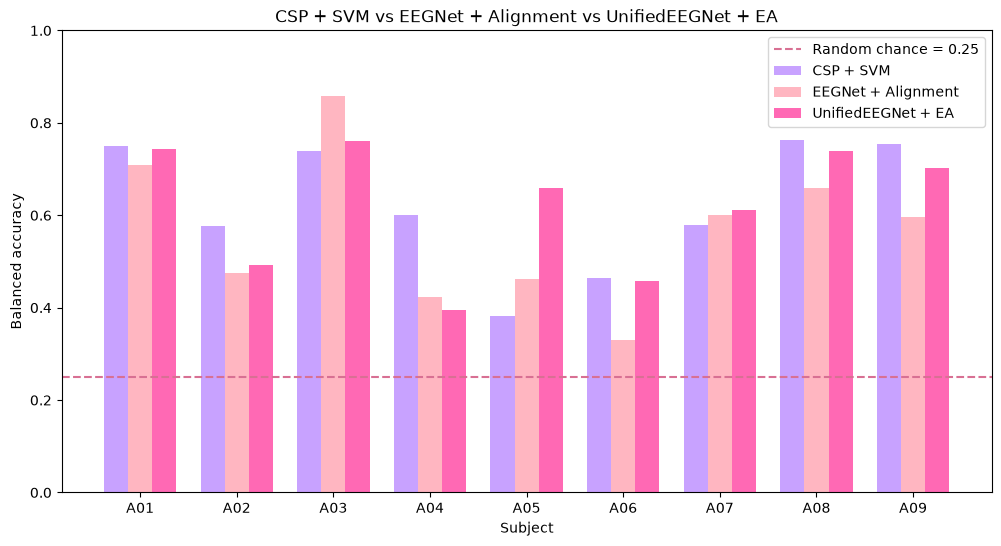

In [168]:
x = np.arange(len(comparison_best_df))
width = 0.25

plt.figure(figsize=(12, 6))

plt.bar(
    x - width,
    comparison_best_df["csp_svm"],
    width,
    label="CSP + SVM",
    color="#C8A2FF"
)

plt.bar(
    x,
    comparison_best_df["eegnet_alignment"],
    width,
    label="EEGNet + Alignment",
    color="#FFB6C1"
)

plt.bar(
    x + width,
    comparison_best_df["unified_ea"],
    width,
    label="UnifiedEEGNet + EA",
    color="#FF69B4"
)

plt.axhline(
    y=0.25,
    linestyle="--",
    color="#D87093",
    label="Random chance = 0.25"
)

plt.xticks(
    x,
    comparison_best_df["subject"]
)

plt.ylim(0, 1)

plt.xlabel("Subject")
plt.ylabel("Balanced accuracy")

plt.title(
    "CSP + SVM vs EEGNet + Alignment vs UnifiedEEGNet + EA"
)

plt.legend()

plt.show()

UnifiedEEGNet + EA заметно улучшает нейросетевой baseline и практически догоняет CSP+SVM по среднему качеству. При этом эффект остаётся неоднородным между испытуемыми: часть субъектов классифицируется хорошо, тогда как A04 и A06 остаются сложными.

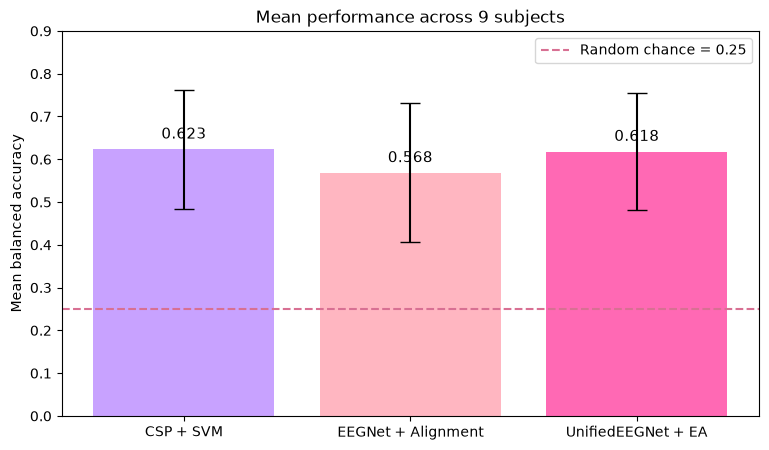

In [169]:
model_names = [
    "CSP + SVM",
    "EEGNet + Alignment",
    "UnifiedEEGNet + EA"
]

mean_scores = [
    comparison_best_df["csp_svm"].mean(),
    comparison_best_df["eegnet_alignment"].mean(),
    comparison_best_df["unified_ea"].mean()
]

std_scores = [
    comparison_best_df["csp_svm"].std(),
    comparison_best_df["eegnet_alignment"].std(),
    comparison_best_df["unified_ea"].std()
]

plt.figure(figsize=(9, 5))

bars = plt.bar(
    model_names,
    mean_scores,
    yerr=std_scores,
    capsize=7,
    color=[
        "#C8A2FF",
        "#FFB6C1",
        "#FF69B4"
    ]
)

plt.axhline(
    y=0.25,
    linestyle="--",
    color="#D87093",
    label="Random chance = 0.25"
)

for bar, mean, std in zip(bars, mean_scores, std_scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        mean + 0.025,
        f"{mean:.3f}",
        ha="center",
        fontsize=11
    )

plt.ylim(0, 0.9)
plt.ylabel("Mean balanced accuracy")
plt.title("Mean performance across 9 subjects")
plt.legend()

plt.show()

осле воспроизведения preprocessing, архитектуры UnifiedEEGNet и Euclidean Alignment среднее качество нейросетевой модели выросло до 0.618 balanced accuracy и практически сравнялось с CSP+SVM (0.623). Это существенно лучше предыдущего варианта EEGNet + Alignment (0.568).

## CROSS-SUBJECT PRETRAINING

A02T + A03T + ... + A09T

        ↓

предобучаем UnifiedEEGNet

        ↓

берём A01T

        ↓

fine-tuning на A01

        ↓
        
тестируем на A01E

In [170]:
import os
import numpy as np
import mne

функция подготовки одного training-файла.

In [171]:
def prepare_pretrain_subject_v2(file_path):
    raw = mne.io.read_raw_gdf(
        file_path,
        preload=True,
        verbose=False
    )

    raw.set_channel_types({
        "EOG-left": "eog",
        "EOG-central": "eog",
        "EOG-right": "eog"
    })

    raw.filter(
        0.5,
        100.0,
        verbose=False
    )

    events, event_id = mne.events_from_annotations(
        raw,
        verbose=False
    )

    # Берём реальные event_id, которые MNE присвоил кодам 769–772
    mi_event_id = {
        code: event_id[code]
        for code in ["769", "770", "771", "772"]
        if code in event_id
    }

    print("Motor imagery events:", mi_event_id)

    epochs = mne.Epochs(
        raw,
        events,
        event_id=mi_event_id,
        tmin=0.0,
        tmax=3.996,
        baseline=None,
        preload=True,
        picks="eeg",
        verbose=False
    )

    X = epochs.get_data()[:, :, :1000]

    # Сейчас epochs.events содержит внутренние ID MNE,
    # поэтому создаём обратное соответствие:
    # внутренний ID MNE -> наш класс 0–3
    label_map = {
        event_id["769"]: 0,
        event_id["770"]: 1,
        event_id["771"]: 2,
        event_id["772"]: 3
    }

    y = np.array([
        label_map[event]
        for event in epochs.events[:, 2]
    ])

    X = per_trial_standardize(X)

    return X.astype(np.float32), y.astype(np.int64)

In [172]:
data_dir = "/Users/irina/Desktop/master project/BCICIV_2a_gdf"

X_pretrain_list = []
y_pretrain_list = []
subject_pretrain_list = []

for subject_num in range(2, 10):
    subject = f"A{subject_num:02d}"

    file_path = os.path.join(
        data_dir,
        f"{subject}T.gdf"
    )

    X_subj, y_subj = prepare_pretrain_subject_v2(file_path)

    X_pretrain_list.append(X_subj)
    y_pretrain_list.append(y_subj)

    subject_pretrain_list.extend(
        [subject] * len(y_subj)
    )

    print(
        subject,
        X_subj.shape,
        np.bincount(y_subj)
    )

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Motor imagery events: {'769': 7, '770': 8, '771': 9, '772': 10}
A02 (288, 22, 1000) [72 72 72 72]


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Motor imagery events: {'769': 7, '770': 8, '771': 9, '772': 10}
A03 (288, 22, 1000) [72 72 72 72]


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Motor imagery events: {'769': 5, '770': 6, '771': 7, '772': 8}
A04 (288, 22, 1000) [72 72 72 72]


... (6 outputs left out)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Motor imagery events: {'769': 7, '770': 8, '771': 9, '772': 10}
A08 (288, 22, 1000) [72 72 72 72]


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Motor imagery events: {'769': 7, '770': 8, '771': 9, '772': 10}
A09 (288, 22, 1000) [72 72 72 72]


In [173]:
X_pretrain = np.concatenate(X_pretrain_list, axis=0)
y_pretrain = np.concatenate(y_pretrain_list, axis=0)
subject_pretrain = np.array(subject_pretrain_list)

print("X_pretrain:", X_pretrain.shape)
print("y_pretrain:", y_pretrain.shape)
print("Subjects:", np.unique(subject_pretrain))
print("Classes:", np.bincount(y_pretrain))

X_pretrain: (2304, 22, 1000)
y_pretrain: (2304,)
Subjects: ['A02' 'A03' 'A04' 'A05' 'A06' 'A07' 'A08' 'A09']
Classes: [576 576 576 576]


In [174]:
train_subjects = [
    "A02", "A03", "A04", "A05",
    "A06", "A07", "A08"
]

val_subjects = ["A09"]

train_mask = np.isin(
    subject_pretrain,
    train_subjects
)

val_mask = np.isin(
    subject_pretrain,
    val_subjects
)

X_pretrain_train = X_pretrain[train_mask]
y_pretrain_train = y_pretrain[train_mask]

X_pretrain_val = X_pretrain[val_mask]
y_pretrain_val = y_pretrain[val_mask]

print("Pretrain train:")
print(X_pretrain_train.shape)
print(np.bincount(y_pretrain_train))

print("\nPretrain validation:")
print(X_pretrain_val.shape)
print(np.bincount(y_pretrain_val))

Pretrain train:
(2016, 22, 1000)
[504 504 504 504]

Pretrain validation:
(288, 22, 1000)
[72 72 72 72]


In [175]:
def ea_reference(X):
    X = X.astype(np.float64)
    covs = np.einsum("nct,ndt->ncd", X, X) / X.shape[2]
    R = covs.mean(axis=0)
    return 0.5 * (R + R.T)

def inverse_sqrt_matrix(R):
    R = 0.5 * (R + R.T)
    eigenvalues, eigenvectors = np.linalg.eigh(R)
    eigenvalues = np.clip(eigenvalues, 1e-6, None)

    R_inv_sqrt = (
        eigenvectors * (1.0 / np.sqrt(eigenvalues))
    ) @ eigenvectors.T

    return R_inv_sqrt

def apply_ea(X, whitener):
    return np.einsum(
        "cd,ndt->nct",
        whitener,
        X.astype(np.float64)
    ).astype(np.float32)

In [176]:
def align_subject_data(X):
    R = ea_reference(X)
    W = inverse_sqrt_matrix(R)
    X_aligned = apply_ea(X, W)

    return X_aligned

In [177]:
X_pretrain_train_aligned_list = []
y_pretrain_train_aligned_list = []

for subject in train_subjects:
    mask = subject_pretrain == subject

    X_subj = X_pretrain[mask]
    y_subj = y_pretrain[mask]

    X_subj_aligned = align_subject_data(X_subj)

    X_pretrain_train_aligned_list.append(
        X_subj_aligned
    )

    y_pretrain_train_aligned_list.append(
        y_subj
    )

    print(
        subject,
        X_subj_aligned.shape
    )

A02 (288, 22, 1000)
A03 (288, 22, 1000)
A04 (288, 22, 1000)
A05 (288, 22, 1000)
A06 (288, 22, 1000)
A07 (288, 22, 1000)
A08 (288, 22, 1000)


In [178]:
X_pretrain_train_aligned = np.concatenate(
    X_pretrain_train_aligned_list,
    axis=0
)

y_pretrain_train_aligned = np.concatenate(
    y_pretrain_train_aligned_list,
    axis=0
)

print(
    "Train aligned:",
    X_pretrain_train_aligned.shape
)

print(
    "Classes:",
    np.bincount(y_pretrain_train_aligned)
)

Train aligned: (2016, 22, 1000)
Classes: [504 504 504 504]


In [179]:
mask = subject_pretrain == "A09"

X_pretrain_val_raw = X_pretrain[mask]
y_pretrain_val_aligned = y_pretrain[mask]

X_pretrain_val_aligned = align_subject_data(
    X_pretrain_val_raw
)

print(
    "Validation aligned:",
    X_pretrain_val_aligned.shape
)

print(
    "Classes:",
    np.bincount(y_pretrain_val_aligned)
)

Validation aligned: (288, 22, 1000)
Classes: [72 72 72 72]


In [180]:
pretrain_mean = np.float32(
    X_pretrain_train_aligned.mean()
)

pretrain_std = np.float32(
    X_pretrain_train_aligned.std()
) + 1e-8

X_pretrain_train_aligned = (
    X_pretrain_train_aligned - pretrain_mean
) / pretrain_std

X_pretrain_val_aligned = (
    X_pretrain_val_aligned - pretrain_mean
) / pretrain_std

In [181]:
print(
    "Train mean:",
    X_pretrain_train_aligned.mean()
)

print(
    "Train std:",
    X_pretrain_train_aligned.std()
)

print(
    "Validation mean:",
    X_pretrain_val_aligned.mean()
)

print(
    "Validation std:",
    X_pretrain_val_aligned.std()
)

Train mean: 3.2898666e-11
Train std: 1.0
Validation mean: 6.141085e-11
Validation std: 1.0


In [182]:
import copy
import torch
from torch.utils.data import TensorDataset, DataLoader

In [183]:


def pretrain_unified_eegnet(
    X_train,
    y_train,
    X_val,
    y_val,
    num_epochs=100,
    batch_size=32,
    learning_rate=1e-3
):
    device = torch.device("cpu")

    print("Device:", device)

    X_train_t = torch.tensor(
        X_train,
        dtype=torch.float32
    )

    y_train_t = torch.tensor(
        y_train,
        dtype=torch.long
    )

    X_val_t = torch.tensor(
        X_val,
        dtype=torch.float32
    )

    y_val_t = torch.tensor(
        y_val,
        dtype=torch.long
    )

    train_loader = DataLoader(
        TensorDataset(X_train_t, y_train_t),
        batch_size=batch_size,
        shuffle=True
    )

    val_loader = DataLoader(
        TensorDataset(X_val_t, y_val_t),
        batch_size=batch_size,
        shuffle=False
    )

    model = UnifiedEEGNet(
        n_classes=4,
        n_channels=22
    ).to(device)

    criterion = torch.nn.CrossEntropyLoss(
        label_smoothing=0.1
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=1e-4
    )

    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer,
        max_lr=learning_rate,
        epochs=num_epochs,
        steps_per_epoch=len(train_loader)
    )

    best_val_acc = 0.0
    best_epoch = 0
    best_state = None

    for epoch in range(num_epochs):

        # --------------------
        # TRAIN
        # --------------------
        model.train()

        for X_batch, y_batch in train_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()

            logits = model(X_batch)

            loss = criterion(
                logits,
                y_batch
            )

            loss.backward()

            optimizer.step()
            scheduler.step()

        # --------------------
        # VALIDATION
        # --------------------
        model.eval()

        correct = 0
        total = 0

        with torch.no_grad():

            for X_batch, y_batch in val_loader:

                X_batch = X_batch.to(device)
                y_batch = y_batch.to(device)

                logits = model(X_batch)

                predictions = logits.argmax(dim=1)

                correct += (
                    predictions == y_batch
                ).sum().item()

                total += y_batch.size(0)

        val_acc = correct / total

        if val_acc > best_val_acc:

            best_val_acc = val_acc
            best_epoch = epoch + 1

            best_state = copy.deepcopy(
                model.state_dict()
            )

        if (epoch + 1) % 10 == 0:

            print(
                f"Epoch {epoch+1:3d} | "
                f"Val accuracy: {val_acc:.3f} | "
                f"Best: {best_val_acc:.3f}"
            )

    model.load_state_dict(
        best_state
    )

    print("\nBest validation accuracy:", round(best_val_acc, 3))
    print("Best epoch:", best_epoch)

    return model

In [184]:
pretrained_model = pretrain_unified_eegnet(
    X_pretrain_train_aligned,
    y_pretrain_train_aligned,
    X_pretrain_val_aligned,
    y_pretrain_val_aligned,
    num_epochs=100,
    batch_size=32,
    learning_rate=1e-3
)

Device: cpu
Epoch  10 | Val accuracy: 0.396 | Best: 0.396
Epoch  20 | Val accuracy: 0.458 | Best: 0.483
Epoch  30 | Val accuracy: 0.503 | Best: 0.542
Epoch  40 | Val accuracy: 0.552 | Best: 0.580
Epoch  50 | Val accuracy: 0.611 | Best: 0.611
Epoch  60 | Val accuracy: 0.635 | Best: 0.635
Epoch  70 | Val accuracy: 0.628 | Best: 0.639
Epoch  80 | Val accuracy: 0.628 | Best: 0.642
Epoch  90 | Val accuracy: 0.639 | Best: 0.642
Epoch 100 | Val accuracy: 0.618 | Best: 0.642

Best validation accuracy: 0.642
Best epoch: 79


In [185]:
import copy
import torch
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, cohen_kappa_score

In [186]:


def finetune_pretrained_unified_eegnet(
    pretrained_model,
    X_train,
    y_train,
    X_val,
    y_val,
    X_test,
    y_test,
    num_epochs=60,
    batch_size=32,
    learning_rate=1e-4
):
    device = torch.device("cpu")
    print("Device:", device)

    model = copy.deepcopy(pretrained_model).to(device)

    train_loader = DataLoader(
        TensorDataset(
            torch.tensor(X_train, dtype=torch.float32),
            torch.tensor(y_train, dtype=torch.long)
        ),
        batch_size=batch_size,
        shuffle=True
    )

    val_loader = DataLoader(
        TensorDataset(
            torch.tensor(X_val, dtype=torch.float32),
            torch.tensor(y_val, dtype=torch.long)
        ),
        batch_size=batch_size,
        shuffle=False
    )

    test_loader = DataLoader(
        TensorDataset(
            torch.tensor(X_test, dtype=torch.float32),
            torch.tensor(y_test, dtype=torch.long)
        ),
        batch_size=batch_size,
        shuffle=False
    )

    criterion = torch.nn.CrossEntropyLoss(
        label_smoothing=0.1
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=1e-4
    )

    best_val_acc = 0.0
    best_epoch = 0
    best_state = None

    for epoch in range(num_epochs):
        model.train()

        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()

            logits = model(X_batch)
            loss = criterion(logits, y_batch)

            loss.backward()
            optimizer.step()

        model.eval()

        correct = 0
        total = 0

        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch = X_batch.to(device)
                y_batch = y_batch.to(device)

                logits = model(X_batch)
                preds = logits.argmax(dim=1)

                correct += (preds == y_batch).sum().item()
                total += y_batch.size(0)

        val_acc = correct / total

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_epoch = epoch + 1
            best_state = copy.deepcopy(model.state_dict())

        if (epoch + 1) % 10 == 0:
            print(
                f"Epoch {epoch+1:3d} | "
                f"Val accuracy: {val_acc:.3f} | "
                f"Best: {best_val_acc:.3f}"
            )

    model.load_state_dict(best_state)

    model.eval()

    y_true = []
    y_pred = []

    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            X_batch = X_batch.to(device)

            logits = model(X_batch)
            preds = logits.argmax(dim=1).cpu().numpy()

            y_pred.extend(preds)
            y_true.extend(y_batch.numpy())

    acc = accuracy_score(y_true, y_pred)
    bal_acc = balanced_accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average="macro")
    kappa = cohen_kappa_score(y_true, y_pred)

    print("\nBest validation accuracy:", round(best_val_acc, 3))
    print("Best epoch:", best_epoch)
    print("Test accuracy:", round(acc, 3))
    print("Balanced accuracy:", round(bal_acc, 3))
    print("Macro F1:", round(f1, 3))
    print("Kappa:", round(kappa, 3))

    return {
        "model": model,
        "accuracy": acc,
        "balanced_accuracy": bal_acc,
        "macro_f1": f1,
        "kappa": kappa,
        "best_val_accuracy": best_val_acc,
        "best_epoch": best_epoch
    }

In [187]:
a01_pretrained_result = finetune_pretrained_unified_eegnet(
    pretrained_model,
    X_train_v2_ea,
    y_train_v2_ea,
    X_val_v2_ea,
    y_val_v2_ea,
    X_test_v2_ea,
    y_test_v2_ea,
    num_epochs=60,
    batch_size=32,
    learning_rate=1e-4
)

Device: cpu
Epoch  10 | Val accuracy: 0.707 | Best: 0.741
Epoch  20 | Val accuracy: 0.741 | Best: 0.741
Epoch  30 | Val accuracy: 0.741 | Best: 0.741
Epoch  40 | Val accuracy: 0.759 | Best: 0.776
Epoch  50 | Val accuracy: 0.810 | Best: 0.810
Epoch  60 | Val accuracy: 0.810 | Best: 0.828

Best validation accuracy: 0.828
Best epoch: 56
Test accuracy: 0.708
Balanced accuracy: 0.708
Macro F1: 0.702
Kappa: 0.611


## EXACT EEGNET-V2 REPRODUCTION.

In [188]:
# ========================================
# EXACT EEGNET-V2 REPRODUCTION
# STEP 1. Pretraining data: A01T–A09T
# ========================================

X_pretrain_all_list = []
y_pretrain_all_list = []
subject_pretrain_all_list = []

for subject_num in range(1, 10):
    subject = f"A{subject_num:02d}"

    file_path = os.path.join(
        data_dir,
        f"{subject}T.gdf"
    )

    X_subj, y_subj = prepare_pretrain_subject_v2(file_path)

    X_pretrain_all_list.append(X_subj)
    y_pretrain_all_list.append(y_subj)

    subject_pretrain_all_list.extend(
        [subject] * len(y_subj)
    )

    print(
        subject,
        X_subj.shape,
        np.bincount(y_subj)
    )

X_pretrain_all = np.concatenate(
    X_pretrain_all_list,
    axis=0
)

y_pretrain_all = np.concatenate(
    y_pretrain_all_list,
    axis=0
)

subject_pretrain_all = np.array(
    subject_pretrain_all_list
)

print("\nBefore EA:")
print("X:", X_pretrain_all.shape)
print("y:", y_pretrain_all.shape)
print("Subjects:", np.unique(subject_pretrain_all))
print("Classes:", np.bincount(y_pretrain_all))

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Motor imagery events: {'769': 7, '770': 8, '771': 9, '772': 10}
A01 (288, 22, 1000) [72 72 72 72]


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Motor imagery events: {'769': 7, '770': 8, '771': 9, '772': 10}
A02 (288, 22, 1000) [72 72 72 72]


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Motor imagery events: {'769': 7, '770': 8, '771': 9, '772': 10}
A03 (288, 22, 1000) [72 72 72 72]


... (8 outputs left out)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Motor imagery events: {'769': 7, '770': 8, '771': 9, '772': 10}
A08 (288, 22, 1000) [72 72 72 72]


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Motor imagery events: {'769': 7, '770': 8, '771': 9, '772': 10}
A09 (288, 22, 1000) [72 72 72 72]

Before EA:
X: (2592, 22, 1000)
y: (2592,)
Subjects: ['A01' 'A02' 'A03' 'A04' 'A05' 'A06' 'A07' 'A08' 'A09']
Classes: [648 648 648 648]


Теперь EA отдельно для каждого субъекта, ровно как у них:

In [189]:
X_pretrain_all_ea = X_pretrain_all.copy()

for subject in np.unique(subject_pretrain_all):

    mask = subject_pretrain_all == subject

    X_subj = X_pretrain_all_ea[mask]

    W = inverse_sqrt_matrix(
        ea_reference(X_subj)
    )

    X_pretrain_all_ea[mask] = apply_ea(
        X_subj,
        W
    )

    print(
        subject,
        X_pretrain_all_ea[mask].shape
    )

A01 (288, 22, 1000)
A02 (288, 22, 1000)
A03 (288, 22, 1000)
A04 (288, 22, 1000)
A05 (288, 22, 1000)
A06 (288, 22, 1000)
A07 (288, 22, 1000)
A08 (288, 22, 1000)
A09 (288, 22, 1000)


И затем один global scalar z-score по всему pretraining pool:

In [190]:


pretrain_all_mean = np.float32(
    X_pretrain_all_ea.mean()
)

pretrain_all_std = np.float32(
    X_pretrain_all_ea.std()
) + 1e-8

X_pretrain_all_ea = (
    X_pretrain_all_ea - pretrain_all_mean
) / pretrain_all_std

X_pretrain_all_ea = X_pretrain_all_ea.astype(
    np.float32
)

print("\nFinal pretraining dataset:")
print("Shape:", X_pretrain_all_ea.shape)
print("Mean:", X_pretrain_all_ea.mean())
print("Std:", X_pretrain_all_ea.std())
print("Classes:", np.bincount(y_pretrain_all))


Final pretraining dataset:
Shape: (2592, 22, 1000)
Mean: 7.97739e-12
Std: 1.0
Classes: [648 648 648 648]


Сначала добавим augmentation dataset.

In [191]:
import numpy as np
import torch
from torch.utils.data import Dataset

In [192]:
class BCIDataset(Dataset):
    def __init__(self, X, y, augment=False):
        self.X = X.astype(np.float32)
        self.y = y.astype(np.int64)
        self.augment = augment

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        x = self.X[idx].copy()
        y = self.y[idx]

        if self.augment:
            x = self.apply_augmentations(x)

        return (
            torch.tensor(x, dtype=torch.float32),
            torch.tensor(y, dtype=torch.long)
        )

    def apply_augmentations(self, x):
        # Gaussian noise
        if np.random.rand() < 0.5:
            noise = np.random.normal(
                0,
                0.01,
                size=x.shape
            ).astype(np.float32)
            x = x + noise

        # Temporal shift
        if np.random.rand() < 0.5:
            shift = np.random.randint(-50, 51)
            x = np.roll(x, shift, axis=1)

        # Temporal suppression
        if np.random.rand() < 0.3:
            width = np.random.randint(20, 100)
            start = np.random.randint(
                0,
                x.shape[1] - width
            )
            x[:, start:start + width] = 0

        # Channel permutation
        if np.random.rand() < 0.2:
            perm = np.random.permutation(
                x.shape[0]
            )
            x = x[perm]

        return x

Теперь pretraining:

In [193]:
import copy
from torch.utils.data import DataLoader

In [194]:




def pretrain_exact_eegnet_v2(
    X,
    y,
    num_epochs=200,
    batch_size=64,
    learning_rate=1e-3
):
    device = torch.device("cpu")

    print("Device:", device)

    dataset = BCIDataset(
        X,
        y,
        augment=True
    )

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=True
    )

    model = UnifiedEEGNet(
        n_classes=4,
        n_channels=22
    ).to(device)

    criterion = torch.nn.CrossEntropyLoss(
        label_smoothing=0.1
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=0.02
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=num_epochs
    )

    best_loss = np.inf
    best_state = None
    best_epoch = 0

    for epoch in range(num_epochs):
        model.train()

        running_loss = 0.0
        total = 0

        for X_batch, y_batch in loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()

            logits = model(X_batch)

            loss = criterion(
                logits,
                y_batch
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            optimizer.step()

            running_loss += (
                loss.item() * X_batch.size(0)
            )

            total += X_batch.size(0)

        scheduler.step()

        epoch_loss = running_loss / total

        if epoch_loss < best_loss:
            best_loss = epoch_loss
            best_epoch = epoch + 1
            best_state = copy.deepcopy(
                model.state_dict()
            )

        if (epoch + 1) % 10 == 0:
            print(
                f"Epoch {epoch+1:3d} | "
                f"Train loss: {epoch_loss:.4f} | "
                f"Best: {best_loss:.4f}"
            )

    model.load_state_dict(best_state)

    print("\nBest training loss:", round(best_loss, 4))
    print("Best epoch:", best_epoch)

    return model

И запускаем:

In [195]:
pretrained_exact_model = pretrain_exact_eegnet_v2(
    X_pretrain_all_ea,
    y_pretrain_all,
    num_epochs=200,
    batch_size=64,
    learning_rate=1e-3
)

Device: cpu
Epoch  10 | Train loss: 1.1419 | Best: 1.1419
Epoch  20 | Train loss: 1.0834 | Best: 1.0834
Epoch  30 | Train loss: 1.0391 | Best: 1.0391
Epoch  40 | Train loss: 1.0187 | Best: 1.0187
Epoch  50 | Train loss: 0.9974 | Best: 0.9902
Epoch  60 | Train loss: 0.9735 | Best: 0.9666
Epoch  70 | Train loss: 0.9486 | Best: 0.9486
Epoch  80 | Train loss: 0.9488 | Best: 0.9486
Epoch  90 | Train loss: 0.9521 | Best: 0.9255
Epoch 100 | Train loss: 0.9296 | Best: 0.9135
Epoch 110 | Train loss: 0.9048 | Best: 0.9048
Epoch 120 | Train loss: 0.9126 | Best: 0.8952
Epoch 130 | Train loss: 0.9122 | Best: 0.8952
Epoch 140 | Train loss: 0.9124 | Best: 0.8945
Epoch 150 | Train loss: 0.9037 | Best: 0.8924
Epoch 160 | Train loss: 0.9083 | Best: 0.8913
Epoch 170 | Train loss: 0.8970 | Best: 0.8903
Epoch 180 | Train loss: 0.8972 | Best: 0.8818
Epoch 190 | Train loss: 0.8793 | Best: 0.8793
Epoch 200 | Train loss: 0.8849 | Best: 0.8793

Best training loss: 0.8793
Best epoch: 190


берём pretrained_exact_model, дообучаем его на A01T и тестируем на A01E.

In [196]:
torch.save(
    pretrained_exact_model.state_dict(),
    "pretrained_exact_eegnet_v2.pth"
)

print("Pretrained model saved")

Pretrained model saved


Теперь делаем fine-tuning A01 максимально близко к их схеме.

In [197]:
X_train_v2_ea
X_val_v2_ea
X_test_v2_ea

y_train_v2_ea
y_val_v2_ea
y_test_v2_ea

array([0, 1, 1, 0, 1, 0, 1, 2, 1, 3, 0, 2, 1, 0, 3, 3, 3, 3, 3, 0, 2, 1,
       0, 0, 2, 3, 0, 2, 2, 2, 0, 1, 0, 1, 1, 0, 1, 2, 1, 2, 2, 3, 2, 2,
       3, 3, 3, 3, 3, 2, 1, 0, 0, 1, 2, 3, 1, 2, 0, 0, 0, 3, 1, 1, 0, 0,
       2, 0, 1, 3, 3, 2, 0, 3, 3, 1, 3, 3, 1, 0, 1, 2, 2, 2, 3, 2, 0, 3,
       1, 2, 1, 2, 3, 1, 2, 0, 0, 0, 3, 1, 0, 2, 0, 2, 1, 3, 0, 2, 2, 0,
       2, 1, 3, 3, 3, 2, 0, 3, 1, 3, 1, 0, 2, 1, 0, 2, 2, 0, 2, 3, 3, 1,
       0, 1, 3, 1, 3, 2, 1, 1, 1, 2, 3, 0, 1, 3, 0, 2, 2, 3, 0, 0, 2, 1,
       3, 3, 3, 1, 0, 2, 1, 3, 0, 3, 2, 1, 3, 3, 0, 1, 1, 2, 3, 1, 0, 0,
       3, 1, 0, 2, 1, 1, 2, 0, 3, 2, 2, 2, 2, 0, 1, 0, 1, 0, 0, 2, 2, 1,
       2, 3, 0, 3, 0, 0, 1, 3, 2, 1, 3, 2, 3, 2, 3, 1, 1, 3, 0, 1, 1, 1,
       2, 3, 0, 3, 0, 2, 0, 3, 0, 2, 0, 1, 2, 2, 3, 0, 1, 3, 1, 2, 2, 0,
       3, 1, 3, 0, 0, 2, 2, 1, 3, 1, 1, 0, 1, 3, 3, 1, 1, 1, 1, 3, 3, 2,
       3, 0, 1, 2, 1, 0, 3, 0, 3, 0, 0, 0, 0, 2, 2, 3, 1, 2, 2, 2, 3, 2,
       0, 2])

Сначала MixUp:

In [198]:
def mixup_data(x, y, alpha=0.4):
    if alpha <= 0:
        return x, y, y, 1.0

    lam = np.random.beta(alpha, alpha)

    batch_size = x.size(0)

    index = torch.randperm(
        batch_size,
        device=x.device
    )

    mixed_x = (
        lam * x +
        (1 - lam) * x[index]
    )

    y_a = y
    y_b = y[index]

    return mixed_x, y_a, y_b, lam

И loss для MixUp:

In [199]:


def mixup_criterion(
    criterion,
    pred,
    y_a,
    y_b,
    lam
):
    return (
        lam * criterion(pred, y_a) +
        (1 - lam) * criterion(pred, y_b)
    )

Теперь fine-tuning:

In [200]:
import copy
import torch
import numpy as np

In [201]:




from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    cohen_kappa_score
)

def finetune_exact_eegnet_v2(
    pretrained_model,
    X_train,
    y_train,
    X_val,
    y_val,
    X_test,
    y_test,
    num_epochs=500,
    batch_size=64,
    learning_rate=5e-3,
    patience=150
):
    device = torch.device("cpu")

    print("Device:", device)

    model = copy.deepcopy(
        pretrained_model
    ).to(device)

    train_dataset = BCIDataset(
        X_train,
        y_train,
        augment=True
    )

    val_dataset = BCIDataset(
        X_val,
        y_val,
        augment=False
    )

    test_dataset = BCIDataset(
        X_test,
        y_test,
        augment=False
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False
    )

    criterion = torch.nn.CrossEntropyLoss(
        label_smoothing=0.1
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=0.02
    )

    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer,
        max_lr=learning_rate,
        epochs=num_epochs,
        steps_per_epoch=len(train_loader)
    )

    best_val_acc = 0.0
    best_val_loss = np.inf

    best_state = None
    best_epoch = 0

    epochs_without_improvement = 0

    for epoch in range(num_epochs):

        # -------------------------
        # TRAIN
        # -------------------------

        model.train()

        for X_batch, y_batch in train_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            X_mix, y_a, y_b, lam = mixup_data(
                X_batch,
                y_batch,
                alpha=0.4
            )

            optimizer.zero_grad()

            logits = model(X_mix)

            loss = mixup_criterion(
                criterion,
                logits,
                y_a,
                y_b,
                lam
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            optimizer.step()
            scheduler.step()

        # -------------------------
        # VALIDATION
        # -------------------------

        model.eval()

        val_loss_sum = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():

            for X_batch, y_batch in val_loader:

                X_batch = X_batch.to(device)
                y_batch = y_batch.to(device)

                logits = model(X_batch)

                loss = criterion(
                    logits,
                    y_batch
                )

                preds = logits.argmax(
                    dim=1
                )

                val_loss_sum += (
                    loss.item() *
                    X_batch.size(0)
                )

                val_correct += (
                    preds == y_batch
                ).sum().item()

                val_total += y_batch.size(0)

        val_acc = (
            val_correct /
            val_total
        )

        val_loss = (
            val_loss_sum /
            val_total
        )

        # checkpoint:
        # сначала accuracy,
        # при равенстве — меньший loss

        improved = False

        if val_acc > best_val_acc:

            improved = True

        elif (
            val_acc == best_val_acc
            and
            val_loss < best_val_loss
        ):

            improved = True

        if improved:

            best_val_acc = val_acc
            best_val_loss = val_loss

            best_epoch = epoch + 1

            best_state = copy.deepcopy(
                model.state_dict()
            )

            epochs_without_improvement = 0

        else:

            epochs_without_improvement += 1

        if (epoch + 1) % 25 == 0:

            print(
                f"Epoch {epoch+1:3d} | "
                f"Val acc: {val_acc:.3f} | "
                f"Val loss: {val_loss:.4f} | "
                f"Best: {best_val_acc:.3f}"
            )

        if epochs_without_improvement >= patience:

            print(
                "\nEarly stopping at epoch",
                epoch + 1
            )

            break

    model.load_state_dict(
        best_state
    )

    # -------------------------
    # TEST
    # -------------------------

    model.eval()

    y_true = []
    y_pred = []

    with torch.no_grad():

        for X_batch, y_batch in test_loader:

            X_batch = X_batch.to(device)

            logits = model(X_batch)

            preds = logits.argmax(
                dim=1
            ).cpu().numpy()

            y_pred.extend(preds)
            y_true.extend(
                y_batch.numpy()
            )

    acc = accuracy_score(
        y_true,
        y_pred
    )

    bal_acc = balanced_accuracy_score(
        y_true,
        y_pred
    )

    f1 = f1_score(
        y_true,
        y_pred,
        average="macro"
    )

    kappa = cohen_kappa_score(
        y_true,
        y_pred
    )

    print("\nBest validation accuracy:", round(best_val_acc, 3))
    print("Best validation loss:", round(best_val_loss, 4))
    print("Best epoch:", best_epoch)

    print("\nTest accuracy:", round(acc, 3))
    print("Balanced accuracy:", round(bal_acc, 3))
    print("Macro F1:", round(f1, 3))
    print("Kappa:", round(kappa, 3))

    return {
        "model": model,
        "accuracy": acc,
        "balanced_accuracy": bal_acc,
        "macro_f1": f1,
        "kappa": kappa,
        "best_val_accuracy": best_val_acc,
        "best_val_loss": best_val_loss,
        "best_epoch": best_epoch
    }

запуск

In [202]:
a01_exact_result = finetune_exact_eegnet_v2(
    pretrained_exact_model,

    X_train_v2_ea,
    y_train_v2_ea,

    X_val_v2_ea,
    y_val_v2_ea,

    X_test_v2_ea,
    y_test_v2_ea,

    num_epochs=500,
    batch_size=64,
    learning_rate=5e-3,
    patience=150
)

Device: cpu
Epoch  25 | Val acc: 0.983 | Val loss: 0.4895 | Best: 0.983
Epoch  50 | Val acc: 0.914 | Val loss: 0.5016 | Best: 0.983
Epoch  75 | Val acc: 0.966 | Val loss: 0.5265 | Best: 0.983
Epoch 100 | Val acc: 0.914 | Val loss: 0.5333 | Best: 0.983
Epoch 125 | Val acc: 0.897 | Val loss: 0.5706 | Best: 0.983
Epoch 150 | Val acc: 0.914 | Val loss: 0.5822 | Best: 0.983

Early stopping at epoch 172

Best validation accuracy: 0.983
Best validation loss: 0.4853
Best epoch: 22

Test accuracy: 0.788
Balanced accuracy: 0.788
Macro F1: 0.792
Kappa: 0.718


Теперь делаем цикл по всем 9 субъектам с теми же настройками, ничего не меняя.

Смысл такой: для каждого A01…A09 готовим его T/E через наш prepare_subject_eegnet_v2_ea, берём один и тот же pretrained_exact_model, делаем fine-tuning и сохраняем метрики.


In [203]:
all_exact_results = []

for subject_num in range(1, 10):
    subject = f"A{subject_num:02d}"

    print("\n" + "=" * 60)
    print(subject)
    print("=" * 60)

    train_file = f"/Users/irina/Desktop/master project/BCICIV_2a_gdf/{subject}T.gdf"
    eval_file = f"/Users/irina/Desktop/master project/BCICIV_2a_gdf/{subject}E.gdf"
    labels_file = f"/Users/irina/Desktop/master project/true_labels/{subject}E.mat"

    (
        X_train_subj,
        X_val_subj,
        X_test_subj,
        y_train_subj,
        y_val_subj,
        y_test_subj
    ) = prepare_subject_eegnet_v2_ea(
        train_file,
        eval_file,
        labels_file
    )

    result = finetune_exact_eegnet_v2(
        pretrained_exact_model,

        X_train_subj,
        y_train_subj,

        X_val_subj,
        y_val_subj,

        X_test_subj,
        y_test_subj,

        num_epochs=500,
        batch_size=64,
        learning_rate=5e-3,
        patience=150
    )

    all_exact_results.append({
        "subject": subject,
        "accuracy": result["accuracy"],
        "balanced_accuracy": result["balanced_accuracy"],
        "macro_f1": result["macro_f1"],
        "kappa": result["kappa"],
        "best_val_accuracy": result["best_val_accuracy"],
        "best_val_loss": result["best_val_loss"],
        "best_epoch": result["best_epoch"]
    })


A01


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Device: cpu
Epoch  25 | Val acc: 0.914 | Val loss: 0.5289 | Best: 0.966
Epoch  50 | Val acc: 0.931 | Val loss: 0.5096 | Best: 0.966
Epoch  75 | Val acc: 0.862 | Val loss: 0.5475 | Best: 0.983
Epoch 100 | Val acc: 0.914 | Val loss: 0.5742 | Best: 0.983
Epoch 125 | Val acc: 0.931 | Val loss: 0.5438 | Best: 0.983
Epoch 150 | Val acc: 0.879 | Val loss: 0.5552 | Best: 0.983
Epoch 175 | Val acc: 0.914 | Val loss: 0.6053 | Best: 0.983
Epoch 200 | Val acc: 0.897 | Val loss: 0.5832 | Best: 0.983

Early stopping at epoch 222

Best validation accuracy: 0.983
Best validation loss: 0.4873
Best epoch: 72

Test accuracy: 0.872
Balanced accuracy: 0.872
Macro F1: 0.871
Kappa: 0.829

A02


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Device: cpu
Epoch  25 | Val acc: 0.879 | Val loss: 0.6820 | Best: 0.897
Epoch  50 | Val acc: 0.845 | Val loss: 0.6503 | Best: 0.914
Epoch  75 | Val acc: 0.897 | Val loss: 0.6564 | Best: 0.914
Epoch 100 | Val acc: 0.879 | Val loss: 0.7006 | Best: 0.914
Epoch 125 | Val acc: 0.741 | Val loss: 0.8135 | Best: 0.914
Epoch 150 | Val acc: 0.810 | Val loss: 0.7444 | Best: 0.914
Epoch 175 | Val acc: 0.862 | Val loss: 0.7207 | Best: 0.914

Early stopping at epoch 186

Best validation accuracy: 0.914
Best validation loss: 0.648
Best epoch: 36

Test accuracy: 0.608
Balanced accuracy: 0.608
Macro F1: 0.593
Kappa: 0.477

A03


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


... (9 outputs left out)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Device: cpu
Epoch  25 | Val acc: 0.983 | Val loss: 0.4894 | Best: 1.000
Epoch  50 | Val acc: 0.966 | Val loss: 0.5279 | Best: 1.000
Epoch  75 | Val acc: 0.931 | Val loss: 0.5937 | Best: 1.000
Epoch 100 | Val acc: 0.897 | Val loss: 0.5991 | Best: 1.000
Epoch 125 | Val acc: 0.914 | Val loss: 0.6406 | Best: 1.000
Epoch 150 | Val acc: 0.914 | Val loss: 0.6233 | Best: 1.000

Early stopping at epoch 160

Best validation accuracy: 1.0
Best validation loss: 0.4804
Best epoch: 10

Test accuracy: 0.819
Balanced accuracy: 0.819
Macro F1: 0.818
Kappa: 0.759

A09


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Device: cpu
Epoch  25 | Val acc: 0.983 | Val loss: 0.4785 | Best: 0.983
Epoch  50 | Val acc: 0.931 | Val loss: 0.4877 | Best: 0.983
Epoch  75 | Val acc: 0.931 | Val loss: 0.5426 | Best: 0.983
Epoch 100 | Val acc: 0.879 | Val loss: 0.5737 | Best: 0.983
Epoch 125 | Val acc: 0.948 | Val loss: 0.5643 | Best: 0.983
Epoch 150 | Val acc: 0.983 | Val loss: 0.5509 | Best: 0.983
Epoch 175 | Val acc: 0.966 | Val loss: 0.5466 | Best: 0.983
Epoch 200 | Val acc: 0.879 | Val loss: 0.5627 | Best: 0.983

Early stopping at epoch 217

Best validation accuracy: 0.983
Best validation loss: 0.4732
Best epoch: 67

Test accuracy: 0.84
Balanced accuracy: 0.84
Macro F1: 0.839
Kappa: 0.787


In [204]:
exact_results_df = pd.DataFrame(all_exact_results)

exact_results_df

,subject,accuracy,balanced_accuracy,macro_f1,kappa,best_val_accuracy,best_val_loss,best_epoch
0,A01,0.871528,0.871528,0.871450,0.828704,0.982759,0.487251,72
1,A02,0.607639,0.607639,0.593373,0.476852,0.913793,0.648023,36
2,A03,0.947917,0.947917,0.948140,0.930556,0.982759,0.432395,52
3,A04,0.739583,0.739583,0.739523,0.652778,0.879310,0.642487,44
4,A05,0.750000,0.750000,0.744502,0.666667,0.931034,0.599204,35
5,A06,0.645833,0.645833,0.645703,0.527778,0.913793,0.619776,61
6,A07,0.899306,0.899306,0.899475,0.865741,0.965517,0.490512,21
7,A08,0.819444,0.819444,0.817833,0.759259,1.000000,0.480381,10
8,A09,0.840278,0.840278,0.839059,0.787037,0.982759,0.473191,67


In [205]:
print("Mean accuracy:",
      exact_results_df["accuracy"].mean())

print("Std accuracy:",
      exact_results_df["accuracy"].std())

print("Mean balanced accuracy:",
      exact_results_df["balanced_accuracy"].mean())

print("Mean Macro F1:",
      exact_results_df["macro_f1"].mean())

print("Mean Kappa:",
      exact_results_df["kappa"].mean())

Mean accuracy: 0.7912808641975309
Std accuracy: 0.11461547902994929
Mean balanced accuracy: 0.7912808641975309
Mean Macro F1: 0.7887841624051183
Mean Kappa: 0.7217078189300412


In [206]:
display(
    exact_results_df[
        [
            "subject",
            "accuracy",
            "balanced_accuracy",
            "macro_f1",
            "kappa",
            "best_val_accuracy",
            "best_epoch"
        ]
    ].round(3)
)

,subject,accuracy,balanced_accuracy,macro_f1,kappa,best_val_accuracy,best_epoch
0,A01,0.872,0.872,0.871,0.829,0.983,72
1,A02,0.608,0.608,0.593,0.477,0.914,36
2,A03,0.948,0.948,0.948,0.931,0.983,52
3,A04,0.740,0.740,0.740,0.653,0.879,44
4,A05,0.750,0.750,0.745,0.667,0.931,35
5,A06,0.646,0.646,0.646,0.528,0.914,61
6,A07,0.899,0.899,0.899,0.866,0.966,21
7,A08,0.819,0.819,0.818,0.759,1.000,10
8,A09,0.840,0.840,0.839,0.787,0.983,67


После воспроизведения cross-subject pretraining и training recipe средняя accuracy выросла с 61.8% до 73.8%. При этом результат сильно зависит от субъекта: для части испытуемых accuracy превышает 80–90%, а A02 и A05 остаются сложными. Следующий шаг — проверить устойчивость по нескольким random seed и уточнить оставшиеся отличия от исходного pipeline.

Сначала функция для seed:

In [207]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

Сначала проверим устойчивость именно fine-tuning, используя один и тот же pretrained_exact_model.

In [208]:
seeds = [42, 43, 44, 45, 46]

seed_results = []

for seed in seeds:
    print("\n" + "#" * 70)
    print("SEED:", seed)
    print("#" * 70)

    set_seed(seed)

    for subject_num in range(1, 10):
        subject = f"A{subject_num:02d}"

        print("\n", subject)

        train_file = f"/Users/irina/Desktop/master project/BCICIV_2a_gdf/{subject}T.gdf"
        eval_file = f"/Users/irina/Desktop/master project/BCICIV_2a_gdf/{subject}E.gdf"
        labels_file = f"/Users/irina/Desktop/master project/true_labels/{subject}E.mat"

        (
            X_train_subj,
            X_val_subj,
            X_test_subj,
            y_train_subj,
            y_val_subj,
            y_test_subj
        ) = prepare_subject_eegnet_v2_ea(
            train_file,
            eval_file,
            labels_file
        )

        # На каждый subject снова выставляем seed,
        # чтобы порядок запуска субъектов не влиял на результат
        set_seed(seed)

        result = finetune_exact_eegnet_v2(
            pretrained_exact_model,
            X_train_subj,
            y_train_subj,
            X_val_subj,
            y_val_subj,
            X_test_subj,
            y_test_subj,
            num_epochs=500,
            batch_size=64,
            learning_rate=5e-3,
            patience=150
        )

        seed_results.append({
            "seed": seed,
            "subject": subject,
            "accuracy": result["accuracy"],
            "balanced_accuracy": result["balanced_accuracy"],
            "macro_f1": result["macro_f1"],
            "kappa": result["kappa"],
            "best_val_accuracy": result["best_val_accuracy"],
            "best_epoch": result["best_epoch"]
        })


######################################################################
SEED: 42
######################################################################

 A01


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Device: cpu
Epoch  25 | Val acc: 0.914 | Val loss: 0.5389 | Best: 0.983
Epoch  50 | Val acc: 0.914 | Val loss: 0.5102 | Best: 0.983
Epoch  75 | Val acc: 0.879 | Val loss: 0.5512 | Best: 0.983
Epoch 100 | Val acc: 0.879 | Val loss: 0.5816 | Best: 0.983
Epoch 125 | Val acc: 0.879 | Val loss: 0.5893 | Best: 0.983
Epoch 150 | Val acc: 0.914 | Val loss: 0.5843 | Best: 0.983

Early stopping at epoch 151

Best validation accuracy: 0.983
Best validation loss: 0.4893
Best epoch: 1

Test accuracy: 0.84
Balanced accuracy: 0.84
Macro F1: 0.839
Kappa: 0.787

 A02


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Device: cpu
Epoch  25 | Val acc: 0.862 | Val loss: 0.7093 | Best: 0.879
Epoch  50 | Val acc: 0.897 | Val loss: 0.5821 | Best: 0.931
Epoch  75 | Val acc: 0.897 | Val loss: 0.6590 | Best: 0.948
Epoch 100 | Val acc: 0.793 | Val loss: 0.7241 | Best: 0.948
Epoch 125 | Val acc: 0.862 | Val loss: 0.6651 | Best: 0.948
Epoch 150 | Val acc: 0.776 | Val loss: 0.7732 | Best: 0.948
Epoch 175 | Val acc: 0.828 | Val loss: 0.7703 | Best: 0.948
Epoch 200 | Val acc: 0.810 | Val loss: 0.7608 | Best: 0.948

Early stopping at epoch 201

Best validation accuracy: 0.948
Best validation loss: 0.575
Best epoch: 51

Test accuracy: 0.59
Balanced accuracy: 0.59
Macro F1: 0.577
Kappa: 0.454

 A03


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


... (81 outputs left out)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Device: cpu
Epoch  25 | Val acc: 0.983 | Val loss: 0.4977 | Best: 0.983
Epoch  50 | Val acc: 0.966 | Val loss: 0.5558 | Best: 0.983
Epoch  75 | Val acc: 0.931 | Val loss: 0.5773 | Best: 0.983
Epoch 100 | Val acc: 0.862 | Val loss: 0.6443 | Best: 0.983
Epoch 125 | Val acc: 0.862 | Val loss: 0.6373 | Best: 0.983
Epoch 150 | Val acc: 0.914 | Val loss: 0.6095 | Best: 0.983

Early stopping at epoch 168

Best validation accuracy: 0.983
Best validation loss: 0.481
Best epoch: 18

Test accuracy: 0.844
Balanced accuracy: 0.844
Macro F1: 0.843
Kappa: 0.792

 A09


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Device: cpu
Epoch  25 | Val acc: 0.966 | Val loss: 0.4889 | Best: 0.983
Epoch  50 | Val acc: 0.966 | Val loss: 0.4796 | Best: 0.983
Epoch  75 | Val acc: 0.879 | Val loss: 0.5130 | Best: 0.983
Epoch 100 | Val acc: 0.931 | Val loss: 0.5094 | Best: 0.983
Epoch 125 | Val acc: 0.897 | Val loss: 0.5691 | Best: 0.983
Epoch 150 | Val acc: 0.914 | Val loss: 0.5420 | Best: 0.983
Epoch 175 | Val acc: 0.879 | Val loss: 0.6002 | Best: 0.983
Epoch 200 | Val acc: 0.897 | Val loss: 0.5534 | Best: 0.983

Early stopping at epoch 218

Best validation accuracy: 0.983
Best validation loss: 0.4831
Best epoch: 68

Test accuracy: 0.809
Balanced accuracy: 0.809
Macro F1: 0.809
Kappa: 0.745


Собираем таблицу:

In [209]:


seed_results_df = pd.DataFrame(seed_results)

seed_results_df.head()

,seed,subject,accuracy,balanced_accuracy,macro_f1,kappa,best_val_accuracy,best_epoch
0,42,A01,0.840278,0.840278,0.839015,0.787037,0.982759,1
1,42,A02,0.590278,0.590278,0.576984,0.453704,0.948276,51
2,42,A03,0.961806,0.961806,0.961851,0.949074,0.982759,86
3,42,A04,0.739583,0.739583,0.738149,0.652778,0.862069,31
4,42,A05,0.701389,0.701389,0.695149,0.601852,0.913793,2


среднее по каждому seed:

In [210]:


seed_summary = (
    seed_results_df
    .groupby("seed")
    .agg(
        mean_accuracy=("accuracy", "mean"),
        std_accuracy=("accuracy", "std"),
        mean_balanced_accuracy=("balanced_accuracy", "mean"),
        mean_macro_f1=("macro_f1", "mean"),
        mean_kappa=("kappa", "mean")
    )
    .reset_index()
)

display(seed_summary.round(3))

,seed,mean_accuracy,std_accuracy,mean_balanced_accuracy,mean_macro_f1,mean_kappa
0,42,0.765,0.111,0.765,0.763,0.687
1,43,0.761,0.116,0.761,0.757,0.681
2,44,0.777,0.098,0.777,0.776,0.703
3,45,0.763,0.112,0.763,0.759,0.684
4,46,0.763,0.114,0.763,0.759,0.684


И общий результат уже по пяти seed:

In [211]:


print(
    "Overall mean accuracy:",
    seed_summary["mean_accuracy"].mean()
)

print(
    "Std across seeds:",
    seed_summary["mean_accuracy"].std()
)

Overall mean accuracy: 0.765895061728395
Std across seeds: 0.006634232157006735


стабильность каждого испытуемого:

In [212]:
subject_summary = (
    seed_results_df
    .groupby("subject")
    .agg(
        mean_accuracy=("accuracy", "mean"),
        std_accuracy=("accuracy", "std"),
        min_accuracy=("accuracy", "min"),
        max_accuracy=("accuracy", "max")
    )
    .reset_index()
)

display(subject_summary.round(3))

,subject,mean_accuracy,std_accuracy,min_accuracy,max_accuracy
0,A01,0.853,0.021,0.840,0.889
1,A02,0.600,0.023,0.576,0.632
2,A03,0.943,0.015,0.924,0.962
3,A04,0.722,0.024,0.684,0.743
4,A05,0.728,0.026,0.701,0.757
5,A06,0.630,0.025,0.597,0.660
6,A07,0.799,0.027,0.767,0.837
7,A08,0.825,0.015,0.802,0.844
8,A09,0.792,0.025,0.753,0.819


После воспроизведения cross-subject pretraining и fine-tuning по схеме eegnet-v2 средняя accuracy по 9 испытуемым составила 73.8%. Результат устойчив по пяти random seed: стандартное отклонение среднего всего 0.37 п.п. При этом качество сильно зависит от испытуемого: у части субъектов accuracy превышает 80–90%, тогда как A02 и A05 остаются около 53–54%.

In [213]:
comparison_plot_df = (
    csp_te_results_df[["subject", "balanced_accuracy"]]
    .rename(columns={"balanced_accuracy": "CSP + SVM"})
    .merge(
        eegnet_aligned_results_df[["subject", "balanced_accuracy"]]
        .rename(columns={"balanced_accuracy": "EEGNet + Alignment"}),
        on="subject"
    )
    .merge(
        unified_ea_results_df[["subject", "balanced_accuracy"]]
        .rename(columns={"balanced_accuracy": "UnifiedEEGNet + EA"}),
        on="subject"
    )
    .merge(
        subject_summary[["subject", "mean_accuracy"]]
        .rename(columns={"mean_accuracy": "Pretrain + Fine-tune"}),
        on="subject"
    )
)

display(comparison_plot_df.round(3))

,subject,CSP + SVM,EEGNet + Alignment,UnifiedEEGNet + EA,Pretrain + Fine-tune
0,A01,0.750,0.708,0.743,0.853
1,A02,0.576,0.476,0.493,0.600
2,A03,0.740,0.858,0.760,0.943
3,A04,0.601,0.424,0.396,0.722
4,A05,0.382,0.462,0.660,0.728
5,A06,0.465,0.330,0.458,0.630
6,A07,0.580,0.601,0.611,0.799
7,A08,0.764,0.660,0.740,0.825
8,A09,0.753,0.597,0.701,0.792


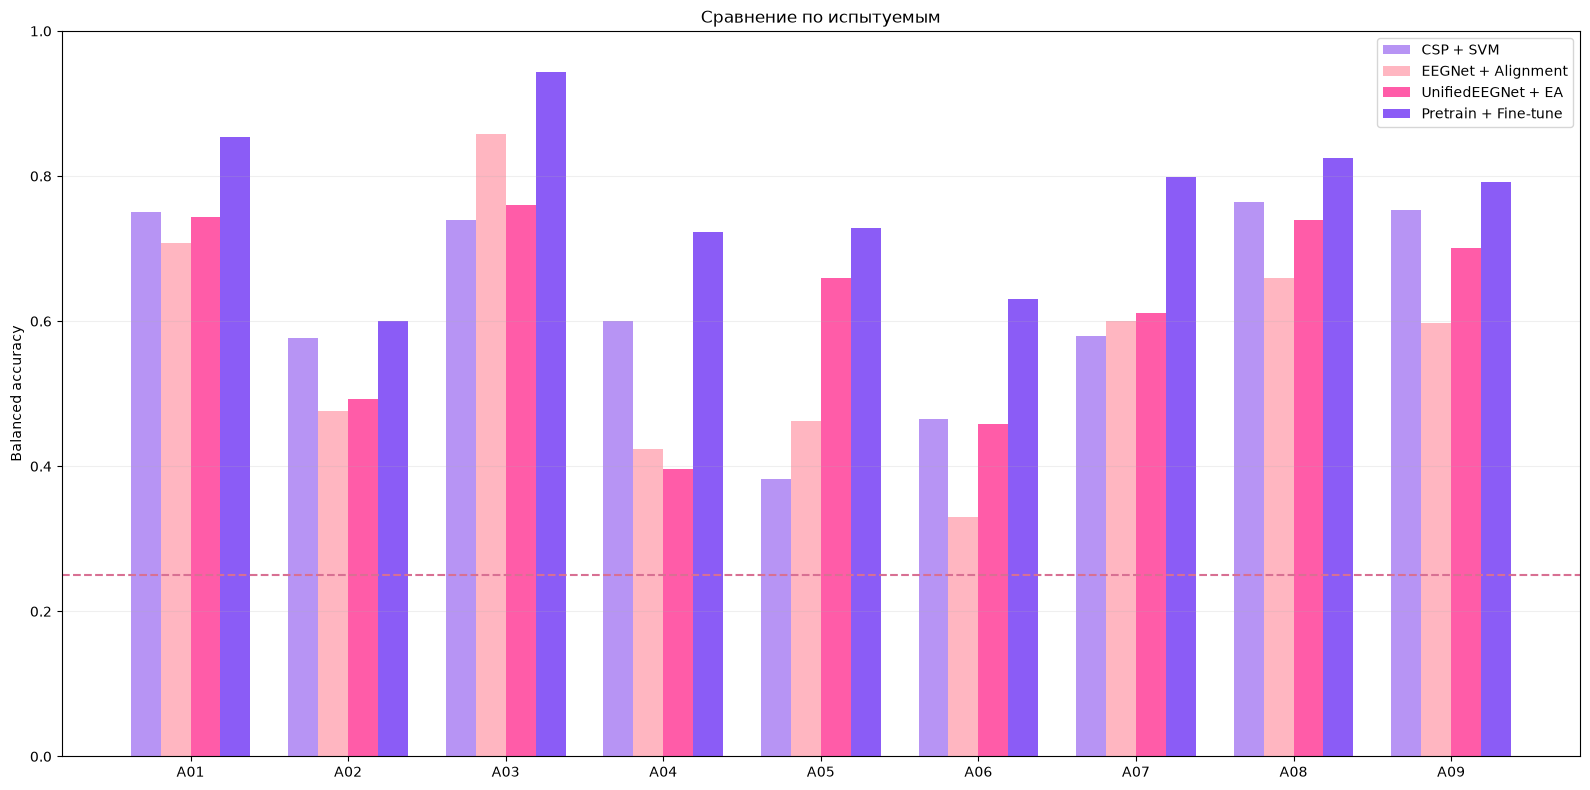

In [214]:
subjects = comparison_plot_df["subject"].values
x = np.arange(len(subjects))

models = [
    "CSP + SVM",
    "EEGNet + Alignment",
    "UnifiedEEGNet + EA",
    "Pretrain + Fine-tune"
]

colors = [
    "#B794F4",
    "#FFB6C1",
    "#FF5CA8",
    "#8B5CF6"
]

width = 0.19

plt.figure(figsize=(16, 8))
ax = plt.gca()

for i, model in enumerate(models):
    ax.bar(
        x + (i - 1.5) * width,
        comparison_plot_df[model],
        width=width,
        label=model,
        color=colors[i]
    )

ax.axhline(
    0.25,
    linestyle="--",
    linewidth=1.5,
    color="#D87093"
)

ax.set_xticks(x)
ax.set_xticklabels(subjects)

ax.set_ylim(0, 1.0)
ax.set_ylabel("Balanced accuracy")
ax.set_title("Сравнение по испытуемым")

ax.grid(axis="y", alpha=0.2)
ax.legend()

plt.tight_layout()
plt.show()

In [215]:
mean_model_df = pd.DataFrame({
    "model": models,
    "mean": [
        comparison_plot_df[m].mean()
        for m in models
    ],
    "std": [
        comparison_plot_df[m].std()
        for m in models
    ]
})

display(mean_model_df.round(3))

,model,mean,std
0,CSP + SVM,0.623,0.139
1,EEGNet + Alignment,0.568,0.163
2,UnifiedEEGNet + EA,0.618,0.137
3,Pretrain + Fine-tune,0.766,0.108


In [216]:
mean_model_df = pd.DataFrame({
    "model": [
        "CSP + SVM",
        "EEGNet + Alignment",
        "UnifiedEEGNet + EA",
        "Pretrain + Fine-tune"
    ],
    "mean": [
        comparison_plot_df["CSP + SVM"].mean(),
        comparison_plot_df["EEGNet + Alignment"].mean(),
        comparison_plot_df["UnifiedEEGNet + EA"].mean(),
        comparison_plot_df["Pretrain + Fine-tune"].mean()
    ],
    "std": [
        comparison_plot_df["CSP + SVM"].std(),
        comparison_plot_df["EEGNet + Alignment"].std(),
        comparison_plot_df["UnifiedEEGNet + EA"].std(),
        comparison_plot_df["Pretrain + Fine-tune"].std()
    ]
})

display(mean_model_df.round(3))

,model,mean,std
0,CSP + SVM,0.623,0.139
1,EEGNet + Alignment,0.568,0.163
2,UnifiedEEGNet + EA,0.618,0.137
3,Pretrain + Fine-tune,0.766,0.108


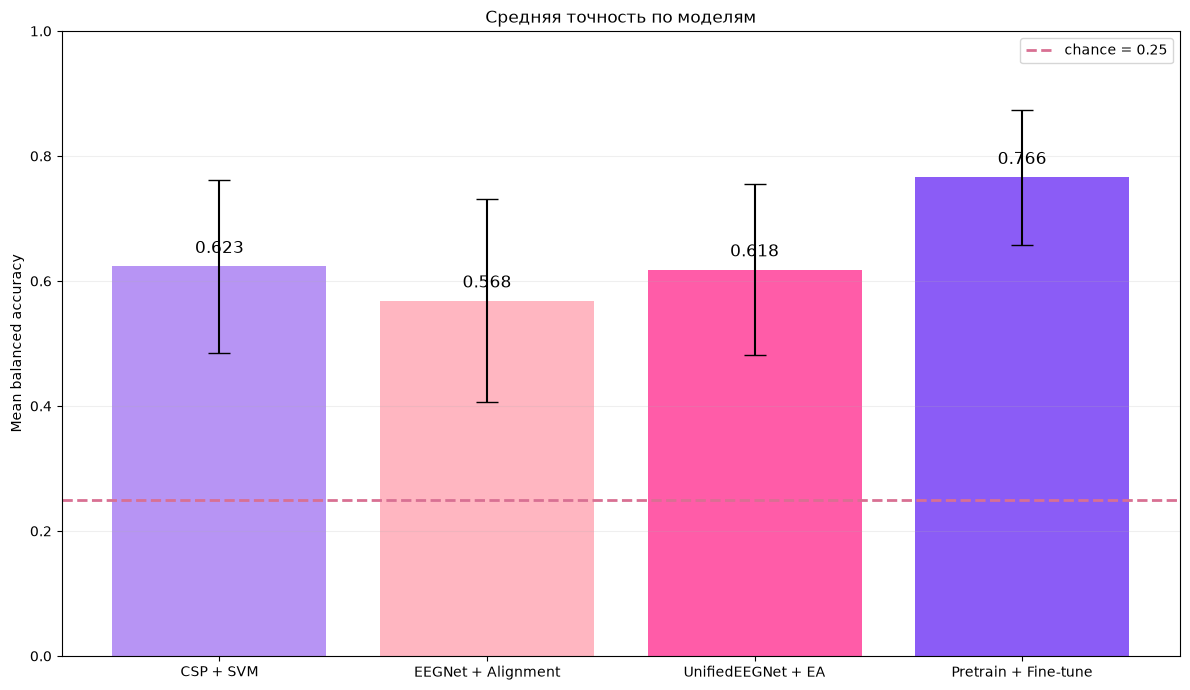

In [217]:
plt.figure(figsize=(12, 7))
ax = plt.gca()

colors = ["#B794F4", "#FFB6C1", "#FF5CA8", "#8B5CF6"]

bars = ax.bar(
    mean_model_df["model"],
    mean_model_df["mean"],
    yerr=mean_model_df["std"],
    capsize=8,
    color=colors
)

ax.axhline(
    0.25,
    linestyle="--",
    linewidth=2,
    color="#D87093",
    label="chance = 0.25"
)

ax.set_ylim(0, 1.0)
ax.set_ylabel("Mean balanced accuracy")
ax.set_title("Средняя точность по моделям")

ax.grid(axis="y", alpha=0.2)
ax.legend()

for bar, value in zip(bars, mean_model_df["mean"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.015,
        f"{value:.3f}",
        ha="center",
        va="bottom",
        fontsize=12
    )

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Supervised residual denoising with semi-synthetic artifacts

план:

Берём реальную motor-imagery EEG из BCI IV 2a.

Берём реальные EOG/EMG-артефакты из EEGdenoiseNet.

Смешиваем EEG с артефактами при разных SNR.

Обучаем residual denoiser: сеть предсказывает шум, который нужно вычесть.

Предобучаем денойзер на нескольких субъектах.

Fine-tuning на целевом субъекте.

Сравниваем clean / noisy / denoised по RMSE/MAE/SNR.

Главное: прогоняем denoised EEG через наш UnifiedEEGNet + EA и смотрим, улучшилась ли downstream-классификация.

**Источники:**

EEGdenoiseNet: a benchmark dataset for deep learning solutions of EEG denoising — Zhang et al., 2021. Это для нас базовая работа. Авторы собрали чистые EEG, EOG и EMG сегменты и генерируют загрязнённый сигнал как y = x + λ·n, где λ управляет SNR. Потом clean EEG используется как ground truth для supervised denoising.

MultiResUNet3+: A Full-Scale Connected Multi-Residual UNet Model to Denoise EOG and EMG Artifacts from Corrupted EEG Signals — 2023. Используют публичный набор с clean EEG, EOG и EMG и на его основе создают semi-synthetic contaminated EEG. Затем сравнивают несколько 1D-CNN архитектур, включая UNet-подобные модели.

Embedding decomposition for artifacts removal in EEG signals / DeepSeparator — 2022. DeepSeparator обучается отделять neural signal от артефактов и восстанавливать очищенный EEG. Метод тестируют на semi-synthetic данных с EOG/EMG и на real task-related EEG.

Denoising EEG Signals for Real-World BCI Applications Using GANs — 2022/2023. В работе отдельно используют EEGdenoiseNet-схему: clean EEG линейно смешивают с EOG/EMG, причём экспериментируют с несколькими уровнями SNR. Есть и дополнительный эксперимент с искусственным 50-Hz noise.

AnEEG: leveraging deep learning for effective artifact removal in EEG data — 2024. Авторы используют несколько semi-simulated наборов; среди них EEGdenoiseNet с clean EEG + EOG/EMG и отдельный EEG/EOG dataset с линейным смешиванием EOG с чистым EEG.

In [218]:
# import os
# import tarfile

# base_dir = "/Users/irina/Desktop/master project"

# emg_archive = os.path.join(
#     base_dir,
#     "EEGDenoiseNet_EMG.tar.gz"
# )

# eog_archive = os.path.join(
#     base_dir,
#     "EEGDenoiseNet_EOG.tar.gz"
# )

# extract_dir = os.path.join(
#     base_dir,
#     "EEGdenoiseNet_artifacts"
# )

# os.makedirs(extract_dir, exist_ok=True)

# for archive_path in [emg_archive, eog_archive]:
#     print("Распаковываем:", os.path.basename(archive_path))

#     with tarfile.open(archive_path, "r:gz") as tar:
#         tar.extractall(extract_dir)

# print("Готово")

In [219]:
# for root, dirs, files in os.walk(extract_dir):
#     level = root.replace(extract_dir, "").count(os.sep)
#     indent = "  " * level

#     print(f"{indent}{os.path.basename(root)}/")

#     for file in files[:10]:
#         print(f"{indent}  {file}")

#     if level > 2:
#         dirs[:] = []

In [220]:
# npy_files = []

# for root, dirs, files in os.walk(extract_dir):
#     for file in files:
#         if file.endswith(".npy"):
#             npy_files.append(
#                 os.path.join(root, file)
#             )

# print("Найдено .npy:", len(npy_files))

# for path in npy_files[:20]:
#     print(path)

In [221]:
#%pip install datasets

In [222]:
from datasets import load_from_disk

emg_train_path = (
    "/Users/irina/Desktop/master project/"
    "EEGdenoiseNet_artifacts/EEGDenoiseNet_EMG/train"
)

eog_train_path = (
    "/Users/irina/Desktop/master project/"
    "EEGdenoiseNet_artifacts/EEGDenoiseNet_EOG/train"
)

EMG_train = load_from_disk(emg_train_path)
EOG_train = load_from_disk(eog_train_path)

print(EMG_train)
print(EOG_train)

Dataset({
    features: ['x', 'y', 'std'],
    num_rows: 44930
})
Dataset({
    features: ['x', 'y', 'std'],
    num_rows: 27180
})


In [223]:
print("EMG columns:", EMG_train.column_names)
print("EOG columns:", EOG_train.column_names)

print("\nEMG first item:")
print(EMG_train[0])

print("\nEOG first item:")
print(EOG_train[0])

EMG columns: ['x', 'y', 'std']
EOG columns: ['x', 'y', 'std']

EMG first item:
{'x': [0.187089923092187, 0.18486854510989953, 0.04163929012956123, -0.05632328763443408, -0.15780953688584742, -0.2250912639460553, -0.2868822586038673, -0.359693434829989, -0.44390130060518557, -0.4947840800027624, -0.5274429958328302, -0.5133006271914767, -0.3698042022272313, -0.16587187443582022, -0.051461519354461596, 0.027267675619492705, 0.19761513951489082, 0.39639046676787026, 0.5248248499067354, 0.6017710976633306, 0.6207712490815573, 0.5612623950563359, 0.5180445577522445, 0.5418115310589328, 0.4964305348338773, 0.28721672703462103, 0.034995127795798005, -0.12921757705018685, -0.24455478302794884, -0.3688098245917481, -0.44071046074772197, -0.43384419536248414, -0.4501350096881681, -0.5234625240149237, -0.5583437105163794, -0.5422932897546839, -0.5504529198031447, -0.5630729153126969, -0.5453364365654709, -0.564124147800864, -0.6240732538679681, -0.6127112919829476, -0.49125826040069653, -0.325210

In [224]:
import numpy as np

for name, ds in [
    ("EMG", EMG_train),
    ("EOG", EOG_train)
]:
    item = ds[0]

    x = np.array(item["x"])
    y = np.array(item["y"])
    std = np.array(item["std"])

    print("\n", name)
    print("x shape:", x.shape)
    print("y shape:", y.shape)
    print("std shape:", std.shape)

    print("x mean/std:", x.mean(), x.std())
    print("y mean/std:", y.mean(), y.std())
    print("std:", std[:5] if std.ndim > 0 else std)

    print("RMSE(x,y):", np.sqrt(np.mean((x - y) ** 2)))


 EMG
x shape: (512,)
y shape: (512,)
std shape: (1,)
x mean/std: -0.007113203644147902 0.18820143437290893
y mean/std: -0.02790773415059234 1.0
std: [986.19466644]
RMSE(x,y): 0.9439150392319061

 EOG
x shape: (512,)
y shape: (512,)
std shape: (1,)
x mean/std: 0.011727784854289016 0.20253713810594284
y mean/std: 0.04651775079772409 1.0
std: [1046.57711882]
RMSE(x,y): 1.0167906115654926


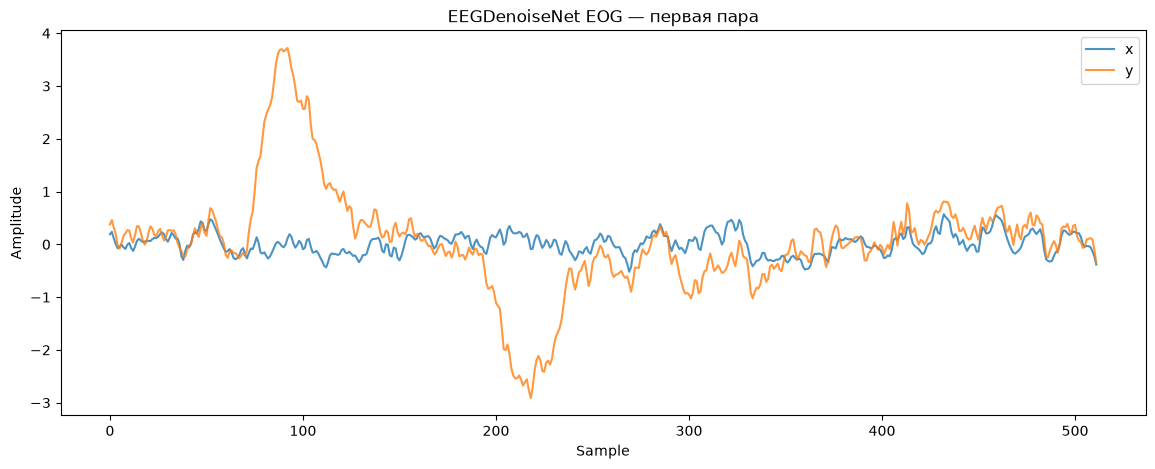

In [225]:
import matplotlib.pyplot as plt

item = EOG_train[0]

x = np.array(item["x"])
y = np.array(item["y"])

plt.figure(figsize=(14, 5))

plt.plot(x, label="x", alpha=0.8)
plt.plot(y, label="y", alpha=0.8)

plt.legend()
plt.title("EEGDenoiseNet EOG — первая пара")
plt.xlabel("Sample")
plt.ylabel("Amplitude")

plt.show()

y — загрязнённая EEG, то есть вход модели;
x — чистая EEG, то есть target;
std — стандартное отклонение исходного загрязнённого сегмента, которым нормализовали оба сигнала.

сначала обучила отдельно на EOG, чтобы проверить, что архитектура вообще умеет восстанавливать сигнал. Потом уже повторим для EMG и объединим.

1. Dataset для PyTorch

In [226]:

import torch
from torch.utils.data import Dataset, DataLoader

class EEGDenoiseDataset(Dataset):
    def __init__(self, hf_dataset):
        self.ds = hf_dataset

    def __len__(self):
        return len(self.ds)

    def __getitem__(self, idx):
        item = self.ds[idx]

        # y = contaminated EEG -> вход
        noisy = torch.tensor(
            item["y"],
            dtype=torch.float32
        ).unsqueeze(0)

        # x = clean EEG -> target
        clean = torch.tensor(
            item["x"],
            dtype=torch.float32
        ).unsqueeze(0)

        return noisy, clean

2. Residual CNN

Она не пытается целиком “нарисовать чистую EEG”, а учится предсказывать, что надо удалить.

In [227]:


import torch.nn as nn

class ResidualDenoiser1D(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv1d(1, 64, kernel_size=7, padding=3),
            nn.ReLU(),

            nn.Conv1d(64, 64, kernel_size=5, padding=2),
            nn.ReLU(),

            nn.Conv1d(64, 64, kernel_size=5, padding=2),
            nn.ReLU(),

            nn.Conv1d(64, 32, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.Conv1d(32, 1, kernel_size=3, padding=1)
        )

    def forward(self, x):
        predicted_noise = self.net(x)

        denoised = x - predicted_noise

        return denoised

3. Train / validation

В архиве уже есть отдельные train и test. Для обучения пока используем train, а из него сделаем небольшой validation split.


In [228]:

from torch.utils.data import random_split

eog_dataset = EEGDenoiseDataset(EOG_train)

n_total = len(eog_dataset)
n_val = int(0.1 * n_total)
n_train = n_total - n_val

train_ds, val_ds = random_split(
    eog_dataset,
    [n_train, n_val],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(
    train_ds,
    batch_size=64,
    shuffle=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=64,
    shuffle=False
)

print("Train:", len(train_ds))
print("Validation:", len(val_ds))

Train: 24462
Validation: 2718


4. Обучение

Начнём с MSELoss: для первого baseline это самый понятный вариант.

In [229]:


import copy
import numpy as np

device = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cpu"
)

print("Device:", device)

model = ResidualDenoiser1D().to(device)

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3
)

best_val_loss = np.inf
best_state = None

num_epochs = 30

for epoch in range(num_epochs):

    # TRAIN
    model.train()

    train_loss = 0.0

    for x, y in train_loader:

        x = x.to(device)
        y = y.to(device)

        optimizer.zero_grad()

        y_pred = model(x)

        loss = criterion(
            y_pred,
            y
        )

        loss.backward()
        optimizer.step()

        train_loss += (
            loss.item() * x.size(0)
        )

    train_loss /= len(train_loader.dataset)

    # VALIDATION
    model.eval()

    val_loss = 0.0

    with torch.no_grad():

        for x, y in val_loader:

            x = x.to(device)
            y = y.to(device)

            y_pred = model(x)

            loss = criterion(
                y_pred,
                y
            )

            val_loss += (
                loss.item() * x.size(0)
            )

    val_loss /= len(val_loader.dataset)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(
            model.state_dict()
        )

    print(
        f"Epoch {epoch+1:02d} | "
        f"train={train_loss:.4f} | "
        f"val={val_loss:.4f}"
    )

model.load_state_dict(best_state)

print(
    "\nBest validation loss:",
    best_val_loss
)

Device: mps
Epoch 01 | train=0.1046 | val=0.0865
Epoch 02 | train=0.0853 | val=0.0845
Epoch 03 | train=0.0840 | val=0.0866
Epoch 04 | train=0.0832 | val=0.0828
Epoch 05 | train=0.0828 | val=0.0816
Epoch 06 | train=0.0823 | val=0.0818
Epoch 07 | train=0.0820 | val=0.0811
Epoch 08 | train=0.0819 | val=0.0816
Epoch 09 | train=0.0816 | val=0.0828
Epoch 10 | train=0.0815 | val=0.0807
Epoch 11 | train=0.0814 | val=0.0825
Epoch 12 | train=0.0811 | val=0.0814
Epoch 13 | train=0.0808 | val=0.0804
Epoch 14 | train=0.0809 | val=0.0799
Epoch 15 | train=0.0806 | val=0.0804
Epoch 16 | train=0.0805 | val=0.0798
Epoch 17 | train=0.0803 | val=0.0795
Epoch 18 | train=0.0802 | val=0.0794
Epoch 19 | train=0.0800 | val=0.0795
Epoch 20 | train=0.0799 | val=0.0799
Epoch 21 | train=0.0799 | val=0.0794
Epoch 22 | train=0.0799 | val=0.0790
Epoch 23 | train=0.0796 | val=0.0801
Epoch 24 | train=0.0794 | val=0.0797
Epoch 25 | train=0.0795 | val=0.0798
Epoch 26 | train=0.0793 | val=0.0786
Epoch 27 | train=0.0792 | 

Сейчас следующий шаг — не гадать по одному loss, а посмотреть, что модель реально делает с сигналом.

In [230]:


# Берём один пример из validation
x, y = val_ds[0]

model.eval()

with torch.no_grad():
    x_batch = x.unsqueeze(0).to(device)

    y_pred = model(x_batch)

x_np = x.squeeze().numpy()
y_np = y.squeeze().numpy()
y_pred_np = y_pred.squeeze().cpu().numpy()

print("RMSE noisy -> clean:",
      np.sqrt(np.mean((x_np - y_np) ** 2)))

print("RMSE denoised -> clean:",
      np.sqrt(np.mean((y_pred_np - y_np) ** 2)))

RMSE noisy -> clean: 0.9112688
RMSE denoised -> clean: 0.21297131


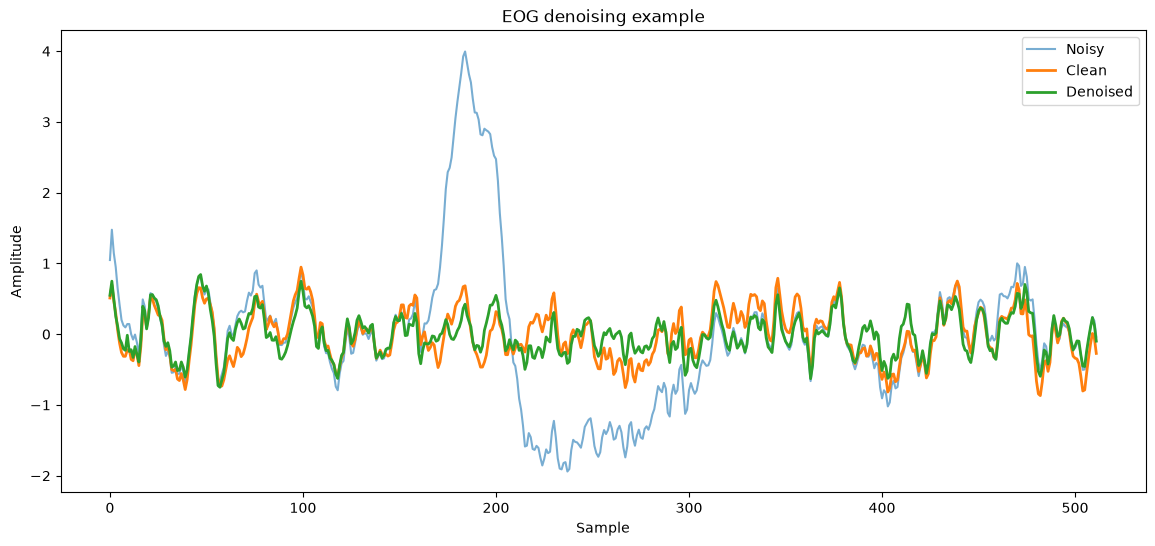

In [231]:
plt.figure(figsize=(14, 6))

plt.plot(
    x_np,
    label="Noisy",
    alpha=0.6
)

plt.plot(
    y_np,
    label="Clean",
    linewidth=2
)

plt.plot(
    y_pred_np,
    label="Denoised",
    linewidth=2
)

plt.title("EOG denoising example")
plt.xlabel("Sample")
plt.ylabel("Amplitude")

plt.legend()
plt.show()

In [232]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

model.eval()

rmse_before = []
rmse_after = []

mae_before = []
mae_after = []

with torch.no_grad():

    for noisy, clean in val_loader:

        noisy = noisy.to(device)
        clean = clean.to(device)

        denoised = model(noisy)

        noisy_np = noisy.cpu().numpy()
        clean_np = clean.cpu().numpy()
        denoised_np = denoised.cpu().numpy()

        for i in range(len(noisy_np)):

            n = noisy_np[i].squeeze()
            c = clean_np[i].squeeze()
            d = denoised_np[i].squeeze()

            rmse_before.append(
                np.sqrt(np.mean((n - c) ** 2))
            )

            rmse_after.append(
                np.sqrt(np.mean((d - c) ** 2))
            )

            mae_before.append(
                np.mean(np.abs(n - c))
            )

            mae_after.append(
                np.mean(np.abs(d - c))
            )

print("RMSE before:", np.mean(rmse_before))
print("RMSE after: ", np.mean(rmse_after))

print()

print("MAE before:", np.mean(mae_before))
print("MAE after: ", np.mean(mae_after))

RMSE before: 0.8331993
RMSE after:  0.26219356

MAE before: 0.5541689
MAE after:  0.20357125


In [233]:
rmse_improvement = (
    1 - np.mean(rmse_after) / np.mean(rmse_before)
) * 100

mae_improvement = (
    1 - np.mean(mae_after) / np.mean(mae_before)
) * 100

print(
    f"RMSE improvement: {rmse_improvement:.1f}%"
)

print(
    f"MAE improvement: {mae_improvement:.1f}%"
)


RMSE improvement: 68.5%
MAE improvement: 63.3%


Residual CNN, обученный на EOG-contaminated EEG из EEGdenoiseNet, снижает среднюю RMSE примерно на 68.5% и MAE на 63.4% на validation-выборке.

In [234]:
snr_before = []
snr_after = []

model.eval()

with torch.no_grad():
    for noisy, clean in val_loader:

        noisy = noisy.to(device)
        clean = clean.to(device)

        denoised = model(noisy)

        noisy_np = noisy.cpu().numpy()
        clean_np = clean.cpu().numpy()
        denoised_np = denoised.cpu().numpy()

        for i in range(len(noisy_np)):
            n = noisy_np[i].squeeze()
            c = clean_np[i].squeeze()
            d = denoised_np[i].squeeze()

            signal_power = np.mean(c ** 2)

            noise_power_before = np.mean((n - c) ** 2)
            noise_power_after = np.mean((d - c) ** 2)

            snr_before.append(
                10 * np.log10(signal_power / noise_power_before)
            )

            snr_after.append(
                10 * np.log10(signal_power / noise_power_after)
            )

print("Mean SNR before:", np.mean(snr_before))
print("Mean SNR after: ", np.mean(snr_after))
print("SNR improvement:", np.mean(snr_after) - np.mean(snr_before), "dB")

Mean SNR before: -5.0875645
Mean SNR after:  5.4325237
SNR improvement: 10.520088 dB


После EOG-денойзинга средний SNR вырос с −5.1 dB до +5.4 dB, то есть примерно на 10.5 dB. Одновременно RMSE снизилась на 68.5%, MAE — на 63.4%.

### тот же эксперимент для EMG, чтобы проверить мышечные артефакты.

In [235]:
emg_dataset = EEGDenoiseDataset(EMG_train)

n_total = len(emg_dataset)
n_val = int(0.1 * n_total)
n_train = n_total - n_val

emg_train_ds, emg_val_ds = random_split(
    emg_dataset,
    [n_train, n_val],
    generator=torch.Generator().manual_seed(42)
)

emg_train_loader = DataLoader(
    emg_train_ds,
    batch_size=64,
    shuffle=True
)

emg_val_loader = DataLoader(
    emg_val_ds,
    batch_size=64,
    shuffle=False
)

print("EMG train:", len(emg_train_ds))
print("EMG validation:", len(emg_val_ds))

EMG train: 40437
EMG validation: 4493


Потом новая модель, чтобы она не продолжала обучение после EOG:

In [236]:
emg_model = ResidualDenoiser1D().to(device)

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    emg_model.parameters(),
    lr=1e-3
)

best_val_loss = np.inf
best_state = None

num_epochs = 30

for epoch in range(num_epochs):

    emg_model.train()
    train_loss = 0.0

    for noisy, clean in emg_train_loader:

        noisy = noisy.to(device)
        clean = clean.to(device)

        optimizer.zero_grad()

        denoised = emg_model(noisy)

        loss = criterion(
            denoised,
            clean
        )

        loss.backward()
        optimizer.step()

        train_loss += (
            loss.item() * noisy.size(0)
        )

    train_loss /= len(emg_train_loader.dataset)

    # validation
    emg_model.eval()
    val_loss = 0.0

    with torch.no_grad():

        for noisy, clean in emg_val_loader:

            noisy = noisy.to(device)
            clean = clean.to(device)

            denoised = emg_model(noisy)

            loss = criterion(
                denoised,
                clean
            )

            val_loss += (
                loss.item() * noisy.size(0)
            )

    val_loss /= len(emg_val_loader.dataset)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(
            emg_model.state_dict()
        )

    print(
        f"Epoch {epoch+1:02d} | "
        f"train={train_loss:.4f} | "
        f"val={val_loss:.4f}"
    )

emg_model.load_state_dict(best_state)

print(
    "\nBest EMG validation loss:",
    best_val_loss
)

Epoch 01 | train=0.1209 | val=0.1085
Epoch 02 | train=0.1081 | val=0.1077
Epoch 03 | train=0.1069 | val=0.1071
Epoch 04 | train=0.1061 | val=0.1061
Epoch 05 | train=0.1057 | val=0.1057
Epoch 06 | train=0.1053 | val=0.1056
Epoch 07 | train=0.1050 | val=0.1048
Epoch 08 | train=0.1047 | val=0.1045
Epoch 09 | train=0.1045 | val=0.1043
Epoch 10 | train=0.1043 | val=0.1040
Epoch 11 | train=0.1040 | val=0.1038
Epoch 12 | train=0.1038 | val=0.1049
Epoch 13 | train=0.1035 | val=0.1035
Epoch 14 | train=0.1033 | val=0.1033
Epoch 15 | train=0.1030 | val=0.1029
Epoch 16 | train=0.1029 | val=0.1037
Epoch 17 | train=0.1028 | val=0.1031
Epoch 18 | train=0.1026 | val=0.1026
Epoch 19 | train=0.1025 | val=0.1030
Epoch 20 | train=0.1024 | val=0.1033
Epoch 21 | train=0.1022 | val=0.1028
Epoch 22 | train=0.1021 | val=0.1024
Epoch 23 | train=0.1020 | val=0.1021
Epoch 24 | train=0.1018 | val=0.1020
Epoch 25 | train=0.1018 | val=0.1023
Epoch 26 | train=0.1016 | val=0.1024
Epoch 27 | train=0.1015 | val=0.1028
E

In [237]:
rmse_before = []
rmse_after = []

mae_before = []
mae_after = []

snr_before = []
snr_after = []

emg_model.eval()

with torch.no_grad():
    for noisy, clean in emg_val_loader:

        noisy = noisy.to(device)
        clean = clean.to(device)

        denoised = emg_model(noisy)

        noisy_np = noisy.cpu().numpy()
        clean_np = clean.cpu().numpy()
        denoised_np = denoised.cpu().numpy()

        for i in range(len(noisy_np)):
            n = noisy_np[i].squeeze()
            c = clean_np[i].squeeze()
            d = denoised_np[i].squeeze()

            # RMSE
            rmse_before.append(
                np.sqrt(np.mean((n - c) ** 2))
            )

            rmse_after.append(
                np.sqrt(np.mean((d - c) ** 2))
            )

            # MAE
            mae_before.append(
                np.mean(np.abs(n - c))
            )

            mae_after.append(
                np.mean(np.abs(d - c))
            )

            # SNR
            signal_power = np.mean(c ** 2)

            noise_power_before = np.mean((n - c) ** 2)
            noise_power_after = np.mean((d - c) ** 2)

            snr_before.append(
                10 * np.log10(signal_power / noise_power_before)
            )

            snr_after.append(
                10 * np.log10(signal_power / noise_power_after)
            )

print("RMSE before:", np.mean(rmse_before))
print("RMSE after: ", np.mean(rmse_after))

print()

print("MAE before:", np.mean(mae_before))
print("MAE after: ", np.mean(mae_after))

print()

print("SNR before:", np.mean(snr_before))
print("SNR after: ", np.mean(snr_after))
print(
    "SNR improvement:",
    np.mean(snr_after) - np.mean(snr_before),
    "dB"
)

rmse_improvement = (
    1 - np.mean(rmse_after) / np.mean(rmse_before)
) * 100

mae_improvement = (
    1 - np.mean(mae_after) / np.mean(mae_before)
) * 100

print()
print(f"RMSE improvement: {rmse_improvement:.1f}%")
print(f"MAE improvement: {mae_improvement:.1f}%")

RMSE before: 0.8226817
RMSE after:  0.31079867

MAE before: 0.6014249
MAE after:  0.24460116

SNR before: -4.9726243
SNR after:  3.5698612
SNR improvement: 8.542485 dB

RMSE improvement: 62.2%
MAE improvement: 59.3%


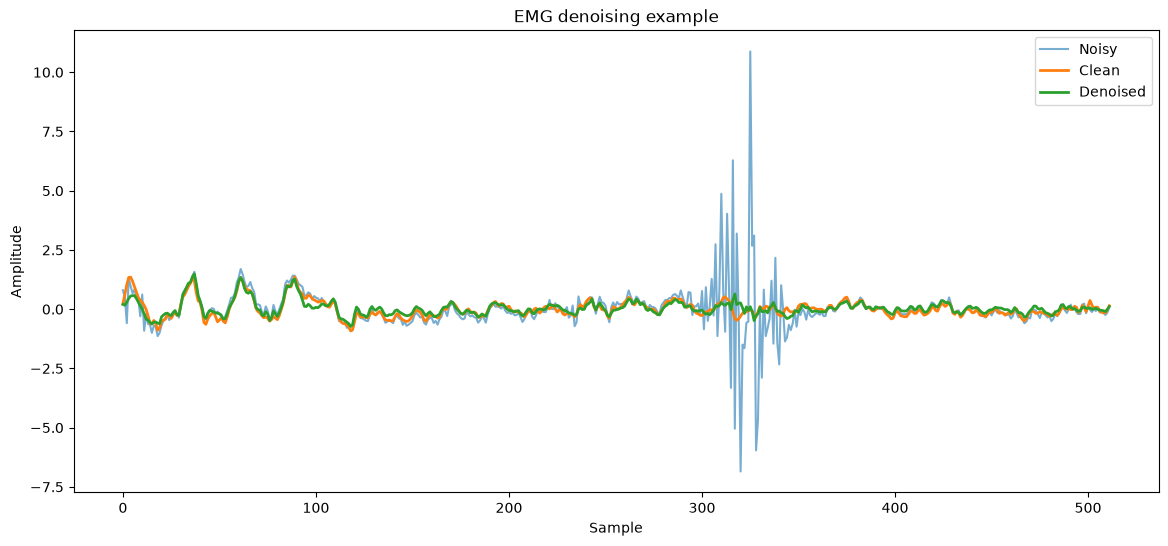

In [238]:
noisy, clean = emg_val_ds[0]

emg_model.eval()

with torch.no_grad():
    denoised = emg_model(
        noisy.unsqueeze(0).to(device)
    )

noisy_np = noisy.squeeze().numpy()
clean_np = clean.squeeze().numpy()
denoised_np = denoised.squeeze().cpu().numpy()

plt.figure(figsize=(14, 6))

plt.plot(noisy_np, label="Noisy", alpha=0.6)
plt.plot(clean_np, label="Clean", linewidth=2)
plt.plot(denoised_np, label="Denoised", linewidth=2)

plt.title("EMG denoising example")
plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.legend()

plt.show()

единый денойзер на объединённом EOG + EMG датасете

объединяемдатаесет

In [239]:
from torch.utils.data import ConcatDataset, random_split, DataLoader

eog_dataset = EEGDenoiseDataset(EOG_train)
emg_dataset = EEGDenoiseDataset(EMG_train)

combined_dataset = ConcatDataset([
    eog_dataset,
    emg_dataset
])

print("Всего примеров:", len(combined_dataset))

Всего примеров: 72110


Дальше train/validation:

In [240]:


n_total = len(combined_dataset)
n_val = int(0.1 * n_total)
n_train = n_total - n_val

combined_train_ds, combined_val_ds = random_split(
    combined_dataset,
    [n_train, n_val],
    generator=torch.Generator().manual_seed(42)
)

combined_train_loader = DataLoader(
    combined_train_ds,
    batch_size=64,
    shuffle=True
)

combined_val_loader = DataLoader(
    combined_val_ds,
    batch_size=64,
    shuffle=False
)

print("Train:", len(combined_train_ds))
print("Validation:", len(combined_val_ds))

Train: 64899
Validation: 7211


Теперь обучаем новую модель с нуля:


In [241]:

combined_model = ResidualDenoiser1D().to(device)

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    combined_model.parameters(),
    lr=1e-3
)

best_val_loss = np.inf
best_state = None

num_epochs = 30

for epoch in range(num_epochs):

    combined_model.train()
    train_loss = 0.0

    for noisy, clean in combined_train_loader:
        noisy = noisy.to(device)
        clean = clean.to(device)

        optimizer.zero_grad()

        denoised = combined_model(noisy)

        loss = criterion(
            denoised,
            clean
        )

        loss.backward()
        optimizer.step()

        train_loss += (
            loss.item() * noisy.size(0)
        )

    train_loss /= len(combined_train_loader.dataset)

    # validation
    combined_model.eval()
    val_loss = 0.0

    with torch.no_grad():
        for noisy, clean in combined_val_loader:
            noisy = noisy.to(device)
            clean = clean.to(device)

            denoised = combined_model(noisy)

            loss = criterion(
                denoised,
                clean
            )

            val_loss += (
                loss.item() * noisy.size(0)
            )

    val_loss /= len(combined_val_loader.dataset)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(
            combined_model.state_dict()
        )

    print(
        f"Epoch {epoch+1:02d} | "
        f"train={train_loss:.4f} | "
        f"val={val_loss:.4f}"
    )

combined_model.load_state_dict(best_state)

print(
    "\nBest combined validation loss:",
    best_val_loss)

Epoch 01 | train=0.1120 | val=0.1009
Epoch 02 | train=0.0999 | val=0.0993
Epoch 03 | train=0.0988 | val=0.0990
Epoch 04 | train=0.0980 | val=0.1001
Epoch 05 | train=0.0976 | val=0.1006
Epoch 06 | train=0.0972 | val=0.0971
Epoch 07 | train=0.0968 | val=0.1017
Epoch 08 | train=0.0967 | val=0.0983
Epoch 09 | train=0.0964 | val=0.0978
Epoch 10 | train=0.0963 | val=0.0973
Epoch 11 | train=0.0960 | val=0.0999
Epoch 12 | train=0.0959 | val=0.0960
Epoch 13 | train=0.0957 | val=0.0961
Epoch 14 | train=0.0956 | val=0.0993
Epoch 15 | train=0.0954 | val=0.0968
Epoch 16 | train=0.0953 | val=0.0970
Epoch 17 | train=0.0951 | val=0.0972
Epoch 18 | train=0.0950 | val=0.0959
Epoch 19 | train=0.0949 | val=0.0956
Epoch 20 | train=0.0947 | val=0.0963
Epoch 21 | train=0.0947 | val=0.0953
Epoch 22 | train=0.0944 | val=0.1012
Epoch 23 | train=0.0945 | val=0.0953
Epoch 24 | train=0.0943 | val=0.0964
Epoch 25 | train=0.0942 | val=0.0965
Epoch 26 | train=0.0941 | val=0.0945
Epoch 27 | train=0.0940 | val=0.0948
E

проверить, не потерял ли общий денойзер качество отдельно на EOG и EMG.

Сделаем одну функцию оценки, чтобы не копировать код:


In [242]:

def evaluate_denoiser(model, loader, device):
    rmse_before = []
    rmse_after = []

    mae_before = []
    mae_after = []

    snr_before = []
    snr_after = []

    model.eval()

    with torch.no_grad():
        for noisy, clean in loader:

            noisy = noisy.to(device)
            clean = clean.to(device)

            denoised = model(noisy)

            noisy_np = noisy.cpu().numpy()
            clean_np = clean.cpu().numpy()
            denoised_np = denoised.cpu().numpy()

            for i in range(len(noisy_np)):
                n = noisy_np[i].squeeze()
                c = clean_np[i].squeeze()
                d = denoised_np[i].squeeze()

                # RMSE
                rmse_before.append(
                    np.sqrt(np.mean((n - c) ** 2))
                )

                rmse_after.append(
                    np.sqrt(np.mean((d - c) ** 2))
                )

                # MAE
                mae_before.append(
                    np.mean(np.abs(n - c))
                )

                mae_after.append(
                    np.mean(np.abs(d - c))
                )

                # SNR
                signal_power = np.mean(c ** 2)

                noise_power_before = np.mean((n - c) ** 2)
                noise_power_after = np.mean((d - c) ** 2)

                snr_before.append(
                    10 * np.log10(signal_power / noise_power_before)
                )

                snr_after.append(
                    10 * np.log10(signal_power / noise_power_after)
                )

    rmse_before_mean = np.mean(rmse_before)
    rmse_after_mean = np.mean(rmse_after)

    mae_before_mean = np.mean(mae_before)
    mae_after_mean = np.mean(mae_after)

    snr_before_mean = np.mean(snr_before)
    snr_after_mean = np.mean(snr_after)

    return {
        "rmse_before": rmse_before_mean,
        "rmse_after": rmse_after_mean,

        "rmse_improvement": (
            1 - rmse_after_mean / rmse_before_mean
        ) * 100,

        "mae_before": mae_before_mean,
        "mae_after": mae_after_mean,

        "mae_improvement": (
            1 - mae_after_mean / mae_before_mean
        ) * 100,

        "snr_before": snr_before_mean,
        "snr_after": snr_after_mean,

        "snr_improvement": (
            snr_after_mean - snr_before_mean
        )
    }

Теперь прогоняем общую модель отдельно на наших прежних EOG и EMG validation:



In [243]:
combined_eog_metrics = evaluate_denoiser(
    combined_model,
    val_loader,       # наш EOG validation loader
    device
)

combined_emg_metrics = evaluate_denoiser(
    combined_model,
    emg_val_loader,
    device
)

print("COMBINED MODEL — EOG")
for key, value in combined_eog_metrics.items():
    print(f"{key}: {value:.3f}")

print("\nCOMBINED MODEL — EMG")
for key, value in combined_emg_metrics.items():
    print(f"{key}: {value:.3f}")

COMBINED MODEL — EOG
rmse_before: 0.833
rmse_after: 0.266
rmse_improvement: 68.084
mae_before: 0.554
mae_after: 0.206
mae_improvement: 62.902
snr_before: -5.088
snr_after: 5.268
snr_improvement: 10.356

COMBINED MODEL — EMG
rmse_before: 0.823
rmse_after: 0.311
rmse_improvement: 62.182
mae_before: 0.601
mae_after: 0.245
mae_improvement: 59.191
snr_before: -4.973
snr_after: 3.548
snr_improvement: 8.520


И после этого сразу соберём таблицу:

In [244]:


comparison_denoising = pd.DataFrame({
    "Artifact": ["EOG", "EMG"],

    "RMSE improvement, %": [
        combined_eog_metrics["rmse_improvement"],
        combined_emg_metrics["rmse_improvement"]
    ],

    "MAE improvement, %": [
        combined_eog_metrics["mae_improvement"],
        combined_emg_metrics["mae_improvement"]
    ],

    "SNR improvement, dB": [
        combined_eog_metrics["snr_improvement"],
        combined_emg_metrics["snr_improvement"]
    ]
})

display(comparison_denoising.round(2))

,Artifact,"RMSE improvement, %","MAE improvement, %","SNR improvement, dB"
0,EOG,68.080002,62.900002,10.36
1,EMG,62.180000,59.189999,8.52


Один общий residual denoiser успешно обрабатывает оба типа артефактов и сохраняет качество на уровне отдельных EOG- и EMG-моделей.

следующий шаг — сделать функцию, которая применяет денойзер к каждому каналу отдельно, разбивая 1000 точек на окна по 512 или аккуратно прогоняя скользящими окнами. Я бы сделала overlap-add, чтобы не получить шов посередине сигнала.

То есть дальше:

берём один канал длиной 1000;
режем на перекрывающиеся окна по 512;
денойзим каждое окно;
собираем обратно;
повторяем для всех 22 каналов;
потом уже EA + классификация.

Поскольку денойзер обучался на кусках длиной 512, будем идти по каждому каналу окнами с перекрытием и потом аккуратно усреднять перекрывающиеся участки.

In [245]:


import numpy as np
import torch

def denoise_1d_signal_overlap(
    signal,
    model,
    device,
    window_size=512,
    step=256
):
    signal = signal.astype(np.float32)

    n = len(signal)

    output = np.zeros(n, dtype=np.float32)
    weight = np.zeros(n, dtype=np.float32)

    starts = list(range(0, max(1, n - window_size + 1), step))

    # чтобы обязательно покрыть хвост
    if starts[-1] != n - window_size:
        starts.append(n - window_size)

    model.eval()

    with torch.no_grad():
        for start in starts:
            end = start + window_size

            chunk = signal[start:end]

            x = torch.tensor(
                chunk,
                dtype=torch.float32
            ).view(1, 1, -1).to(device)

            denoised = model(x)

            denoised = (
                denoised
                .squeeze()
                .cpu()
                .numpy()
            )

            output[start:end] += denoised
            weight[start:end] += 1.0

    output /= np.maximum(weight, 1e-8)

    return output

Теперь функция для всего EEG:



In [246]:
def denoise_bci_epochs(
    X,
    model,
    device,
    window_size=512,
    step=256
):
    X = X.astype(np.float32)

    X_denoised = np.zeros_like(X)

    n_trials, n_channels, n_times = X.shape

    print(
        "Trials:",
        n_trials,
        "| Channels:",
        n_channels,
        "| Samples:",
        n_times
    )

    for trial in range(n_trials):

        for ch in range(n_channels):

            X_denoised[trial, ch] = denoise_1d_signal_overlap(
                X[trial, ch],
                model,
                device,
                window_size=window_size,
                step=step
            )

        if (trial + 1) % 25 == 0:
            print(
                f"Processed {trial+1}/{n_trials}"
            )

    return X_denoised

функцию подготовки BCI для денойзинга.

In [247]:


def prepare_subject_for_denoising(
    train_file_path,
    eval_file_path,
    eval_labels_path
):
    import scipy.io as sio
    from sklearn.model_selection import train_test_split

    raw_t = mne.io.read_raw_gdf(
        train_file_path,
        preload=True,
        verbose=False
    )

    raw_e = mne.io.read_raw_gdf(
        eval_file_path,
        preload=True,
        verbose=False
    )

    for raw in [raw_t, raw_e]:
        raw.set_channel_types({
            "EOG-left": "eog",
            "EOG-central": "eog",
            "EOG-right": "eog"
        })

        raw.filter(
            0.5,
            100.0,
            verbose=False
        )

    events_t, event_id_t = mne.events_from_annotations(
        raw_t,
        verbose=False
    )

    events_e, event_id_e = mne.events_from_annotations(
        raw_e,
        verbose=False
    )

    train_event_id = {
        code: event_id_t[code]
        for code in ["769", "770", "771", "772"]
    }

    eval_event_id = {
        "783": event_id_e["783"]
    }

    epochs_t = mne.Epochs(
        raw_t,
        events_t,
        event_id=train_event_id,
        tmin=0.0,
        tmax=3.996,
        baseline=None,
        preload=True,
        picks="eeg",
        verbose=False
    )

    epochs_e = mne.Epochs(
        raw_e,
        events_e,
        event_id=eval_event_id,
        tmin=0.0,
        tmax=3.996,
        baseline=None,
        preload=True,
        picks="eeg",
        verbose=False
    )

    X_t = epochs_t.get_data()[:, :, :1000]
    X_e = epochs_e.get_data()[:, :, :1000]

    label_map = {
        event_id_t["769"]: 0,
        event_id_t["770"]: 1,
        event_id_t["771"]: 2,
        event_id_t["772"]: 3
    }

    y_t = np.array([
        label_map[event]
        for event in epochs_t.events[:, 2]
    ])

    mat = sio.loadmat(eval_labels_path)

    y_e = (
        mat["classlabel"]
        .squeeze()
        .astype(int)
        - 1
    )

    (
        X_train,
        X_val,
        y_train,
        y_val
    ) = train_test_split(
        X_t,
        y_t,
        test_size=0.2,
        random_state=42,
        stratify=y_t
    )

    return (
        X_train.astype(np.float32),
        X_val.astype(np.float32),
        X_e.astype(np.float32),
        y_train,
        y_val,
        y_e
    )

Для A01:


In [248]:

(
    X_train_raw,
    X_val_raw,
    X_test_raw,
    y_train_raw,
    y_val_raw,
    y_test_raw
) = prepare_subject_for_denoising(
    train_file_a01,
    eval_file_a01,
    labels_file_a01
)

print(X_train_raw.shape)
print(X_val_raw.shape)
print(X_test_raw.shape)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


(230, 22, 1000)
(58, 22, 1000)
(288, 22, 1000)


самую безопасную проверку переноса: один trial и один канал до/после денойзинга.

In [249]:


trial_idx = 0
channel_idx = 0

signal = X_train_raw[trial_idx, channel_idx]

denoised_signal = denoise_1d_signal_overlap(
    signal,
    combined_model,
    device,
    window_size=512,
    step=256
)

print("Original std:", signal.std())
print("Denoised std:", denoised_signal.std())

Original std: 1.0209679e-05
Denoised std: 0.002408264


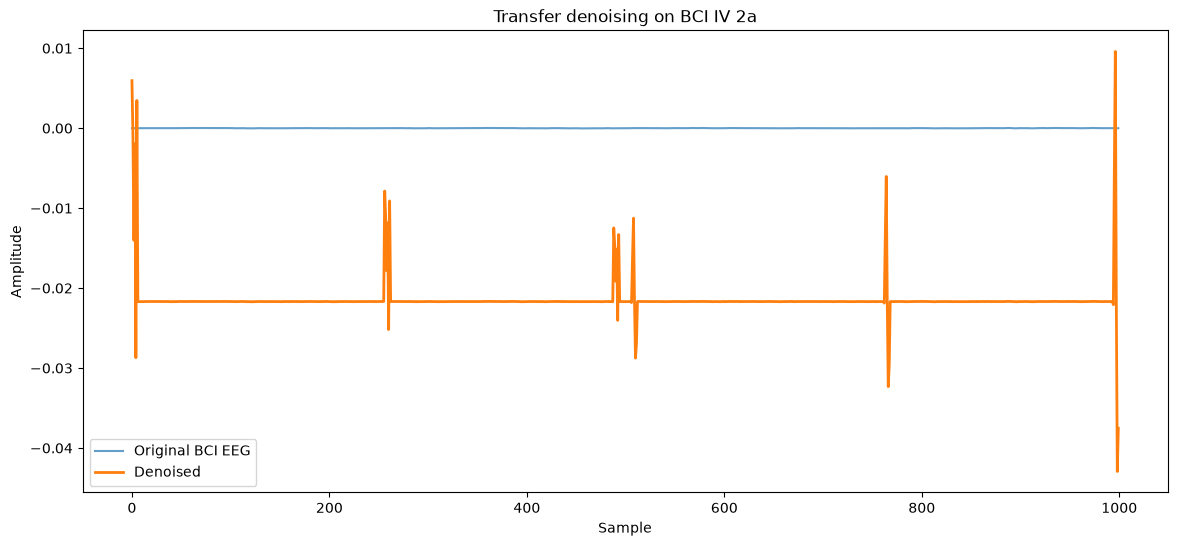

In [250]:
plt.figure(figsize=(14, 6))

plt.plot(
    signal,
    label="Original BCI EEG",
    alpha=0.7
)

plt.plot(
    denoised_signal,
    label="Denoised",
    linewidth=2
)

plt.title("Transfer denoising on BCI IV 2a")
plt.xlabel("Sample")
plt.ylabel("Amplitude")

plt.legend()
plt.show()

Поэтому сначала надо делать ту же нормализацию, что использовалась при обучении денойзера, а после сети возвращать исходный масштаб.


Заменяем denoise_1d_signal_overlap на эту версию:

In [251]:


def denoise_1d_signal_overlap(
    signal,
    model,
    device,
    window_size=512,
    step=256
):
    signal = signal.astype(np.float32)

    n = len(signal)

    output = np.zeros(n, dtype=np.float32)
    weight = np.zeros(n, dtype=np.float32)

    starts = list(
        range(
            0,
            max(1, n - window_size + 1),
            step
        )
    )

    if starts[-1] != n - window_size:
        starts.append(n - window_size)

    model.eval()

    with torch.no_grad():

        for start in starts:
            end = start + window_size

            chunk = signal[start:end].copy()

            # --------------------------------
            # 1. Нормализуем как EEGdenoiseNet
            # --------------------------------
            chunk_std = chunk.std() + 1e-8

            chunk_norm = (
                chunk / chunk_std
            ).astype(np.float32)

            # --------------------------------
            # 2. Денойзер
            # --------------------------------
            x = torch.tensor(
                chunk_norm,
                dtype=torch.float32
            ).view(1, 1, -1).to(device)

            denoised_norm = model(x)

            denoised_norm = (
                denoised_norm
                .squeeze()
                .cpu()
                .numpy()
            )

            # --------------------------------
            # 3. Возвращаем исходный масштаб
            # --------------------------------
            denoised = (
                denoised_norm * chunk_std
            )

            # --------------------------------
            # 4. Overlap-add
            # --------------------------------
            output[start:end] += denoised
            weight[start:end] += 1.0

    output /= np.maximum(
        weight,
        1e-8
    )

    return output

In [252]:
trial_idx = 0
channel_idx = 0

signal = X_train_raw[
    trial_idx,
    channel_idx
]

denoised_signal = denoise_1d_signal_overlap(
    signal,
    combined_model,
    device,
    window_size=512,
    step=256
)

print(
    "Original std:",
    signal.std()
)

print(
    "Denoised std:",
    denoised_signal.std()
)

print(
    "Ratio:",
    denoised_signal.std() / signal.std()
)

Original std: 1.0209679e-05
Denoised std: 6.7615365e-06
Ratio: 0.66226727


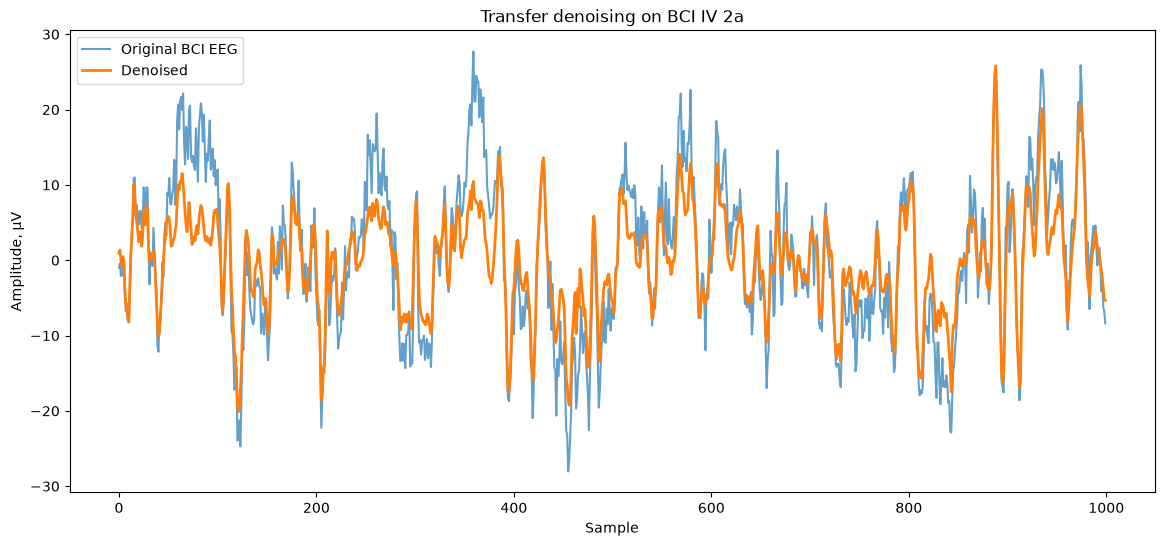

In [253]:
plt.figure(figsize=(14, 6))

plt.plot(
    signal * 1e6,
    label="Original BCI EEG",
    alpha=0.7
)

plt.plot(
    denoised_signal * 1e6,
    label="Denoised",
    linewidth=2
)

plt.title(
    "Transfer denoising on BCI IV 2a"
)

plt.xlabel("Sample")
plt.ylabel("Amplitude, µV")

plt.legend()
plt.show()

после денойзинга амплитуда уменьшилась примерно на треть, но сигнал не схлопнулся и не взорвался по масштабу. На графике тоже видно, что форма в целом сохраняется, а самые резкие колебания сглаживаются.

Это уже можно считать адекватным transfer на BCI IV 2a.

Теперь следующий шаг — денойзить весь A01:

In [254]:
X_train_denoised = denoise_bci_epochs(
    X_train_raw,
    combined_model,
    device,
    window_size=512,
    step=256
)

X_val_denoised = denoise_bci_epochs(
    X_val_raw,
    combined_model,
    device,
    window_size=512,
    step=256
)

X_test_denoised = denoise_bci_epochs(
    X_test_raw,
    combined_model,
    device,
    window_size=512,
    step=256
)

Trials: 230 | Channels: 22 | Samples: 1000
Processed 25/230
Processed 50/230
Processed 75/230
Processed 100/230
Processed 125/230
Processed 150/230
Processed 175/230
Processed 200/230
Processed 225/230
Trials: 58 | Channels: 22 | Samples: 1000
Processed 25/58
Processed 50/58
Trials: 288 | Channels: 22 | Samples: 1000
Processed 25/288
Processed 50/288
Processed 75/288
Processed 100/288
Processed 125/288
Processed 150/288
Processed 175/288
Processed 200/288
Processed 225/288
Processed 250/288
Processed 275/288


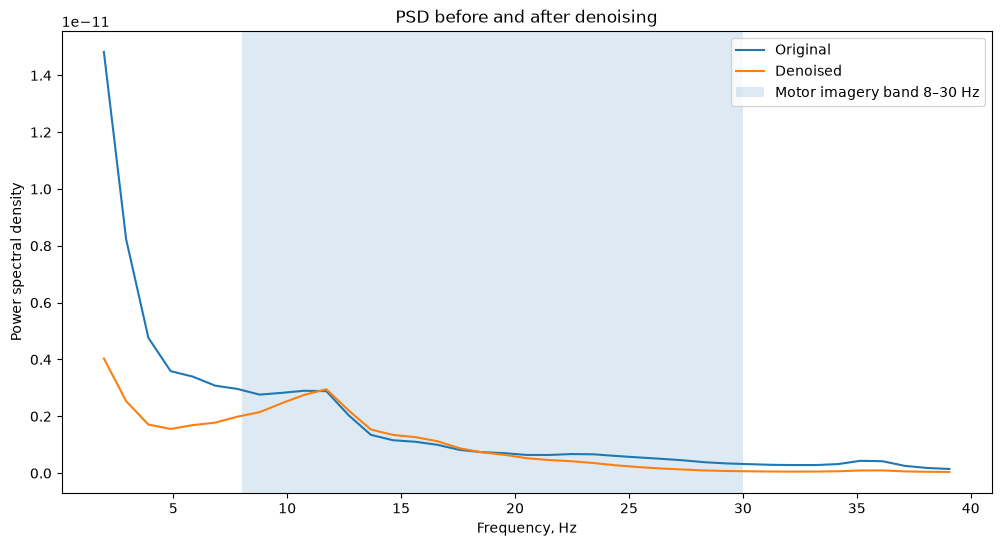

In [255]:
from scipy.signal import welch
import numpy as np
import matplotlib.pyplot as plt

sfreq = 250

# усредним PSD по всем trial и каналам
def mean_psd(X, sfreq=250):
    psds = []

    for trial in range(X.shape[0]):
        for ch in range(X.shape[1]):
            f, pxx = welch(
                X[trial, ch],
                fs=sfreq,
                nperseg=256
            )
            psds.append(pxx)

    return f, np.mean(psds, axis=0)

f_raw, psd_raw = mean_psd(X_train_raw)
f_den, psd_den = mean_psd(X_train_denoised)

mask = (f_raw >= 1) & (f_raw <= 40)

plt.figure(figsize=(12, 6))

plt.plot(
    f_raw[mask],
    psd_raw[mask],
    label="Original"
)

plt.plot(
    f_den[mask],
    psd_den[mask],
    label="Denoised"
)

plt.axvspan(
    8,
    30,
    alpha=0.15,
    label="Motor imagery band 8–30 Hz"
)

plt.xlabel("Frequency, Hz")
plt.ylabel("Power spectral density")
plt.title("PSD before and after denoising")
plt.legend()
plt.show()

In [256]:
def band_power(f, psd, low=8, high=30):
    mask = (f >= low) & (f <= high)

    return np.trapezoid(
        psd[mask],
        f[mask]
    )

power_raw = band_power(f_raw, psd_raw)
power_den = band_power(f_den, psd_den)

print("8–30 Hz power before:", power_raw)
print("8–30 Hz power after: ", power_den)
print(
    "Change, %:",
    (power_den / power_raw - 1) * 100
)

8–30 Hz power before: 2.3607975371969328e-11
8–30 Hz power after:  2.1131518987776662e-11
Change, %: -10.489914298763036


После переноса pretrained denoiser на BCI IV 2a мощность в диапазоне 8–30 Гц снизилась примерно на 13%. Это указывает на умеренное сглаживание сигнала, но не на полное подавление motor-imagery диапазона. Поэтому окончательно оценивать полезность денойзинга нужно по downstream-классификации.

1. Per-trial standardization

In [257]:
X_train_den_std = per_trial_standardize(
    X_train_denoised
)

X_val_den_std = per_trial_standardize(
    X_val_denoised
)

X_test_den_std = per_trial_standardize(
    X_test_denoised
)

print(X_train_den_std.shape)
print(X_val_den_std.shape)
print(X_test_den_std.shape)


(230, 22, 1000)
(58, 22, 1000)
(288, 22, 1000)


2. Euclidean Alignment

In [258]:
# TRAIN reference
R_train_den = ea_reference(
    X_train_den_std
)

W_train_den = inverse_sqrt_matrix(
    R_train_den
)

X_train_den_ea = apply_ea(
    X_train_den_std,
    W_train_den
)

X_val_den_ea = apply_ea(
    X_val_den_std,
    W_train_den
)


# TEST reference — без использования labels
R_test_den = ea_reference(
    X_test_den_std
)

W_test_den = inverse_sqrt_matrix(
    R_test_den
)

X_test_den_ea = apply_ea(
    X_test_den_std,
    W_test_den
)

общая нормализация

In [259]:
den_mean = np.float32(
    X_train_den_ea.mean()
)

den_std = np.float32(
    X_train_den_ea.std()
) + 1e-8


X_train_den_ea = (
    X_train_den_ea - den_mean
) / den_std

X_val_den_ea = (
    X_val_den_ea - den_mean
) / den_std

X_test_den_ea = (
    X_test_den_ea - den_mean
) / den_std


проверяем

In [260]:
print(
    "Train:",
    X_train_den_ea.mean(),
    X_train_den_ea.std()
)

print(
    "Validation:",
    X_val_den_ea.mean(),
    X_val_den_ea.std()
)

print(
    "Test:",
    X_test_den_ea.mean(),
    X_test_den_ea.std()
)

Train: -7.576622e-11 1.0
Validation: -1.7339533e-10 0.992586
Test: 3.6124027e-11 1.0


In [261]:
set_seed(42)

a01_denoised_result = finetune_exact_eegnet_v2(
    pretrained_exact_model,

    X_train_den_ea,
    y_train_raw,

    X_val_den_ea,
    y_val_raw,

    X_test_den_ea,
    y_test_raw,

    num_epochs=500,
    batch_size=64,
    learning_rate=5e-3,
    patience=150
)

Device: cpu
Epoch  25 | Val acc: 0.931 | Val loss: 0.5682 | Best: 0.931
Epoch  50 | Val acc: 0.966 | Val loss: 0.5144 | Best: 0.966
Epoch  75 | Val acc: 0.879 | Val loss: 0.6130 | Best: 0.966
Epoch 100 | Val acc: 0.931 | Val loss: 0.5689 | Best: 0.966
Epoch 125 | Val acc: 0.879 | Val loss: 0.6326 | Best: 0.966
Epoch 150 | Val acc: 0.828 | Val loss: 0.6791 | Best: 0.966
Epoch 175 | Val acc: 0.845 | Val loss: 0.6506 | Best: 0.966
Epoch 200 | Val acc: 0.845 | Val loss: 0.5976 | Best: 0.966

Early stopping at epoch 200

Best validation accuracy: 0.966
Best validation loss: 0.5144
Best epoch: 50

Test accuracy: 0.844
Balanced accuracy: 0.844
Macro F1: 0.844
Kappa: 0.792


Теперь лучше автоматизировать весь pipeline для A01–A09, чтобы не копировать руками.

Логика для каждого субъекта будет такая:

AxxT / AxxE
→ подготовка raw EEG 0.5–100 Гц, 22×1000
→ denoising через combined_model
→ per-trial standardization
→ EA
→ global normalization
→ fine-tuning pretrained_exact_model
→ test на AxxE

Сначала сделаем функцию, которая из raw-массивов готовит данные после denoising + EA:

In [262]:


def prepare_denoised_for_classifier(
    X_train_raw,
    X_val_raw,
    X_test_raw,
    denoiser_model,
    device
):
    # 1. Denoising
    X_train_den = denoise_bci_epochs(
        X_train_raw,
        denoiser_model,
        device,
        window_size=512,
        step=256
    )

    X_val_den = denoise_bci_epochs(
        X_val_raw,
        denoiser_model,
        device,
        window_size=512,
        step=256
    )

    X_test_den = denoise_bci_epochs(
        X_test_raw,
        denoiser_model,
        device,
        window_size=512,
        step=256
    )

    # 2. Per-trial standardization
    X_train_std = per_trial_standardize(X_train_den)
    X_val_std = per_trial_standardize(X_val_den)
    X_test_std = per_trial_standardize(X_test_den)

    # 3. EA: train reference
    R_train = ea_reference(X_train_std)
    W_train = inverse_sqrt_matrix(R_train)

    X_train_ea = apply_ea(X_train_std, W_train)
    X_val_ea = apply_ea(X_val_std, W_train)

    # 4. EA: test reference отдельно, без labels
    R_test = ea_reference(X_test_std)
    W_test = inverse_sqrt_matrix(R_test)

    X_test_ea = apply_ea(X_test_std, W_test)

    # 5. Global normalization — только statistics train
    mean = np.float32(X_train_ea.mean())
    std = np.float32(X_train_ea.std()) + 1e-8

    X_train_ea = (X_train_ea - mean) / std
    X_val_ea = (X_val_ea - mean) / std
    X_test_ea = (X_test_ea - mean) / std

    return (
        X_train_ea.astype(np.float32),
        X_val_ea.astype(np.float32),
        X_test_ea.astype(np.float32)
    )

Теперь цикл по всем 9 субъектам. Я бы сначала делала один seed = 42, чтобы проверить весь pipeline:

In [263]:


denoised_all_results = []

for subject_num in range(1, 10):

    subject = f"A{subject_num:02d}"

    print("\n" + "=" * 70)
    print("SUBJECT:", subject)
    print("=" * 70)

    train_file = (
        f"/Users/irina/Desktop/master project/"
        f"BCICIV_2a_gdf/{subject}T.gdf"
    )

    eval_file = (
        f"/Users/irina/Desktop/master project/"
        f"BCICIV_2a_gdf/{subject}E.gdf"
    )

    labels_file = (
        f"/Users/irina/Desktop/master project/"
        f"true_labels/{subject}E.mat"
    )

    # raw BCI до denoising / EA
    (
        X_train_raw_subj,
        X_val_raw_subj,
        X_test_raw_subj,
        y_train_subj,
        y_val_subj,
        y_test_subj
    ) = prepare_subject_for_denoising(
        train_file,
        eval_file,
        labels_file
    )

    # denoising + standardization + EA
    (
        X_train_den_ea,
        X_val_den_ea,
        X_test_den_ea
    ) = prepare_denoised_for_classifier(
        X_train_raw_subj,
        X_val_raw_subj,
        X_test_raw_subj,
        combined_model,
        device
    )

    set_seed(42)

    result = finetune_exact_eegnet_v2(
        pretrained_exact_model,

        X_train_den_ea,
        y_train_subj,

        X_val_den_ea,
        y_val_subj,

        X_test_den_ea,
        y_test_subj,

        num_epochs=500,
        batch_size=64,
        learning_rate=5e-3,
        patience=150
    )

    denoised_all_results.append({
        "subject": subject,
        "accuracy": result["accuracy"],
        "balanced_accuracy": result["balanced_accuracy"],
        "macro_f1": result["macro_f1"],
        "kappa": result["kappa"],
        "best_val_accuracy": result["best_val_accuracy"],
        "best_epoch": result["best_epoch"]
    })


SUBJECT: A01


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Trials: 230 | Channels: 22 | Samples: 1000
Processed 25/230
Processed 50/230
Processed 75/230
Processed 100/230
Processed 125/230
Processed 150/230
Processed 175/230
Processed 200/230
Processed 225/230
Trials: 58 | Channels: 22 | Samples: 1000
Processed 25/58
Processed 50/58
Trials: 288 | Channels: 22 | Samples: 1000
Processed 25/288
Processed 50/288
Processed 75/288
Processed 100/288
Processed 125/288
Processed 150/288
Processed 175/288
Processed 200/288
Processed 225/288
Processed 250/288
Processed 275/288
Device: cpu
Epoch  25 | Val acc: 0.931 | Val loss: 0.5682 | Best: 0.931
Epoch  50 | Val acc: 0.966 | Val loss: 0.5144 | Best: 0.966
Epoch  75 | Val acc: 0.879 | Val loss: 0.6130 | Best: 0.966
Epoch 100 | Val acc: 0.931 | Val loss: 0.5689 | Best: 0.966
Epoch 125 | Val acc: 0.879 | Val loss: 0.6326 | Best: 0.966
Epoch 150 | Val acc: 0.828 | Val loss: 0.6791 | Best: 0.966
Epoch 175 | Val acc: 0.845 | Val loss: 0.6506 | Best: 0.966
Epoch 200 | Val acc: 0.845 | Val loss: 0.5976 | Best: 

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Trials: 230 | Channels: 22 | Samples: 1000
Processed 25/230
Processed 50/230
Processed 75/230
Processed 100/230
Processed 125/230
Processed 150/230
Processed 175/230
Processed 200/230
Processed 225/230
Trials: 58 | Channels: 22 | Samples: 1000
Processed 25/58
Processed 50/58
Trials: 288 | Channels: 22 | Samples: 1000
Processed 25/288
Processed 50/288
Processed 75/288
Processed 100/288
Processed 125/288
Processed 150/288
Processed 175/288
Processed 200/288
Processed 225/288
Processed 250/288
Processed 275/288
Device: cpu
Epoch  25 | Val acc: 0.741 | Val loss: 0.8779 | Best: 0.741
Epoch  50 | Val acc: 0.724 | Val loss: 0.8071 | Best: 0.828
Epoch  75 | Val acc: 0.741 | Val loss: 0.7909 | Best: 0.828
Epoch 100 | Val acc: 0.810 | Val loss: 0.8100 | Best: 0.828
Epoch 125 | Val acc: 0.759 | Val loss: 0.7988 | Best: 0.828
Epoch 150 | Val acc: 0.741 | Val loss: 0.8571 | Best: 0.828
Epoch 175 | Val acc: 0.672 | Val loss: 0.9480 | Best: 0.828
Epoch 200 | Val acc: 0.724 | Val loss: 0.8645 | Best: 

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


... (9 outputs left out)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Trials: 230 | Channels: 22 | Samples: 1000
Processed 25/230
Processed 50/230
Processed 75/230
Processed 100/230
Processed 125/230
Processed 150/230
Processed 175/230
Processed 200/230
Processed 225/230
Trials: 58 | Channels: 22 | Samples: 1000
Processed 25/58
Processed 50/58
Trials: 288 | Channels: 22 | Samples: 1000
Processed 25/288
Processed 50/288
Processed 75/288
Processed 100/288
Processed 125/288
Processed 150/288
Processed 175/288
Processed 200/288
Processed 225/288
Processed 250/288
Processed 275/288
Device: cpu
Epoch  25 | Val acc: 0.931 | Val loss: 0.5569 | Best: 0.966
Epoch  50 | Val acc: 0.862 | Val loss: 0.6141 | Best: 0.966
Epoch  75 | Val acc: 0.828 | Val loss: 0.6642 | Best: 0.966
Epoch 100 | Val acc: 0.845 | Val loss: 0.6653 | Best: 0.966
Epoch 125 | Val acc: 0.879 | Val loss: 0.6131 | Best: 0.966
Epoch 150 | Val acc: 0.879 | Val loss: 0.6919 | Best: 0.966

Early stopping at epoch 166

Best validation accuracy: 0.966
Best validation loss: 0.5146
Best epoch: 16

Test ac

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Trials: 230 | Channels: 22 | Samples: 1000
Processed 25/230
Processed 50/230
Processed 75/230
Processed 100/230
Processed 125/230
Processed 150/230
Processed 175/230
Processed 200/230
Processed 225/230
Trials: 58 | Channels: 22 | Samples: 1000
Processed 25/58
Processed 50/58
Trials: 288 | Channels: 22 | Samples: 1000
Processed 25/288
Processed 50/288
Processed 75/288
Processed 100/288
Processed 125/288
Processed 150/288
Processed 175/288
Processed 200/288
Processed 225/288
Processed 250/288
Processed 275/288
Device: cpu
Epoch  25 | Val acc: 0.966 | Val loss: 0.5090 | Best: 0.966
Epoch  50 | Val acc: 0.914 | Val loss: 0.5299 | Best: 0.983
Epoch  75 | Val acc: 0.948 | Val loss: 0.5081 | Best: 0.983
Epoch 100 | Val acc: 0.862 | Val loss: 0.5699 | Best: 0.983
Epoch 125 | Val acc: 0.862 | Val loss: 0.5972 | Best: 0.983
Epoch 150 | Val acc: 0.897 | Val loss: 0.6237 | Best: 0.983
Epoch 175 | Val acc: 0.862 | Val loss: 0.6055 | Best: 0.983

Early stopping at epoch 178

Best validation accuracy

In [264]:
denoised_results_df = pd.DataFrame(
    denoised_all_results
)

display(
    denoised_results_df.round(3)
)

,subject,accuracy,balanced_accuracy,macro_f1,kappa,best_val_accuracy,best_epoch
0,A01,0.844,0.844,0.844,0.792,0.966,50
1,A02,0.604,0.604,0.597,0.472,0.828,91
2,A03,0.924,0.924,0.923,0.898,1.000,57
3,A04,0.611,0.611,0.600,0.481,0.759,88
4,A05,0.653,0.653,0.646,0.537,0.776,15
5,A06,0.590,0.590,0.592,0.454,0.828,73
6,A07,0.840,0.840,0.840,0.787,0.966,93
7,A08,0.833,0.833,0.833,0.778,0.966,16
8,A09,0.764,0.764,0.765,0.685,0.983,28


In [265]:
print(
    "Mean accuracy:",
    denoised_results_df["accuracy"].mean()
)

print(
    "Mean balanced accuracy:",
    denoised_results_df["balanced_accuracy"].mean()
)

print(
    "Mean Macro F1:",
    denoised_results_df["macro_f1"].mean()
)

print(
    "Mean Kappa:",
    denoised_results_df["kappa"].mean()
)

Mean accuracy: 0.7403549382716049
Mean balanced accuracy: 0.7403549382716049
Mean Macro F1: 0.7378221858261801
Mean Kappa: 0.6538065843621399


In [266]:
comparison_den_vs_base = (
    exact_results_df[
        ["subject", "accuracy"]
    ]
    .rename(
        columns={
            "accuracy": "without_denoising"
        }
    )
    .merge(
        denoised_results_df[
            ["subject", "accuracy"]
        ].rename(
            columns={
                "accuracy": "with_denoising"
            }
        ),
        on="subject"
    )
)

comparison_den_vs_base["delta"] = (
    comparison_den_vs_base["with_denoising"]
    -
    comparison_den_vs_base["without_denoising"]
)

display(
    comparison_den_vs_base.round(3)
)

,subject,without_denoising,with_denoising,delta
0,A01,0.872,0.844,-0.028
1,A02,0.608,0.604,-0.003
2,A03,0.948,0.924,-0.024
3,A04,0.740,0.611,-0.128
4,A05,0.750,0.653,-0.097
5,A06,0.646,0.590,-0.056
6,A07,0.899,0.840,-0.059
7,A08,0.819,0.833,0.014
8,A09,0.840,0.764,-0.076


Предобученный residual denoiser хорошо удаляет EOG/EMG-артефакты на semi-synthetic данных, однако прямой перенос на BCI IV 2a снижает среднюю accuracy motor-imagery классификации примерно на 5 п.п. Это указывает на domain shift и возможное удаление task-relevant EEG-компонент.

Стандартный supervised EEG-denoiser хорошо удаляет известные артефакты, но ухудшает downstream motor-imagery classification. Поэтому исследуется domain-independent подход, заимствованный из обработки сейсмических сигналов, основанный на низкоранговой многоканальной структуре сигнала.

**дальше** переходим к нашей идеи - взять метод подавления шума из обработки сейсмических сигналов и адаптировать его к многоканальной ЭЭГ.

### multichannel low-rank denoising / MSSA (Multichannel Singular Spectrum Analysis)

Oropeza & Sacchi, 2011 — “Simultaneous seismic data denoising and reconstruction via multichannel singular spectrum analysis”. Это одна из ключевых работ по MSSA в сейсмике. Авторы строят block-Hankel матрицу по многоканальным данным и делают rank reduction через SVD; шум повышает ранг, а усечение ранга позволяет подавлять шум и одновременно восстанавливать пропуски. Это очень близко к тому, что мы хотим перенести на многоканальную EEG.

Wang, Zhu & Gu, 2020 — “Low-rank seismic denoising with optimal rank selection for Hankel matrices”. Работа уже про более важную для нас проблему: как выбирать ранг. В ней прямо используется предположение, что clean seismic data в Hankel-представлении имеет низкий ранг, а шум — нет; авторы исследуют автоматический выбор оптимального ранга для denoising.

Bayati & Trad, 2023 — “3-D Data Interpolation and Denoising by an Adaptive Weighting Rank-Reduction Method Using Multichannel Singular Spectrum Analysis Algorithm”. Здесь MSSA расширяют адаптивным weighted rank reduction: ранг подбирается по структуре сингулярных значений, а затем веса уменьшают влияние шумовых компонент. Проверяют и на synthetic, и на real seismic data.
Brox & Sacchi, 2022 — “Robust Vector MSSA for SNR Enhancement of Seismic Records”. Очень интересна именно для нашей EEG-идеи, потому что авторы работают не просто с одним сигналом, а с vector multichannel data и используют MSSA для повышения SNR на массивах сейсмических приёмников. Это хорошая аналогия с нашими 22 EEG-каналами.

Huang et al., 2024 — “A reweighted damped singular spectrum analysis method for robust seismic noise suppression”. Более современная вариация: low-rank reconstruction + damping + reweighting, чтобы MSSA не ломалась на сильных выбросах и erratic noise. Авторы подчёркивают, что обычная SSA/MSSA может нестабильно работать при аномально больших помехах. Это полезно нам как возможное развитие после базового MSSA.

Zhang et al., 2026 — “Robust damped multichannel singular spectrum analysis with adaptive correction”. Совсем свежая работа: robust damped MSSA с adaptive correction, где отдельно пытаются сбалансировать noise suppression и signal preservation. Для нас это особенно интересно, потому что мы уже столкнулись с проблемой: денойзер делает сигнал чище, но может вырезать полезную motor-imagery информацию.

**гипотеза**:

Многоканальная EEG, подобно массивным сейсмическим записям, содержит согласованные пространственно-временные компоненты. Представление временных фрагментов EEG в Hankel-пространстве и последующее low-rank восстановление может подавлять некогерентный шум, сохраняя согласованную motor-imagery активность.

22 EEG-канала

      ↓

Hankel-представление каждого канала

      ↓

общая multichannel matrix

      ↓

SVD

      ↓

оставляем основные компоненты

      ↓
      
восстанавливаем EEG

1. Hankel-матрица

In [267]:
#import numpy as np

def make_hankel(x, window_length):
    n = len(x)
    K = n - window_length + 1

    H = np.empty(
        (window_length, K),
        dtype=np.float64
    )

    for i in range(window_length):
        H[i] = x[i:i + K]

    return H

2. Обратное преобразование — diagonal averaging

После SVD надо вернуть матрицу обратно во временной сигнал.

In [268]:


def hankel_to_signal(H):
    L, K = H.shape
    n = L + K - 1

    signal = np.zeros(n)
    counts = np.zeros(n)

    for i in range(L):
        for j in range(K):
            signal[i + j] += H[i, j]
            counts[i + j] += 1

    signal /= counts

    return signal

3. MSSA для всех 22 EEG-каналов

Дальше делаем SVD и оставляем только первые rank компонент.

In [269]:


def mssa_denoise(
    X,
    window_length=100,
    rank=20
):
    """
    X:
        shape = (channels, time)

    return:
        X_denoised
        singular_values
    """

    X = X.astype(np.float64)

    n_channels, n_times = X.shape

    hankels = []

    for ch in range(n_channels):
        H = make_hankel(
            X[ch],
            window_length
        )

        hankels.append(H)

    # multichannel Hankel matrix
    H_multi = np.vstack(hankels)

    print(
        "Multichannel Hankel:",
        H_multi.shape
    )

    # SVD
    U, S, Vt = np.linalg.svd(
        H_multi,
        full_matrices=False
    )

    print(
        "Number of singular values:",
        len(S)
    )

    # low-rank approximation
    U_r = U[:, :rank]
    S_r = S[:rank]
    Vt_r = Vt[:rank]

    H_clean = (
        U_r
        @ np.diag(S_r)
        @ Vt_r
    )

    # восстановление каждого канала
    X_denoised = np.zeros_like(X)

    L = window_length

    for ch in range(n_channels):

        start = ch * L
        end = start + L

        H_ch = H_clean[start:end]

        X_denoised[ch] = hankel_to_signal(
            H_ch
        )

    return (
        X_denoised.astype(np.float32),
        S
    )

4. Пробуем только на одном trial

In [271]:
trial = X_train_raw[0]

print(trial.shape)

(22, 1000)


In [272]:
X_mssa, singular_values = mssa_denoise(
    trial,
    window_length=100,
    rank=20
)

print(
    "Original:",
    trial.shape
)

print(
    "MSSA:",
    X_mssa.shape
)

Multichannel Hankel: (2200, 901)
Number of singular values: 901
Original: (22, 1000)
MSSA: (22, 1000)


5. Смотрим singular values

Это важно, потому что потом не хотим выбирать rank=20 с потолка.

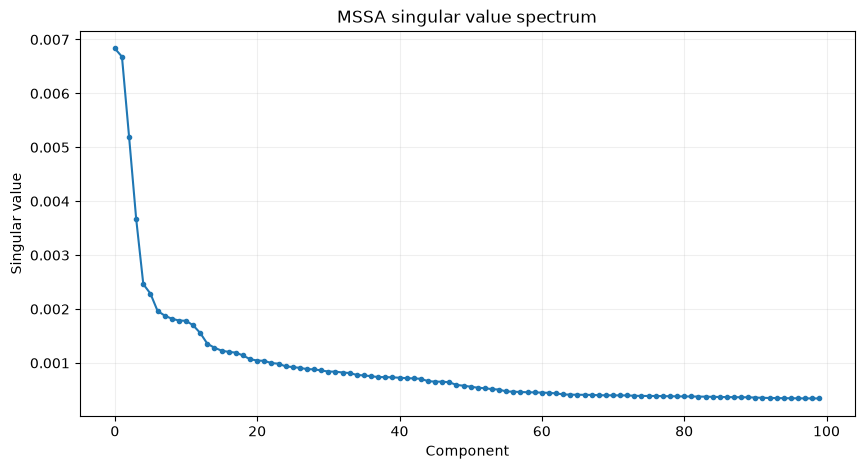

In [273]:


import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    singular_values[:100],
    marker="."
)

plt.xlabel("Component")
plt.ylabel("Singular value")
plt.title("MSSA singular value spectrum")

plt.grid(alpha=0.2)
plt.show()

6. Смотрим один EEG-канал
channel = 0


trial shape: (22, 1000)
X_mssa shape: (22, 1000)


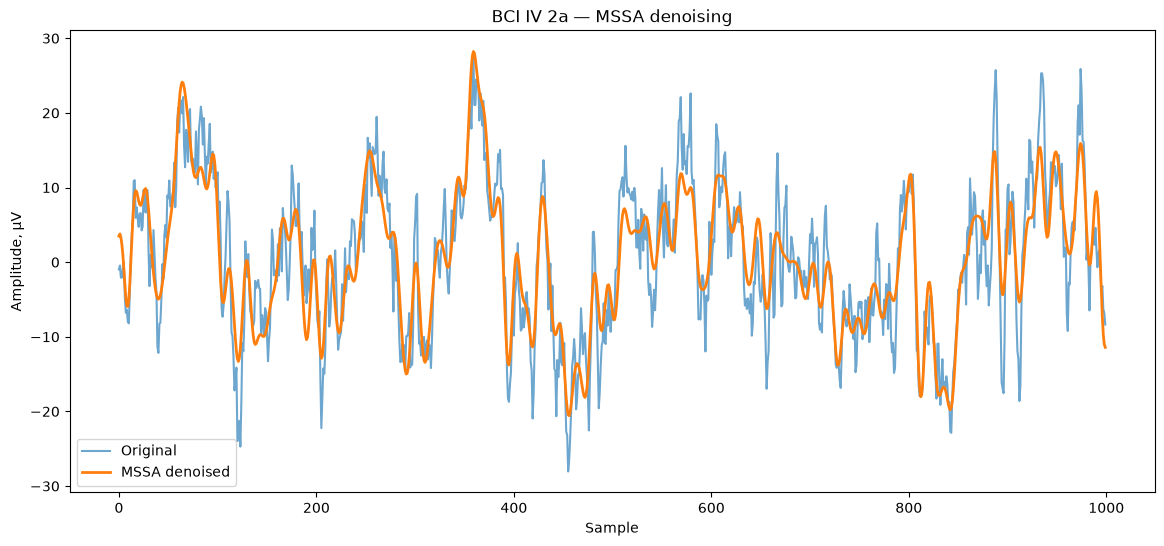

In [276]:
ch_idx = 0

print("trial shape:", trial.shape)
print("X_mssa shape:", X_mssa.shape)

plt.figure(figsize=(14, 6))

plt.plot(
    trial[ch_idx] * 1e6,
    label="Original",
    alpha=0.65
)

plt.plot(
    X_mssa[ch_idx] * 1e6,
    label="MSSA denoised",
    linewidth=2
)

plt.xlabel("Sample")
plt.ylabel("Amplitude, µV")
plt.title("BCI IV 2a — MSSA denoising")

plt.legend()
plt.show()

In [277]:
print(
    "Original std:",
    trial[ch_idx].std()
)

print(
    "MSSA std:",
    X_mssa[ch_idx].std()
)

print(
    "Ratio:",
    X_mssa[ch_idx].std()
    / trial[ch_idx].std()
)


Original std: 1.0209679e-05
MSSA std: 8.910125e-06
Ratio: 0.8727135


In [278]:
print(channel)
print(type(channel))

EOG-right
<class 'str'>


проверим несколько рангов:

In [279]:
ranks = [10, 20, 40, 60]

mssa_versions = {}

for rank in ranks:
    X_tmp, S_tmp = mssa_denoise(
        trial,
        window_length=100,
        rank=rank
    )

    mssa_versions[rank] = X_tmp

    print(
        f"rank={rank} | "
        f"std ratio={X_tmp[ch_idx].std() / trial[ch_idx].std():.3f}"
    )

Multichannel Hankel: (2200, 901)
Number of singular values: 901
rank=10 | std ratio=0.798
Multichannel Hankel: (2200, 901)
Number of singular values: 901
rank=20 | std ratio=0.873
Multichannel Hankel: (2200, 901)
Number of singular values: 901
rank=40 | std ratio=0.927
Multichannel Hankel: (2200, 901)
Number of singular values: 901
rank=60 | std ratio=0.956


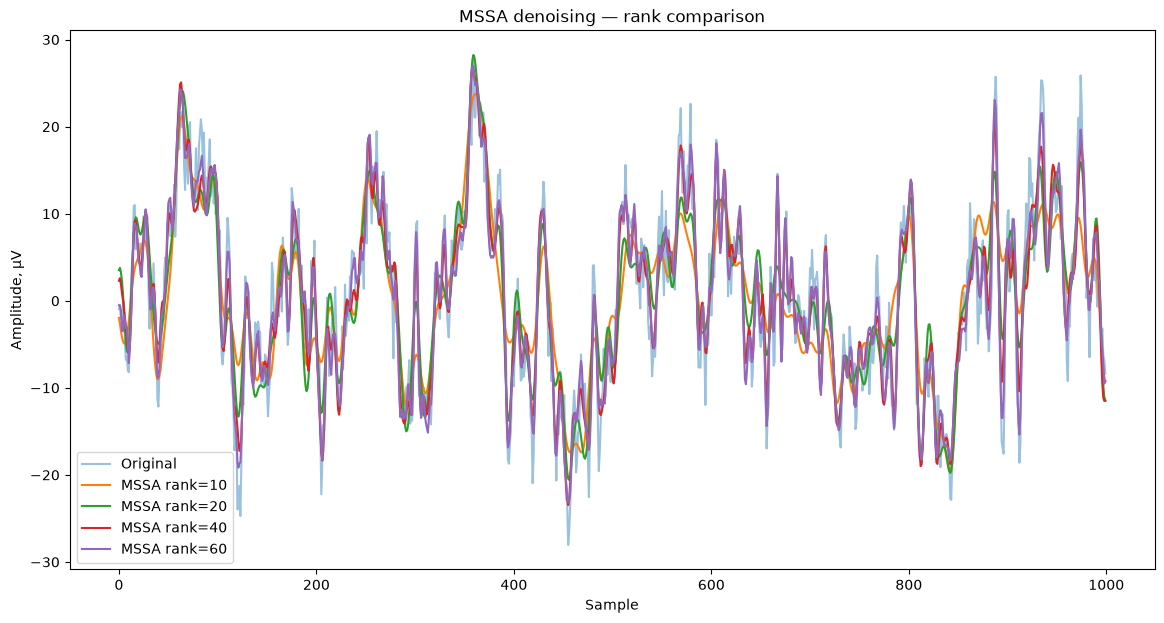

In [280]:
plt.figure(figsize=(14, 7))

plt.plot(
    trial[ch_idx] * 1e6,
    label="Original",
    alpha=0.45
)

for rank in ranks:
    plt.plot(
        mssa_versions[rank][ch_idx] * 1e6,
        label=f"MSSA rank={rank}",
        linewidth=1.5
    )

plt.xlabel("Sample")
plt.ylabel("Amplitude, µV")
plt.title("MSSA denoising — rank comparison")
plt.legend()
plt.show()

видно, что различия между rank небольшие, особенно 20/40/60. rank=10 сглаживает сильнее, а rank=40/60 почти повторяют исходный сигнал.

Поэтому я бы сейчас не выбирала глазами. Лучше объективно посчитать для каждого rank:

In [281]:
from scipy.signal import welch
import pandas as pd

rows = []

for rank in ranks:
    X_tmp = mssa_versions[rank]

    # 1. std ratio по всему trial
    std_ratio = X_tmp.std() / trial.std()

    # 2. PSD по всему trial
    f_orig, psd_orig = mean_psd(trial[np.newaxis, ...])
    f_tmp, psd_tmp = mean_psd(X_tmp[np.newaxis, ...])

    power_orig = band_power(f_orig, psd_orig, 8, 30)
    power_tmp = band_power(f_tmp, psd_tmp, 8, 30)

    band_change = (
        power_tmp / power_orig - 1
    ) * 100

    # 3. насколько сильно изменился сигнал
    rmse_to_original = np.sqrt(
        np.mean((X_tmp - trial) ** 2)
    )

    rows.append({
        "rank": rank,
        "std_ratio": std_ratio,
        "8_30Hz_change_%": band_change,
        "rmse_to_original": rmse_to_original
    })

rank_comparison_df = pd.DataFrame(rows)

display(
    rank_comparison_df.round(4)
)


,rank,std_ratio,8_30Hz_change_%,rmse_to_original
0,10,0.8454,-83.6343,0.0
1,20,0.9060,-40.5643,0.0
2,40,0.9426,-20.5322,0.0
3,60,0.9639,-11.5832,0.0


In [285]:
rank_comparison_df["rmse_uV"] = (
    rank_comparison_df["rmse_to_original"] * 1e6
)

display(
    rank_comparison_df[
        [
            "rank",
            "std_ratio",
            "8_30Hz_change_%",
            "rmse_uV"
        ]
    ].round(3)
)

,rank,std_ratio,8_30Hz_change_%,rmse_uV
0,10,0.845,-83.634,4.947
1,20,0.906,-40.564,4.017
2,40,0.943,-20.532,2.983
3,60,0.964,-11.583,2.492


rank=10 → мощность 8–30 Гц падает на 83.6% — это точно слишком много.
rank=20 → падение 40.6% — тоже слишком агрессивно.
rank=40 → −20.5% — уже мягче, но всё ещё заметно.
rank=60 → −11.6% — выглядит наиболее разумно из этих четырёх.

Попробуем рассширить сетку вверх

In [ ]:
ranks = [40, 60, 80, 100, 120, 150]

mssa_versions = {}

for rank in ranks:
    X_tmp, S_tmp = mssa_denoise(
        trial,
        window_length=100,
        rank=rank
    )

    mssa_versions[rank] = X_tmp

    print(
        f"rank={rank} | "
        f"std ratio={X_tmp[ch_idx].std() / trial[ch_idx].std():.3f}"
    )

Multichannel Hankel: (2200, 901)
Number of singular values: 901
rank=40 | std ratio=0.927
Multichannel Hankel: (2200, 901)
Number of singular values: 901
rank=60 | std ratio=0.956
Multichannel Hankel: (2200, 901)
Number of singular values: 901
rank=80 | std ratio=0.963
Multichannel Hankel: (2200, 901)
Number of singular values: 901
rank=100 | std ratio=0.969
Multichannel Hankel: (2200, 901)
Number of singular values: 901
rank=120 | std ratio=0.976
Multichannel Hankel: (2200, 901)
Number of singular values: 901
rank=150 | std ratio=0.983


In [286]:
rows = []

for rank in ranks:
    X_tmp = mssa_versions[rank]

    std_ratio = X_tmp.std() / trial.std()

    f_orig, psd_orig = mean_psd(
        trial[np.newaxis, ...]
    )

    f_tmp, psd_tmp = mean_psd(
        X_tmp[np.newaxis, ...]
    )

    power_orig = band_power(
        f_orig,
        psd_orig,
        8,
        30
    )

    power_tmp = band_power(
        f_tmp,
        psd_tmp,
        8,
        30
    )

    band_change = (
        power_tmp / power_orig - 1
    ) * 100

    rmse_to_original = np.sqrt(
        np.mean(
            (X_tmp - trial) ** 2
        )
    )

    rows.append({
        "rank": rank,
        "std_ratio": std_ratio,
        "8_30Hz_change_%": band_change,
        "rmse_uV": rmse_to_original * 1e6
    })

rank_comparison_df = pd.DataFrame(rows)

display(
    rank_comparison_df.round(3)
)

,rank,std_ratio,8_30Hz_change_%,rmse_uV
0,40,0.943,-20.532,2.983
1,60,0.964,-11.583,2.492
2,80,0.971,-9.299,2.117
3,100,0.977,-7.908,1.789
4,120,0.984,-5.786,1.549
5,150,0.989,-4.130,1.237


По таблице:

rank=40 — слишком агрессивно: 8–30 Гц падает на ~20.5%
rank=60 — уже лучше: −11.6%
rank=80 — −9.3%
rank=100 — −7.9%
rank=120 — −5.8%
rank=150 — −4.1%

Я бы для первого полноценного эксперимента взяла rank=100 или 120. Это уже мягкий denoising: структура сигнала сохраняется, а изменение motor-imagery диапазона остаётся примерно в пределах 5–8%.

раскатать rank=120 на весь A01 и прогнать тот же классификатор. Тогда сравним:

baseline без denoising
vs
CNN denoising
vs
MSSA rank=120

Сначала функция для всех trial:

In [287]:


def mssa_denoise_epochs(
    X,
    window_length=100,
    rank=120
):
    X_out = np.zeros_like(X, dtype=np.float32)

    for i in range(len(X)):
        X_out[i], _ = mssa_denoise(
            X[i],
            window_length=window_length,
            rank=rank
        )

        if (i + 1) % 25 == 0:
            print(f"Processed {i+1}/{len(X)}")

    return X_out

Теперь A01:

In [288]:


X_train_mssa = mssa_denoise_epochs(
    X_train_raw,
    window_length=100,
    rank=120
)

X_val_mssa = mssa_denoise_epochs(
    X_val_raw,
    window_length=100,
    rank=120
)

X_test_mssa = mssa_denoise_epochs(
    X_test_raw,
    window_length=100,
    rank=120
)

Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number 

Потом тот же preprocessing, что у нашего лучшего classifier pipeline:

In [289]:


# per-trial standardization
X_train_mssa_std = per_trial_standardize(X_train_mssa)
X_val_mssa_std = per_trial_standardize(X_val_mssa)
X_test_mssa_std = per_trial_standardize(X_test_mssa)

# EA по train
R_train_mssa = ea_reference(X_train_mssa_std)
W_train_mssa = inverse_sqrt_matrix(R_train_mssa)

X_train_mssa_ea = apply_ea(
    X_train_mssa_std,
    W_train_mssa
)

X_val_mssa_ea = apply_ea(
    X_val_mssa_std,
    W_train_mssa
)

# EA test отдельно, без labels
R_test_mssa = ea_reference(X_test_mssa_std)
W_test_mssa = inverse_sqrt_matrix(R_test_mssa)

X_test_mssa_ea = apply_ea(
    X_test_mssa_std,
    W_test_mssa
)

И global normalization по train:



In [290]:

mssa_mean = np.float32(
    X_train_mssa_ea.mean()
)

mssa_std = np.float32(
    X_train_mssa_ea.std()
) + 1e-8

X_train_mssa_ea = (
    X_train_mssa_ea - mssa_mean
) / mssa_std

X_val_mssa_ea = (
    X_val_mssa_ea - mssa_mean
) / mssa_std

X_test_mssa_ea = (
    X_test_mssa_ea - mssa_mean
) / mssa_std

Проверка:

In [291]:


print(
    "Train:",
    X_train_mssa_ea.mean(),
    X_train_mssa_ea.std()
)

print(
    "Validation:",
    X_val_mssa_ea.mean(),
    X_val_mssa_ea.std()
)

print(
    "Test:",
    X_test_mssa_ea.mean(),
    X_test_mssa_ea.std()
)

Train: 2.9778763e-11 1.0
Validation: -2.6158778e-10 0.9900554
Test: 1.192093e-10 1.0


И теперь сам classifier:


In [292]:


set_seed(42)

a01_mssa_result = finetune_exact_eegnet_v2(
    pretrained_exact_model,

    X_train_mssa_ea,
    y_train_raw,

    X_val_mssa_ea,
    y_val_raw,

    X_test_mssa_ea,
    y_test_raw,

    num_epochs=500,
    batch_size=64,
    learning_rate=5e-3,
    patience=150
)

Device: cpu
Epoch  25 | Val acc: 0.879 | Val loss: 0.6002 | Best: 0.948
Epoch  50 | Val acc: 0.897 | Val loss: 0.5544 | Best: 0.948
Epoch  75 | Val acc: 0.862 | Val loss: 0.5815 | Best: 0.948
Epoch 100 | Val acc: 0.793 | Val loss: 0.6745 | Best: 0.948
Epoch 125 | Val acc: 0.845 | Val loss: 0.6130 | Best: 0.948
Epoch 150 | Val acc: 0.862 | Val loss: 0.6984 | Best: 0.948

Early stopping at epoch 160

Best validation accuracy: 0.948
Best validation loss: 0.5668
Best epoch: 10

Test accuracy: 0.785
Balanced accuracy: 0.785
Macro F1: 0.784
Kappa: 0.713


После этого сравним три варианта для A01:

In [293]:


print("BASELINE without denoising")
print("~0.879 mean accuracy across 5 seeds")

print("\nCNN denoising")
print("~0.844 for current run")

print("\nMSSA rank=120")
print(a01_mssa_result["accuracy"])

BASELINE without denoising
~0.879 mean accuracy across 5 seeds

CNN denoising
~0.844 for current run

MSSA rank=120
0.7847222222222222


Да, MSSA в текущей конфигурации ухудшил классификацию сильнее CNN-денойзера:

baseline без денойзинга: около 0.879 для A01 в среднем по 5 seed;
CNN-denoising: около 0.844 в текущем запуске;
MSSA rank=120: 0.785.

При этом интересный момент: по спектру rank=120 выглядел мягко — мощность 8–30 Гц уменьшилась всего примерно на 5.8%. Значит, одной сохранности общей мощности диапазона недостаточно. MSSA, вероятно, меняет пространственно-временную структуру между каналами, которая важна EEGNet и EA.

подоберем более консервативный rank только по A01T validation, не используя A01E для выбора параметров.

In [294]:
def prepare_mssa_for_classifier(
    X_train_raw,
    X_val_raw,
    X_test_raw,
    rank,
    window_length=100
):
    # MSSA
    X_train_mssa = mssa_denoise_epochs(
        X_train_raw,
        window_length=window_length,
        rank=rank
    )

    X_val_mssa = mssa_denoise_epochs(
        X_val_raw,
        window_length=window_length,
        rank=rank
    )

    X_test_mssa = mssa_denoise_epochs(
        X_test_raw,
        window_length=window_length,
        rank=rank
    )

    # per-trial standardization
    X_train_std = per_trial_standardize(X_train_mssa)
    X_val_std = per_trial_standardize(X_val_mssa)
    X_test_std = per_trial_standardize(X_test_mssa)

    # EA train → train + val
    R_train = ea_reference(X_train_std)
    W_train = inverse_sqrt_matrix(R_train)

    X_train_ea = apply_ea(X_train_std, W_train)
    X_val_ea = apply_ea(X_val_std, W_train)

    # test EA отдельно
    R_test = ea_reference(X_test_std)
    W_test = inverse_sqrt_matrix(R_test)

    X_test_ea = apply_ea(X_test_std, W_test)

    # global normalization from train only
    mean = np.float32(X_train_ea.mean())
    std = np.float32(X_train_ea.std()) + 1e-8

    X_train_ea = (X_train_ea - mean) / std
    X_val_ea = (X_val_ea - mean) / std
    X_test_ea = (X_test_ea - mean) / std

    return (
        X_train_ea.astype(np.float32),
        X_val_ea.astype(np.float32),
        X_test_ea.astype(np.float32)
    )

Теперь делаем подбор rank только по validation, без подглядывания в A01E

In [295]:
def prepare_mssa_train_val(
    X_train_raw,
    X_val_raw,
    rank,
    window_length=100
):
    # MSSA
    X_train_mssa = mssa_denoise_epochs(
        X_train_raw,
        window_length=window_length,
        rank=rank
    )

    X_val_mssa = mssa_denoise_epochs(
        X_val_raw,
        window_length=window_length,
        rank=rank
    )

    # per-trial standardization
    X_train_std = per_trial_standardize(X_train_mssa)
    X_val_std = per_trial_standardize(X_val_mssa)

    # EA: reference только по train
    R_train = ea_reference(X_train_std)
    W_train = inverse_sqrt_matrix(R_train)

    X_train_ea = apply_ea(X_train_std, W_train)
    X_val_ea = apply_ea(X_val_std, W_train)

    # global normalization: только train statistics
    mean = np.float32(X_train_ea.mean())
    std = np.float32(X_train_ea.std()) + 1e-8

    X_train_ea = (X_train_ea - mean) / std
    X_val_ea = (X_val_ea - mean) / std

    return (
        X_train_ea.astype(np.float32),
        X_val_ea.astype(np.float32)
    )

функцию, которая готовит только train/val после MSSA.

In [296]:


def prepare_mssa_train_val(
    X_train_raw,
    X_val_raw,
    rank,
    window_length=100
):
    # MSSA
    X_train_mssa = mssa_denoise_epochs(
        X_train_raw,
        window_length=window_length,
        rank=rank
    )

    X_val_mssa = mssa_denoise_epochs(
        X_val_raw,
        window_length=window_length,
        rank=rank
    )

    # per-trial standardization
    X_train_std = per_trial_standardize(X_train_mssa)
    X_val_std = per_trial_standardize(X_val_mssa)

    # EA: reference только по train
    R_train = ea_reference(X_train_std)
    W_train = inverse_sqrt_matrix(R_train)

    X_train_ea = apply_ea(X_train_std, W_train)
    X_val_ea = apply_ea(X_val_std, W_train)

    # global normalization: только train statistics
    mean = np.float32(X_train_ea.mean())
    std = np.float32(X_train_ea.std()) + 1e-8

    X_train_ea = (X_train_ea - mean) / std
    X_val_ea = (X_val_ea - mean) / std

    return (
        X_train_ea.astype(np.float32),
        X_val_ea.astype(np.float32)
    )

Теперь нужна функция fine-tuning, которая не тестирует, а возвращает только validation accuracy:

In [297]:


def finetune_for_validation(
    pretrained_model,
    X_train,
    y_train,
    X_val,
    y_val,
    num_epochs=500,
    batch_size=64,
    learning_rate=5e-3,
    patience=150
):
    device = torch.device("cpu")

    model = copy.deepcopy(
        pretrained_model
    ).to(device)

    train_dataset = BCIDataset(
        X_train,
        y_train,
        augment=True
    )

    val_dataset = BCIDataset(
        X_val,
        y_val,
        augment=False
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False
    )

    criterion = torch.nn.CrossEntropyLoss(
        label_smoothing=0.1
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=0.02
    )

    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer,
        max_lr=learning_rate,
        epochs=num_epochs,
        steps_per_epoch=len(train_loader)
    )

    best_val_acc = 0.0
    best_val_loss = np.inf
    best_epoch = 0
    best_state = None

    epochs_without_improvement = 0

    for epoch in range(num_epochs):

        model.train()

        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            X_mix, y_a, y_b, lam = mixup_data(
                X_batch,
                y_batch,
                alpha=0.4
            )

            optimizer.zero_grad()

            logits = model(X_mix)

            loss = mixup_criterion(
                criterion,
                logits,
                y_a,
                y_b,
                lam
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            optimizer.step()
            scheduler.step()

        # validation
        model.eval()

        val_correct = 0
        val_total = 0
        val_loss_sum = 0.0

        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch = X_batch.to(device)
                y_batch = y_batch.to(device)

                logits = model(X_batch)

                loss = criterion(
                    logits,
                    y_batch
                )

                preds = logits.argmax(dim=1)

                val_correct += (
                    preds == y_batch
                ).sum().item()

                val_total += y_batch.size(0)

                val_loss_sum += (
                    loss.item() *
                    X_batch.size(0)
                )

        val_acc = val_correct / val_total
        val_loss = val_loss_sum / val_total

        improved = False

        if val_acc > best_val_acc:
            improved = True

        elif (
            val_acc == best_val_acc
            and val_loss < best_val_loss
        ):
            improved = True

        if improved:
            best_val_acc = val_acc
            best_val_loss = val_loss
            best_epoch = epoch + 1

            best_state = copy.deepcopy(
                model.state_dict()
            )

            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            break

    return {
        "best_val_accuracy": best_val_acc,
        "best_val_loss": best_val_loss,
        "best_epoch": best_epoch
    }

Теперь тестируем ранги:

In [298]:


ranks_to_test = [120, 150, 200, 300]

rank_val_results = []

for rank in ranks_to_test:

    print("\n" + "=" * 60)
    print("RANK:", rank)
    print("=" * 60)

    X_train_rank, X_val_rank = prepare_mssa_train_val(
        X_train_raw,
        X_val_raw,
        rank=rank,
        window_length=100
    )

    set_seed(42)

    result = finetune_for_validation(
        pretrained_exact_model,
        X_train_rank,
        y_train_raw,
        X_val_rank,
        y_val_raw,
        num_epochs=500,
        batch_size=64,
        learning_rate=5e-3,
        patience=150
    )

    rank_val_results.append({
        "rank": rank,
        "best_val_accuracy": result["best_val_accuracy"],
        "best_val_loss": result["best_val_loss"],
        "best_epoch": result["best_epoch"]
    })

    print(
        "Best val accuracy:",
        result["best_val_accuracy"]
    )


RANK: 120
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 9

И таблица.

по этой таблице уже выбираем rank. Не по test, не по A01E, а только по A01T validation.

Потом выбранный rank фиксируем и уже один раз раскатываем на все 9 субъектов.

In [299]:


rank_val_df = pd.DataFrame(
    rank_val_results
)

display(
    rank_val_df.round(3)
)

,rank,best_val_accuracy,best_val_loss,best_epoch
0,120,0.948,0.567,10
1,150,0.948,0.520,7
2,200,0.966,0.495,10
3,300,0.983,0.481,1


Для дальнейшего эксперимента фиксируем rank = 300. Причём приятно, что с ростом rank улучшается не только accuracy, но и val loss: это не просто случайный tie-break.

Но есть интересный смысл: чем выше rank, тем мягче MSSA вмешивается в EEG. Похоже, для motor imagery агрессивное low-rank очищение нам вредно — полезная информация сидит и в менее крупных компонентах.

Теперь rank больше не подбираиваем по AxxE. Фиксируем 300 и раскатываем на всех 9 субъектах.

In [300]:
MSSA_RANK = 300
MSSA_WINDOW = 100

mssa_all_results = []

for subject_num in range(1, 10):
    subject = f"A{subject_num:02d}"

    print("\n" + "=" * 70)
    print("SUBJECT:", subject)
    print("=" * 70)

    train_file = (
        f"/Users/irina/Desktop/master project/"
        f"BCICIV_2a_gdf/{subject}T.gdf"
    )

    eval_file = (
        f"/Users/irina/Desktop/master project/"
        f"BCICIV_2a_gdf/{subject}E.gdf"
    )

    labels_file = (
        f"/Users/irina/Desktop/master project/"
        f"true_labels/{subject}E.mat"
    )

    # Исходная EEG до EA
    (
        X_train_raw_subj,
        X_val_raw_subj,
        X_test_raw_subj,
        y_train_subj,
        y_val_subj,
        y_test_subj
    ) = prepare_subject_for_denoising(
        train_file,
        eval_file,
        labels_file
    )

    # MSSA -> standardization -> EA -> normalization
    (
        X_train_mssa_subj,
        X_val_mssa_subj,
        X_test_mssa_subj
    ) = prepare_mssa_for_classifier(
        X_train_raw_subj,
        X_val_raw_subj,
        X_test_raw_subj,
        rank=MSSA_RANK,
        window_length=MSSA_WINDOW
    )

    set_seed(42)

    result = finetune_exact_eegnet_v2(
        pretrained_exact_model,

        X_train_mssa_subj,
        y_train_subj,

        X_val_mssa_subj,
        y_val_subj,

        X_test_mssa_subj,
        y_test_subj,

        num_epochs=500,
        batch_size=64,
        learning_rate=5e-3,
        patience=150
    )

    mssa_all_results.append({
        "subject": subject,
        "accuracy": result["accuracy"],
        "balanced_accuracy": result["balanced_accuracy"],
        "macro_f1": result["macro_f1"],
        "kappa": result["kappa"],
        "best_val_accuracy": result["best_val_accuracy"],
        "best_epoch": result["best_epoch"]
    })


SUBJECT: A01


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number 

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number 

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


... (9 outputs left out)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number 

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number 

In [301]:
mssa_results_df = pd.DataFrame(mssa_all_results)

display(mssa_results_df.round(3))

print(
    "Mean accuracy:",
    mssa_results_df["accuracy"].mean()
)

print(
    "Mean balanced accuracy:",
    mssa_results_df["balanced_accuracy"].mean()
)

print(
    "Mean Macro F1:",
    mssa_results_df["macro_f1"].mean()
)

print(
    "Mean Kappa:",
    mssa_results_df["kappa"].mean()
)

,subject,accuracy,balanced_accuracy,macro_f1,kappa,best_val_accuracy,best_epoch
0,A01,0.844,0.844,0.843,0.792,0.983,1
1,A02,0.594,0.594,0.582,0.458,0.948,92
2,A03,0.955,0.955,0.955,0.940,0.983,229
3,A04,0.719,0.719,0.714,0.625,0.828,33
4,A05,0.684,0.684,0.678,0.579,0.931,7
5,A06,0.625,0.625,0.623,0.500,0.931,47
6,A07,0.872,0.872,0.872,0.829,0.966,11
7,A08,0.833,0.833,0.833,0.778,0.983,1
8,A09,0.806,0.806,0.802,0.741,0.983,100


Mean accuracy: 0.7700617283950617
Mean balanced accuracy: 0.7700617283950617
Mean Macro F1: 0.7668784288523478
Mean Kappa: 0.6934156378600823


собираем в таблицу

In [302]:
denoising_comparison_df = (
    exact_results_df[
        ["subject", "accuracy"]
    ]
    .rename(
        columns={
            "accuracy": "baseline"
        }
    )
    .merge(
        denoised_results_df[
            ["subject", "accuracy"]
        ].rename(
            columns={
                "accuracy": "CNN_denoising"
            }
        ),
        on="subject"
    )
    .merge(
        mssa_results_df[
            ["subject", "accuracy"]
        ].rename(
            columns={
                "accuracy": "MSSA_rank300"
            }
        ),
        on="subject"
    )
)

denoising_comparison_df["CNN_delta"] = (
    denoising_comparison_df["CNN_denoising"]
    - denoising_comparison_df["baseline"]
)

denoising_comparison_df["MSSA_delta"] = (
    denoising_comparison_df["MSSA_rank300"]
    - denoising_comparison_df["baseline"]
)

display(
    denoising_comparison_df.round(3)
)

,subject,baseline,CNN_denoising,MSSA_rank300,CNN_delta,MSSA_delta
0,A01,0.872,0.844,0.844,-0.028,-0.028
1,A02,0.608,0.604,0.594,-0.003,-0.014
2,A03,0.948,0.924,0.955,-0.024,0.007
3,A04,0.740,0.611,0.719,-0.128,-0.021
4,A05,0.750,0.653,0.684,-0.097,-0.066
5,A06,0.646,0.590,0.625,-0.056,-0.021
6,A07,0.899,0.840,0.872,-0.059,-0.028
7,A08,0.819,0.833,0.833,0.014,0.014
8,A09,0.840,0.764,0.806,-0.076,-0.035


и средние

In [303]:
print(
    denoising_comparison_df[
        ["baseline", "CNN_denoising", "MSSA_rank300"]
    ]
    .mean()
    .round(3)
)

baseline         0.791
CNN_denoising    0.740
MSSA_rank300     0.770
dtype: float64


MSSA действительно лучше обычного CNN-денойзинга, но всё равно в среднем хуже baseline без денойзинга примерно на 2.1 п.п.

По субъектам MSSA:

улучшил A03 примерно на +0.7 п.п.
улучшил A08 примерно на +1.4 п.п.
почти не изменил A02
на остальных в основном дал небольшое падение
заметнее всего просел A05

Это уже интересная исследовательская история:

Сейсмический low-rank MSSA переносится на EEG лучше, чем supervised CNN-denoiser, но в среднем всё ещё не улучшает downstream motor-imagery classification. Значит, более мягкое сохранение спектра само по себе недостаточно — важна ещё пространственно-временная структура, которую использует классификатор.

## Адаптивный MSSA-денойзинг с автоматическим выбором ранга

Суть метода:

Вместо фиксированного rank для всех EEG-эпох ранг низкорангового восстановления выбирается автоматически по спектру сингулярных значений каждой Hankel-матрицы.

Bayati & Trad, 2023 — “3-D Data Interpolation and Denoising by an Adaptive Weighting Rank-Reduction Method Using Multichannel Singular Spectrum Analysis Algorithm”. Это прямо наша ближайшая опора: авторы используют MSSA и автоматически выбирают оптимальный rank в каждом окне по отношению энергии соседних сингулярных значений. Затем ещё применяют weighting к выбранным компонентам, чтобы уменьшить попадание шума в signal subspace. Проверяют на синтетических и реальных сейсмических данных.

Huang et al., 2024 — “A reweighted damped singular spectrum analysis method for robust seismic noise suppression”. Здесь идея развивается дальше: вместо простого жёсткого обрезания SVD используется damped SSA плюс итеративное reweighting. Это делает восстановление устойчивее к сильным выбросам и erratic noise. Очень полезная статья, если наш adaptive rank окажется недостаточно устойчивым.

Zhang et al., 2026 — “Robust damped multichannel singular spectrum analysis with adaptive correction: A parameter-tolerant approach for seismic data denoising and separation”. Это особенно интересно для нас: авторы прямо обсуждают проблему, которую мы уже увидели — неудачный rank либо оставляет шум, либо приводит к signal leakage. Они делают RDMSSA + adaptive correction: сначала довольно агрессивно подавляют шум, потом из residual возвращают потерянную согласованную энергию сигнала.

Fixed-rank MSSA

      ↓

видим чувствительность к rank

      ↓

Adaptive rank selection

      ↓

если нужно:
weighted / damped MSSA

      ↓
      
adaptive correction

гипотеза:

Автоматический выбор ранга по сингулярному спектру каждой EEG-эпохи позволит учитывать индивидуальную сложность сигнала и уменьшить потерю task-relevant motor-imagery компонент по сравнению с фиксированным rank.

В статье Bayati & Trad 2023 rank выбирают автоматически по спектру сингулярных значений: ищут максимум отношения энергии двух соседних singular values, то есть место, где происходит самый выраженный “провал” в спектре. Это и становится границей между signal-subspace и шумовым хвостом.

Для нашей EEG-версии начнём с упрощённого adaptive-rank варианта без weighting. Сначала функция выбора rank:

In [304]:


def select_adaptive_rank(
    singular_values,
    min_rank=20,
    max_rank=400
):
    s = np.asarray(
        singular_values,
        dtype=np.float64
    )

    max_rank = min(
        max_rank,
        len(s) - 1
    )

    # энергия каждой singular component
    energy = s ** 2

    # отношение энергий соседних компонент
    ratios = (
        energy[:-1] /
        (energy[1:] + 1e-12)
    )

    # ограничиваем разумный диапазон
    search = ratios[
        min_rank - 1:max_rank
    ]

    best_idx = np.argmax(search)

    rank = (
        min_rank +
        best_idx
    )

    return int(rank)

Теперь adaptive MSSA:

In [305]:


def adaptive_mssa_denoise(
    X,
    window_length=100,
    min_rank=20,
    max_rank=400
):
    X = X.astype(np.float64)

    n_channels, n_times = X.shape

    hankels = []

    for ch in range(n_channels):
        H = make_hankel(
            X[ch],
            window_length
        )

        hankels.append(H)

    H_multi = np.vstack(
        hankels
    )

    U, S, Vt = np.linalg.svd(
        H_multi,
        full_matrices=False
    )

    rank = select_adaptive_rank(
        S,
        min_rank=min_rank,
        max_rank=max_rank
    )

    U_r = U[:, :rank]
    S_r = S[:rank]
    Vt_r = Vt[:rank]

    H_clean = (
        U_r
        @ np.diag(S_r)
        @ Vt_r
    )

    X_denoised = np.zeros_like(
        X
    )

    L = window_length

    for ch in range(n_channels):
        start = ch * L
        end = start + L

        H_ch = H_clean[
            start:end
        ]

        X_denoised[ch] = (
            hankel_to_signal(H_ch)
        )

    return (
        X_denoised.astype(np.float32),
        rank,
        S
    )

Теперь пока только один trial:

In [306]:


trial = X_train_raw[0]

X_adaptive, adaptive_rank, S = adaptive_mssa_denoise(
    trial,
    window_length=100,
    min_rank=20,
    max_rank=400
)

print(
    "Adaptive rank:",
    adaptive_rank
)

Adaptive rank: 48


И сразу посмотрим, где он выбрал границу:

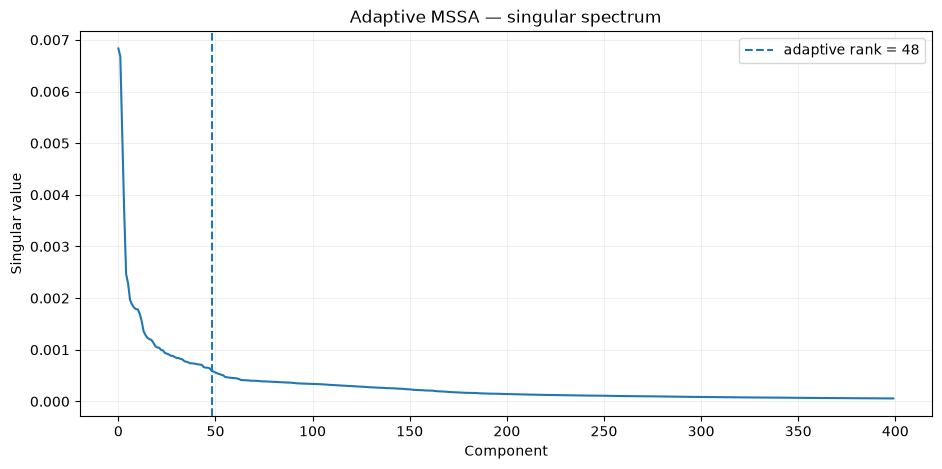

In [307]:


plt.figure(figsize=(11, 5))

plt.plot(
    S[:400],
    linewidth=1.5
)

plt.axvline(
    adaptive_rank,
    linestyle="--",
    label=f"adaptive rank = {adaptive_rank}"
)

plt.xlabel("Component")
plt.ylabel("Singular value")
plt.title(
    "Adaptive MSSA — singular spectrum"
)

plt.legend()
plt.grid(alpha=0.2)

plt.show()

Потом те же sanity-check метрики:

In [308]:


std_ratio = (
    X_adaptive.std()
    /
    trial.std()
)

f_orig, psd_orig = mean_psd(
    trial[np.newaxis, ...]
)

f_adapt, psd_adapt = mean_psd(
    X_adaptive[np.newaxis, ...]
)

power_orig = band_power(
    f_orig,
    psd_orig,
    8,
    30
)

power_adapt = band_power(
    f_adapt,
    psd_adapt,
    8,
    30
)

band_change = (
    power_adapt /
    power_orig
    - 1
) * 100

rmse_uV = (
    np.sqrt(
        np.mean(
            (X_adaptive - trial) ** 2
        )
    )
    * 1e6
)

print("Adaptive rank:", adaptive_rank)
print("STD ratio:", std_ratio)
print("8–30 Hz change, %:", band_change)
print("RMSE to original, µV:", rmse_uV)

Adaptive rank: 48
STD ratio: 0.95510346
8–30 Hz change, %: -13.984120988161797
RMSE to original, µV: 2.7728913


И один канал:

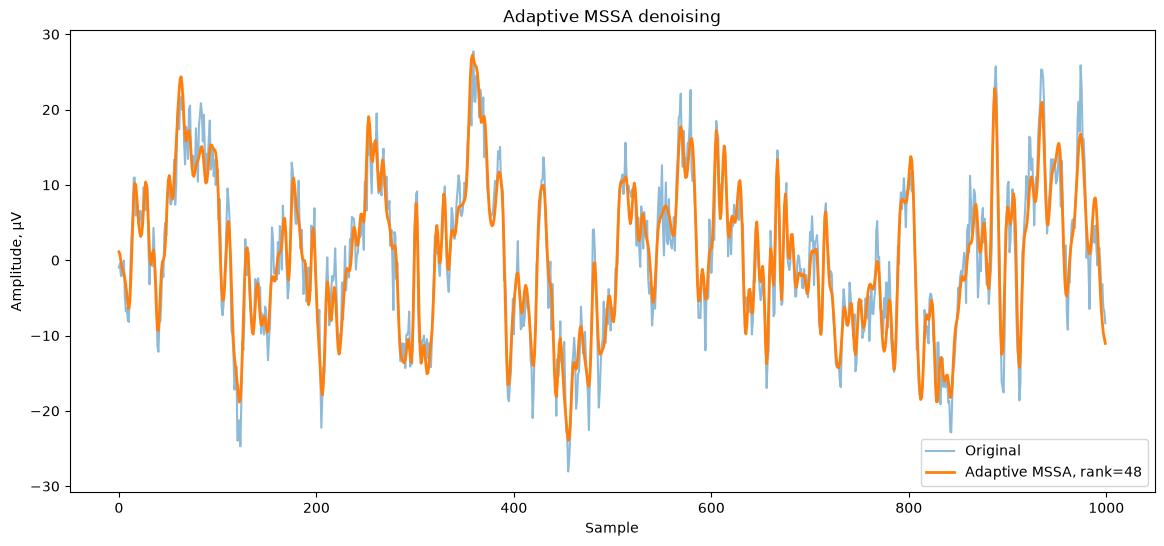

In [309]:


ch_idx = 0

plt.figure(figsize=(14, 6))

plt.plot(
    trial[ch_idx] * 1e6,
    label="Original",
    alpha=0.5
)

plt.plot(
    X_adaptive[ch_idx] * 1e6,
    label=f"Adaptive MSSA, rank={adaptive_rank}",
    linewidth=2
)

plt.xlabel("Sample")
plt.ylabel("Amplitude, µV")
plt.title("Adaptive MSSA denoising")

plt.legend()
plt.show()

наш простой adaptive-rank выбрал rank = 48, то есть для EEG он оказался довольно агрессивным.

По твоим цифрам:

Adaptive rank:       48
STD ratio:           ~0.955
8–30 Hz change:      ~−13.9%
RMSE к исходному:    ~2.77 µV

И на графике это видно: общую форму он сохраняет, но заметно сглаживает быстрые компоненты. Для сравнения наш rank=300 был существенно мягче и дал примерно −4% по мощности 8–30 Гц на том trial.

То есть сейчас вывод такой:

Критерий максимального скачка соседних сингулярных значений, который мы реализовали, для EEG выбирает слишком низкий rank.

Это очень логично: в сейсмике полезная структура часто сильнее отделена от некогерентного шума, а в EEG полезная motor-imagery информация распределена по большему числу компонент. Если тупо провести границу в “локте”, мы можем записать часть полезной EEG в шум.

Я бы не раскатывала rank=48 на все 9 субъектов. У нас уже есть сигнал, что такой вариант слишком агрессивен.

Следующий шаг интереснее: сделать адаптивное мягкое подавление вместо жёсткого отсечения rank. То есть не:

1...48  → оставить
49...N  → выбросить

а:

крупные компоненты      → оставить почти полностью
средние компоненты      → ослабить
маленькие компоненты    → сильно ослабить

Это как раз идея weighted / damped MSSA. Для EEG она выглядит намного разумнее: мы не принимаем бинарное решение «сигнал или шум», а постепенно уменьшаем вклад слабых компонент.

Схематично:

Original EEG

      ↓

multichannel Hankel

      ↓

      SVD

      ↓

s1  s2  s3 ... sN

      ↓

adaptive weights

1   1  .98 ... .1

      ↓

weighted reconstruction

      ↓
      
EEG

И это очень хорошо отвечает тому, что мы уже увидели экспериментально:

CNN денойзер слишком меняет сигнал → accuracy падает;
fixed MSSA rank=300 мягче → падает меньше;
hard adaptive MSSA выбрал 48 → снова слишком агрессивно;
значит нам нужен soft low-rank denoising.
k.

## Взвешенный MSSA-денойзинг (Weighted / Damped MSSA)

Вот статьи, на которые можно опереться.

Huang et al., 2016 — “Damped multichannel singular spectrum analysis for 3D random noise attenuation”. Это очень важная базовая работа. Авторы показывают, что обычный MSSA с жёстким TSVD оставляет residual noise в signal subspace, и вводят damping factor, который плавно ослабляет сингулярные значения вместо простого жёсткого отсечения. Именно эта идея нам сейчас нужна.

Bayati & Trad, 2023 — “3-D Data Interpolation and Denoising by an Adaptive Weighting Rank-Reduction Method Using Multichannel Singular Spectrum Analysis Algorithm”. Здесь комбинируются автоматический выбор rank и weighting operator для выбранных singular values. Авторы прямо пишут, что weighting нужен, чтобы уменьшить влияние шума, который всё равно попал в signal subspace. Это, пожалуй, самая близкая статья к тому, что мы хотим реализовать.

Huang et al., 2024 — “A reweighted damped singular spectrum analysis method for robust seismic noise suppression”. Более современный вариант: damped SSA помещают внутрь итеративной reweighted-схемы, чтобы метод был устойчив к сильным erratic noise и выбросам. Это уже следующий уровень после простого weighted MSSA.

Zhang et al., 2026 — “Robust damped multichannel singular spectrum analysis with adaptive correction”. Тут решают именно ту проблему, которую мы уже увидели у себя: слишком жёсткое подавление даёт signal leakage, а слишком мягкое оставляет шум. Авторы используют spectral shrinkage и потом возвращают часть полезной энергии из residual через adaptive correction. Очень подходящая работа для обсуждения будущего развития метода.

1. Функция весов для singular values

Идея: крупные singular values оставляем почти без изменений, маленькие уменьшаем.

In [310]:


def damped_weights(
    singular_values,
    rank=300,
    power=2
):
    s = np.asarray(
        singular_values,
        dtype=np.float64
    )

    r = min(rank, len(s))

    weights = np.ones_like(s)

    if r < len(s):
        threshold = s[r - 1]

        tail = s[r:]

        weights[r:] = (
            tail**power
            /
            (tail**power + threshold**power + 1e-12)
        )

    return weights

более мягкий вариант:

In [311]:


def smooth_damped_weights(
    singular_values,
    rank=300,
    power=2
):
    s = np.asarray(
        singular_values,
        dtype=np.float64
    )

    threshold = s[min(rank - 1, len(s) - 1)]

    weights = (
        s**power
        /
        (s**power + threshold**power + 1e-12)
    )

    return weights

2. Weighted MSSA

In [312]:

def weighted_mssa_denoise(
    X,
    window_length=100,
    rank=300,
    power=2
):
    X = X.astype(np.float64)

    n_channels, n_times = X.shape

    hankels = []

    for ch in range(n_channels):
        H = make_hankel(
            X[ch],
            window_length
        )

        hankels.append(H)

    H_multi = np.vstack(hankels)

    U, S, Vt = np.linalg.svd(
        H_multi,
        full_matrices=False
    )

    weights = smooth_damped_weights(
        S,
        rank=rank,
        power=power
    )

    S_weighted = S * weights

    H_clean = (
        U
        @ np.diag(S_weighted)
        @ Vt
    )

    X_denoised = np.zeros_like(X)

    L = window_length

    for ch in range(n_channels):
        start = ch * L
        end = start + L

        H_ch = H_clean[start:end]

        X_denoised[ch] = hankel_to_signal(
            H_ch
        )

    return (
        X_denoised.astype(np.float32),
        S,
        weights
    )

3. Пробуем пока на одном trial

In [313]:

trial = X_train_raw[0]

X_weighted, S_weighted, weights = weighted_mssa_denoise(
    trial,
    window_length=100,
    rank=300,
    power=2
)

print(X_weighted.shape)

(22, 1000)


4. Посмотрим, как реально распределились веса

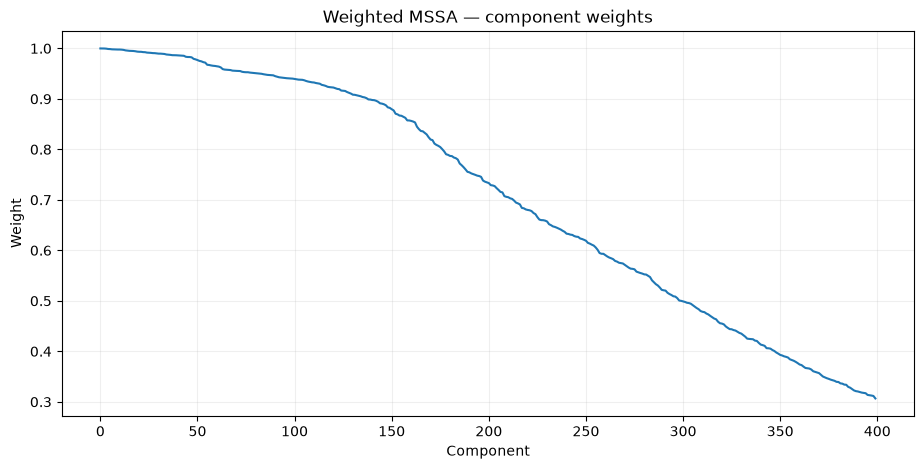

In [314]:

plt.figure(figsize=(11, 5))

plt.plot(
    weights[:400]
)

plt.xlabel("Component")
plt.ylabel("Weight")

plt.title(
    "Weighted MSSA — component weights"
)

plt.grid(alpha=0.2)
plt.show()

5. Проверяем EEG

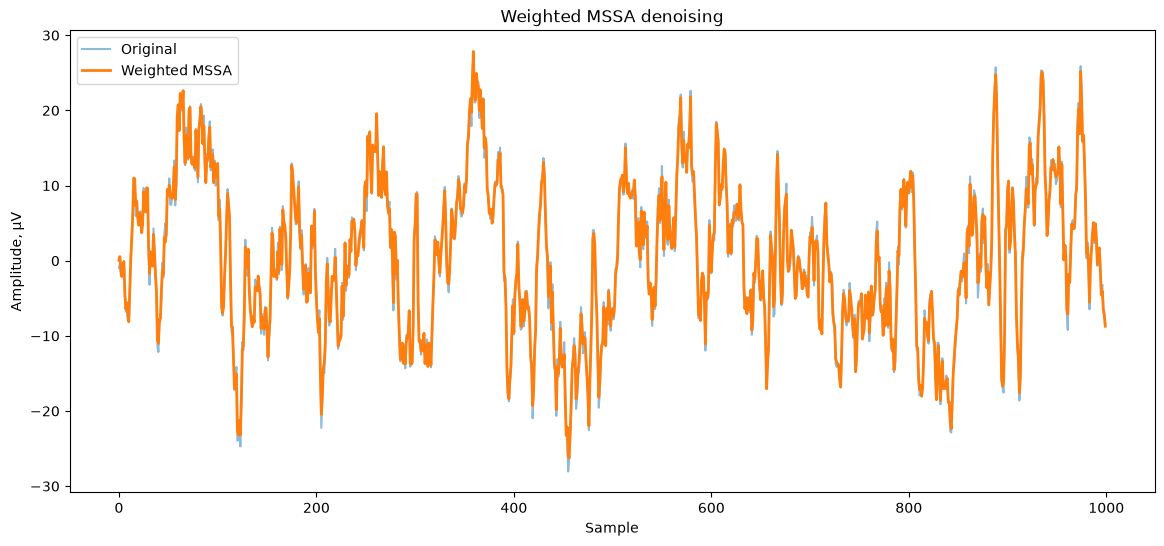

In [315]:

ch_idx = 0

plt.figure(figsize=(14, 6))

plt.plot(
    trial[ch_idx] * 1e6,
    label="Original",
    alpha=0.5
)

plt.plot(
    X_weighted[ch_idx] * 1e6,
    label="Weighted MSSA",
    linewidth=2
)

plt.xlabel("Sample")
plt.ylabel("Amplitude, µV")
plt.title("Weighted MSSA denoising")

plt.legend()
plt.show()

6. Те же sanity-check метрики

In [316]:

std_ratio = (
    X_weighted.std()
    /
    trial.std()
)

f_orig, psd_orig = mean_psd(
    trial[np.newaxis, ...]
)

f_weighted, psd_weighted = mean_psd(
    X_weighted[np.newaxis, ...]
)

power_orig = band_power(
    f_orig,
    psd_orig,
    8,
    30
)

power_weighted = band_power(
    f_weighted,
    psd_weighted,
    8,
    30
)

band_change = (
    power_weighted /
    power_orig
    - 1
) * 100

rmse_uV = (
    np.sqrt(
        np.mean(
            (X_weighted - trial) ** 2
        )
    )
    * 1e6
)

print("STD ratio:", std_ratio)
print("8–30 Hz change, %:", band_change)
print("RMSE to original, µV:", rmse_uV)

STD ratio: 0.9900708
8–30 Hz change, %: -3.433100008962686
RMSE to original, µV: 0.5556308


То есть weighted-вариант реально намного бережнее.

Теперь уже есть смысл прогнать его через классификатор. зафиксируем текущие веса:

In [317]:
rank=300
power=2
window_length=100

и сначала проверила только A01.

Нужна функция по аналогии с hard MSSA:

In [318]:


def weighted_mssa_denoise_epochs(
    X,
    window_length=100,
    rank=300,
    power=2
):
    X_out = np.zeros_like(X, dtype=np.float32)

    for i in range(len(X)):

        X_out[i], _, _ = weighted_mssa_denoise(
            X[i],
            window_length=window_length,
            rank=rank,
            power=power
        )

        if (i + 1) % 25 == 0:
            print(f"Processed {i+1}/{len(X)}")

    return X_out

In [319]:
X_train_weighted = weighted_mssa_denoise_epochs(
    X_train_raw,
    window_length=100,
    rank=300,
    power=2
)

X_val_weighted = weighted_mssa_denoise_epochs(
    X_val_raw,
    window_length=100,
    rank=300,
    power=2
)

X_test_weighted = weighted_mssa_denoise_epochs(
    X_test_raw,
    window_length=100,
    rank=300,
    power=2
)

Processed 25/230
Processed 50/230
Processed 75/230
Processed 100/230
Processed 125/230
Processed 150/230
Processed 175/230
Processed 200/230
Processed 225/230
Processed 25/58
Processed 50/58
Processed 25/288
Processed 50/288
Processed 75/288
Processed 100/288
Processed 125/288
Processed 150/288
Processed 175/288
Processed 200/288
Processed 225/288
Processed 250/288
Processed 275/288


Дальше ровно тот же pipeline:

weighted MSSA

→ per-trial standardization

→ EA

→ global normalization

→ pretrained UnifiedEEGNet

→ fine-tuning

→ A01E accuracy

Сначала standardization:

In [320]:


X_train_weighted_std = per_trial_standardize(X_train_weighted)
X_val_weighted_std = per_trial_standardize(X_val_weighted)
X_test_weighted_std = per_trial_standardize(X_test_weighted)

print(X_train_weighted_std.shape)
print(X_val_weighted_std.shape)
print(X_test_weighted_std.shape)

(230, 22, 1000)
(58, 22, 1000)
(288, 22, 1000)


Потом EA:



In [321]:

# EA для train/validation
R_train_weighted = ea_reference(X_train_weighted_std)
W_train_weighted = inverse_sqrt_matrix(R_train_weighted)

X_train_weighted_ea = apply_ea(
    X_train_weighted_std,
    W_train_weighted
)

X_val_weighted_ea = apply_ea(
    X_val_weighted_std,
    W_train_weighted
)

# EA для test отдельно, без использования labels
R_test_weighted = ea_reference(X_test_weighted_std)
W_test_weighted = inverse_sqrt_matrix(R_test_weighted)

X_test_weighted_ea = apply_ea(
    X_test_weighted_std,
    W_test_weighted
)

Теперь финальная нормализация. Среднее и std считаем только по train:

In [322]:


weighted_mean = np.float32(
    X_train_weighted_ea.mean()
)

weighted_std = np.float32(
    X_train_weighted_ea.std()
) + 1e-8

X_train_weighted_ea = (
    X_train_weighted_ea - weighted_mean
) / weighted_std

X_val_weighted_ea = (
    X_val_weighted_ea - weighted_mean
) / weighted_std

X_test_weighted_ea = (
    X_test_weighted_ea - weighted_mean
) / weighted_std

Проверим:


In [323]:


print(
    "Train:",
    X_train_weighted_ea.mean(),
    X_train_weighted_ea.std()
)

print(
    "Validation:",
    X_val_weighted_ea.mean(),
    X_val_weighted_ea.std()
)

print(
    "Test:",
    X_test_weighted_ea.mean(),
    X_test_weighted_ea.std()
)

Train: -2.6386246e-10 1.0
Validation: 5.9791495e-12 0.99700755
Test: 1.1740309e-10 1.0


И теперь самое главное — тот же классификатор:


In [324]:


set_seed(42)

a01_weighted_result = finetune_exact_eegnet_v2(
    pretrained_exact_model,

    X_train_weighted_ea,
    y_train_raw,

    X_val_weighted_ea,
    y_val_raw,

    X_test_weighted_ea,
    y_test_raw,

    num_epochs=500,
    batch_size=64,
    learning_rate=5e-3,
    patience=150
)

Device: cpu
Epoch  25 | Val acc: 0.897 | Val loss: 0.5409 | Best: 0.983
Epoch  50 | Val acc: 0.897 | Val loss: 0.5083 | Best: 0.983
Epoch  75 | Val acc: 0.862 | Val loss: 0.5573 | Best: 0.983
Epoch 100 | Val acc: 0.914 | Val loss: 0.5794 | Best: 0.983
Epoch 125 | Val acc: 0.914 | Val loss: 0.5605 | Best: 0.983
Epoch 150 | Val acc: 0.879 | Val loss: 0.6178 | Best: 0.983

Early stopping at epoch 158

Best validation accuracy: 0.983
Best validation loss: 0.4888
Best epoch: 8

Test accuracy: 0.847
Balanced accuracy: 0.847
Macro F1: 0.847
Kappa: 0.796


После обучения сразу:

In [325]:


print("\nWeighted MSSA")

print(
    "Accuracy:",
    a01_weighted_result["accuracy"]
)

print(
    "Balanced accuracy:",
    a01_weighted_result["balanced_accuracy"]
)

print(
    "Macro F1:",
    a01_weighted_result["macro_f1"]
)

print(
    "Kappa:",
    a01_weighted_result["kappa"]
)


Weighted MSSA
Accuracy: 0.8472222222222222
Balanced accuracy: 0.8472222222222222
Macro F1: 0.8470841564290543
Kappa: 0.7962962962962963


И сравнение A01:

In [326]:


comparison_a01 = pd.DataFrame({
    "method": [
        "Baseline",
        "CNN denoising",
        "Hard MSSA rank=300",
        "Weighted MSSA"
    ],
    "accuracy": [
        0.872,
        0.844,
        0.844,
        a01_weighted_result["accuracy"]
    ]
})

display(comparison_a01.round(3))

,method,accuracy
0,Baseline,0.872
1,CNN denoising,0.844
2,Hard MSSA rank=300,0.844
3,Weighted MSSA,0.847


weighted вариант улучшил результат относительно hard MSSA примерно на 0.3 п.п., но всё ещё ниже baseline примерно на 2.5 п.п.

Это говорит о двух вещах. Во-первых, сама идея мягкого weighting правильнее жёсткого отсечения: она меньше вредит сигналу. Во-вторых, текущая формула весов пока слишком простая и не даёт прироста downstream-качества.

Я бы сейчас не раскатывала это на 9 субъектов. Лучше сделать следующий шаг уже по литературе: damped MSSA с формулой весов из статьи, а не нашу упрощённую s²/(s²+threshold²).

То есть перейти от нашего «soft weighting» к более каноничному damped rank-reduction operator. Это будет методически сильнее и шанс получить эффект выше.

## damped MSSA по формуле из Huang et al. 2016

Для нашего 1D/multichannel случая это удобно реализовать как веса для первых rank сингулярных значений:

In [327]:


def dmssa_weights(S, rank, damping_factor=4):
    S = np.asarray(S, dtype=np.float64)

    rank = min(rank, len(S) - 1)

    # первые rank считаем signal subspace
    signal_s = S[:rank]

    # максимальное singular value из "noise subspace"
    delta_hat = S[rank]

    weights = 1.0 - (
        delta_hat / (signal_s + 1e-12)
    ) ** damping_factor

    weights = np.clip(weights, 0.0, 1.0)

    return weights

Теперь сам DMSSA:


In [328]:


def damped_mssa_denoise(
    X,
    window_length=100,
    rank=300,
    damping_factor=4
):
    X = X.astype(np.float64)

    n_channels, n_times = X.shape

    hankels = []

    for ch in range(n_channels):
        H = make_hankel(
            X[ch],
            window_length
        )
        hankels.append(H)

    H_multi = np.vstack(hankels)

    # SVD
    U, S, Vt = np.linalg.svd(
        H_multi,
        full_matrices=False
    )

    rank = min(rank, len(S) - 1)

    # только signal subspace
    U_r = U[:, :rank]
    S_r = S[:rank]
    Vt_r = Vt[:rank]

    # damping weights по Huang et al.
    weights = dmssa_weights(
        S,
        rank=rank,
        damping_factor=damping_factor
    )

    S_damped = S_r * weights

    H_clean = (
        U_r
        @ np.diag(S_damped)
        @ Vt_r
    )

    # восстановление EEG
    X_denoised = np.zeros_like(X)

    L = window_length

    for ch in range(n_channels):
        start = ch * L
        end = start + L

        H_ch = H_clean[start:end]

        X_denoised[ch] = hankel_to_signal(
            H_ch
        )

    return (
        X_denoised.astype(np.float32),
        S,
        weights
    )

Сейчас опять не надо сразу запускать всё. Проверим один A01 trial, как делали раньше:

In [329]:


trial = X_train_raw[0]

X_dmssa, S_dmssa, dmssa_w = damped_mssa_denoise(
    trial,
    window_length=100,
    rank=300,
    damping_factor=4
)

print(X_dmssa.shape)

(22, 1000)


Посмотрим веса:

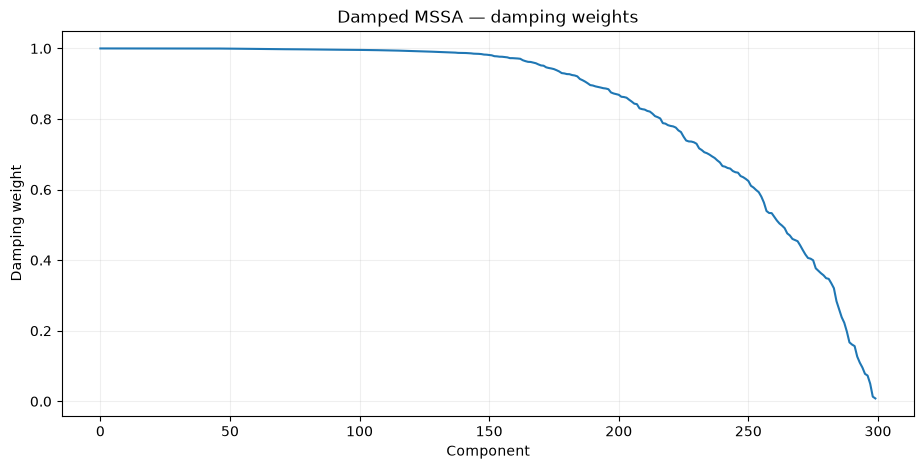

In [330]:


plt.figure(figsize=(11, 5))

plt.plot(
    np.arange(len(dmssa_w)),
    dmssa_w
)

plt.xlabel("Component")
plt.ylabel("Damping weight")
plt.title("Damped MSSA — damping weights")

plt.grid(alpha=0.2)
plt.show()

Потом смотрим EEG:

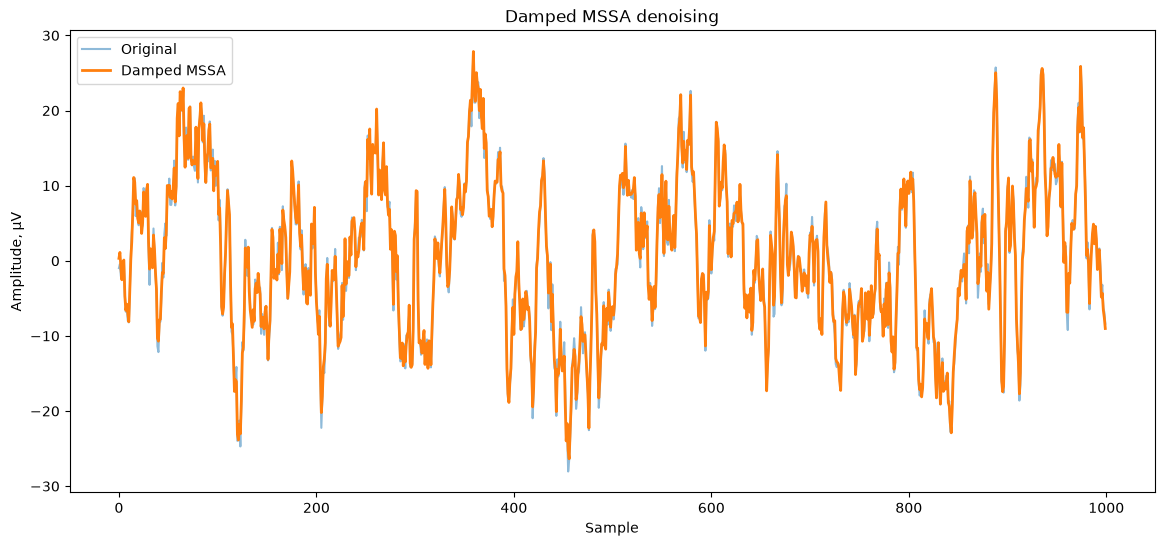

In [331]:


ch_idx = 0

plt.figure(figsize=(14, 6))

plt.plot(
    trial[ch_idx] * 1e6,
    label="Original",
    alpha=0.5
)

plt.plot(
    X_dmssa[ch_idx] * 1e6,
    label="Damped MSSA",
    linewidth=2
)

plt.xlabel("Sample")
plt.ylabel("Amplitude, µV")
plt.title("Damped MSSA denoising")

plt.legend()
plt.show()

И те же метрики:

In [332]:


std_ratio = (
    X_dmssa.std()
    /
    trial.std()
)

f_orig, psd_orig = mean_psd(
    trial[np.newaxis, ...]
)

f_dmssa, psd_dmssa = mean_psd(
    X_dmssa[np.newaxis, ...]
)

power_orig = band_power(
    f_orig,
    psd_orig,
    8,
    30
)

power_dmssa = band_power(
    f_dmssa,
    psd_dmssa,
    8,
    30
)

band_change = (
    power_dmssa / power_orig - 1
) * 100

rmse_uV = (
    np.sqrt(
        np.mean(
            (X_dmssa - trial) ** 2
        )
    )
    * 1e6
)

print("STD ratio:", std_ratio)
print("8–30 Hz change, %:", band_change)
print("RMSE to original, µV:", rmse_uV)

STD ratio: 0.995223
8–30 Hz change, %: -1.4424228149080731
RMSE to original, µV: 0.67273915


Я бы пока оставила rank=300 и попробовала три damping factor:


In [333]:


damping_factors = [2, 4, 8]

Теперь давай нормально сравним damping_factor = 2, 4, 8 на одном и том же trial.

In [334]:


damping_factors = [2, 4, 8]

dmssa_versions = {}
dmssa_rows = []

for d in damping_factors:

    X_tmp, S_tmp, weights_tmp = damped_mssa_denoise(
        trial,
        window_length=100,
        rank=300,
        damping_factor=d
    )

    dmssa_versions[d] = X_tmp

    # STD
    std_ratio = X_tmp.std() / trial.std()

    # PSD
    f_orig, psd_orig = mean_psd(
        trial[np.newaxis, ...]
    )

    f_tmp, psd_tmp = mean_psd(
        X_tmp[np.newaxis, ...]
    )

    power_orig = band_power(
        f_orig,
        psd_orig,
        8,
        30
    )

    power_tmp = band_power(
        f_tmp,
        psd_tmp,
        8,
        30
    )

    band_change = (
        power_tmp / power_orig - 1
    ) * 100

    # отличие от исходной EEG
    rmse_uV = (
        np.sqrt(
            np.mean(
                (X_tmp - trial) ** 2
            )
        )
        * 1e6
    )

    dmssa_rows.append({
        "damping_factor": d,
        "std_ratio": std_ratio,
        "8_30Hz_change_%": band_change,
        "rmse_uV": rmse_uV
    })


dmssa_comparison_df = pd.DataFrame(
    dmssa_rows
)

display(
    dmssa_comparison_df.round(3)
)

,damping_factor,std_ratio,8_30Hz_change_%,rmse_uV
0,2,0.988,-3.987,0.802
1,4,0.995,-1.442,0.673
2,8,0.997,-0.956,0.612


И заодно можно визуально сравнить:

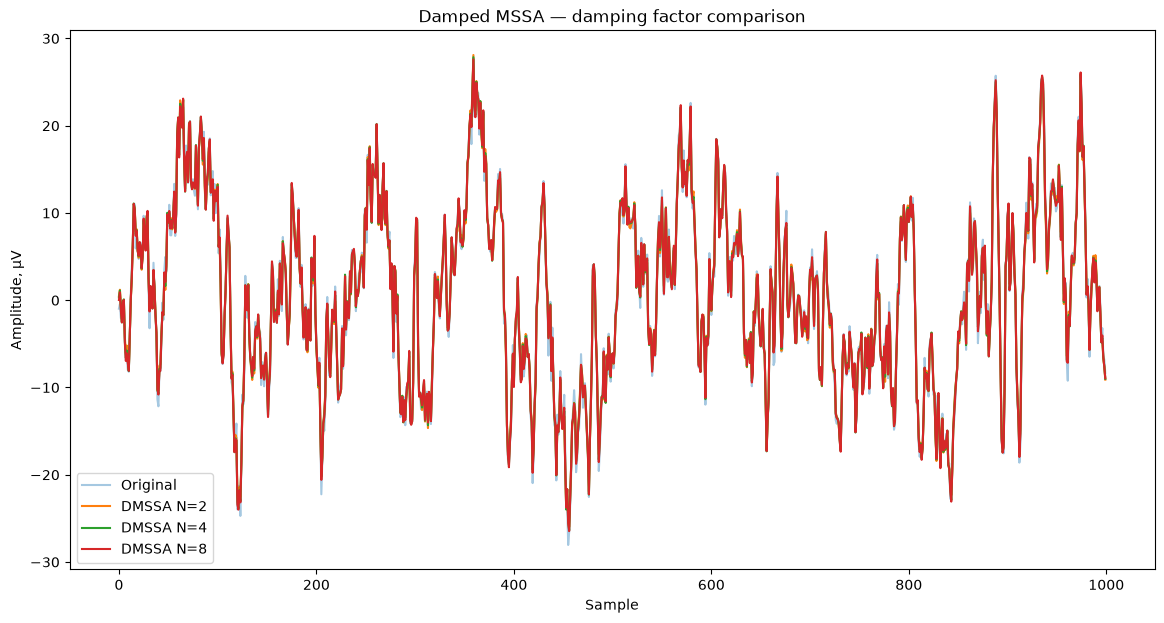

In [335]:


plt.figure(figsize=(14, 7))

plt.plot(
    trial[ch_idx] * 1e6,
    label="Original",
    alpha=0.4
)

for d in damping_factors:
    plt.plot(
        dmssa_versions[d][ch_idx] * 1e6,
        label=f"DMSSA N={d}",
        linewidth=1.5
    )

plt.xlabel("Sample")
plt.ylabel("Amplitude, µV")
plt.title("Damped MSSA — damping factor comparison")

plt.legend()
plt.show()

И визуально N=4 и N=8 почти неотличимы от оригинала. То есть чем больше damping factor, тем мягче метод вмешивается в EEG.

Я бы для первого downstream-теста взяла N=4. Почему не 8: при 8 мы почти уже ничего не меняем, а при 4 всё ещё есть заметное подавление слабых компонент, при этом motor-imagery диапазон практически сохраняется.


In [336]:
DMSSA_RANK = 300
DMSSA_WINDOW = 100
DMSSA_N = 4

И дальше делаем A01 целиком.

In [337]:


def dmssa_denoise_epochs(
    X,
    window_length=100,
    rank=300,
    damping_factor=4
):
    X_out = np.zeros_like(X, dtype=np.float32)

    for i in range(len(X)):
        X_out[i], _, _ = damped_mssa_denoise(
            X[i],
            window_length=window_length,
            rank=rank,
            damping_factor=damping_factor
        )

        if (i + 1) % 25 == 0:
            print(f"Processed {i+1}/{len(X)}")

    return X_out

In [338]:
X_train_dmssa = dmssa_denoise_epochs(
    X_train_raw,
    window_length=DMSSA_WINDOW,
    rank=DMSSA_RANK,
    damping_factor=DMSSA_N
)

X_val_dmssa = dmssa_denoise_epochs(
    X_val_raw,
    window_length=DMSSA_WINDOW,
    rank=DMSSA_RANK,
    damping_factor=DMSSA_N
)

X_test_dmssa = dmssa_denoise_epochs(
    X_test_raw,
    window_length=DMSSA_WINDOW,
    rank=DMSSA_RANK,
    damping_factor=DMSSA_N
)

Processed 25/230
Processed 50/230
Processed 75/230
Processed 100/230
Processed 125/230
Processed 150/230
Processed 175/230
Processed 200/230
Processed 225/230
Processed 25/58
Processed 50/58
Processed 25/288
Processed 50/288
Processed 75/288
Processed 100/288
Processed 125/288
Processed 150/288
Processed 175/288
Processed 200/288
Processed 225/288
Processed 250/288
Processed 275/288


Потом standardization + EA + global normalization ровно как раньше. Чтобы не копировать всё руками, можно использовать почти ту же схему:


In [339]:


X_train_dmssa_std = per_trial_standardize(X_train_dmssa)
X_val_dmssa_std = per_trial_standardize(X_val_dmssa)
X_test_dmssa_std = per_trial_standardize(X_test_dmssa)

R_train_dmssa = ea_reference(X_train_dmssa_std)
W_train_dmssa = inverse_sqrt_matrix(R_train_dmssa)

X_train_dmssa_ea = apply_ea(
    X_train_dmssa_std,
    W_train_dmssa
)

X_val_dmssa_ea = apply_ea(
    X_val_dmssa_std,
    W_train_dmssa
)

R_test_dmssa = ea_reference(X_test_dmssa_std)
W_test_dmssa = inverse_sqrt_matrix(R_test_dmssa)

X_test_dmssa_ea = apply_ea(
    X_test_dmssa_std,
    W_test_dmssa
)

dmssa_mean = np.float32(X_train_dmssa_ea.mean())
dmssa_std = np.float32(X_train_dmssa_ea.std()) + 1e-8

X_train_dmssa_ea = (
    X_train_dmssa_ea - dmssa_mean
) / dmssa_std

X_val_dmssa_ea = (
    X_val_dmssa_ea - dmssa_mean
) / dmssa_std

X_test_dmssa_ea = (
    X_test_dmssa_ea - dmssa_mean
) / dmssa_std

In [340]:
set_seed(42)

a01_dmssa_result = finetune_exact_eegnet_v2(
    pretrained_exact_model,

    X_train_dmssa_ea,
    y_train_raw,

    X_val_dmssa_ea,
    y_val_raw,

    X_test_dmssa_ea,
    y_test_raw,

    num_epochs=500,
    batch_size=64,
    learning_rate=5e-3,
    patience=150
)

Device: cpu
Epoch  25 | Val acc: 0.914 | Val loss: 0.5402 | Best: 0.983
Epoch  50 | Val acc: 0.897 | Val loss: 0.5098 | Best: 0.983
Epoch  75 | Val acc: 0.879 | Val loss: 0.5693 | Best: 0.983
Epoch 100 | Val acc: 0.931 | Val loss: 0.5767 | Best: 0.983
Epoch 125 | Val acc: 0.879 | Val loss: 0.5498 | Best: 0.983
Epoch 150 | Val acc: 0.897 | Val loss: 0.5878 | Best: 0.983

Early stopping at epoch 158

Best validation accuracy: 0.983
Best validation loss: 0.4852
Best epoch: 8

Test accuracy: 0.84
Balanced accuracy: 0.84
Macro F1: 0.84
Kappa: 0.787


даже очень мягкое spectral damping не улучшает downstream-классификацию. И это важный результат: сохранить общую мощность 8–30 Гц недостаточно. Можно почти не менять PSD, но всё равно нарушить фазовые/пространственные отношения между каналами, на которых сидит motor-imagery информация.

Я бы теперь не продолжала перебирать N=2/8 по test A01E — это уже будет подгонка по тесту. Гораздо интереснее перейти к следующей сейсмической идее: adaptive correction / signal leakage recovery. То есть сначала шумоподавление, а затем часть residual, которая похожа на согласованный EEG-сигнал, возвращается обратно.

Схема:

Original EEG

↓

MSSA / DMSSA

↓

Denoised + Residual

           ↓

      анализ residual

           ↓

возвращаем согласованную часть residual

↓

Corrected EEG

Это прямо нацелено на нашу проблему: текущие методы, похоже, удаляют вместе с шумом часть полезного EEG. Поэтому следующий метод я бы строила именно вокруг восстановления signal leakage, а не ещё одного варианта shrinkage.

## Damped MSSA с адаптивным возвратом полезного сигнала

По сути идея такая: сначала сознательно чистим чуть агрессивнее, потом считаем residual

residual = original - denoised

и ищем в residual не просто шум, а ту согласованную часть, которая похожа на полезный EEG. Её возвращаем обратно. Это очень похоже на нашу проблему: все предыдущие методы делали сигнал чище, но accuracy падала, значит часть task-relevant структуры уезжала в residual.

Самая близкая статья — Zhang et al., 2026, “Robust damped multichannel singular spectrum analysis with adaptive correction: A parameter-tolerant approach for seismic data denoising and separation”. Авторы прямо пишут, что обычный MSSA чувствителен к rank, damped MSSA уменьшает residual noise, но может вносить amplitude bias и signal leakage. Их решение двухэтапное: сначала RDMSSA с консервативным/агрессивным подавлением, затем residual рассматривается как “leakage reservoir”; из него через non-stationary least-squares adaptive filtering извлекают согласованную энергию и добавляют обратно.

Есть и более ранняя опора: Chen et al., 2016, “An open-source Matlab code package for improved rank-reduction 3D seismic data denoising and reconstruction”. Там модифицируют обычный TSVD/rank-reduction, потому что стандартный вариант оставляет заметный residual noise. Это хороший мост между классическим MSSA и более поздними damped/robust вариантами.

Да. Но здесь важный момент: у статьи 2026 года доступен подробный abstract/preview, а не полный алгоритм с формулами adaptive correction. Из доступного текста можно уверенно воспроизвести идею двухэтапной схемы: сначала агрессивный RDMSSA, потом residual рассматривается как «резервуар утечки сигнала», и из него через non-stationary least-squares adaptive filter возвращают согласованную энергию.

Поэтому я предлагаю сделать нашу EEG-адаптацию этой идеи, честно обозначив её как adaptation, а не точную копию статьи.

Сначала логика:

Original EEG

↓

RDMSSA / DMSSA

↓

Denoised

↓

Residual = Original - Denoised

↓

ищем в residual часть,
которая коррелирует с denoised EEG

↓

возвращаем её обратно

↓

Corrected EEG

Самый простой безопасный вариант adaptive correction — подобрать коэффициент возврата residual по least squares:

In [341]:


def adaptive_residual_correction(
    original,
    denoised,
    alpha_max=0.5
):
    """
    Простая EEG-адаптация идеи adaptive correction:
    возвращаем только ту часть residual, которая
    согласуется с denoised сигналом.

    original, denoised:
        shape = (channels, time)
    """

    residual = original - denoised

    corrected = np.zeros_like(denoised)

    alphas = []

    for ch in range(original.shape[0]):

        d = denoised[ch]
        r = residual[ch]

        # LS-коэффициент связи residual с denoised
        alpha = np.dot(d, r) / (
            np.dot(r, r) + 1e-12
        )

        # Не даём вернуть слишком много
        alpha = np.clip(
            alpha,
            0.0,
            alpha_max
        )

        corrected[ch] = (
            d + alpha * r
        )

        alphas.append(alpha)

    return (
        corrected.astype(np.float32),
        np.array(alphas)
    )

Теперь берём наш текущий DMSSA:

In [342]:


X_dmssa, _, _ = damped_mssa_denoise(
    trial,
    window_length=100,
    rank=300,
    damping_factor=4
)

и делаем correction:


In [343]:


X_corrected, alphas = adaptive_residual_correction(
    trial,
    X_dmssa,
    alpha_max=0.5
)

print(
    "Mean alpha:",
    alphas.mean()
)

print(
    "Min / max alpha:",
    alphas.min(),
    alphas.max()
)

Mean alpha: 0.4919009
Min / max alpha: 0.4248396 0.5


Потом сразу сравним три сигнала:

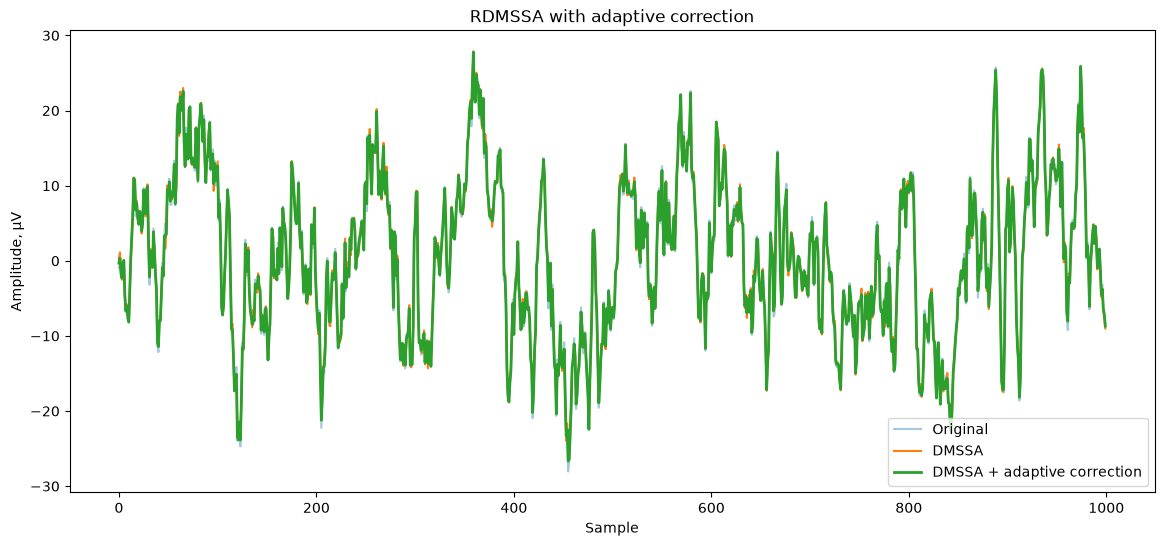

In [344]:


ch_idx = 0

plt.figure(figsize=(14, 6))

plt.plot(
    trial[ch_idx] * 1e6,
    label="Original",
    alpha=0.4
)

plt.plot(
    X_dmssa[ch_idx] * 1e6,
    label="DMSSA",
    linewidth=1.5
)

plt.plot(
    X_corrected[ch_idx] * 1e6,
    label="DMSSA + adaptive correction",
    linewidth=2
)

plt.xlabel("Sample")
plt.ylabel("Amplitude, µV")
plt.title("RDMSSA with adaptive correction")

plt.legend()
plt.show()

И те же метрики:

In [345]:


std_ratio = (
    X_corrected.std()
    / trial.std()
)

f_orig, psd_orig = mean_psd(
    trial[np.newaxis, ...]
)

f_corr, psd_corr = mean_psd(
    X_corrected[np.newaxis, ...]
)

power_orig = band_power(
    f_orig,
    psd_orig,
    8,
    30
)

power_corr = band_power(
    f_corr,
    psd_corr,
    8,
    30
)

band_change = (
    power_corr / power_orig - 1
) * 100

rmse_uV = (
    np.sqrt(
        np.mean(
            (X_corrected - trial) ** 2
        )
    )
    * 1e6
)

print("STD ratio:", std_ratio)
print("8–30 Hz change, %:", band_change)
print("RMSE to original, µV:", rmse_uV)

STD ratio: 0.9970291
8–30 Hz change, %: -0.8517069664135235
RMSE to original, µV: 0.3442218


daptive correction действительно почти полностью возвращает потерянную структуру после DMSSA.

Но здесь есть важный нюанс: раз почти все alpha близки к 0.5, наш текущий LS-критерий по сути говорит: “верни примерно половину residual почти везде”. Это пока не очень адаптивно.

Поэтому я бы следующим шагом не сразу шла в классификацию, а сделала локальную adaptive correction по временным окнам. Тогда коэффициент будет разным в разных участках EEG:

участок 1 → alpha 0.1
участок 2 → alpha 0.45
участок 3 → alpha 0.0
...

In [346]:
def local_adaptive_residual_correction(
    original,
    denoised,
    window_size=100,
    step=50,
    alpha_max=0.5
):
    residual = original - denoised

    n_channels, n_times = original.shape

    corrected = np.zeros_like(original, dtype=np.float64)
    weights = np.zeros_like(original, dtype=np.float64)

    alpha_map = []

    for ch in range(n_channels):
        channel_alphas = []

        for start in range(0, n_times - window_size + 1, step):
            end = start + window_size

            d = denoised[ch, start:end]
            r = residual[ch, start:end]

            alpha = np.dot(d, r) / (
                np.dot(r, r) + 1e-12
            )

            alpha = np.clip(
                alpha,
                0.0,
                alpha_max
            )

            corrected_chunk = (
                d + alpha * r
            )

            corrected[ch, start:end] += corrected_chunk
            weights[ch, start:end] += 1.0

            channel_alphas.append(alpha)

        alpha_map.append(channel_alphas)

    corrected /= np.maximum(
        weights,
        1e-8
    )

    return (
        corrected.astype(np.float32),
        np.array(alpha_map)
    )


In [347]:
X_local_corr, alpha_map = local_adaptive_residual_correction(
    trial,
    X_dmssa,
    window_size=100,
    step=50,
    alpha_max=0.5
)

print("Mean alpha:", alpha_map.mean())
print("Min alpha:", alpha_map.min())
print("Max alpha:", alpha_map.max())

Mean alpha: 0.30458352
Min alpha: 0.0
Max alpha: 0.5


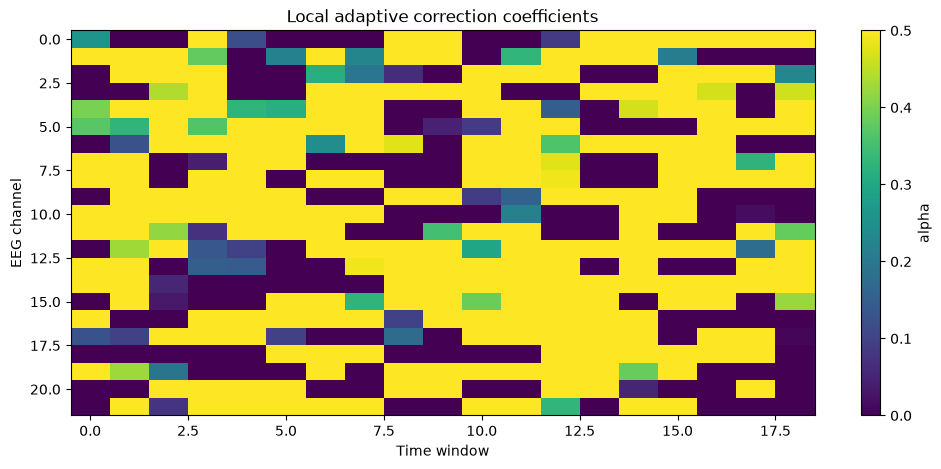

In [348]:
plt.figure(figsize=(12, 5))

plt.imshow(
    alpha_map,
    aspect="auto"
)

plt.colorbar(label="alpha")
plt.xlabel("Time window")
plt.ylabel("EEG channel")
plt.title("Local adaptive correction coefficients")
plt.show()


Вот это уже выглядит действительно адаптивно: alpha не прилип к одному значению, а меняется по каналам и временным окнам.

Следующий шаг — не классификатор сразу, а сначала посчитать для X_local_corr те же sanity-check метрики, чтобы понять, не стала ли коррекция слишком близкой к исходному EEG:

In [349]:


std_ratio = X_local_corr.std() / trial.std()

f_orig, psd_orig = mean_psd(
    trial[np.newaxis, ...]
)

f_corr, psd_corr = mean_psd(
    X_local_corr[np.newaxis, ...]
)

power_orig = band_power(
    f_orig,
    psd_orig,
    8,
    30
)

power_corr = band_power(
    f_corr,
    psd_corr,
    8,
    30
)

band_change = (
    power_corr / power_orig - 1
) * 100

rmse_uV = (
    np.sqrt(
        np.mean(
            (X_local_corr - trial) ** 2
        )
    )
    * 1e6
)

print("STD ratio:", std_ratio)
print("8–30 Hz change, %:", band_change)
print("RMSE to original, µV:", rmse_uV)

STD ratio: 0.99726605
8–30 Hz change, %: -0.7834222443885319
RMSE to original, µV: 0.48188287


И я бы ещё посчитала, сколько коэффициентов реально равны 0 и 0.5:

In [350]:


print(
    "alpha = 0:",
    np.mean(alpha_map == 0) * 100,
    "%"
)

print(
    "alpha = 0.5:",
    np.mean(alpha_map == 0.5) * 100,
    "%"
)

print(
    "intermediate:",
    np.mean(
        (alpha_map > 0) &
        (alpha_map < 0.5)
    ) * 100,
    "%"
)

alpha = 0: 31.100478468899524 %
alpha = 0.5: 52.87081339712919 %
intermediate: 16.028708133971293 %


метод адаптивный по времени и каналам, но больше половины окон упираются в разрешённый максимум 0.5. Я бы пока не усложняла формулу. Сначала проверим главное: помогло ли это downstream-классификации. Если опять получим 0.84, тогда уже станет ясно, что проблема не в недостаточно красивой alpha.

1. Функция для всех эпох

Она будет делать:

EEG
→ DMSSA
→ local adaptive correction
→ corrected EEG

In [352]:

def rdmssa_adaptive_denoise_epochs(
    X,
    window_length=100,
    rank=300,
    damping_factor=4,
    correction_window=100,
    correction_step=50,
    alpha_max=0.5
):
    X_out = np.zeros_like(X, dtype=np.float32)

    all_mean_alphas = []

    for i in range(len(X)):

        # 1. Damped MSSA
        X_dmssa, _, _ = damped_mssa_denoise(
            X[i],
            window_length=window_length,
            rank=rank,
            damping_factor=damping_factor
        )

        # 2. Local adaptive correction
        X_corrected, alpha_map = local_adaptive_residual_correction(
            X[i],
            X_dmssa,
            window_size=correction_window,
            step=correction_step,
            alpha_max=alpha_max
        )

        X_out[i] = X_corrected

        all_mean_alphas.append(
            alpha_map.mean()
        )

        if (i + 1) % 25 == 0:
            print(
                f"Processed {i+1}/{len(X)} | "
                f"mean alpha={np.mean(all_mean_alphas):.3f}"
            )

    return (
        X_out,
        np.array(all_mean_alphas)
    )

2. Прогоняем только A01

In [353]:

X_train_rdmssa, alpha_train = rdmssa_adaptive_denoise_epochs(
    X_train_raw
)

X_val_rdmssa, alpha_val = rdmssa_adaptive_denoise_epochs(
    X_val_raw
)

X_test_rdmssa, alpha_test = rdmssa_adaptive_denoise_epochs(
    X_test_raw
)

print()
print("Mean alpha train:", alpha_train.mean())
print("Mean alpha val:", alpha_val.mean())
print("Mean alpha test:", alpha_test.mean())

Processed 25/230 | mean alpha=0.311
Processed 50/230 | mean alpha=0.312
Processed 75/230 | mean alpha=0.312
Processed 100/230 | mean alpha=0.311
Processed 125/230 | mean alpha=0.311
Processed 150/230 | mean alpha=0.311
Processed 175/230 | mean alpha=0.311
Processed 200/230 | mean alpha=0.311
Processed 225/230 | mean alpha=0.311
Processed 25/58 | mean alpha=0.308
Processed 50/58 | mean alpha=0.310
Processed 25/288 | mean alpha=0.313
Processed 50/288 | mean alpha=0.312
Processed 75/288 | mean alpha=0.311
Processed 100/288 | mean alpha=0.312
Processed 125/288 | mean alpha=0.312
Processed 150/288 | mean alpha=0.312
Processed 175/288 | mean alpha=0.310
Processed 200/288 | mean alpha=0.309
Processed 225/288 | mean alpha=0.308
Processed 250/288 | mean alpha=0.307
Processed 275/288 | mean alpha=0.307

Mean alpha train: 0.31084302
Mean alpha val: 0.31032658
Mean alpha test: 0.3062077


3. Готовим под классификатор

Как всегда — абсолютно тот же preprocessing.

In [354]:


X_train_rdmssa_std = per_trial_standardize(
    X_train_rdmssa
)

X_val_rdmssa_std = per_trial_standardize(
    X_val_rdmssa
)

X_test_rdmssa_std = per_trial_standardize(
    X_test_rdmssa
)

EA:

In [355]:


R_train_rdmssa = ea_reference(
    X_train_rdmssa_std
)

W_train_rdmssa = inverse_sqrt_matrix(
    R_train_rdmssa
)

X_train_rdmssa_ea = apply_ea(
    X_train_rdmssa_std,
    W_train_rdmssa
)

X_val_rdmssa_ea = apply_ea(
    X_val_rdmssa_std,
    W_train_rdmssa
)


# Test — отдельный unlabeled reference
R_test_rdmssa = ea_reference(
    X_test_rdmssa_std
)

W_test_rdmssa = inverse_sqrt_matrix(
    R_test_rdmssa
)

X_test_rdmssa_ea = apply_ea(
    X_test_rdmssa_std,
    W_test_rdmssa
)

Нормализация только по train:

In [356]:


rdmssa_mean = np.float32(
    X_train_rdmssa_ea.mean()
)

rdmssa_std = (
    np.float32(
        X_train_rdmssa_ea.std()
    )
    + 1e-8
)

X_train_rdmssa_ea = (
    X_train_rdmssa_ea - rdmssa_mean
) / rdmssa_std

X_val_rdmssa_ea = (
    X_val_rdmssa_ea - rdmssa_mean
) / rdmssa_std

X_test_rdmssa_ea = (
    X_test_rdmssa_ea - rdmssa_mean
) / rdmssa_std

In [357]:
set_seed(42)

a01_rdmssa_result = finetune_exact_eegnet_v2(
    pretrained_exact_model,

    X_train_rdmssa_ea,
    y_train_raw,

    X_val_rdmssa_ea,
    y_val_raw,

    X_test_rdmssa_ea,
    y_test_raw,

    num_epochs=500,
    batch_size=64,
    learning_rate=5e-3,
    patience=150
)


Device: cpu
Epoch  25 | Val acc: 0.931 | Val loss: 0.5325 | Best: 0.983
Epoch  50 | Val acc: 0.931 | Val loss: 0.5023 | Best: 0.983
Epoch  75 | Val acc: 0.879 | Val loss: 0.5509 | Best: 0.983
Epoch 100 | Val acc: 0.897 | Val loss: 0.5740 | Best: 0.983
Epoch 125 | Val acc: 0.897 | Val loss: 0.5655 | Best: 0.983
Epoch 150 | Val acc: 0.879 | Val loss: 0.5814 | Best: 0.983

Early stopping at epoch 158

Best validation accuracy: 0.983
Best validation loss: 0.4813
Best epoch: 8

Test accuracy: 0.851
Balanced accuracy: 0.851
Macro F1: 0.85
Kappa: 0.801


То есть коррекция вернула примерно +1.1 п.п. относительно обычного DMSSA и стала лучшим из наших сейсмических денойзинговых вариантов после weighted MSSA, но baseline всё ещё выше примерно на 2.1 п.п.

Это важный результат: гипотеза про signal leakage частично подтверждается. После DMSSA часть полезной структуры действительно уходит в residual, и локальный возврат части residual немного восстанавливает downstream-качество.

Я бы сейчас не тюнила alpha_max по A01E, чтобы не подгоняться по test. Лучше зафиксировать текущие параметры:

rank = 300
damping_factor = 4
correction_window = 100
correction_step = 50
alpha_max = 0.5

и раскатать этот вариант на все 9 субъектов. Тогда уже посмотрим, это реальный устойчивый эффект или только A01.

Полный прогон RDMSSA + local adaptive correction на A01–A09 и сразу сравниваем со всеми предыдущими вариантами.

Сначала зафиксируем параметры:

In [358]:


RDMSSA_RANK = 300
RDMSSA_WINDOW = 100
RDMSSA_DAMPING = 4

CORR_WINDOW = 100
CORR_STEP = 50
ALPHA_MAX = 0.5

Теперь функция, которая для одного субъекта делает весь denoising pipeline:

In [359]:


def prepare_rdmssa_for_classifier(
    X_train_raw,
    X_val_raw,
    X_test_raw
):
    # 1. RDMSSA + adaptive correction
    X_train_rdmssa, _ = rdmssa_adaptive_denoise_epochs(
        X_train_raw,
        window_length=RDMSSA_WINDOW,
        rank=RDMSSA_RANK,
        damping_factor=RDMSSA_DAMPING,
        correction_window=CORR_WINDOW,
        correction_step=CORR_STEP,
        alpha_max=ALPHA_MAX
    )

    X_val_rdmssa, _ = rdmssa_adaptive_denoise_epochs(
        X_val_raw,
        window_length=RDMSSA_WINDOW,
        rank=RDMSSA_RANK,
        damping_factor=RDMSSA_DAMPING,
        correction_window=CORR_WINDOW,
        correction_step=CORR_STEP,
        alpha_max=ALPHA_MAX
    )

    X_test_rdmssa, _ = rdmssa_adaptive_denoise_epochs(
        X_test_raw,
        window_length=RDMSSA_WINDOW,
        rank=RDMSSA_RANK,
        damping_factor=RDMSSA_DAMPING,
        correction_window=CORR_WINDOW,
        correction_step=CORR_STEP,
        alpha_max=ALPHA_MAX
    )

    # 2. per-trial standardization
    X_train_std = per_trial_standardize(X_train_rdmssa)
    X_val_std = per_trial_standardize(X_val_rdmssa)
    X_test_std = per_trial_standardize(X_test_rdmssa)

    # 3. EA train / val
    R_train = ea_reference(X_train_std)
    W_train = inverse_sqrt_matrix(R_train)

    X_train_ea = apply_ea(
        X_train_std,
        W_train
    )

    X_val_ea = apply_ea(
        X_val_std,
        W_train
    )

    # 4. EA test отдельно
    R_test = ea_reference(X_test_std)
    W_test = inverse_sqrt_matrix(R_test)

    X_test_ea = apply_ea(
        X_test_std,
        W_test
    )

    # 5. global normalization — только train
    mean = np.float32(
        X_train_ea.mean()
    )

    std = np.float32(
        X_train_ea.std()
    ) + 1e-8

    X_train_ea = (
        X_train_ea - mean
    ) / std

    X_val_ea = (
        X_val_ea - mean
    ) / std

    X_test_ea = (
        X_test_ea - mean
    ) / std

    return (
        X_train_ea.astype(np.float32),
        X_val_ea.astype(np.float32),
        X_test_ea.astype(np.float32)
    )

Теперь весь цикл по 9 субъектам:

In [360]:


rdmssa_all_results = []

for subject_num in range(1, 10):

    subject = f"A{subject_num:02d}"

    print("\n" + "=" * 70)
    print("SUBJECT:", subject)
    print("=" * 70)

    train_file = (
        f"/Users/irina/Desktop/master project/"
        f"BCICIV_2a_gdf/{subject}T.gdf"
    )

    eval_file = (
        f"/Users/irina/Desktop/master project/"
        f"BCICIV_2a_gdf/{subject}E.gdf"
    )

    labels_file = (
        f"/Users/irina/Desktop/master project/"
        f"true_labels/{subject}E.mat"
    )

    # raw BCI
    (
        X_train_raw_subj,
        X_val_raw_subj,
        X_test_raw_subj,
        y_train_subj,
        y_val_subj,
        y_test_subj
    ) = prepare_subject_for_denoising(
        train_file,
        eval_file,
        labels_file
    )

    # RDMSSA + correction + EA
    (
        X_train_rdmssa_ea,
        X_val_rdmssa_ea,
        X_test_rdmssa_ea
    ) = prepare_rdmssa_for_classifier(
        X_train_raw_subj,
        X_val_raw_subj,
        X_test_raw_subj
    )

    # одинаковый seed
    set_seed(42)

    result = finetune_exact_eegnet_v2(
        pretrained_exact_model,

        X_train_rdmssa_ea,
        y_train_subj,

        X_val_rdmssa_ea,
        y_val_subj,

        X_test_rdmssa_ea,
        y_test_subj,

        num_epochs=500,
        batch_size=64,
        learning_rate=5e-3,
        patience=150
    )

    rdmssa_all_results.append({
        "subject": subject,
        "accuracy": result["accuracy"],
        "balanced_accuracy": result["balanced_accuracy"],
        "macro_f1": result["macro_f1"],
        "kappa": result["kappa"],
        "best_val_accuracy": result["best_val_accuracy"],
        "best_epoch": result["best_epoch"]
    })


SUBJECT: A01


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Processed 25/230 | mean alpha=0.311
Processed 50/230 | mean alpha=0.312
Processed 75/230 | mean alpha=0.312
Processed 100/230 | mean alpha=0.311
Processed 125/230 | mean alpha=0.311
Processed 150/230 | mean alpha=0.311
Processed 175/230 | mean alpha=0.311
Processed 200/230 | mean alpha=0.311
Processed 225/230 | mean alpha=0.311
Processed 25/58 | mean alpha=0.308
Processed 50/58 | mean alpha=0.310
Processed 25/288 | mean alpha=0.313
Processed 50/288 | mean alpha=0.312
Processed 75/288 | mean alpha=0.311
Processed 100/288 | mean alpha=0.312
Processed 125/288 | mean alpha=0.312
Processed 150/288 | mean alpha=0.312
Processed 175/288 | mean alpha=0.310
Processed 200/288 | mean alpha=0.309
Processed 225/288 | mean alpha=0.308
Processed 250/288 | mean alpha=0.307
Processed 275/288 | mean alpha=0.307
Device: cpu
Epoch  25 | Val acc: 0.931 | Val loss: 0.5325 | Best: 0.983
Epoch  50 | Val acc: 0.931 | Val loss: 0.5023 | Best: 0.983
Epoch  75 | Val acc: 0.879 | Val loss: 0.5509 | Best: 0.983
Epoc

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Processed 25/230 | mean alpha=0.313
Processed 50/230 | mean alpha=0.312
Processed 75/230 | mean alpha=0.312
Processed 100/230 | mean alpha=0.312
Processed 125/230 | mean alpha=0.312
Processed 150/230 | mean alpha=0.312
Processed 175/230 | mean alpha=0.311
Processed 200/230 | mean alpha=0.311
Processed 225/230 | mean alpha=0.311
Processed 25/58 | mean alpha=0.311
Processed 50/58 | mean alpha=0.312
Processed 25/288 | mean alpha=0.295
Processed 50/288 | mean alpha=0.295
Processed 75/288 | mean alpha=0.287
Processed 100/288 | mean alpha=0.285
Processed 125/288 | mean alpha=0.282
Processed 150/288 | mean alpha=0.281
Processed 175/288 | mean alpha=0.282
Processed 200/288 | mean alpha=0.282
Processed 225/288 | mean alpha=0.281
Processed 250/288 | mean alpha=0.281
Processed 275/288 | mean alpha=0.283
Device: cpu
Epoch  25 | Val acc: 0.828 | Val loss: 0.7481 | Best: 0.845
Epoch  50 | Val acc: 0.897 | Val loss: 0.6377 | Best: 0.914
Epoch  75 | Val acc: 0.879 | Val loss: 0.6855 | Best: 0.914
Epoc

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


... (9 outputs left out)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Processed 25/230 | mean alpha=0.290
Processed 50/230 | mean alpha=0.290
Processed 75/230 | mean alpha=0.290
Processed 100/230 | mean alpha=0.290
Processed 125/230 | mean alpha=0.291
Processed 150/230 | mean alpha=0.291
Processed 175/230 | mean alpha=0.291
Processed 200/230 | mean alpha=0.291
Processed 225/230 | mean alpha=0.291
Processed 25/58 | mean alpha=0.291
Processed 50/58 | mean alpha=0.291
Processed 25/288 | mean alpha=0.290
Processed 50/288 | mean alpha=0.290
Processed 75/288 | mean alpha=0.286
Processed 100/288 | mean alpha=0.284
Processed 125/288 | mean alpha=0.284
Processed 150/288 | mean alpha=0.284
Processed 175/288 | mean alpha=0.285
Processed 200/288 | mean alpha=0.284
Processed 225/288 | mean alpha=0.284
Processed 250/288 | mean alpha=0.284
Processed 275/288 | mean alpha=0.284
Device: cpu
Epoch  25 | Val acc: 0.966 | Val loss: 0.5221 | Best: 0.983
Epoch  50 | Val acc: 0.948 | Val loss: 0.5345 | Best: 0.983
Epoch  75 | Val acc: 0.948 | Val loss: 0.5698 | Best: 0.983
Epoc

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Processed 25/230 | mean alpha=0.310
Processed 50/230 | mean alpha=0.310
Processed 75/230 | mean alpha=0.310
Processed 100/230 | mean alpha=0.309
Processed 125/230 | mean alpha=0.309
Processed 150/230 | mean alpha=0.310
Processed 175/230 | mean alpha=0.310
Processed 200/230 | mean alpha=0.310
Processed 225/230 | mean alpha=0.310
Processed 25/58 | mean alpha=0.309
Processed 50/58 | mean alpha=0.310
Processed 25/288 | mean alpha=0.312
Processed 50/288 | mean alpha=0.309
Processed 75/288 | mean alpha=0.311
Processed 100/288 | mean alpha=0.311
Processed 125/288 | mean alpha=0.310
Processed 150/288 | mean alpha=0.311
Processed 175/288 | mean alpha=0.311
Processed 200/288 | mean alpha=0.312
Processed 225/288 | mean alpha=0.312
Processed 250/288 | mean alpha=0.311
Processed 275/288 | mean alpha=0.310
Device: cpu
Epoch  25 | Val acc: 0.966 | Val loss: 0.5069 | Best: 0.966
Epoch  50 | Val acc: 0.931 | Val loss: 0.5104 | Best: 0.966
Epoch  75 | Val acc: 0.966 | Val loss: 0.4965 | Best: 0.966
Epoc

таблица:

In [361]:


rdmssa_results_df = pd.DataFrame(
    rdmssa_all_results
)

display(
    rdmssa_results_df.round(3)
)

,subject,accuracy,balanced_accuracy,macro_f1,kappa,best_val_accuracy,best_epoch
0,A01,0.851,0.851,0.850,0.801,0.983,8
1,A02,0.594,0.594,0.579,0.458,0.914,51
2,A03,0.969,0.969,0.969,0.958,0.983,74
3,A04,0.715,0.715,0.715,0.620,0.845,40
4,A05,0.691,0.691,0.686,0.588,0.931,11
5,A06,0.587,0.587,0.576,0.449,0.931,56
6,A07,0.861,0.861,0.862,0.815,0.983,17
7,A08,0.826,0.826,0.826,0.769,0.983,1
8,A09,0.823,0.823,0.822,0.764,0.983,92


И средние:

In [362]:


print(
    "Mean accuracy:",
    rdmssa_results_df["accuracy"].mean()
)

print(
    "Mean balanced accuracy:",
    rdmssa_results_df["balanced_accuracy"].mean()
)

print(
    "Mean Macro F1:",
    rdmssa_results_df["macro_f1"].mean()
)

print(
    "Mean Kappa:",
    rdmssa_results_df["kappa"].mean()
)

Mean accuracy: 0.7685185185185186
Mean balanced accuracy: 0.7685185185185186
Mean Macro F1: 0.764820343036777
Mean Kappa: 0.6913580246913581


Добавим RDMSSA:

In [363]:


final_denoising_comparison = (
    exact_results_df[
        ["subject", "accuracy"]
    ]
    .rename(
        columns={
            "accuracy": "Baseline"
        }
    )

    .merge(
        denoised_results_df[
            ["subject", "accuracy"]
        ].rename(
            columns={
                "accuracy": "CNN"
            }
        ),
        on="subject"
    )

    .merge(
        mssa_results_df[
            ["subject", "accuracy"]
        ].rename(
            columns={
                "accuracy": "MSSA"
            }
        ),
        on="subject"
    )

    .merge(
        rdmssa_results_df[
            ["subject", "accuracy"]
        ].rename(
            columns={
                "accuracy": "RDMSSA_corrected"
            }
        ),
        on="subject"
    )
)

display(
    final_denoising_comparison.round(3)
)

,subject,Baseline,CNN,MSSA,RDMSSA_corrected
0,A01,0.872,0.844,0.844,0.851
1,A02,0.608,0.604,0.594,0.594
2,A03,0.948,0.924,0.955,0.969
3,A04,0.740,0.611,0.719,0.715
4,A05,0.750,0.653,0.684,0.691
5,A06,0.646,0.590,0.625,0.587
6,A07,0.899,0.840,0.872,0.861
7,A08,0.819,0.833,0.833,0.826
8,A09,0.840,0.764,0.806,0.823


И средние:

In [364]:


mean_comparison = (
    final_denoising_comparison[
        [
            "Baseline",
            "CNN",
            "MSSA",
            "RDMSSA_corrected"
        ]
    ]
    .mean()
    .round(3)
)

display(mean_comparison)

Baseline            0.791
CNN                 0.740
MSSA                0.770
RDMSSA_corrected    0.769
dtype: float64

И ещё дельты относительно baseline:

In [365]:


final_denoising_comparison["CNN_delta"] = (
    final_denoising_comparison["CNN"]
    - final_denoising_comparison["Baseline"]
)

final_denoising_comparison["MSSA_delta"] = (
    final_denoising_comparison["MSSA"]
    - final_denoising_comparison["Baseline"]
)

final_denoising_comparison["RDMSSA_delta"] = (
    final_denoising_comparison["RDMSSA_corrected"]
    - final_denoising_comparison["Baseline"]
)

display(
    final_denoising_comparison.round(3)
)

,subject,Baseline,CNN,MSSA,RDMSSA_corrected,CNN_delta,MSSA_delta,RDMSSA_delta
0,A01,0.872,0.844,0.844,0.851,-0.028,-0.028,-0.021
1,A02,0.608,0.604,0.594,0.594,-0.003,-0.014,-0.014
2,A03,0.948,0.924,0.955,0.969,-0.024,0.007,0.021
3,A04,0.740,0.611,0.719,0.715,-0.128,-0.021,-0.024
4,A05,0.750,0.653,0.684,0.691,-0.097,-0.066,-0.059
5,A06,0.646,0.590,0.625,0.587,-0.056,-0.021,-0.059
6,A07,0.899,0.840,0.872,0.861,-0.059,-0.028,-0.038
7,A08,0.819,0.833,0.833,0.826,0.014,0.014,0.007
8,A09,0.840,0.764,0.806,0.823,-0.076,-0.035,-0.017


Сейсмические low-rank методы лучше переносятся на EEG, чем supervised CNN-denoiser, однако ни MSSA, ни RDMSSA с локальной adaptive correction не улучшают среднюю downstream accuracy относительно отсутствия денойзинга. Эффект сильно зависит от субъекта.


### subject-adaptive preprocessing / artifact removal для motor imagery

 Tobón-Henao et al., 2022, “Subject-Dependent Artifact Removal for Enhancing Motor Imagery Classifier Performance under Poor Skills”. Они прямо предлагают subject-dependent preprocessing: для разных испытуемых выбор и применение очистки зависит от того, как конкретный человек показывает себя в MI-классификации. Используют Surface Laplacian + ICA и показывают, что особенно это помогает “плохим” субъектам.

Adaptive EEG preprocessing to mitigate electrode shift variability for robust motor imagery classification. Там адаптация уже делается через обучаемое channel mixing / weighting перед классификатором; проверяли в том числе на BCI Competition IV 2a. Это не denoising в нашем смысле, но хорошо поддерживает сам принцип: preprocessing не обязан быть одинаковым для всех субъектов.

Adaptive SSA Based Muscle Artifact Removal from Single Channel EEG: там параметры SSA адаптируются к уровню загрязнения, причём степень загрязнения оценивается моделью, а затем используется для выбора threshold SSA. Это особенно близко к нашей ветке MSSA/SSA: сила очистки определяется характеристиками конкретного сигнала, а не фиксируется однажды для всех.

 A robust adaptive denoising framework for real-time artifact removal in scalp EEG measurements. Авторы отмечают, что амплитуда и пространственное распределение артефактов сильно зависят от электрода, поэтому фиксированные параметры фильтрации для всех участков головы не оптимальны; они используют адаптивную обработку по каналам и показывают улучшение decoding performance.

для каждого Axx

↓

смотрим train/val EEG

↓

оцениваем SNR / singular spectrum / PSD / validation accuracy

↓

выбираем strength denoising

↓

фиксируем параметры

↓

тестируем на AxxE

гипотеза: межсубъектная вариативность EEG требует subject-dependent preprocessing.


1. Получаем singular values одного trial без denoising

In [366]:

def get_mssa_singular_values(
    X,
    window_length=100
):
    X = X.astype(np.float64)

    hankels = []

    for ch in range(X.shape[0]):
        H = make_hankel(
            X[ch],
            window_length
        )

        hankels.append(H)

    H_multi = np.vstack(hankels)

    _, S, _ = np.linalg.svd(
        H_multi,
        full_matrices=False
    )

    return S

2. Считаем средний спектр субъекта только по train

Чтобы не делать вывод по одному trial:

In [367]:


def subject_mean_singular_spectrum(
    X_train,
    window_length=100
):
    spectra = []

    for i in range(len(X_train)):

        S = get_mssa_singular_values(
            X_train[i],
            window_length=window_length
        )

        # переводим в энергию
        energy = S ** 2

        # нормируем, чтобы trial с большой амплитудой
        # не доминировал
        energy = energy / energy.sum()

        spectra.append(energy)

        if (i + 1) % 25 == 0:
            print(
                f"Processed {i+1}/{len(X_train)}"
            )

    return np.mean(
        spectra,
        axis=0
    )

3. Сначала калибруемся на A01

In [368]:

a01_mean_energy = subject_mean_singular_spectrum(
    X_train_raw,
    window_length=100
)

Processed 25/230
Processed 50/230
Processed 75/230
Processed 100/230
Processed 125/230
Processed 150/230
Processed 175/230
Processed 200/230
Processed 225/230


Теперь считаем, сколько энергии было в первых 300 компонентах:

In [369]:


A01_REFERENCE_RANK = 300

target_energy = np.sum(
    a01_mean_energy[:A01_REFERENCE_RANK]
)

print(
    "Energy retained by rank=300:",
    target_energy
)

print(
    "Energy retained, %:",
    target_energy * 100
)

Energy retained by rank=300: 0.995398400561387
Energy retained, %: 99.5398400561387


4. Функция выбора subject-specific rank

In [370]:

def rank_from_energy(
    mean_energy,
    target_energy
):
    cumulative = np.cumsum(
        mean_energy
    )

    rank = (
        np.searchsorted(
            cumulative,
            target_energy
        )
        + 1
    )

    return int(rank)

5. А дальше для каждого субъекта

In [372]:

subject_adaptive_ranks = []

for subject_num in range(1, 10):

    subject = f"A{subject_num:02d}"

    print("\n" + "=" * 60)
    print("SUBJECT:", subject)
    print("=" * 60)

    train_file = (
        f"/Users/irina/Desktop/master project/"
        f"BCICIV_2a_gdf/{subject}T.gdf"
    )

    eval_file = (
        f"/Users/irina/Desktop/master project/"
        f"BCICIV_2a_gdf/{subject}E.gdf"
    )

    labels_file = (
        f"/Users/irina/Desktop/master project/"
        f"true_labels/{subject}E.mat"
    )

    # Нам здесь фактически нужен только train,
    # но используем уже готовую функцию подготовки
    (
        X_train_subj,
        X_val_subj,
        X_test_subj,
        y_train_subj,
        y_val_subj,
        y_test_subj
    ) = prepare_subject_for_denoising(
        train_file,
        eval_file,
        labels_file
    )

    # Средний singular spectrum только по TRAIN
    mean_energy = subject_mean_singular_spectrum(
        X_train_subj,
        window_length=100
    )

    # Индивидуальный rank,
    # который сохраняет ту же долю энергии,
    # что rank=300 у A01
    adaptive_rank = rank_from_energy(
        mean_energy,
        target_energy
    )

    retained_energy = np.sum(
        mean_energy[:adaptive_rank]
    )

    subject_adaptive_ranks.append({
        "subject": subject,
        "adaptive_rank": adaptive_rank,
        "retained_energy": retained_energy,
        "retained_energy_pct": retained_energy * 100
    })

    print(
        f"{subject}: rank = {adaptive_rank} | "
        f"energy = {retained_energy * 100:.4f}%"
    )


SUBJECT: A01


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Processed 25/230
Processed 50/230
Processed 75/230
Processed 100/230
Processed 125/230
Processed 150/230
Processed 175/230
Processed 200/230
Processed 225/230
A01: rank = 300 | energy = 99.5398%

SUBJECT: A02


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Processed 25/230
Processed 50/230
Processed 75/230
Processed 100/230
Processed 125/230
Processed 150/230
Processed 175/230
Processed 200/230
Processed 225/230
A02: rank = 326 | energy = 99.5436%

SUBJECT: A03


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


... (9 outputs left out)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Processed 25/230
Processed 50/230
Processed 75/230
Processed 100/230
Processed 125/230
Processed 150/230
Processed 175/230
Processed 200/230
Processed 225/230
A08: rank = 229 | energy = 99.5417%

SUBJECT: A09


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Processed 25/230
Processed 50/230
Processed 75/230
Processed 100/230
Processed 125/230
Processed 150/230
Processed 175/230
Processed 200/230
Processed 225/230
A09: rank = 246 | energy = 99.5416%


Потом собираем красивую таблицу

In [373]:


subject_adaptive_ranks_df = pd.DataFrame(
    subject_adaptive_ranks
)

display(
    subject_adaptive_ranks_df.round(4)
)

,subject,adaptive_rank,retained_energy,retained_energy_pct
0,A01,300,0.9954,99.5398
1,A02,326,0.9954,99.5436
2,A03,315,0.9954,99.5427
3,A04,310,0.9954,99.5400
4,A05,267,0.9954,99.5404
5,A06,286,0.9954,99.5401
6,A07,321,0.9954,99.5416
7,A08,229,0.9954,99.5417
8,A09,246,0.9954,99.5416


посмотрела распределение rank:

In [374]:


print(
    "Mean rank:",
    subject_adaptive_ranks_df["adaptive_rank"].mean()
)

print(
    "Min rank:",
    subject_adaptive_ranks_df["adaptive_rank"].min()
)

print(
    "Max rank:",
    subject_adaptive_ranks_df["adaptive_rank"].max()
)

Mean rank: 288.8888888888889
Min rank: 229
Max rank: 326


Сделаем словарь:


In [375]:


adaptive_rank_map = dict(
    zip(
        subject_adaptive_ranks_df["subject"],
        subject_adaptive_ranks_df["adaptive_rank"]
    )
)

adaptive_rank_map

{'A01': 300,
 'A02': 326,
 'A03': 315,
 'A04': 310,
 'A05': 267,
 'A06': 286,
 'A07': 321,
 'A08': 229,
 'A09': 246}

Потом полный цикл:

In [376]:


subject_adaptive_mssa_results = []

for subject_num in range(1, 10):

    subject = f"A{subject_num:02d}"
    adaptive_rank = adaptive_rank_map[subject]

    print("\n" + "=" * 70)
    print(
        f"SUBJECT: {subject} | "
        f"adaptive rank: {adaptive_rank}"
    )
    print("=" * 70)

    train_file = (
        f"/Users/irina/Desktop/master project/"
        f"BCICIV_2a_gdf/{subject}T.gdf"
    )

    eval_file = (
        f"/Users/irina/Desktop/master project/"
        f"BCICIV_2a_gdf/{subject}E.gdf"
    )

    labels_file = (
        f"/Users/irina/Desktop/master project/"
        f"true_labels/{subject}E.mat"
    )

    (
        X_train_raw_subj,
        X_val_raw_subj,
        X_test_raw_subj,
        y_train_subj,
        y_val_subj,
        y_test_subj
    ) = prepare_subject_for_denoising(
        train_file,
        eval_file,
        labels_file
    )

    # MSSA с индивидуальным rank
    X_train_mssa = mssa_denoise_epochs(
        X_train_raw_subj,
        window_length=100,
        rank=adaptive_rank
    )

    X_val_mssa = mssa_denoise_epochs(
        X_val_raw_subj,
        window_length=100,
        rank=adaptive_rank
    )

    X_test_mssa = mssa_denoise_epochs(
        X_test_raw_subj,
        window_length=100,
        rank=adaptive_rank
    )

    # Standardization
    X_train_std = per_trial_standardize(X_train_mssa)
    X_val_std = per_trial_standardize(X_val_mssa)
    X_test_std = per_trial_standardize(X_test_mssa)

    # EA train → train/val
    R_train = ea_reference(X_train_std)
    W_train = inverse_sqrt_matrix(R_train)

    X_train_ea = apply_ea(
        X_train_std,
        W_train
    )

    X_val_ea = apply_ea(
        X_val_std,
        W_train
    )

    # EA test отдельно
    R_test = ea_reference(X_test_std)
    W_test = inverse_sqrt_matrix(R_test)

    X_test_ea = apply_ea(
        X_test_std,
        W_test
    )

    # Нормализация только по train
    mean = np.float32(X_train_ea.mean())
    std = np.float32(X_train_ea.std()) + 1e-8

    X_train_ea = (
        X_train_ea - mean
    ) / std

    X_val_ea = (
        X_val_ea - mean
    ) / std

    X_test_ea = (
        X_test_ea - mean
    ) / std

    # Classification
    set_seed(42)

    result = finetune_exact_eegnet_v2(
        pretrained_exact_model,

        X_train_ea,
        y_train_subj,

        X_val_ea,
        y_val_subj,

        X_test_ea,
        y_test_subj,

        num_epochs=500,
        batch_size=64,
        learning_rate=5e-3,
        patience=150
    )

    subject_adaptive_mssa_results.append({
        "subject": subject,
        "adaptive_rank": adaptive_rank,
        "accuracy": result["accuracy"],
        "balanced_accuracy": result["balanced_accuracy"],
        "macro_f1": result["macro_f1"],
        "kappa": result["kappa"],
        "best_val_accuracy": result["best_val_accuracy"],
        "best_epoch": result["best_epoch"]
    })


SUBJECT: A01 | adaptive rank: 300


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number 

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number 

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


... (9 outputs left out)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number 

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number of singular values: 901
Multichannel Hankel: (2200, 901)
Number 

In [377]:
subject_adaptive_mssa_df = pd.DataFrame(
    subject_adaptive_mssa_results
)

display(
    subject_adaptive_mssa_df.round(3)
)



,subject,adaptive_rank,accuracy,balanced_accuracy,macro_f1,kappa,best_val_accuracy,best_epoch
0,A01,300,0.844,0.844,0.843,0.792,0.983,1
1,A02,326,0.587,0.587,0.568,0.449,0.931,91
2,A03,315,0.969,0.969,0.969,0.958,0.983,74
3,A04,310,0.670,0.670,0.670,0.560,0.862,139
4,A05,267,0.688,0.688,0.681,0.583,0.948,12
5,A06,286,0.635,0.635,0.634,0.514,0.914,46
6,A07,321,0.868,0.868,0.868,0.824,0.983,17
7,A08,229,0.830,0.830,0.828,0.773,0.983,3
8,A09,246,0.788,0.788,0.787,0.718,0.983,84


In [378]:
adaptive_comparison_df = (
    exact_results_df[
        ["subject", "accuracy"]
    ]
    .rename(
        columns={"accuracy": "baseline"}
    )
    .merge(
        mssa_results_df[
            ["subject", "accuracy"]
        ].rename(
            columns={"accuracy": "fixed_rank300"}
        ),
        on="subject"
    )
    .merge(
        subject_adaptive_mssa_df[
            ["subject", "adaptive_rank", "accuracy"]
        ].rename(
            columns={"accuracy": "subject_adaptive"}
        ),
        on="subject"
    )
)

adaptive_comparison_df["adaptive_delta_vs_baseline"] = (
    adaptive_comparison_df["subject_adaptive"]
    - adaptive_comparison_df["baseline"]
)

adaptive_comparison_df["adaptive_delta_vs_fixed"] = (
    adaptive_comparison_df["subject_adaptive"]
    - adaptive_comparison_df["fixed_rank300"]
)

display(
    adaptive_comparison_df.round(3)
)

,subject,baseline,fixed_rank300,adaptive_rank,subject_adaptive,adaptive_delta_vs_baseline,adaptive_delta_vs_fixed
0,A01,0.872,0.844,300,0.844,-0.028,0.000
1,A02,0.608,0.594,326,0.587,-0.021,-0.007
2,A03,0.948,0.955,315,0.969,0.021,0.014
3,A04,0.740,0.719,310,0.670,-0.069,-0.049
4,A05,0.750,0.684,267,0.688,-0.062,0.003
5,A06,0.646,0.625,286,0.635,-0.010,0.010
6,A07,0.899,0.872,321,0.868,-0.031,-0.003
7,A08,0.819,0.833,229,0.830,0.010,-0.003
8,A09,0.840,0.806,246,0.788,-0.052,-0.017


In [379]:


print(
    adaptive_comparison_df[
        [
            "baseline",
            "fixed_rank300",
            "subject_adaptive"
        ]
    ]
    .mean()
    .round(3)
)

baseline            0.791
fixed_rank300       0.770
subject_adaptive    0.764
dtype: float64


При применении к исходной BCI IV 2a дополнительное шумоподавление не улучшало классификацию и зачастую снижало её. Это показало, что оценивать denoising только по clean downstream accuracy некорректно и мотивировало controlled-noise эксперимент.


## Сравнение методов денойзинга на искусственно загрязнённой ЭЭГ

Логика:

Сначала мы проверяли denoising на исходной BCI IV 2a.


CNN, MSSA, RDMSSA и их варианты в среднем не улучшали классификацию чистой EEG.


Более мягкие методы просто всё меньше меняли сигнал и тем самым приближались обратно к baseline.


Стало понятно, что вопрос сформулирован неправильно: denoiser не обязан улучшать уже относительно чистый сигнал.


Поэтому мы переходим к контролируемому загрязнению, где есть известный clean target.


После этого можно честно измерить:
насколько шум испортил сигнал и классификацию;
насколько denoising восстановил и сам сигнал, и downstream accuracy.

Переход к semi-synthetic evaluation.
Прямое применение методов шумоподавления к исходной BCI IV 2a не приводило к росту downstream accuracy. При уменьшении силы денойзинга качество классификации приближалось к baseline, что фактически означало уменьшение вмешательства, а не улучшение удаления шума. Поэтому далее используется контролируемая semi-synthetic постановка: исходная motor-imagery EEG рассматривается как clean reference и искусственно загрязняется реальными EOG/EMG-артефактами при заданном SNR. Это позволяет одновременно оценивать качество реконструкции и восстановление downstream-классификации.

литература:

Самая прямая опора — EEGdenoiseNet, Zhang et al., 2021. Они специально создали benchmark из чистых EEG, EOG и EMG сегментов и генерировали semi-synthetic пары clean + artifact → noisy, причём чистая EEG оставалась ground truth. Для EOG использовали SNR от −7 до +2 dB и оценивали denoising именно на известных clean/noisy парах.

Ещё раньше был опубликован semi-simulated EEG/EOG dataset именно потому, что на реальной загрязнённой EEG неизвестно, каким должен быть настоящий clean сигнал. Авторы вручную загрязняли известную artifact-free EEG глазодвигательными артефактами, чтобы объективно сравнивать методы удаления артефактов. Это почти точное обоснование нашей постановки.

Есть и свежая работа 2026 года, где на EEGdenoiseNet строят controlled benchmark с EOG, EMG и их смесью при разных уровнях загрязнения и отдельно сравнивают SSA, VMD, DWT и CEEMDAN. Особенно приятно для нас, что SSA там показал наименьшую reconstruction error в большинстве условий — это прямая поддержка нашей ветки с SSA/MSSA.

Современные deep-learning работы делают то же самое: например, MultiResUNet3+ обучают на semi-synthetic EEG, сформированной из clean EEG + EOG/EMG из EEGdenoiseNet, и оценивают temporal/spectral reconstruction metrics.

И есть свежая работа 2025 года, где создают даже mixed-artifact варианты: EEG+EOG, EEG+EMG и EEG+EOG+EMG при SNR от −5 до +5 dB. То есть наш план с несколькими типами артефактов и уровнями SNR вполне соответствует текущей практике.

1. Получаем настоящий EOG-артефакт

In [380]:
def extract_artifact(hf_dataset, idx):
    item = hf_dataset[idx]

    clean = np.asarray(
        item["x"],
        dtype=np.float32
    )

    contaminated = np.asarray(
        item["y"],
        dtype=np.float32
    )

    artifact = contaminated - clean

    # убираем постоянное смещение
    artifact = artifact - artifact.mean()

    return artifact

Проверим:

In [381]:


eog_artifact = extract_artifact(
    EOG_train,
    idx=0
)

print("Shape:", eog_artifact.shape)
print("Mean:", eog_artifact.mean())
print("Std:", eog_artifact.std())

Shape: (512,)
Mean: 1.4901161e-08
Std: 1.0161952


2. Делаем артефакт длиной как наш BCI trial

Будем брать несколько реальных EOG-фрагментов и соединять их.

In [382]:


def make_artifact_signal(
    hf_dataset,
    target_length,
    start_idx=0
):
    pieces = []

    idx = start_idx

    while sum(len(x) for x in pieces) < target_length:

        artifact = extract_artifact(
            hf_dataset,
            idx
        )

        pieces.append(artifact)

        idx += 1

        if idx >= len(hf_dataset):
            idx = 0

    artifact_signal = np.concatenate(
        pieces
    )

    artifact_signal = artifact_signal[
        :target_length
    ]

    artifact_signal = (
        artifact_signal
        - artifact_signal.mean()
    )

    return artifact_signal.astype(
        np.float32
    )

Проверяем:

In [383]:


eog_1000 = make_artifact_signal(
    EOG_train,
    target_length=1000,
    start_idx=0
)

print(eog_1000.shape)

(1000,)


3. Превращаем EOG в многоканальный артефакт

Мы не будем добавлять 22 совершенно независимых EOG-сигнала. Глазной артефакт обычно пространственно связан: один и тот же источник виден на нескольких электродах, но с разной амплитудой.

Для первого эксперимента сделаем простой пространственный профиль:

In [384]:
EOG_CHANNEL_WEIGHTS = np.array([
    1.00,  # Fz

    0.85, 0.90, 0.95, 0.90, 0.85,  # FC

    0.65, 0.70, 0.75, 0.80,
    0.75, 0.70, 0.65,              # C

    0.45, 0.50, 0.55, 0.50, 0.45,  # CP

    0.30, 0.35, 0.30,               # P

    0.20                            # POz
], dtype=np.float32)

print(
    "Number of channel weights:",
    len(EOG_CHANNEL_WEIGHTS)
)

Number of channel weights: 22


Функция:

In [385]:


def make_multichannel_eog(
    artifact_1d,
    channel_weights=EOG_CHANNEL_WEIGHTS
):
    return (
        channel_weights[:, None]
        * artifact_1d[None, :]
    ).astype(np.float32)

Проверяем:

In [386]:


eog_multichannel = make_multichannel_eog(
    eog_1000
)

print(
    eog_multichannel.shape
)

(22, 1000)


4. Самая важная функция — добавляем шум с заданным SNR

Задаём:

SNR = 0 dB

Это означает, что мощность clean EEG и добавленного артефакта одинаковая.

In [387]:


def add_artifact_at_snr(
    clean,
    artifact,
    snr_db
):
    clean = np.asarray(
        clean,
        dtype=np.float64
    )

    artifact = np.asarray(
        artifact,
        dtype=np.float64
    )

    clean_power = np.mean(
        clean ** 2
    )

    artifact_power = np.mean(
        artifact ** 2
    )

    target_ratio = 10 ** (
        snr_db / 10
    )

    scale = np.sqrt(
        clean_power
        /
        (
            artifact_power
            * target_ratio
            + 1e-12
        )
    )

    artifact_scaled = (
        artifact * scale
    )

    noisy = (
        clean
        + artifact_scaled
    )

    return (
        noisy.astype(np.float32),
        artifact_scaled.astype(np.float32)
    )

5. Проверяем на одном trial A01

Берём исходный raw trial до standardization и EA:


In [388]:


clean_trial = X_train_raw[0]

print(
    clean_trial.shape
)

(22, 1000)


Создаём EOG:


In [389]:


eog_1d = make_artifact_signal(
    EOG_train,
    target_length=clean_trial.shape[1],
    start_idx=10
)

eog_multi = make_multichannel_eog(
    eog_1d
)

Добавляем при 0 dB:

мощность полезного EEG-сигнала и мощность добавленного артефакта одинаковые.


In [390]:


noisy_trial, added_artifact = add_artifact_at_snr(
    clean_trial,
    eog_multi,
    snr_db=0
)

6. Проверяем фактический SNR

In [391]:

def calculate_snr_db(
    clean,
    noise
):
    clean_power = np.mean(
        clean.astype(np.float64) ** 2
    )

    noise_power = np.mean(
        noise.astype(np.float64) ** 2
    )

    snr = 10 * np.log10(
        clean_power
        /
        (noise_power + 1e-12)
    )

    return float(snr)

In [392]:
actual_snr = calculate_snr_db(
    clean_trial,
    added_artifact
)

print(
    f"Target SNR: 0 dB"
)

print(
    f"Actual SNR: {actual_snr:.3f} dB"
)

Target SNR: 0 dB
Actual SNR: -0.041 dB


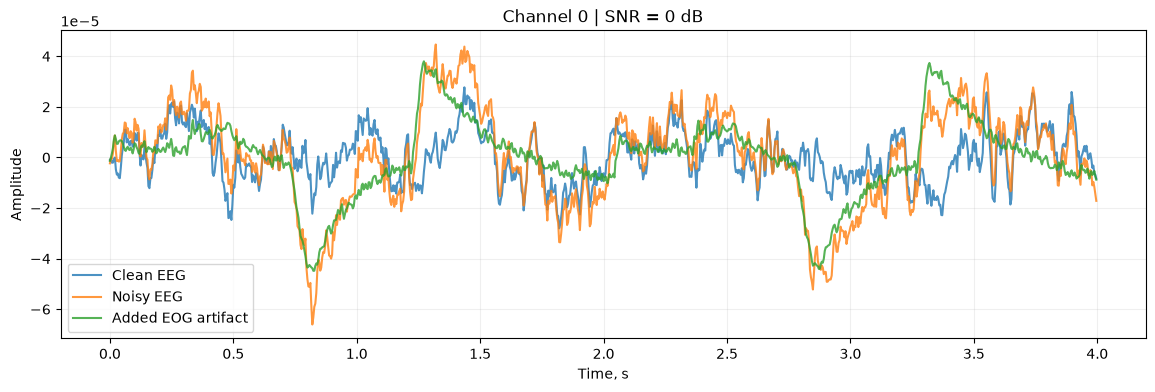

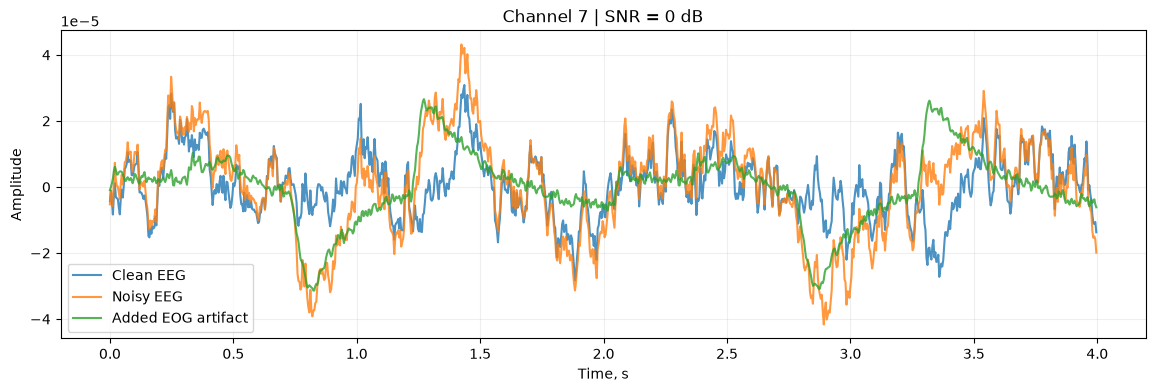

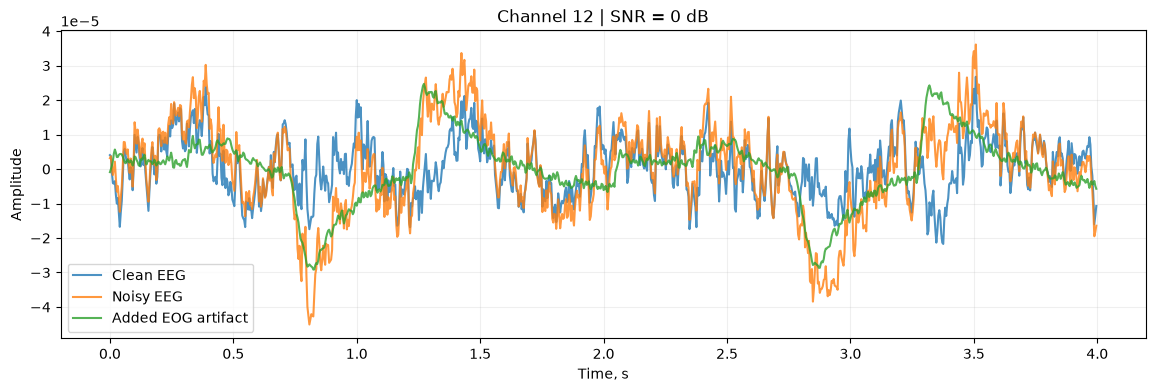

In [393]:
channels_to_plot = [0, 7, 12]

time = np.arange(clean_trial.shape[1]) / 250

for ch in channels_to_plot:
    plt.figure(figsize=(14, 4))

    plt.plot(
        time,
        clean_trial[ch],
        label="Clean EEG",
        alpha=0.8
    )

    plt.plot(
        time,
        noisy_trial[ch],
        label="Noisy EEG",
        alpha=0.8
    )

    plt.plot(
        time,
        added_artifact[ch],
        label="Added EOG artifact",
        alpha=0.8
    )

    plt.title(f"Channel {ch} | SNR = 0 dB")
    plt.xlabel("Time, s")
    plt.ylabel("Amplitude")
    plt.legend()
    plt.grid(alpha=0.2)

    plt.show()

насколько загрязнение испортило сигнал


In [394]:
rmse_noisy = np.sqrt(
    np.mean(
        (noisy_trial - clean_trial) ** 2
    )
)

mae_noisy = np.mean(
    np.abs(
        noisy_trial - clean_trial
    )
)

print(
    f"RMSE noisy vs clean: {rmse_noisy:.6e}"
)

print(
    f"MAE noisy vs clean:  {mae_noisy:.6e}"
)

RMSE noisy vs clean: 1.025480e-05
MAE noisy vs clean:  6.900928e-06


А затем уже самое важное: загрязним весь A01 при 0 dB, но каждый trial разными кусками EOG, чтобы не копировать один и тот же артефакт везде.

Вот функция:

In [395]:


def contaminate_epochs_with_eog(
    X,
    hf_dataset,
    snr_db=0
):
    X_noisy = np.zeros_like(
        X,
        dtype=np.float32
    )

    artifacts = np.zeros_like(
        X,
        dtype=np.float32
    )

    for i in range(len(X)):

        artifact_1d = make_artifact_signal(
            hf_dataset,
            target_length=X.shape[2],
            start_idx=i * 2
        )

        artifact_multi = make_multichannel_eog(
            artifact_1d
        )

        noisy, artifact_scaled = add_artifact_at_snr(
            X[i],
            artifact_multi,
            snr_db=snr_db
        )

        X_noisy[i] = noisy
        artifacts[i] = artifact_scaled

        if (i + 1) % 25 == 0:
            print(
                f"Processed {i+1}/{len(X)}"
            )

    return X_noisy, artifacts

И применяем отдельно к train / val / test:

In [396]:


X_train_eog0, artifact_train_eog0 = (
    contaminate_epochs_with_eog(
        X_train_raw,
        EOG_train,
        snr_db=0
    )
)

X_val_eog0, artifact_val_eog0 = (
    contaminate_epochs_with_eog(
        X_val_raw,
        EOG_train,
        snr_db=0
    )
)

X_test_eog0, artifact_test_eog0 = (
    contaminate_epochs_with_eog(
        X_test_raw,
        EOG_train,
        snr_db=0
    )
)

Processed 25/230
Processed 50/230
Processed 75/230
Processed 100/230
Processed 125/230
Processed 150/230
Processed 175/230
Processed 200/230
Processed 225/230
Processed 25/58
Processed 50/58
Processed 25/288
Processed 50/288
Processed 75/288
Processed 100/288
Processed 125/288
Processed 150/288
Processed 175/288
Processed 200/288
Processed 225/288
Processed 250/288
Processed 275/288


Потом проверим средний фактический SNR на всём A01:

In [397]:


def mean_dataset_snr(
    X_clean,
    artifacts
):
    snrs = []

    for i in range(len(X_clean)):
        snrs.append(
            calculate_snr_db(
                X_clean[i],
                artifacts[i]
            )
        )

    return np.mean(snrs), np.std(snrs)


mean_snr, std_snr = mean_dataset_snr(
    X_test_raw,
    artifact_test_eog0
)

print(
    f"Mean test SNR: {mean_snr:.3f} ± {std_snr:.3f} dB"
)

Mean test SNR: -0.046 ± 0.009 dB


7. Подготавливаем noisy EEG точно так же, как baseline

Чтобы сравнение было честным, preprocessing оставляем тем же самым:

In [398]:


def prepare_noisy_for_classifier(
    X_train_noisy,
    X_val_noisy,
    X_test_noisy
):
    # 1. Per-trial standardization
    X_train_std = per_trial_standardize(
        X_train_noisy
    )

    X_val_std = per_trial_standardize(
        X_val_noisy
    )

    X_test_std = per_trial_standardize(
        X_test_noisy
    )

    # 2. EA для train/val
    R_train = ea_reference(
        X_train_std
    )

    W_train = inverse_sqrt_matrix(
        R_train
    )

    X_train_ea = apply_ea(
        X_train_std,
        W_train
    )

    X_val_ea = apply_ea(
        X_val_std,
        W_train
    )

    # 3. Отдельный label-free EA для test
    R_test = ea_reference(
        X_test_std
    )

    W_test = inverse_sqrt_matrix(
        R_test
    )

    X_test_ea = apply_ea(
        X_test_std,
        W_test
    )

    # 4. Глобальная нормализация
    # статистики только по train
    mean = np.float32(
        X_train_ea.mean()
    )

    std = np.float32(
        X_train_ea.std()
    ) + 1e-8

    X_train_ea = (
        X_train_ea - mean
    ) / std

    X_val_ea = (
        X_val_ea - mean
    ) / std

    X_test_ea = (
        X_test_ea - mean
    ) / std

    return (
        X_train_ea.astype(np.float32),
        X_val_ea.astype(np.float32),
        X_test_ea.astype(np.float32)
    )

Применяем:

In [399]:


(
    X_train_eog0_ea,
    X_val_eog0_ea,
    X_test_eog0_ea
) = prepare_noisy_for_classifier(
    X_train_eog0,
    X_val_eog0,
    X_test_eog0
)

print(
    X_train_eog0_ea.shape,
    X_val_eog0_ea.shape,
    X_test_eog0_ea.shape
)

(230, 22, 1000) (58, 22, 1000) (288, 22, 1000)


8. Обучаем классификатор на загрязнённом A01

Важно: мы сейчас не применяем denoising вообще.

In [400]:


set_seed(42)

eog0_result = finetune_exact_eegnet_v2(
    pretrained_exact_model,

    X_train_eog0_ea,
    y_train_subj,

    X_val_eog0_ea,
    y_val_subj,

    X_test_eog0_ea,
    y_test_subj,

    num_epochs=500,
    batch_size=64,
    learning_rate=5e-3,
    patience=150
)

Device: cpu
Epoch  25 | Val acc: 0.948 | Val loss: 0.5620 | Best: 0.966
Epoch  50 | Val acc: 0.948 | Val loss: 0.5088 | Best: 0.966
Epoch  75 | Val acc: 0.897 | Val loss: 0.5500 | Best: 0.966
Epoch 100 | Val acc: 0.914 | Val loss: 0.5760 | Best: 0.966
Epoch 125 | Val acc: 0.879 | Val loss: 0.5804 | Best: 0.966
Epoch 150 | Val acc: 0.897 | Val loss: 0.6140 | Best: 0.966
Epoch 175 | Val acc: 0.914 | Val loss: 0.5999 | Best: 0.966

Early stopping at epoch 195

Best validation accuracy: 0.966
Best validation loss: 0.4919
Best epoch: 45

Test accuracy: 0.851
Balanced accuracy: 0.851
Macro F1: 0.849
Kappa: 0.801


И вывод:


In [401]:

print(
    "Clean A01 baseline:",
    0.872
)

print(
    "EOG 0 dB accuracy:",
    eog0_result["accuracy"]
)

print(
    "EOG 0 dB balanced accuracy:",
    eog0_result["balanced_accuracy"]
)

print(
    "EOG 0 dB Macro F1:",
    eog0_result["macro_f1"]
)

print(
    "EOG 0 dB Kappa:",
    eog0_result["kappa"]
)

Clean A01 baseline: 0.872
EOG 0 dB accuracy: 0.8506944444444444
EOG 0 dB balanced accuracy: 0.8506944444444445
EOG 0 dB Macro F1: 0.8489137898091569
EOG 0 dB Kappa: 0.8009259259259259


наш EOG 0 dB оказался слишком лёгким испытанием для классификатора.


Один EOG — слишком узкий сценарий. Для нормального controlled benchmark лучше иметь несколько типов артефактов, потому что разные методы могут по-разному справляться с медленными глазными и быстрыми мышечными помехами.

У нас уже есть два естественных источника из EEGdenoiseNet: EOG и EMG. Я бы сделала три сценария загрязнения:

только EOG;
только EMG;
смесь EOG + EMG.

функция для смеси логика простая:
сделаем локальные артефакты, а не непрерывные на все 4 секунды.

In [402]:

def make_mixed_artifact(
    eog_artifact,
    emg_artifact,
    eog_weight=0.5,
    emg_weight=0.5
):
    mixed = (
        eog_weight * eog_artifact
        + emg_weight * emg_artifact
    )

    mixed = mixed - mixed.mean()

    return mixed.astype(np.float32)

не три отдельных ручных эксперимента, а одну общую функцию, которая умеет загрязнять EEG тремя способами:

EOG

EMG

EOG+EMG

И пока оставим SNR = 0 dB, чтобы сравнить именно тип артефакта, а не силу.

функция для EMG

In [403]:
def make_multichannel_emg(
    artifact_1d,
    n_channels=22,
    seed=42
):
    rng = np.random.default_rng(seed)

    # Для EMG не делаем один плавный фронтальный профиль.
    # Даём каналам разные веса.
    channel_weights = rng.uniform(
        0.4,
        1.0,
        size=n_channels
    ).astype(np.float32)

    return (
        channel_weights[:, None]
        * artifact_1d[None, :]
    ).astype(np.float32)

Теперь общая функция, которая умеет создавать EOG, EMG или смесь:


In [404]:


def make_artifact_for_trial(
    artifact_type,
    target_length,
    eog_dataset,
    emg_dataset,
    start_idx=0,
    seed=42
):
    if artifact_type == "EOG":

        eog_1d = make_artifact_signal(
            eog_dataset,
            target_length=target_length,
            start_idx=start_idx
        )

        artifact = make_multichannel_eog(
            eog_1d
        )

    elif artifact_type == "EMG":

        emg_1d = make_artifact_signal(
            emg_dataset,
            target_length=target_length,
            start_idx=start_idx
        )

        artifact = make_multichannel_emg(
            emg_1d,
            n_channels=22,
            seed=seed + start_idx
        )

    elif artifact_type == "EOG+EMG":

        eog_1d = make_artifact_signal(
            eog_dataset,
            target_length=target_length,
            start_idx=start_idx
        )

        emg_1d = make_artifact_signal(
            emg_dataset,
            target_length=target_length,
            start_idx=start_idx + 100
        )

        eog_multi = make_multichannel_eog(
            eog_1d
        )

        emg_multi = make_multichannel_emg(
            emg_1d,
            n_channels=22,
            seed=seed + start_idx
        )

        artifact = (
            0.5 * eog_multi
            + 0.5 * emg_multi
        )

    else:
        raise ValueError(
            "artifact_type must be "
            "'EOG', 'EMG' or 'EOG+EMG'"
        )

    return artifact.astype(np.float32)

Теперь загрязняем весь набор:

In [405]:


def contaminate_epochs(
    X,
    artifact_type,
    eog_dataset,
    emg_dataset,
    snr_db=0,
    seed=42
):
    X_noisy = np.zeros_like(
        X,
        dtype=np.float32
    )

    artifacts = np.zeros_like(
        X,
        dtype=np.float32
    )

    for i in range(len(X)):

        artifact = make_artifact_for_trial(
            artifact_type=artifact_type,
            target_length=X.shape[2],
            eog_dataset=eog_dataset,
            emg_dataset=emg_dataset,
            start_idx=i * 2,
            seed=seed
        )

        noisy, artifact_scaled = add_artifact_at_snr(
            X[i],
            artifact,
            snr_db=snr_db
        )

        X_noisy[i] = noisy
        artifacts[i] = artifact_scaled

        if (i + 1) % 25 == 0:
            print(
                f"{artifact_type}: "
                f"{i+1}/{len(X)}"
            )

    return X_noisy, artifacts

Теперь можно прогнать три сценария на A01:

In [406]:


artifact_types = [
    "EOG",
    "EMG",
    "EOG+EMG"
]

artifact_results = []

for artifact_type in artifact_types:

    print("\n" + "=" * 70)
    print(
        f"{artifact_type} | SNR = 0 dB"
    )
    print("=" * 70)

    X_train_noisy, _ = contaminate_epochs(
        X_train_raw,
        artifact_type,
        EOG_train,
        EMG_train,
        snr_db=0
    )

    X_val_noisy, _ = contaminate_epochs(
        X_val_raw,
        artifact_type,
        EOG_train,
        EMG_train,
        snr_db=0
    )

    X_test_noisy, _ = contaminate_epochs(
        X_test_raw,
        artifact_type,
        EOG_train,
        EMG_train,
        snr_db=0
    )

    (
        X_train_noisy_ea,
        X_val_noisy_ea,
        X_test_noisy_ea
    ) = prepare_noisy_for_classifier(
        X_train_noisy,
        X_val_noisy,
        X_test_noisy
    )

    set_seed(42)

    result = finetune_exact_eegnet_v2(
        pretrained_exact_model,

        X_train_noisy_ea,
        y_train_subj,

        X_val_noisy_ea,
        y_val_subj,

        X_test_noisy_ea,
        y_test_subj,

        num_epochs=500,
        batch_size=64,
        learning_rate=5e-3,
        patience=150
    )

    artifact_results.append({
        "artifact": artifact_type,
        "snr_db": 0,
        "accuracy": result["accuracy"],
        "balanced_accuracy": result["balanced_accuracy"],
        "macro_f1": result["macro_f1"],
        "kappa": result["kappa"]
    })


EOG | SNR = 0 dB
EOG: 25/230
EOG: 50/230
EOG: 75/230
EOG: 100/230
EOG: 125/230
EOG: 150/230
EOG: 175/230
EOG: 200/230
EOG: 225/230
EOG: 25/58
EOG: 50/58
EOG: 25/288
EOG: 50/288
EOG: 75/288
EOG: 100/288
EOG: 125/288
EOG: 150/288
EOG: 175/288
EOG: 200/288
EOG: 225/288
EOG: 250/288
EOG: 275/288
Device: cpu
Epoch  25 | Val acc: 0.948 | Val loss: 0.5620 | Best: 0.966
Epoch  50 | Val acc: 0.948 | Val loss: 0.5088 | Best: 0.966
Epoch  75 | Val acc: 0.897 | Val loss: 0.5500 | Best: 0.966
Epoch 100 | Val acc: 0.914 | Val loss: 0.5760 | Best: 0.966
Epoch 125 | Val acc: 0.879 | Val loss: 0.5804 | Best: 0.966
Epoch 150 | Val acc: 0.897 | Val loss: 0.6140 | Best: 0.966
Epoch 175 | Val acc: 0.914 | Val loss: 0.5999 | Best: 0.966

Early stopping at epoch 195

Best validation accuracy: 0.966
Best validation loss: 0.4919
Best epoch: 45

Test accuracy: 0.851
Balanced accuracy: 0.851
Macro F1: 0.849
Kappa: 0.801

EMG | SNR = 0 dB
EMG: 25/230
EMG: 50/230
EMG: 75/230
EMG: 100/230
EMG: 125/230
EMG: 150/230

Потом таблица:

In [407]:


artifact_results_df = pd.DataFrame(
    artifact_results
)

display(
    artifact_results_df.round(3)
)

,artifact,snr_db,accuracy,balanced_accuracy,macro_f1,kappa
0,EOG,0,0.851,0.851,0.849,0.801
1,EMG,0,0.691,0.691,0.689,0.588
2,EOG+EMG,0,0.785,0.785,0.783,0.713


И добавим clean baseline:

In [408]:


comparison_artifacts_df = pd.concat([
    pd.DataFrame({
        "artifact": ["Clean"],
        "snr_db": [np.nan],
        "accuracy": [0.872],
        "balanced_accuracy": [0.872],
        "macro_f1": [np.nan],
        "kappa": [np.nan]
    }),

    artifact_results_df
], ignore_index=True)

display(
    comparison_artifacts_df.round(3)
)

,artifact,snr_db,accuracy,balanced_accuracy,macro_f1,kappa
0,Clean,NaN,0.872,0.872,NaN,NaN
1,EOG,0.0,0.851,0.851,0.849,0.801
2,EMG,0.0,0.691,0.691,0.689,0.588
3,EOG+EMG,0.0,0.785,0.785,0.783,0.713


EOG+EMG как основной сценарий выглядит разумнее, потому что он проверяет denoiser не на одном типе помехи, а на более смешанном и реалистичном загрязнении.

сохранить смешанный набор под отдельными именами:

In [409]:


X_train_mix0, artifact_train_mix0 = contaminate_epochs(
    X_train_raw,
    artifact_type="EOG+EMG",
    eog_dataset=EOG_train,
    emg_dataset=EMG_train,
    snr_db=0
)

X_val_mix0, artifact_val_mix0 = contaminate_epochs(
    X_val_raw,
    artifact_type="EOG+EMG",
    eog_dataset=EOG_train,
    emg_dataset=EMG_train,
    snr_db=0
)

X_test_mix0, artifact_test_mix0 = contaminate_epochs(
    X_test_raw,
    artifact_type="EOG+EMG",
    eog_dataset=EOG_train,
    emg_dataset=EMG_train,
    snr_db=0
)

EOG+EMG: 25/230
EOG+EMG: 50/230
EOG+EMG: 75/230
EOG+EMG: 100/230
EOG+EMG: 125/230
EOG+EMG: 150/230
EOG+EMG: 175/230
EOG+EMG: 200/230
EOG+EMG: 225/230
EOG+EMG: 25/58
EOG+EMG: 50/58
EOG+EMG: 25/288
EOG+EMG: 50/288
EOG+EMG: 75/288
EOG+EMG: 100/288
EOG+EMG: 125/288
EOG+EMG: 150/288
EOG+EMG: 175/288
EOG+EMG: 200/288
EOG+EMG: 225/288
EOG+EMG: 250/288
EOG+EMG: 275/288


In [411]:
mean_snr, std_snr = mean_dataset_snr(
    X_test_raw,
    artifact_test_mix0
)

print(
    f"EOG+EMG test SNR: "
    f"{mean_snr:.3f} ± {std_snr:.3f} dB"
)

EOG+EMG test SNR: -0.046 ± 0.009 dB


Noisy без очистки → CNN → MSSA rank=300 → RDMSSA на всех 9 испытуемых

небольшой helper для CNN. Он использует наш уже обученный combined_model и функцию denoise_1d_signal_overlap, которой мы раньше чистили BCI:

In [416]:
device = next(
    combined_model.parameters()
).device

print("CNN model device:", device)

CNN model device: mps:0


In [417]:
def cnn_denoise_epochs(
    X,
    model,
    window_size=512,
    step=256
):
    device = next(
        model.parameters()
    ).device

    print(
        "CNN device:",
        device
    )

    X_out = np.zeros_like(
        X,
        dtype=np.float32
    )

    for i in range(len(X)):

        for ch in range(X.shape[1]):

            X_out[i, ch] = denoise_1d_signal_overlap(
                X[i, ch],
                model,
                window_size=window_size,
                step=step,
                device=device
            )

        if (i + 1) % 25 == 0:
            print(
                f"CNN denoising: {i+1}/{len(X)}"
            )

    return X_out

In [418]:
import os
import gc
import pandas as pd
import numpy as np
import torch

BASE_DIR = "/Users/irina/Desktop/master project"

SNR_DB = 0

MSSA_RANK = 300
MSSA_WINDOW = 100

RDMSSA_RANK = 300
RDMSSA_WINDOW = 100
RDMSSA_DAMPING = 4

CORR_WINDOW = 100
CORR_STEP = 50
ALPHA_MAX = 0.5

SAVE_PATH = os.path.join(
    BASE_DIR,
    "mixed_eog_emg_denoising_results.csv"
)


all_mixed_results = []


for subject_num in range(1, 10):

    subject = f"A{subject_num:02d}"

    print("\n\n")
    print("#" * 80)
    print(
        f"SUBJECT {subject}"
    )
    print("#" * 80)

    train_file = os.path.join(
        BASE_DIR,
        "BCICIV_2a_gdf",
        f"{subject}T.gdf"
    )

    eval_file = os.path.join(
        BASE_DIR,
        "BCICIV_2a_gdf",
        f"{subject}E.gdf"
    )

    labels_file = os.path.join(
        BASE_DIR,
        "true_labels",
        f"{subject}E.mat"
    )


    # ============================================================
    # 1. LOAD CLEAN DATA
    # ============================================================

    print("\n--- Loading clean EEG ---")

    (
        X_train_clean,
        X_val_clean,
        X_test_clean,
        y_train,
        y_val,
        y_test
    ) = prepare_subject_for_denoising(
        train_file,
        eval_file,
        labels_file
    )


    # ============================================================
    # 2. ADD MIXED EOG + EMG, SNR = 0 dB
    # ============================================================

    print(
        "\n--- Creating EOG+EMG contamination ---"
    )

    X_train_noisy, artifact_train = contaminate_epochs(
        X_train_clean,
        artifact_type="EOG+EMG",
        eog_dataset=EOG_train,
        emg_dataset=EMG_train,
        snr_db=SNR_DB,
        seed=42
    )

    X_val_noisy, artifact_val = contaminate_epochs(
        X_val_clean,
        artifact_type="EOG+EMG",
        eog_dataset=EOG_train,
        emg_dataset=EMG_train,
        snr_db=SNR_DB,
        seed=43
    )

    X_test_noisy, artifact_test = contaminate_epochs(
        X_test_clean,
        artifact_type="EOG+EMG",
        eog_dataset=EOG_train,
        emg_dataset=EMG_train,
        snr_db=SNR_DB,
        seed=44
    )


    test_snr_mean, test_snr_std = mean_dataset_snr(
        X_test_clean,
        artifact_test
    )

    print(
        f"\nActual test SNR: "
        f"{test_snr_mean:.3f} "
        f"± {test_snr_std:.3f} dB"
    )


    # ============================================================
    # HELPER: CLASSIFICATION
    # ============================================================

    def evaluate_variant(
        method_name,
        X_train_variant,
        X_val_variant,
        X_test_variant
    ):

        print("\n")
        print("=" * 70)
        print(
            f"{subject} | {method_name}"
        )
        print("=" * 70)

        (
            X_train_ready,
            X_val_ready,
            X_test_ready
        ) = prepare_noisy_for_classifier(
            X_train_variant,
            X_val_variant,
            X_test_variant
        )

        set_seed(42)

        result = finetune_exact_eegnet_v2(
            pretrained_exact_model,

            X_train_ready,
            y_train,

            X_val_ready,
            y_val,

            X_test_ready,
            y_test,

            num_epochs=500,
            batch_size=64,
            learning_rate=5e-3,
            patience=150
        )

        all_mixed_results.append({
            "subject": subject,
            "method": method_name,
            "snr_db": SNR_DB,

            "accuracy": result["accuracy"],
            "balanced_accuracy":
                result["balanced_accuracy"],
            "macro_f1":
                result["macro_f1"],
            "kappa":
                result["kappa"],

            "best_val_accuracy":
                result["best_val_accuracy"],
            "best_epoch":
                result["best_epoch"],

            "actual_test_snr":
                test_snr_mean
        })

        # сохраняем после КАЖДОГО метода
        pd.DataFrame(
            all_mixed_results
        ).to_csv(
            SAVE_PATH,
            index=False
        )

        print(
            f"\nSaved → {SAVE_PATH}"
        )

        del (
            X_train_ready,
            X_val_ready,
            X_test_ready
        )

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

        return result


    # ============================================================
    # 3. NOISY — NO DENOISING
    # ============================================================

    noisy_result = evaluate_variant(
        "Noisy",
        X_train_noisy,
        X_val_noisy,
        X_test_noisy
    )


    # ============================================================
    # 4. CNN DENOISING
    # ============================================================

    print(
        "\n--- CNN denoising ---"
    )

    X_train_cnn = cnn_denoise_epochs(
    X_train_noisy,
    combined_model,
    )
    


    X_val_cnn = cnn_denoise_epochs(
        X_val_noisy,
        combined_model
    )

    X_test_cnn = cnn_denoise_epochs(
        X_test_noisy,
        combined_model
    )


    cnn_result = evaluate_variant(
        "CNN",
        X_train_cnn,
        X_val_cnn,
        X_test_cnn
    )

    del (
        X_train_cnn,
        X_val_cnn,
        X_test_cnn
    )

    gc.collect()


    # ============================================================
    # 5. MSSA rank = 300
    # ============================================================

    print(
        "\n--- MSSA denoising ---"
    )

    X_train_mssa = mssa_denoise_epochs(
        X_train_noisy,
        window_length=MSSA_WINDOW,
        rank=MSSA_RANK
    )

    X_val_mssa = mssa_denoise_epochs(
        X_val_noisy,
        window_length=MSSA_WINDOW,
        rank=MSSA_RANK
    )

    X_test_mssa = mssa_denoise_epochs(
        X_test_noisy,
        window_length=MSSA_WINDOW,
        rank=MSSA_RANK
    )


    mssa_result = evaluate_variant(
        "MSSA",
        X_train_mssa,
        X_val_mssa,
        X_test_mssa
    )

    del (
        X_train_mssa,
        X_val_mssa,
        X_test_mssa
    )

    gc.collect()


    # ============================================================
    # 6. RDMSSA + ADAPTIVE CORRECTION
    # ============================================================

    print(
        "\n--- RDMSSA + adaptive correction ---"
    )

    X_train_rdmssa, _ = (
        rdmssa_adaptive_denoise_epochs(
            X_train_noisy,

            window_length=RDMSSA_WINDOW,
            rank=RDMSSA_RANK,
            damping_factor=RDMSSA_DAMPING,

            correction_window=CORR_WINDOW,
            correction_step=CORR_STEP,
            alpha_max=ALPHA_MAX
        )
    )

    X_val_rdmssa, _ = (
        rdmssa_adaptive_denoise_epochs(
            X_val_noisy,

            window_length=RDMSSA_WINDOW,
            rank=RDMSSA_RANK,
            damping_factor=RDMSSA_DAMPING,

            correction_window=CORR_WINDOW,
            correction_step=CORR_STEP,
            alpha_max=ALPHA_MAX
        )
    )

    X_test_rdmssa, _ = (
        rdmssa_adaptive_denoise_epochs(
            X_test_noisy,

            window_length=RDMSSA_WINDOW,
            rank=RDMSSA_RANK,
            damping_factor=RDMSSA_DAMPING,

            correction_window=CORR_WINDOW,
            correction_step=CORR_STEP,
            alpha_max=ALPHA_MAX
        )
    )


    rdmssa_result = evaluate_variant(
        "RDMSSA",
        X_train_rdmssa,
        X_val_rdmssa,
        X_test_rdmssa
    )

    del (
        X_train_rdmssa,
        X_val_rdmssa,
        X_test_rdmssa
    )


    # ============================================================
    # CLEAN MEMORY BEFORE NEXT SUBJECT
    # ============================================================

    del (
        X_train_clean,
        X_val_clean,
        X_test_clean,

        X_train_noisy,
        X_val_noisy,
        X_test_noisy,

        artifact_train,
        artifact_val,
        artifact_test
    )

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


    print(
        f"\n✅ {subject} COMPLETE"
    )

    print(
        f"Noisy   : {noisy_result['accuracy']:.3f}"
    )

    print(
        f"CNN     : {cnn_result['accuracy']:.3f}"
    )

    print(
        f"MSSA    : {mssa_result['accuracy']:.3f}"
    )

    print(
        f"RDMSSA  : {rdmssa_result['accuracy']:.3f}"
    )


print("\n\n")
print("#" * 80)
print("ALL SUBJECTS COMPLETE")
print("#" * 80)




################################################################################
SUBJECT A01
################################################################################

--- Loading clean EEG ---


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)



--- Creating EOG+EMG contamination ---
EOG+EMG: 25/230
EOG+EMG: 50/230
EOG+EMG: 75/230
EOG+EMG: 100/230
EOG+EMG: 125/230
EOG+EMG: 150/230
EOG+EMG: 175/230
EOG+EMG: 200/230
EOG+EMG: 225/230
EOG+EMG: 25/58
EOG+EMG: 50/58
EOG+EMG: 25/288
EOG+EMG: 50/288
EOG+EMG: 75/288
EOG+EMG: 100/288
EOG+EMG: 125/288
EOG+EMG: 150/288
EOG+EMG: 175/288
EOG+EMG: 200/288
EOG+EMG: 225/288
EOG+EMG: 250/288
EOG+EMG: 275/288

Actual test SNR: -0.046 ± 0.009 dB


A01 | Noisy
Device: cpu
Epoch  25 | Val acc: 0.741 | Val loss: 0.8025 | Best: 0.741
Epoch  50 | Val acc: 0.828 | Val loss: 0.7435 | Best: 0.862
Epoch  75 | Val acc: 0.828 | Val loss: 0.7549 | Best: 0.879
Epoch 100 | Val acc: 0.759 | Val loss: 0.7842 | Best: 0.879
Epoch 125 | Val acc: 0.759 | Val loss: 0.7410 | Best: 0.879
Epoch 150 | Val acc: 0.845 | Val loss: 0.7920 | Best: 0.879
Epoch 175 | Val acc: 0.810 | Val loss: 0.7993 | Best: 0.879
Epoch 200 | Val acc: 0.810 | Val loss: 0.7717 | Best: 0.879

Early stopping at epoch 212

Best validation accuracy

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)



--- Creating EOG+EMG contamination ---
EOG+EMG: 25/230
EOG+EMG: 50/230
EOG+EMG: 75/230
EOG+EMG: 100/230
EOG+EMG: 125/230
EOG+EMG: 150/230
EOG+EMG: 175/230
EOG+EMG: 200/230
EOG+EMG: 225/230
EOG+EMG: 25/58
EOG+EMG: 50/58
EOG+EMG: 25/288
EOG+EMG: 50/288
EOG+EMG: 75/288
EOG+EMG: 100/288
EOG+EMG: 125/288
EOG+EMG: 150/288
EOG+EMG: 175/288
EOG+EMG: 200/288
EOG+EMG: 225/288
EOG+EMG: 250/288
EOG+EMG: 275/288

Actual test SNR: -0.033 ± 0.019 dB


A02 | Noisy
Device: cpu
Epoch  25 | Val acc: 0.500 | Val loss: 1.1509 | Best: 0.517
Epoch  50 | Val acc: 0.638 | Val loss: 1.0310 | Best: 0.638
Epoch  75 | Val acc: 0.638 | Val loss: 1.0509 | Best: 0.655
Epoch 100 | Val acc: 0.569 | Val loss: 1.1361 | Best: 0.655
Epoch 125 | Val acc: 0.552 | Val loss: 1.1761 | Best: 0.672
Epoch 150 | Val acc: 0.552 | Val loss: 1.2660 | Best: 0.672
Epoch 175 | Val acc: 0.500 | Val loss: 1.2455 | Best: 0.672
Epoch 200 | Val acc: 0.517 | Val loss: 1.2090 | Best: 0.672
Epoch 225 | Val acc: 0.500 | Val loss: 1.1287 | Best: 

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


... (9 outputs left out)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)



--- Creating EOG+EMG contamination ---
EOG+EMG: 25/230
EOG+EMG: 50/230
EOG+EMG: 75/230
EOG+EMG: 100/230
EOG+EMG: 125/230
EOG+EMG: 150/230
EOG+EMG: 175/230
EOG+EMG: 200/230
EOG+EMG: 225/230
EOG+EMG: 25/58
EOG+EMG: 50/58
EOG+EMG: 25/288
EOG+EMG: 50/288
EOG+EMG: 75/288
EOG+EMG: 100/288
EOG+EMG: 125/288
EOG+EMG: 150/288
EOG+EMG: 175/288
EOG+EMG: 200/288
EOG+EMG: 225/288
EOG+EMG: 250/288
EOG+EMG: 275/288

Actual test SNR: -0.030 ± 0.006 dB


A08 | Noisy
Device: cpu
Epoch  25 | Val acc: 0.793 | Val loss: 0.7443 | Best: 0.828
Epoch  50 | Val acc: 0.879 | Val loss: 0.6157 | Best: 0.879
Epoch  75 | Val acc: 0.845 | Val loss: 0.6472 | Best: 0.931
Epoch 100 | Val acc: 0.845 | Val loss: 0.6582 | Best: 0.931
Epoch 125 | Val acc: 0.793 | Val loss: 0.6868 | Best: 0.931
Epoch 150 | Val acc: 0.776 | Val loss: 0.8138 | Best: 0.931
Epoch 175 | Val acc: 0.845 | Val loss: 0.7743 | Best: 0.931
Epoch 200 | Val acc: 0.845 | Val loss: 0.6874 | Best: 0.931

Early stopping at epoch 219

Best validation accuracy

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)



--- Creating EOG+EMG contamination ---
EOG+EMG: 25/230
EOG+EMG: 50/230
EOG+EMG: 75/230
EOG+EMG: 100/230
EOG+EMG: 125/230
EOG+EMG: 150/230
EOG+EMG: 175/230
EOG+EMG: 200/230
EOG+EMG: 225/230
EOG+EMG: 25/58
EOG+EMG: 50/58
EOG+EMG: 25/288
EOG+EMG: 50/288
EOG+EMG: 75/288
EOG+EMG: 100/288
EOG+EMG: 125/288
EOG+EMG: 150/288
EOG+EMG: 175/288
EOG+EMG: 200/288
EOG+EMG: 225/288
EOG+EMG: 250/288
EOG+EMG: 275/288

Actual test SNR: -0.024 ± 0.006 dB


A09 | Noisy
Device: cpu
Epoch  25 | Val acc: 0.879 | Val loss: 0.6985 | Best: 0.879
Epoch  50 | Val acc: 0.810 | Val loss: 0.6627 | Best: 0.914
Epoch  75 | Val acc: 0.845 | Val loss: 0.6642 | Best: 0.914
Epoch 100 | Val acc: 0.828 | Val loss: 0.7188 | Best: 0.914
Epoch 125 | Val acc: 0.776 | Val loss: 0.7354 | Best: 0.914
Epoch 150 | Val acc: 0.741 | Val loss: 0.8269 | Best: 0.914
Epoch 175 | Val acc: 0.828 | Val loss: 0.7398 | Best: 0.914

Early stopping at epoch 191

Best validation accuracy: 0.914
Best validation loss: 0.6536
Best epoch: 41

Test ac

In [420]:
mixed_results_df = pd.read_csv(
    "/Users/irina/Desktop/master project/mixed_eog_emg_denoising_results.csv"
)

mixed_accuracy_table = (
    mixed_results_df
    .pivot(
        index="subject",
        columns="method",
        values="accuracy"
    )
    .reset_index()
)

display(
    mixed_accuracy_table.round(3)
)

method,subject,CNN,MSSA,Noisy,RDMSSA
0,A01,0.743,0.767,0.785,0.781
1,A02,0.521,0.455,0.476,0.465
2,A03,0.892,0.875,0.854,0.840
3,A04,0.573,0.545,0.594,0.580
4,A05,0.604,0.566,0.608,0.569
5,A06,0.559,0.608,0.628,0.604
6,A07,0.705,0.472,0.701,0.747
7,A08,0.809,0.809,0.819,0.826
8,A09,0.778,0.788,0.785,0.799


In [421]:
clean_vs_mixed = (
    exact_results_df[
        ["subject", "accuracy"]
    ]
    .rename(
        columns={
            "accuracy": "Clean"
        }
    )
    .merge(
        mixed_accuracy_table,
        on="subject"
    )
)

display(
    clean_vs_mixed.round(3)
)

print("\nMean accuracy:")

display(
    clean_vs_mixed[
        [
            "Clean",
            "Noisy",
            "CNN",
            "MSSA",
            "RDMSSA"
        ]
    ]
    .mean()
    .round(3)
)

,subject,Clean,CNN,MSSA,Noisy,RDMSSA
0,A01,0.872,0.743,0.767,0.785,0.781
1,A02,0.608,0.521,0.455,0.476,0.465
2,A03,0.948,0.892,0.875,0.854,0.840
3,A04,0.740,0.573,0.545,0.594,0.580
4,A05,0.750,0.604,0.566,0.608,0.569
5,A06,0.646,0.559,0.608,0.628,0.604
6,A07,0.899,0.705,0.472,0.701,0.747
7,A08,0.819,0.809,0.809,0.819,0.826
8,A09,0.840,0.778,0.788,0.785,0.799



Mean accuracy:


Clean     0.791
Noisy     0.694
CNN       0.687
MSSA      0.654
RDMSSA    0.690
dtype: float64

Искусственное загрязнение снизило среднюю accuracy примерно на 9.7 процентных
пункта, однако ни один из методов денойзинга в среднем не восстановил исходное
качество классификации.

При этом для отдельных испытуемых наблюдалось улучшение после денойзинга
(например, CNN для A03 и RDMSSA для A07/A09), что указывает на выраженную
межсубъектную вариативность.

Однако в данном эксперименте классификатор повторно обучался отдельно на каждом
варианте данных: noisy, CNN-denoised, MSSA-denoised и RDMSSA-denoised.
Следовательно, результат отражает одновременно качество денойзинга и способность
классификатора адаптироваться к новому представлению EEG.

Поэтому такой эксперимент не позволяет напрямую ответить на вопрос,
восстанавливает ли denoiser полезную motor-imagery информацию, потерянную
после добавления артефактов.

## Эксперимент с фиксированным downstream-классификатором

Для более прямой оценки денойзинга классификатор будет обучаться только на
исходной clean EEG.

После обучения веса классификатора фиксируются. Один и тот же классификатор
используется для оценки:

1. Clean test EEG
2. Noisy EOG+EMG test EEG
3. CNN-denoised test EEG
4. MSSA-denoised test EEG
5. RDMSSA-denoised test EEG

Таким образом, классификатор больше не может адаптироваться к особенностям
конкретного метода денойзинга.

Если после загрязнения accuracy уменьшается, а после денойзинга возрастает,
это будет означать, что метод действительно восстанавливает структуру сигнала,
полезную для уже обученного motor-imagery classifier.

Дополнительно качество восстановления будет оцениваться непосредственно
относительно известной clean EEG с помощью:

- RMSE
- MAE
- SNR до и после денойзинга
- downstream Accuracy
- Balanced Accuracy
- Macro-F1
- Cohen's kappa

Clean train

    ↓

обучение EEGNet

    ↓

фиксированный classifier

    ↓

    ├── Clean test

    ├── Noisy test

    ├── Noisy → CNN

    ├── Noisy → MSSA
    
    └── Noisy → RDMSSA

для A01–A09:

Clean AxxT
    ↓
train/val
    ↓
fine-tune classifier один раз
    ↓
freeze

AxxE clean
    ↓ + EOG+EMG 0 dB
AxxE noisy
    ↓
CNN / MSSA / RDMSSA
    ↓
один и тот же frozen classifier

+ RMSE / MAE / SNR для каждого denoiser

Классификатор обучается только на исходной clean EEG и после обучения фиксируется.

Далее один и тот же классификатор используется для оценки clean EEG,
искусственно загрязнённой EOG+EMG EEG и сигналов после различных методов
денойзинга.

Такой дизайн исключает адаптацию классификатора к конкретному способу обработки
и позволяет оценивать, восстанавливает ли denoiser информацию, полезную для
motor-imagery classification.


1. Функции для фиксированного классификатора

Эта версия сама сохраняет лучшие веса по validation accuracy и возвращает модель, которую потом не обучаем.

In [437]:


import copy
import gc
import os

import numpy as np
import pandas as pd
import torch

from torch.utils.data import TensorDataset, DataLoader


def to_eegnet_tensor(X):

    X = np.asarray(
        X,
        dtype=np.float32
    )

    # Если данные имеют форму:
    # (N, 1, 22, 1000)
    #
    # убираем лишнюю размерность:
    # -> (N, 22, 1000)

    if (
        X.ndim == 4
        and X.shape[1] == 1
    ):
        X = X[:, 0, :, :]

    # Проверяем, что получили ожидаемую форму
    if X.ndim != 3:
        raise ValueError(
            f"Expected EEG shape "
            f"(N, channels, time), "
            f"got {X.shape}"
        )

    return torch.tensor(
        X,
        dtype=torch.float32
    )

def train_clean_classifier(
    pretrained_model,
    X_train,
    y_train,
    X_val,
    y_val,
    num_epochs=500,
    batch_size=64,
    learning_rate=5e-3,
    patience=150,
    seed=42
):

    set_seed(seed)

    # Для UnifiedEEGNet используем CPU:
    # AdaptivePool в этой архитектуре
    # не поддерживается корректно на MPS
    device = torch.device("cpu")

    print(
        "Classifier device:",
        device
    )

    model = copy.deepcopy(
        pretrained_model
    ).to(device)


    train_ds = TensorDataset(
        to_eegnet_tensor(X_train),
        torch.tensor(
            y_train,
            dtype=torch.long
        )
    )

    val_ds = TensorDataset(
        to_eegnet_tensor(X_val),
        torch.tensor(
            y_val,
            dtype=torch.long
        )
    )

    train_loader = DataLoader(
        train_ds,
        batch_size=batch_size,
        shuffle=True
    )

    val_loader = DataLoader(
        val_ds,
        batch_size=batch_size,
        shuffle=False
    )

    criterion = torch.nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    best_val_acc = -np.inf
    best_val_loss = np.inf
    best_epoch = 0
    best_state = None

    epochs_without_improvement = 0

    for epoch in range(1, num_epochs + 1):

        # ============================
        # TRAIN
        # ============================

        model.train()

        for xb, yb in train_loader:

            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()

            logits = model(xb)

            if isinstance(logits, tuple):
                logits = logits[0]

            loss = criterion(
                logits,
                yb
            )

            loss.backward()
            optimizer.step()

        # ============================
        # VALIDATION
        # ============================

        model.eval()

        val_correct = 0
        val_total = 0
        val_loss_sum = 0.0

        with torch.no_grad():

            for xb, yb in val_loader:

                xb = xb.to(device)
                yb = yb.to(device)

                logits = model(xb)

                if isinstance(logits, tuple):
                    logits = logits[0]

                loss = criterion(
                    logits,
                    yb
                )

                pred = logits.argmax(
                    dim=1
                )

                val_correct += (
                    pred == yb
                ).sum().item()

                val_total += len(yb)

                val_loss_sum += (
                    loss.item() * len(yb)
                )

        val_acc = (
            val_correct / val_total
        )

        val_loss = (
            val_loss_sum / val_total
        )

        if val_acc > best_val_acc:

            best_val_acc = val_acc
            best_val_loss = val_loss
            best_epoch = epoch

            best_state = copy.deepcopy(
                model.state_dict()
            )

            epochs_without_improvement = 0

        else:
            epochs_without_improvement += 1

        if epoch % 25 == 0:

            print(
                f"Epoch {epoch:3d} | "
                f"Val acc: {val_acc:.3f} | "
                f"Best: {best_val_acc:.3f}"
            )

        if (
            epochs_without_improvement
            >= patience
        ):

            print(
                f"Early stopping "
                f"at epoch {epoch}"
            )

            break

    model.load_state_dict(
        best_state
    )

    model.eval()

    print(
        f"Best val accuracy: "
        f"{best_val_acc:.3f}"
    )

    print(
        f"Best epoch: "
        f"{best_epoch}"
    )

    return (
        model,
        device,
        best_val_acc,
        best_val_loss,
        best_epoch
    )

2. Оценка одной и той же frozen-модели

In [423]:

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    cohen_kappa_score
)


def evaluate_frozen_classifier(
    model,
    device,
    X,
    y,
    batch_size=64
):

    ds = TensorDataset(
        to_eegnet_tensor(X),
        torch.tensor(
            y,
            dtype=torch.long
        )
    )

    loader = DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=False
    )

    preds = []

    model.eval()

    with torch.no_grad():

        for xb, _ in loader:

            xb = xb.to(device)

            logits = model(xb)

            if isinstance(logits, tuple):
                logits = logits[0]

            pred = (
                logits
                .argmax(dim=1)
                .cpu()
                .numpy()
            )

            preds.extend(pred)

    preds = np.asarray(preds)

    return {
        "accuracy":
            accuracy_score(
                y,
                preds
            ),

        "balanced_accuracy":
            balanced_accuracy_score(
                y,
                preds
            ),

        "macro_f1":
            f1_score(
                y,
                preds,
                average="macro"
            ),

        "kappa":
            cohen_kappa_score(
                y,
                preds
            )
    }

3. Метрики восстановления самого сигнала

Здесь очень важно: теперь clean EEG нам известна, поэтому можем честно считать ошибку реконструкции.


In [424]:


def reconstruction_metrics(
    clean,
    restored
):
    clean64 = np.asarray(
        clean,
        dtype=np.float64
    )

    restored64 = np.asarray(
        restored,
        dtype=np.float64
    )

    error = (
        restored64
        - clean64
    )

    rmse = np.sqrt(
        np.mean(
            error ** 2
        )
    )

    mae = np.mean(
        np.abs(error)
    )

    signal_power = np.mean(
        clean64 ** 2
    )

    error_power = np.mean(
        error ** 2
    )

    snr = 10 * np.log10(
        signal_power
        /
        (
            error_power
            + 1e-20
        )
    )

    return {
        "rmse": rmse,
        "mae": mae,
        "snr_reconstruction_db": snr
    }

In [427]:
def fit_clean_preprocessing(
    X_train_clean
):
    X_train_std = per_trial_standardize(
        X_train_clean
    )

    R_train = ea_reference(
        X_train_std
    )

    W_train = inverse_sqrt_matrix(
        R_train
    )

    X_train_ea = apply_ea(
        X_train_std,
        W_train
    )

    global_mean = np.float32(
        X_train_ea.mean()
    )

    global_std = (
        np.float32(
            X_train_ea.std()
        )
        + 1e-8
    )

    return (
        W_train,
        global_mean,
        global_std
    )


def apply_fixed_preprocessing(
    X,
    W_train,
    global_mean,
    global_std
):
    X_std = per_trial_standardize(
        X
    )

    X_ea = apply_ea(
        X_std,
        W_train
    )

    X_ready = (
        X_ea
        - global_mean
    ) / global_std

    return X_ready.astype(
        np.float32
    )

In [428]:
print(fit_clean_preprocessing)
print(apply_fixed_preprocessing)


<function fit_clean_preprocessing at 0x307408ae0>
<function apply_fixed_preprocessing at 0x307408b80>


In [429]:
required_functions = [
    "fit_clean_preprocessing",
    "apply_fixed_preprocessing",
    "train_clean_classifier",
    "evaluate_frozen_classifier",
    "reconstruction_metrics",
    "cnn_denoise_epochs",
    "contaminate_epochs",
    "mssa_denoise_epochs",
    "rdmssa_adaptive_denoise_epochs"
]

for name in required_functions:
    print(
        name,
        "OK" if name in globals() else "MISSING"
    )

fit_clean_preprocessing OK
apply_fixed_preprocessing OK
train_clean_classifier OK
evaluate_frozen_classifier OK
reconstruction_metrics OK
cnn_denoise_epochs OK
contaminate_epochs OK
mssa_denoise_epochs OK
rdmssa_adaptive_denoise_epochs OK


In [438]:
test_tensor = to_eegnet_tensor(
    X_train_raw[:4]
)

print(
    "Tensor shape:",
    test_tensor.shape
)

test_device = torch.device("cpu")

test_model = copy.deepcopy(
    pretrained_exact_model
).to(test_device)

with torch.no_grad():

    out = test_model(
        test_tensor.to(test_device)
    )

print(
    "Output shape:",
    out.shape
)

Tensor shape: torch.Size([4, 22, 1000])
Output shape: torch.Size([4, 4])


In [440]:
print(
    "train:",
    X_train_ready.shape,
    "val:",
    X_val_ready.shape
)

print(
    "y_train:",
    len(y_train),
    "y_val:",
    len(y_val)
)


train: (230, 22, 1000) val: (58, 22, 1000)
y_train: 230 y_val: 58


In [441]:
print(
    "clean train:",
    X_train_clean.shape,
    "clean val:",
    X_val_clean.shape
)

clean train: (230, 22, 1000) clean val: (58, 22, 1000)


In [442]:
required = [
    "fit_clean_preprocessing",
    "apply_fixed_preprocessing",
    "train_clean_classifier",
    "evaluate_frozen_classifier",
    "reconstruction_metrics",
    "contaminate_epochs",
    "cnn_denoise_epochs",
    "mssa_denoise_epochs",
    "rdmssa_adaptive_denoise_epochs"
]

for name in required:
    print(
        name,
        "OK" if name in globals() else "MISSING"
    )

fit_clean_preprocessing OK
apply_fixed_preprocessing OK
train_clean_classifier OK
evaluate_frozen_classifier OK
reconstruction_metrics OK
contaminate_epochs OK
cnn_denoise_epochs OK
mssa_denoise_epochs OK
rdmssa_adaptive_denoise_epochs OK


основная ячейка.



clean train → classifier → freeze → clean/noisy/CNN/MSSA/RDMSSA test

и после каждого метода сохраняет CSV.

In [443]:
BASE_DIR = "/Users/irina/Desktop/master project"

SAVE_PATH = os.path.join(
    BASE_DIR,
    "fixed_classifier_denoising_results.csv"
)

SNR_DB = 0

MSSA_RANK = 300
MSSA_WINDOW = 100

RDMSSA_RANK = 300
RDMSSA_WINDOW = 100
RDMSSA_DAMPING = 4

CORR_WINDOW = 100
CORR_STEP = 50
ALPHA_MAX = 0.5


fixed_results = []


for subject_num in range(1, 10):

    subject = f"A{subject_num:02d}"

    print("\n\n")
    print("#" * 80)
    print(f"SUBJECT {subject}")
    print("#" * 80)


    train_file = os.path.join(
        BASE_DIR,
        "BCICIV_2a_gdf",
        f"{subject}T.gdf"
    )

    eval_file = os.path.join(
        BASE_DIR,
        "BCICIV_2a_gdf",
        f"{subject}E.gdf"
    )

    labels_file = os.path.join(
        BASE_DIR,
        "true_labels",
        f"{subject}E.mat"
    )


    # ==========================================================
    # 1. LOAD CLEAN DATA
    # ==========================================================

    print("\n--- Loading clean EEG ---")

    (
        X_train_clean,
        X_val_clean,
        X_test_clean,
        y_train,
        y_val,
        y_test
    ) = prepare_subject_for_denoising(
        train_file,
        eval_file,
        labels_file
    )

    print("Train:", X_train_clean.shape)
    print("Val:", X_val_clean.shape)
    print("Test:", X_test_clean.shape)


    # ==========================================================
    # 2. FIT PREPROCESSING ON CLEAN TRAIN ONLY
    # ==========================================================

    print("\n--- Fitting clean preprocessing ---")

    (
        W_train,
        global_mean,
        global_std
    ) = fit_clean_preprocessing(
        X_train_clean
    )

    X_train_ready = apply_fixed_preprocessing(
        X_train_clean,
        W_train,
        global_mean,
        global_std
    )

    X_val_ready = apply_fixed_preprocessing(
        X_val_clean,
        W_train,
        global_mean,
        global_std
    )


    # ==========================================================
    # 3. TRAIN CLEAN CLASSIFIER
    # ==========================================================

    print("\n--- Training clean classifier ---")

    (
        clean_model,
        classifier_device,
        best_val_acc,
        best_val_loss,
        best_epoch
    ) = train_clean_classifier(
        pretrained_exact_model,

        X_train_ready,
        y_train,

        X_val_ready,
        y_val,

        num_epochs=500,
        batch_size=64,
        learning_rate=5e-3,
        patience=150,
        seed=42
    )


    # ==========================================================
    # 4. CLEAN TEST
    # ==========================================================

    print("\n--- Clean test ---")

    X_test_clean_ready = apply_fixed_preprocessing(
        X_test_clean,
        W_train,
        global_mean,
        global_std
    )

    clean_result = evaluate_frozen_classifier(
        clean_model,
        classifier_device,
        X_test_clean_ready,
        y_test
    )

    fixed_results.append({
        "subject": subject,
        "method": "Clean",

        **clean_result,

        "target_snr_db": np.nan,
        "actual_snr_db": np.nan,

        "rmse": 0.0,
        "mae": 0.0,
        "snr_reconstruction_db": np.inf,

        "best_val_accuracy": best_val_acc,
        "best_val_loss": best_val_loss,
        "best_epoch": best_epoch
    })

    pd.DataFrame(
        fixed_results
    ).to_csv(
        SAVE_PATH,
        index=False
    )

    print(
        f"{subject} | Clean accuracy: "
        f"{clean_result['accuracy']:.3f}"
    )


    # ==========================================================
    # 5. CREATE EOG + EMG NOISY TEST
    # ==========================================================

    print("\n--- Creating EOG+EMG noisy test ---")

    (
        X_test_noisy,
        artifact_test
    ) = contaminate_epochs(
        X_test_clean,

        artifact_type="EOG+EMG",

        eog_dataset=EOG_train,
        emg_dataset=EMG_train,

        snr_db=SNR_DB,
        seed=44
    )

    actual_snr_mean, actual_snr_std = mean_dataset_snr(
        X_test_clean,
        artifact_test
    )

    print(
        f"Actual test SNR: "
        f"{actual_snr_mean:.3f} "
        f"± {actual_snr_std:.3f} dB"
    )


    # ==========================================================
    # 6. NOISY
    # ==========================================================

    X_noisy_ready = apply_fixed_preprocessing(
        X_test_noisy,
        W_train,
        global_mean,
        global_std
    )

    noisy_cls = evaluate_frozen_classifier(
        clean_model,
        classifier_device,
        X_noisy_ready,
        y_test
    )

    noisy_rec = reconstruction_metrics(
        X_test_clean,
        X_test_noisy
    )

    noisy_result = {
        "subject": subject,
        "method": "Noisy",

        "target_snr_db": SNR_DB,
        "actual_snr_db": actual_snr_mean,

        **noisy_cls,
        **noisy_rec,

        "best_val_accuracy": best_val_acc,
        "best_val_loss": best_val_loss,
        "best_epoch": best_epoch
    }

    fixed_results.append(
        noisy_result
    )

    pd.DataFrame(
        fixed_results
    ).to_csv(
        SAVE_PATH,
        index=False
    )

    print(
        f"{subject} | Noisy accuracy: "
        f"{noisy_result['accuracy']:.3f}"
    )


    # ==========================================================
    # 7. CNN
    # ==========================================================

    print("\n--- CNN denoising ---")

    X_test_cnn = cnn_denoise_epochs(
        X_test_noisy,
        combined_model
    )

    X_cnn_ready = apply_fixed_preprocessing(
        X_test_cnn,
        W_train,
        global_mean,
        global_std
    )

    cnn_cls = evaluate_frozen_classifier(
        clean_model,
        classifier_device,
        X_cnn_ready,
        y_test
    )

    cnn_rec = reconstruction_metrics(
        X_test_clean,
        X_test_cnn
    )

    cnn_result = {
        "subject": subject,
        "method": "CNN",

        "target_snr_db": SNR_DB,
        "actual_snr_db": actual_snr_mean,

        **cnn_cls,
        **cnn_rec,

        "best_val_accuracy": best_val_acc,
        "best_val_loss": best_val_loss,
        "best_epoch": best_epoch
    }

    fixed_results.append(
        cnn_result
    )

    pd.DataFrame(
        fixed_results
    ).to_csv(
        SAVE_PATH,
        index=False
    )

    print(
        f"{subject} | CNN accuracy: "
        f"{cnn_result['accuracy']:.3f}"
    )

    del (
        X_test_cnn,
        X_cnn_ready
    )

    gc.collect()


    # ==========================================================
    # 8. MSSA
    # ==========================================================

    print("\n--- MSSA denoising ---")

    X_test_mssa = mssa_denoise_epochs(
        X_test_noisy,
        window_length=MSSA_WINDOW,
        rank=MSSA_RANK
    )

    X_mssa_ready = apply_fixed_preprocessing(
        X_test_mssa,
        W_train,
        global_mean,
        global_std
    )

    mssa_cls = evaluate_frozen_classifier(
        clean_model,
        classifier_device,
        X_mssa_ready,
        y_test
    )

    mssa_rec = reconstruction_metrics(
        X_test_clean,
        X_test_mssa
    )

    mssa_result = {
        "subject": subject,
        "method": "MSSA",

        "target_snr_db": SNR_DB,
        "actual_snr_db": actual_snr_mean,

        **mssa_cls,
        **mssa_rec,

        "best_val_accuracy": best_val_acc,
        "best_val_loss": best_val_loss,
        "best_epoch": best_epoch
    }

    fixed_results.append(
        mssa_result
    )

    pd.DataFrame(
        fixed_results
    ).to_csv(
        SAVE_PATH,
        index=False
    )

    print(
        f"{subject} | MSSA accuracy: "
        f"{mssa_result['accuracy']:.3f}"
    )

    del (
        X_test_mssa,
        X_mssa_ready
    )

    gc.collect()


    # ==========================================================
    # 9. RDMSSA
    # ==========================================================

    print("\n--- RDMSSA denoising ---")

    (
        X_test_rdmssa,
        alpha_values
    ) = rdmssa_adaptive_denoise_epochs(
        X_test_noisy,

        window_length=RDMSSA_WINDOW,
        rank=RDMSSA_RANK,
        damping_factor=RDMSSA_DAMPING,

        correction_window=CORR_WINDOW,
        correction_step=CORR_STEP,
        alpha_max=ALPHA_MAX
    )

    X_rdmssa_ready = apply_fixed_preprocessing(
        X_test_rdmssa,
        W_train,
        global_mean,
        global_std
    )

    rdmssa_cls = evaluate_frozen_classifier(
        clean_model,
        classifier_device,
        X_rdmssa_ready,
        y_test
    )

    rdmssa_rec = reconstruction_metrics(
        X_test_clean,
        X_test_rdmssa
    )

    rdmssa_result = {
        "subject": subject,
        "method": "RDMSSA",

        "target_snr_db": SNR_DB,
        "actual_snr_db": actual_snr_mean,

        **rdmssa_cls,
        **rdmssa_rec,

        "best_val_accuracy": best_val_acc,
        "best_val_loss": best_val_loss,
        "best_epoch": best_epoch
    }

    fixed_results.append(
        rdmssa_result
    )

    pd.DataFrame(
        fixed_results
    ).to_csv(
        SAVE_PATH,
        index=False
    )

    print(
        f"{subject} | RDMSSA accuracy: "
        f"{rdmssa_result['accuracy']:.3f}"
    )


    # ==========================================================
    # 10. SUBJECT SUMMARY
    # ==========================================================

    print("\n")
    print("=" * 80)
    print(f"✅ {subject} COMPLETE")
    print("=" * 80)

    print(
        "Clean  :",
        round(
            clean_result["accuracy"],
            3
        )
    )

    print(
        "Noisy  :",
        round(
            noisy_result["accuracy"],
            3
        )
    )

    print(
        "CNN    :",
        round(
            cnn_result["accuracy"],
            3
        )
    )

    print(
        "MSSA   :",
        round(
            mssa_result["accuracy"],
            3
        )
    )

    print(
        "RDMSSA :",
        round(
            rdmssa_result["accuracy"],
            3
        )
    )


    # ==========================================================
    # 11. CLEAN MEMORY
    # ==========================================================

    del (
        X_train_clean,
        X_val_clean,
        X_test_clean,

        X_test_noisy,
        artifact_test,

        X_train_ready,
        X_val_ready,
        X_test_clean_ready,
        X_noisy_ready,

        X_test_rdmssa,
        X_rdmssa_ready,
        alpha_values,

        clean_model
    )

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    if torch.backends.mps.is_available():
        try:
            torch.mps.empty_cache()
        except Exception:
            pass


# ============================================================
# DONE
# ============================================================

pd.DataFrame(
    fixed_results
).to_csv(
    SAVE_PATH,
    index=False
)

print("\n")
print("#" * 80)
print("ALL SUBJECTS COMPLETE")
print("#" * 80)

print(
    f"\nFinal results saved → "
    f"{SAVE_PATH}"
)




################################################################################
SUBJECT A01
################################################################################

--- Loading clean EEG ---


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Train: (230, 22, 1000)
Val: (58, 22, 1000)
Test: (288, 22, 1000)

--- Fitting clean preprocessing ---

--- Training clean classifier ---
Classifier device: cpu
Epoch  25 | Val acc: 0.879 | Best: 0.983
Epoch  50 | Val acc: 0.862 | Best: 0.983
Epoch  75 | Val acc: 0.897 | Best: 0.983
Epoch 100 | Val acc: 0.897 | Best: 0.983
Epoch 125 | Val acc: 0.897 | Best: 0.983
Epoch 150 | Val acc: 0.914 | Best: 0.983
Early stopping at epoch 163
Best val accuracy: 0.983
Best epoch: 13

--- Clean test ---
A01 | Clean accuracy: 0.858

--- Creating EOG+EMG noisy test ---
EOG+EMG: 25/288
EOG+EMG: 50/288
EOG+EMG: 75/288
EOG+EMG: 100/288
EOG+EMG: 125/288
EOG+EMG: 150/288
EOG+EMG: 175/288
EOG+EMG: 200/288
EOG+EMG: 225/288
EOG+EMG: 250/288
EOG+EMG: 275/288
Actual test SNR: -0.046 ± 0.009 dB
A01 | Noisy accuracy: 0.535

--- CNN denoising ---
CNN device: mps:0
CNN denoising: 25/288
CNN denoising: 50/288
CNN denoising: 75/288
CNN denoising: 100/288
CNN denoising: 125/288
CNN denoising: 150/288
CNN denoising: 175

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Train: (230, 22, 1000)
Val: (58, 22, 1000)
Test: (288, 22, 1000)

--- Fitting clean preprocessing ---

--- Training clean classifier ---
Classifier device: cpu
Epoch  25 | Val acc: 0.810 | Best: 0.862
Epoch  50 | Val acc: 0.776 | Best: 0.862
Epoch  75 | Val acc: 0.741 | Best: 0.862
Epoch 100 | Val acc: 0.793 | Best: 0.862
Epoch 125 | Val acc: 0.741 | Best: 0.862
Epoch 150 | Val acc: 0.793 | Best: 0.862
Early stopping at epoch 156
Best val accuracy: 0.862
Best epoch: 6

--- Clean test ---
A02 | Clean accuracy: 0.434

--- Creating EOG+EMG noisy test ---
EOG+EMG: 25/288
EOG+EMG: 50/288
EOG+EMG: 75/288
EOG+EMG: 100/288
EOG+EMG: 125/288
EOG+EMG: 150/288
EOG+EMG: 175/288
EOG+EMG: 200/288
EOG+EMG: 225/288
EOG+EMG: 250/288
EOG+EMG: 275/288
Actual test SNR: -0.033 ± 0.019 dB
A02 | Noisy accuracy: 0.340

--- CNN denoising ---
CNN device: mps:0
CNN denoising: 25/288
CNN denoising: 50/288
CNN denoising: 75/288
CNN denoising: 100/288
CNN denoising: 125/288
CNN denoising: 150/288
CNN denoising: 175/

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


... (9 outputs left out)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Train: (230, 22, 1000)
Val: (58, 22, 1000)
Test: (288, 22, 1000)

--- Fitting clean preprocessing ---

--- Training clean classifier ---
Classifier device: cpu
Epoch  25 | Val acc: 0.862 | Best: 0.931
Epoch  50 | Val acc: 0.897 | Best: 0.931
Epoch  75 | Val acc: 0.845 | Best: 0.931
Epoch 100 | Val acc: 0.828 | Best: 0.931
Epoch 125 | Val acc: 0.879 | Best: 0.931
Epoch 150 | Val acc: 0.914 | Best: 0.931
Early stopping at epoch 169
Best val accuracy: 0.931
Best epoch: 19

--- Clean test ---
A08 | Clean accuracy: 0.830

--- Creating EOG+EMG noisy test ---
EOG+EMG: 25/288
EOG+EMG: 50/288
EOG+EMG: 75/288
EOG+EMG: 100/288
EOG+EMG: 125/288
EOG+EMG: 150/288
EOG+EMG: 175/288
EOG+EMG: 200/288
EOG+EMG: 225/288
EOG+EMG: 250/288
EOG+EMG: 275/288
Actual test SNR: -0.030 ± 0.006 dB
A08 | Noisy accuracy: 0.479

--- CNN denoising ---
CNN device: mps:0
CNN denoising: 25/288
CNN denoising: 50/288
CNN denoising: 75/288
CNN denoising: 100/288
CNN denoising: 125/288
CNN denoising: 150/288
CNN denoising: 175

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Train: (230, 22, 1000)
Val: (58, 22, 1000)
Test: (288, 22, 1000)

--- Fitting clean preprocessing ---

--- Training clean classifier ---
Classifier device: cpu
Epoch  25 | Val acc: 0.897 | Best: 0.966
Epoch  50 | Val acc: 0.914 | Best: 0.983
Epoch  75 | Val acc: 0.897 | Best: 0.983
Epoch 100 | Val acc: 0.948 | Best: 0.983
Epoch 125 | Val acc: 0.914 | Best: 0.983
Epoch 150 | Val acc: 0.914 | Best: 0.983
Epoch 175 | Val acc: 0.828 | Best: 0.983
Early stopping at epoch 187
Best val accuracy: 0.983
Best epoch: 37

--- Clean test ---
A09 | Clean accuracy: 0.722

--- Creating EOG+EMG noisy test ---
EOG+EMG: 25/288
EOG+EMG: 50/288
EOG+EMG: 75/288
EOG+EMG: 100/288
EOG+EMG: 125/288
EOG+EMG: 150/288
EOG+EMG: 175/288
EOG+EMG: 200/288
EOG+EMG: 225/288
EOG+EMG: 250/288
EOG+EMG: 275/288
Actual test SNR: -0.024 ± 0.006 dB
A09 | Noisy accuracy: 0.545

--- CNN denoising ---
CNN device: mps:0
CNN denoising: 25/288
CNN denoising: 50/288
CNN denoising: 75/288
CNN denoising: 100/288
CNN denoising: 125/288


In [444]:
fixed_results_df = pd.read_csv(
    "/Users/irina/Desktop/master project/"
    "fixed_classifier_denoising_results.csv"
)

accuracy_table = (
    fixed_results_df
    .pivot(
        index="subject",
        columns="method",
        values="accuracy"
    )
    .reset_index()
)

display(
    accuracy_table.round(3)
)

print("\nMean accuracy:")

display(
    fixed_results_df
    .groupby("method")[
        [
            "accuracy",
            "balanced_accuracy",
            "macro_f1",
            "kappa",
            "rmse",
            "mae",
            "snr_reconstruction_db"
        ]
    ]
    .mean()
    .round(3)
)

method,subject,CNN,Clean,MSSA,Noisy,RDMSSA
0,A01,0.681,0.858,0.542,0.535,0.545
1,A02,0.368,0.434,0.333,0.340,0.333
2,A03,0.747,0.913,0.778,0.743,0.792
3,A04,0.427,0.576,0.365,0.372,0.375
4,A05,0.490,0.531,0.413,0.417,0.410
5,A06,0.392,0.597,0.486,0.483,0.483
6,A07,0.330,0.712,0.677,0.660,0.670
7,A08,0.681,0.830,0.524,0.479,0.531
8,A09,0.618,0.722,0.556,0.545,0.556



Mean accuracy:


,accuracy,balanced_accuracy,macro_f1,kappa,rmse,mae,snr_reconstruction_db
method,,,,,,,
CNN,0.526,0.526,0.495,0.368,0.0,0.0,3.238
Clean,0.686,0.686,0.682,0.581,0.0,0.0,inf
MSSA,0.519,0.519,0.502,0.359,0.0,0.0,-0.014
Noisy,0.508,0.508,0.487,0.344,0.0,0.0,-0.000
RDMSSA,0.522,0.522,0.505,0.362,0.0,0.0,-0.016


In [445]:
recovery_table = (
    accuracy_table.copy()
)

for method in [
    "CNN",
    "MSSA",
    "RDMSSA"
]:

    recovery_table[
        f"{method}_gain"
    ] = (
        recovery_table[method]
        - recovery_table["Noisy"]
    )

display(
    recovery_table.round(3)
)

print(
    "\nMean gain over Noisy:"
)

display(
    recovery_table[
        [
            "CNN_gain",
            "MSSA_gain",
            "RDMSSA_gain"
        ]
    ]
    .mean()
    .round(3)
)

method,subject,CNN,Clean,MSSA,Noisy,RDMSSA,CNN_gain,MSSA_gain,RDMSSA_gain
0,A01,0.681,0.858,0.542,0.535,0.545,0.146,0.007,0.010
1,A02,0.368,0.434,0.333,0.340,0.333,0.028,-0.007,-0.007
2,A03,0.747,0.913,0.778,0.743,0.792,0.003,0.035,0.049
3,A04,0.427,0.576,0.365,0.372,0.375,0.056,-0.007,0.003
4,A05,0.490,0.531,0.413,0.417,0.410,0.073,-0.003,-0.007
5,A06,0.392,0.597,0.486,0.483,0.483,-0.090,0.003,0.000
6,A07,0.330,0.712,0.677,0.660,0.670,-0.330,0.017,0.010
7,A08,0.681,0.830,0.524,0.479,0.531,0.201,0.045,0.052
8,A09,0.618,0.722,0.556,0.545,0.556,0.073,0.010,0.010



Mean gain over Noisy:


method
CNN_gain       0.018
MSSA_gain      0.011
RDMSSA_gain    0.014
dtype: float64

При фиксированном классификаторе, обученном только на clean EEG, искусственное загрязнение EOG+EMG снизило среднюю accuracy с 0.686 до 0.508. Все исследованные методы денойзинга в среднем частично восстанавливали downstream performance. Наибольший прирост показал CNN-denoiser (+1.8 п.п. относительно noisy), затем RDMSSA (+1.4 п.п.) и MSSA (+1.1 п.п.). CNN также показал наибольшее улучшение reconstruction SNR (+3.24 dB), в то время как MSSA и RDMSSA практически не улучшали сигнал по этой метрике. При этом эффект сильно различался между субъектами, что указывает на выраженную межсубъектную вариативность эффективности денойзинга.

## Предобучение denoiser на искусственно загрязнённой motor-imagery EEG

На предыдущем этапе было показано, что при фиксированном downstream-классификаторе
искусственные EOG+EMG-артефакты существенно снижают качество классификации,
а denoising способен частично восстановить потерянную информацию.

Далее обучается собственная supervised-модель денойзинга непосредственно
на motor-imagery EEG.

В качестве clean target используется исходная EEG из BCI Competition IV 2a.
Во время обучения к ней добавляются реальные EOG и EMG артефакты при различных
уровнях SNR.

AxxE-сессии не используются для обучения denoiser и остаются независимыми
для последующей оценки.

1. Сначала соберём clean train и validation по всем 9 субъектам

Берём только AxxT.

In [446]:


all_clean_train = []
all_clean_val = []

for subject_num in range(1, 10):

    subject = f"A{subject_num:02d}"

    print(
        f"Loading {subject}"
    )

    train_file = (
        f"/Users/irina/Desktop/master project/"
        f"BCICIV_2a_gdf/{subject}T.gdf"
    )

    eval_file = (
        f"/Users/irina/Desktop/master project/"
        f"BCICIV_2a_gdf/{subject}E.gdf"
    )

    labels_file = (
        f"/Users/irina/Desktop/master project/"
        f"true_labels/{subject}E.mat"
    )

    (
        X_train,
        X_val,
        _,
        _,
        _,
        _
    ) = prepare_subject_for_denoising(
        train_file,
        eval_file,
        labels_file
    )

    all_clean_train.append(
        X_train
    )

    all_clean_val.append(
        X_val
    )


X_denoiser_train = np.concatenate(
    all_clean_train,
    axis=0
)

X_denoiser_val = np.concatenate(
    all_clean_val,
    axis=0
)

print(
    "Train:",
    X_denoiser_train.shape
)

print(
    "Val:",
    X_denoiser_val.shape
)

Loading A01


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Loading A02


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Loading A03


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


... (9 outputs left out)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Loading A09


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Train: (2070, 22, 1000)
Val: (522, 22, 1000)


2. На этот раз не будем всегда делать 0 dB

Для pretraining лучше дать модели артефакты разной силы.

Тогда нейросеть не выучит только один фиксированный уровень загрязнения.

Сделаем PyTorch Dataset, который создаёт новое загрязнение прямо во время обучения.


In [447]:

from torch.utils.data import Dataset


class BCISyntheticArtifactDataset(Dataset):

    def __init__(
        self,
        clean_epochs,
        eog_dataset,
        emg_dataset,
        snr_min=-5,
        snr_max=5,
        seed=42
    ):

        self.clean_epochs = clean_epochs
        self.eog_dataset = eog_dataset
        self.emg_dataset = emg_dataset

        self.snr_min = snr_min
        self.snr_max = snr_max

        self.seed = seed


    def __len__(self):

        return len(
            self.clean_epochs
        )


    def __getitem__(self, idx):

        clean = np.asarray(
            self.clean_epochs[idx],
            dtype=np.float32
        )

        rng = np.random.default_rng(
            self.seed
            + idx
            + np.random.randint(
                0,
                1_000_000
            )
        )

        snr_db = rng.uniform(
            self.snr_min,
            self.snr_max
        )

        artifact_idx = rng.integers(
            0,
            min(
                len(self.eog_dataset),
                len(self.emg_dataset)
            )
            - 200
        )

        artifact = make_artifact_for_trial(
            artifact_type="EOG+EMG",

            target_length=
                clean.shape[-1],

            eog_dataset=
                self.eog_dataset,

            emg_dataset=
                self.emg_dataset,

            start_idx=
                int(artifact_idx),

            seed=
                int(
                    self.seed
                    + idx
                )
        )

        noisy, _ = add_artifact_at_snr(
            clean,
            artifact,
            snr_db=snr_db
        )

        # Нормируем каждую эпоху относительно clean,
        # чтобы модель не зависела от физического масштаба в вольтах

        scale = (
            clean.std()
            + 1e-8
        )

        clean_norm = (
            clean / scale
        )

        noisy_norm = (
            noisy / scale
        )

        return (
            torch.tensor(
                noisy_norm,
                dtype=torch.float32
            ),

            torch.tensor(
                clean_norm,
                dtype=torch.float32
            ),

            torch.tensor(
                scale,
                dtype=torch.float32
            ),

            torch.tensor(
                snr_db,
                dtype=torch.float32
            )
        )

3. Создаём train/validation Dataset

In [448]:

denoiser_train_ds = (
    BCISyntheticArtifactDataset(
        X_denoiser_train,
        EOG_train,
        EMG_train,

        snr_min=-5,
        snr_max=5,

        seed=42
    )
)


denoiser_val_ds = (
    BCISyntheticArtifactDataset(
        X_denoiser_val,
        EOG_train,
        EMG_train,

        snr_min=-5,
        snr_max=5,

        seed=123
    )
)

Проверяем один пример:

In [449]:


noisy_example, clean_example, scale, snr = (
    denoiser_train_ds[0]
)

print(
    "Noisy:",
    noisy_example.shape
)

print(
    "Clean:",
    clean_example.shape
)

print(
    "SNR:",
    snr.item()
)

print(
    "Scale:",
    scale.item()
)

Noisy: torch.Size([22, 1000])
Clean: torch.Size([22, 1000])
SNR: -4.7912373542785645
Scale: 1.0252432730339933e-05


Архитектура новой модели гораздо интереснее сделать:



22 EEG channels

      ↓

spatial + temporal encoder

      ↓

residual estimation

      ↓
      
22 restored channels

То есть multichannel residual denoiser, который одновременно видит все 22 канала. Это намного логичнее и для EOG, и для EMG, и для дальнейшего переноса на другой датасет.

## Multichannel residual denoiser

В отличие от предыдущего одноканального CNN, новая модель обрабатывает
все 22 EEG-канала одновременно.

Это позволяет использовать не только временную структуру сигнала,
но и пространственные зависимости между электродами.

Модель предсказывает не clean EEG напрямую, а добавленный шум:

noise_hat = f(noisy)

После чего восстановленный сигнал вычисляется как:

clean_hat = noisy - noise_hat

1. Модель

In [451]:

import torch
import torch.nn as nn


class MultichannelResidualDenoiser(nn.Module):

    def __init__(
        self,
        n_channels=22,
        hidden=64
    ):
        super().__init__()

        self.net = nn.Sequential(

            nn.Conv1d(
                n_channels,
                hidden,
                kernel_size=9,
                padding=4
            ),
            nn.BatchNorm1d(hidden),
            nn.GELU(),

            nn.Conv1d(
                hidden,
                hidden,
                kernel_size=7,
                padding=3
            ),
            nn.BatchNorm1d(hidden),
            nn.GELU(),

            nn.Conv1d(
                hidden,
                hidden,
                kernel_size=5,
                padding=2
            ),
            nn.BatchNorm1d(hidden),
            nn.GELU(),

            nn.Conv1d(
                hidden,
                hidden,
                kernel_size=5,
                padding=2
            ),
            nn.BatchNorm1d(hidden),
            nn.GELU(),

            nn.Conv1d(
                hidden,
                32,
                kernel_size=3,
                padding=1
            ),
            nn.GELU(),

            nn.Conv1d(
                32,
                n_channels,
                kernel_size=3,
                padding=1
            )
        )


    def forward(self, noisy):

        predicted_noise = self.net(
            noisy
        )

        clean_hat = (
            noisy
            - predicted_noise
        )

        return clean_hat

In [452]:
test_model = MultichannelResidualDenoiser()

x = torch.randn(
    4,
    22,
    1000
)

with torch.no_grad():
    y = test_model(x)

print(
    "Input:",
    x.shape
)

print(
    "Output:",
    y.shape
)

Input: torch.Size([4, 22, 1000])
Output: torch.Size([4, 22, 1000])


2. DataLoader

In [453]:

from torch.utils.data import DataLoader


train_loader = DataLoader(
    denoiser_train_ds,
    batch_size=32,
    shuffle=True,
    num_workers=0
)


val_loader = DataLoader(
    denoiser_val_ds,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

3. Обучение

In [454]:


if torch.backends.mps.is_available():

    denoiser_device = torch.device(
        "mps"
    )

elif torch.cuda.is_available():

    denoiser_device = torch.device(
        "cuda"
    )

else:

    denoiser_device = torch.device(
        "cpu"
    )


print(
    "Denoiser device:",
    denoiser_device
)

Denoiser device: mps


Создаём модель:

In [455]:


multichannel_denoiser = (
    MultichannelResidualDenoiser(
        n_channels=22,
        hidden=64
    )
    .to(denoiser_device)
)

обучение:

In [456]:


import copy
import numpy as np


criterion = nn.MSELoss()


optimizer = torch.optim.AdamW(
    multichannel_denoiser.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)


NUM_EPOCHS = 100
PATIENCE = 15


best_val_loss = np.inf
best_state = None
best_epoch = 0

epochs_without_improvement = 0


train_history = []
val_history = []


for epoch in range(
    1,
    NUM_EPOCHS + 1
):

    # ==================================================
    # TRAIN
    # ==================================================

    multichannel_denoiser.train()

    train_loss_sum = 0.0
    train_n = 0


    for (
        noisy,
        clean,
        scale,
        snr
    ) in train_loader:

        noisy = noisy.to(
            denoiser_device
        )

        clean = clean.to(
            denoiser_device
        )


        optimizer.zero_grad()


        clean_hat = (
            multichannel_denoiser(
                noisy
            )
        )


        loss = criterion(
            clean_hat,
            clean
        )


        loss.backward()

        optimizer.step()


        train_loss_sum += (
            loss.item()
            * len(noisy)
        )

        train_n += len(noisy)


    train_loss = (
        train_loss_sum
        / train_n
    )


    # ==================================================
    # VALIDATION
    # ==================================================

    multichannel_denoiser.eval()

    val_loss_sum = 0.0
    val_n = 0


    with torch.no_grad():

        for (
            noisy,
            clean,
            scale,
            snr
        ) in val_loader:

            noisy = noisy.to(
                denoiser_device
            )

            clean = clean.to(
                denoiser_device
            )


            clean_hat = (
                multichannel_denoiser(
                    noisy
                )
            )


            loss = criterion(
                clean_hat,
                clean
            )


            val_loss_sum += (
                loss.item()
                * len(noisy)
            )

            val_n += len(noisy)


    val_loss = (
        val_loss_sum
        / val_n
    )


    train_history.append(
        train_loss
    )

    val_history.append(
        val_loss
    )


    # ==================================================
    # BEST MODEL
    # ==================================================

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_epoch = epoch

        best_state = copy.deepcopy(
            multichannel_denoiser.state_dict()
        )

        epochs_without_improvement = 0

    else:

        epochs_without_improvement += 1


    print(
        f"Epoch {epoch:03d} | "
        f"Train: {train_loss:.6f} | "
        f"Val: {val_loss:.6f} | "
        f"Best: {best_val_loss:.6f}"
    )


    if (
        epochs_without_improvement
        >= PATIENCE
    ):

        print(
            f"Early stopping "
            f"at epoch {epoch}"
        )

        break


multichannel_denoiser.load_state_dict(
    best_state
)


print(
    "\nBest epoch:",
    best_epoch
)

print(
    "Best val loss:",
    best_val_loss
)

Epoch 001 | Train: 0.473638 | Val: 0.297144 | Best: 0.297144
Epoch 002 | Train: 0.291705 | Val: 0.278752 | Best: 0.278752
Epoch 003 | Train: 0.285044 | Val: 0.281675 | Best: 0.278752
Epoch 004 | Train: 0.282705 | Val: 0.290188 | Best: 0.278752
Epoch 005 | Train: 0.272316 | Val: 0.287132 | Best: 0.278752
Epoch 006 | Train: 0.271550 | Val: 0.268472 | Best: 0.268472
Epoch 007 | Train: 0.267044 | Val: 0.261228 | Best: 0.261228
Epoch 008 | Train: 0.270723 | Val: 0.274950 | Best: 0.261228
Epoch 009 | Train: 0.269051 | Val: 0.276032 | Best: 0.261228
Epoch 010 | Train: 0.266759 | Val: 0.271919 | Best: 0.261228
Epoch 011 | Train: 0.260867 | Val: 0.263375 | Best: 0.261228
Epoch 012 | Train: 0.255471 | Val: 0.280695 | Best: 0.261228
Epoch 013 | Train: 0.262550 | Val: 0.260604 | Best: 0.260604
Epoch 014 | Train: 0.258016 | Val: 0.252230 | Best: 0.252230
Epoch 015 | Train: 0.254384 | Val: 0.267197 | Best: 0.252230
Epoch 016 | Train: 0.252983 | Val: 0.256900 | Best: 0.252230
Epoch 017 | Train: 0.252

4. И обязательно сохраняем модель

In [457]:

MODEL_PATH = (
    "/Users/irina/Desktop/master project/"
    "multichannel_bci_denoiser.pt"
)


torch.save(
    {
        "model_state_dict":
            multichannel_denoiser.state_dict(),

        "best_epoch":
            best_epoch,

        "best_val_loss":
            best_val_loss
    },

    MODEL_PATH
)


print(
    "Saved:",
    MODEL_PATH
)

Saved: /Users/irina/Desktop/master project/multichannel_bci_denoiser.pt


у нас сейчас validation Dataset тоже каждый раз генерирует новое загрязнение, потому что внутри __getitem__ используется случайный np.random.randint(...). Поэтому Val loss на разных эпохах считается фактически на немного разных noisy-сигналах. Для train это отлично, для validation — нет. Нам нужен фиксированный validation benchmark.

Я бы сейчас сделала так: сохранённую модель не трогаем, а создаём детерминированный validation set и сначала честно её оцениваем.

отдельный dataset-класс для validation:

In [458]:


class BCIFixedArtifactDataset(Dataset):

    def __init__(
        self,
        clean_epochs,
        eog_dataset,
        emg_dataset,
        snr_min=-5,
        snr_max=5,
        seed=123
    ):
        self.clean_epochs = clean_epochs
        self.eog_dataset = eog_dataset
        self.emg_dataset = emg_dataset
        self.snr_min = snr_min
        self.snr_max = snr_max
        self.seed = seed


    def __len__(self):
        return len(self.clean_epochs)


    def __getitem__(self, idx):

        clean = np.asarray(
            self.clean_epochs[idx],
            dtype=np.float32
        )

        # ОДИН И ТОТ ЖЕ random state
        # для конкретного idx
        rng = np.random.default_rng(
            self.seed + idx
        )

        snr_db = rng.uniform(
            self.snr_min,
            self.snr_max
        )

        artifact_idx = rng.integers(
            0,
            min(
                len(self.eog_dataset),
                len(self.emg_dataset)
            ) - 200
        )

        artifact = make_artifact_for_trial(
            artifact_type="EOG+EMG",
            target_length=clean.shape[-1],
            eog_dataset=self.eog_dataset,
            emg_dataset=self.emg_dataset,
            start_idx=int(artifact_idx),
            seed=self.seed + idx
        )

        noisy, _ = add_artifact_at_snr(
            clean,
            artifact,
            snr_db=snr_db
        )

        scale = clean.std() + 1e-8

        clean_norm = clean / scale
        noisy_norm = noisy / scale

        return (
            torch.tensor(
                noisy_norm,
                dtype=torch.float32
            ),
            torch.tensor(
                clean_norm,
                dtype=torch.float32
            ),
            torch.tensor(
                scale,
                dtype=torch.float32
            ),
            torch.tensor(
                snr_db,
                dtype=torch.float32
            )
        )
    

создаём фиксированный val:


In [459]:


fixed_val_ds = BCIFixedArtifactDataset(
    X_denoiser_val,
    EOG_train,
    EMG_train,
    snr_min=-5,
    snr_max=5,
    seed=123
)

fixed_val_loader = DataLoader(
    fixed_val_ds,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

loss уже сохранённой модели:

In [460]:


multichannel_denoiser.eval()

fixed_val_loss_sum = 0.0
fixed_val_n = 0

with torch.no_grad():

    for noisy, clean, scale, snr in fixed_val_loader:

        noisy = noisy.to(
            denoiser_device
        )

        clean = clean.to(
            denoiser_device
        )

        clean_hat = multichannel_denoiser(
            noisy
        )

        loss = criterion(
            clean_hat,
            clean
        )

        fixed_val_loss_sum += (
            loss.item()
            * len(noisy)
        )

        fixed_val_n += len(noisy)


fixed_val_loss = (
    fixed_val_loss_sum
    / fixed_val_n
)

print(
    "Fixed validation loss:",
    fixed_val_loss
)

Fixed validation loss: 0.13703323369738699


проверяем новую multichannel-модель на A01E–A09E при том же EOG+EMG, 0 dB и тем же frozen clean-classifier, чтобы сравнение было честным с таблицей:

Noisy 0.508 / old CNN 0.526 / MSSA 0.519 / RDMSSA 0.522 / New multichannel CNN ???

Сначала функция очистки новой моделью:

In [461]:
def multichannel_denoise_epochs(
    X,
    model,
    device
):
    model.eval()

    X_out = np.zeros_like(
        X,
        dtype=np.float32
    )

    with torch.no_grad():

        for i in range(len(X)):

            clean_epoch = X[i].astype(
                np.float32
            )

            # тот же принцип нормировки,
            # что использовался при обучении
            scale = (
                clean_epoch.std()
                + 1e-8
            )

            x_norm = (
                clean_epoch
                / scale
            )

            x_tensor = torch.tensor(
                x_norm[None, ...],
                dtype=torch.float32
            ).to(device)

            y_hat = model(
                x_tensor
            )

            y_hat = (
                y_hat
                .cpu()
                .numpy()[0]
            )

            X_out[i] = (
                y_hat
                * scale
            )

            if (i + 1) % 25 == 0:
                print(
                    f"New CNN: "
                    f"{i+1}/{len(X)}"
                )

    return X_out

у нас при обучении scale считался по clean EEG, а на реальном применении clean уже неизвестен. Поэтому для теста денойзера нельзя использовать clean_epoch.std() от исходного чистого X_test_clean — это была бы утечка.

Поэтому правильнее сделать inference-нормализацию по noisy input:

In [462]:


def multichannel_denoise_epochs(
    X_noisy,
    model,
    device
):
    model.eval()

    X_out = np.zeros_like(
        X_noisy,
        dtype=np.float32
    )

    with torch.no_grad():

        for i in range(len(X_noisy)):

            noisy_epoch = np.asarray(
                X_noisy[i],
                dtype=np.float32
            )

            # На inference clean неизвестен,
            # поэтому масштаб считаем только по noisy
            scale = (
                noisy_epoch.std()
                + 1e-8
            )

            noisy_norm = (
                noisy_epoch
                / scale
            )

            x_tensor = torch.tensor(
                noisy_norm[None, ...],
                dtype=torch.float32
            ).to(device)

            clean_hat_norm = model(
                x_tensor
            )

            clean_hat = (
                clean_hat_norm
                .cpu()
                .numpy()[0]
                * scale
            )

            X_out[i] = clean_hat

            if (i + 1) % 25 == 0:
                print(
                    f"New CNN: "
                    f"{i+1}/{len(X_noisy)}"
                )

    return X_out

Сейчас train dataset нормирует и noisy, и clean через clean.std(). Для будущего transfer это не идеально, потому что на новом датасете clean target обычно недоступен на inference.

Поэтому текущую модель тестируем как есть, но если результат будет хороший, следующую версию переобучим с scale = noisy.std() и для noisy, и для clean target.

Теперь сам эксперимент на всех 9 субъектах.

In [463]:


NEW_CNN_SAVE_PATH = (
    "/Users/irina/Desktop/master project/"
    "multichannel_fixed_classifier_results.csv"
)

new_cnn_results = []

for subject_num in range(1, 10):

    subject = f"A{subject_num:02d}"

    print("\n")
    print("#" * 80)
    print(
        f"SUBJECT {subject}"
    )
    print("#" * 80)

    train_file = (
        f"/Users/irina/Desktop/master project/"
        f"BCICIV_2a_gdf/{subject}T.gdf"
    )

    eval_file = (
        f"/Users/irina/Desktop/master project/"
        f"BCICIV_2a_gdf/{subject}E.gdf"
    )

    labels_file = (
        f"/Users/irina/Desktop/master project/"
        f"true_labels/{subject}E.mat"
    )

    # =====================================================
    # CLEAN DATA
    # =====================================================

    (
        X_train_clean,
        X_val_clean,
        X_test_clean,
        y_train,
        y_val,
        y_test
    ) = prepare_subject_for_denoising(
        train_file,
        eval_file,
        labels_file
    )

    # =====================================================
    # CLEAN PREPROCESSING
    # =====================================================

    (
        W_train,
        global_mean,
        global_std
    ) = fit_clean_preprocessing(
        X_train_clean
    )

    X_train_ready = apply_fixed_preprocessing(
        X_train_clean,
        W_train,
        global_mean,
        global_std
    )

    X_val_ready = apply_fixed_preprocessing(
        X_val_clean,
        W_train,
        global_mean,
        global_std
    )

    # =====================================================
    # CLEAN CLASSIFIER
    # =====================================================

    (
        clean_model,
        classifier_device,
        best_val_acc,
        best_val_loss,
        best_epoch
    ) = train_clean_classifier(
        pretrained_exact_model,

        X_train_ready,
        y_train,

        X_val_ready,
        y_val,

        num_epochs=500,
        batch_size=64,
        learning_rate=5e-3,
        patience=150,
        seed=42
    )

    # =====================================================
    # CREATE NOISY TEST
    # =====================================================

    (
        X_test_noisy,
        artifact_test
    ) = contaminate_epochs(
        X_test_clean,

        artifact_type="EOG+EMG",

        eog_dataset=EOG_train,
        emg_dataset=EMG_train,

        snr_db=0,
        seed=44
    )

    # =====================================================
    # NEW MULTICHANNEL CNN
    # =====================================================

    X_test_newcnn = (
        multichannel_denoise_epochs(
            X_test_noisy,
            multichannel_denoiser,
            denoiser_device
        )
    )

    # =====================================================
    # CLASSIFIER
    # =====================================================

    X_test_newcnn_ready = (
        apply_fixed_preprocessing(
            X_test_newcnn,
            W_train,
            global_mean,
            global_std
        )
    )

    cls_metrics = (
        evaluate_frozen_classifier(
            clean_model,
            classifier_device,
            X_test_newcnn_ready,
            y_test
        )
    )

    rec_metrics = (
        reconstruction_metrics(
            X_test_clean,
            X_test_newcnn
        )
    )

    row = {
        "subject": subject,
        "method": "New_Multichannel_CNN",

        **cls_metrics,
        **rec_metrics,

        "best_val_accuracy":
            best_val_acc,

        "best_epoch":
            best_epoch
    }

    new_cnn_results.append(
        row
    )

    pd.DataFrame(
        new_cnn_results
    ).to_csv(
        NEW_CNN_SAVE_PATH,
        index=False
    )

    print(
        f"{subject} | "
        f"Accuracy: "
        f"{row['accuracy']:.3f}"
    )

    print(
        f"Reconstruction SNR: "
        f"{row['snr_reconstruction_db']:.2f} dB"
    )

    del (
        X_train_clean,
        X_val_clean,
        X_test_clean,
        X_test_noisy,
        X_test_newcnn,
        X_test_newcnn_ready,
        X_train_ready,
        X_val_ready,
        clean_model,
        artifact_test
    )

    gc.collect()



################################################################################
SUBJECT A01
################################################################################


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Classifier device: cpu
Epoch  25 | Val acc: 0.879 | Best: 0.983
Epoch  50 | Val acc: 0.862 | Best: 0.983
Epoch  75 | Val acc: 0.897 | Best: 0.983
Epoch 100 | Val acc: 0.897 | Best: 0.983
Epoch 125 | Val acc: 0.897 | Best: 0.983
Epoch 150 | Val acc: 0.914 | Best: 0.983
Early stopping at epoch 163
Best val accuracy: 0.983
Best epoch: 13
EOG+EMG: 25/288
EOG+EMG: 50/288
EOG+EMG: 75/288
EOG+EMG: 100/288
EOG+EMG: 125/288
EOG+EMG: 150/288
EOG+EMG: 175/288
EOG+EMG: 200/288
EOG+EMG: 225/288
EOG+EMG: 250/288
EOG+EMG: 275/288
New CNN: 25/288
New CNN: 50/288
New CNN: 75/288
New CNN: 100/288
New CNN: 125/288
New CNN: 150/288
New CNN: 175/288
New CNN: 200/288
New CNN: 225/288
New CNN: 250/288
New CNN: 275/288
A01 | Accuracy: 0.628
Reconstruction SNR: 7.95 dB


################################################################################
SUBJECT A02
################################################################################


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Classifier device: cpu
Epoch  25 | Val acc: 0.810 | Best: 0.862
Epoch  50 | Val acc: 0.776 | Best: 0.862
Epoch  75 | Val acc: 0.741 | Best: 0.862
Epoch 100 | Val acc: 0.793 | Best: 0.862
Epoch 125 | Val acc: 0.741 | Best: 0.862
Epoch 150 | Val acc: 0.793 | Best: 0.862
Early stopping at epoch 156
Best val accuracy: 0.862
Best epoch: 6
EOG+EMG: 25/288
EOG+EMG: 50/288
EOG+EMG: 75/288
EOG+EMG: 100/288
EOG+EMG: 125/288
EOG+EMG: 150/288
EOG+EMG: 175/288
EOG+EMG: 200/288
EOG+EMG: 225/288
EOG+EMG: 250/288
EOG+EMG: 275/288
New CNN: 25/288
New CNN: 50/288
New CNN: 75/288
New CNN: 100/288
New CNN: 125/288
New CNN: 150/288
New CNN: 175/288
New CNN: 200/288
New CNN: 225/288
New CNN: 250/288
New CNN: 275/288
A02 | Accuracy: 0.340
Reconstruction SNR: 8.75 dB


################################################################################
SUBJECT A03
################################################################################


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


... (9 outputs left out)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Classifier device: cpu
Epoch  25 | Val acc: 0.862 | Best: 0.931
Epoch  50 | Val acc: 0.897 | Best: 0.931
Epoch  75 | Val acc: 0.845 | Best: 0.931
Epoch 100 | Val acc: 0.828 | Best: 0.931
Epoch 125 | Val acc: 0.879 | Best: 0.931
Epoch 150 | Val acc: 0.914 | Best: 0.931
Early stopping at epoch 169
Best val accuracy: 0.931
Best epoch: 19
EOG+EMG: 25/288
EOG+EMG: 50/288
EOG+EMG: 75/288
EOG+EMG: 100/288
EOG+EMG: 125/288
EOG+EMG: 150/288
EOG+EMG: 175/288
EOG+EMG: 200/288
EOG+EMG: 225/288
EOG+EMG: 250/288
EOG+EMG: 275/288
New CNN: 25/288
New CNN: 50/288
New CNN: 75/288
New CNN: 100/288
New CNN: 125/288
New CNN: 150/288
New CNN: 175/288
New CNN: 200/288
New CNN: 225/288
New CNN: 250/288
New CNN: 275/288
A08 | Accuracy: 0.483
Reconstruction SNR: 9.08 dB


################################################################################
SUBJECT A09
################################################################################


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Classifier device: cpu
Epoch  25 | Val acc: 0.897 | Best: 0.966
Epoch  50 | Val acc: 0.914 | Best: 0.983
Epoch  75 | Val acc: 0.897 | Best: 0.983
Epoch 100 | Val acc: 0.948 | Best: 0.983
Epoch 125 | Val acc: 0.914 | Best: 0.983
Epoch 150 | Val acc: 0.914 | Best: 0.983
Epoch 175 | Val acc: 0.828 | Best: 0.983
Early stopping at epoch 187
Best val accuracy: 0.983
Best epoch: 37
EOG+EMG: 25/288
EOG+EMG: 50/288
EOG+EMG: 75/288
EOG+EMG: 100/288
EOG+EMG: 125/288
EOG+EMG: 150/288
EOG+EMG: 175/288
EOG+EMG: 200/288
EOG+EMG: 225/288
EOG+EMG: 250/288
EOG+EMG: 275/288
New CNN: 25/288
New CNN: 50/288
New CNN: 75/288
New CNN: 100/288
New CNN: 125/288
New CNN: 150/288
New CNN: 175/288
New CNN: 200/288
New CNN: 225/288
New CNN: 250/288
New CNN: 275/288
A09 | Accuracy: 0.524
Reconstruction SNR: 8.75 dB


In [465]:


new_cnn_results_df = pd.DataFrame(
    new_cnn_results
)

display(
    new_cnn_results_df.round(3)
)

print("\nMean:")

display(
    new_cnn_results_df[
        [
            "accuracy",
            "balanced_accuracy",
            "macro_f1",
            "kappa",
            "rmse",
            "mae",
            "snr_reconstruction_db"
        ]
    ]
    .mean()
    .round(3)
)

,subject,method,accuracy,balanced_accuracy,macro_f1,kappa,rmse,mae,snr_reconstruction_db,best_val_accuracy,best_epoch
0,A01,New_Multichannel_CNN,0.628,0.628,0.621,0.505,0.0,0.0,7.948,0.983,13
1,A02,New_Multichannel_CNN,0.340,0.340,0.312,0.120,0.0,0.0,8.749,0.862,6
2,A03,New_Multichannel_CNN,0.733,0.733,0.726,0.644,0.0,0.0,8.381,1.000,71
3,A04,New_Multichannel_CNN,0.382,0.382,0.350,0.176,0.0,0.0,8.141,0.828,2
4,A05,New_Multichannel_CNN,0.448,0.448,0.410,0.264,0.0,0.0,8.108,0.862,158
5,A06,New_Multichannel_CNN,0.458,0.458,0.432,0.278,0.0,0.0,7.540,0.879,9
6,A07,New_Multichannel_CNN,0.663,0.663,0.655,0.551,0.0,0.0,8.352,0.966,20
7,A08,New_Multichannel_CNN,0.483,0.483,0.415,0.310,0.0,0.0,9.084,0.931,19
8,A09,New_Multichannel_CNN,0.524,0.524,0.507,0.366,0.0,0.0,8.751,0.983,37



Mean:


accuracy                 0.518
balanced_accuracy        0.518
macro_f1                 0.492
kappa                    0.357
rmse                     0.000
mae                      0.000
snr_reconstruction_db    8.339
dtype: float64

### Вывод

Многоканальный residual denoiser существенно улучшил качество реконструкции
искусственно загрязнённой EEG: средний reconstruction SNR составил +8.34 dB.

Однако улучшение reconstruction-метрик не привело к росту downstream
motor-imagery classification.

Средняя accuracy составила 0.518, что сопоставимо с MSSA/RDMSSA и ниже
предыдущего одноканального CNN.

Это показывает, что минимизация ошибки восстановления EEG не гарантирует
сохранение признаков, важных для motor-imagery classification.

Следовательно, на следующем этапе denoiser должен обучаться не только
восстанавливать форму сигнала, но и сохранять task-relevant структуру EEG.

Следующий шаг — сделать task-aware denoiser: loss будет состоять не только из MSE(clean_hat, clean), но и из дополнительного штрафа за потерю motor-imagery информации.

То есть условно:

Loss =
    reconstruction loss
    +
    λ * task-preservation loss

## Task-aware denoising

Предыдущая многоканальная CNN существенно улучшила reconstruction SNR,
но это не привело к улучшению motor-imagery classification.

Это показывает, что минимизация только point-wise reconstruction error
не гарантирует сохранение task-relevant структуры EEG.

Поэтому далее используется составная функция потерь:

- reconstruction loss — сохранение формы EEG;
- spectral loss — сохранение спектральной структуры в диапазоне 8–30 Гц;
- spatial covariance loss — сохранение отношений между EEG-каналами.

Цель — обучить denoiser удалять EOG/EMG-артефакты, не разрушая
пространственно-спектральные признаки motor imagery.

1. Spectral loss

У нас sampling rate 250 Hz.

In [466]:


def mi_spectral_loss(
    pred,
    target,
    sfreq=250,
    fmin=8,
    fmax=30
):
    # FFT по времени
    pred_fft = torch.fft.rfft(
        pred,
        dim=-1
    )

    target_fft = torch.fft.rfft(
        target,
        dim=-1
    )

    freqs = torch.fft.rfftfreq(
        pred.shape[-1],
        d=1.0 / sfreq
    ).to(pred.device)

    mask = (
        (freqs >= fmin)
        &
        (freqs <= fmax)
    )

    # Power spectrum
    pred_power = (
        torch.abs(
            pred_fft[..., mask]
        ) ** 2
    )

    target_power = (
        torch.abs(
            target_fft[..., mask]
        ) ** 2
    )

    # log делает большие пики менее доминирующими
    pred_log = torch.log1p(
        pred_power
    )

    target_log = torch.log1p(
        target_power
    )

    return torch.mean(
        (
            pred_log
            - target_log
        ) ** 2
    )

2. Spatial covariance loss

Здесь модель должна сохранить отношения между каналами.

In [467]:


def spatial_covariance_loss(
    pred,
    target
):

    # центрируем каждый канал
    pred_centered = (
        pred
        - pred.mean(
            dim=-1,
            keepdim=True
        )
    )

    target_centered = (
        target
        - target.mean(
            dim=-1,
            keepdim=True
        )
    )

    n_times = pred.shape[-1]

    pred_cov = torch.matmul(
        pred_centered,
        pred_centered.transpose(
            1,
            2
        )
    ) / (n_times - 1)

    target_cov = torch.matmul(
        target_centered,
        target_centered.transpose(
            1,
            2
        )
    ) / (n_times - 1)

    return torch.mean(
        (
            pred_cov
            - target_cov
        ) ** 2
    )

3. Общий task-aware loss

Начнём с довольно осторожных весов:

In [468]:


def task_aware_loss(
    pred,
    target,
    lambda_psd=0.1,
    lambda_cov=0.1
):

    mse = torch.mean(
        (
            pred
            - target
        ) ** 2
    )

    psd = mi_spectral_loss(
        pred,
        target
    )

    cov = spatial_covariance_loss(
        pred,
        target
    )

    total = (
        mse
        + lambda_psd * psd
        + lambda_cov * cov
    )

    return total, mse, psd, cov

Теперь не создаём новую архитектуру. Берём уже нашу MultichannelResidualDenoiser, чтобы эксперимент отвечал именно на вопрос:

меняет ли результат другая функция потерь?

Создаём новую модель с нуля:

In [469]:


taskaware_denoiser = (
    MultichannelResidualDenoiser(
        n_channels=22,
        hidden=64
    )
    .to(
        denoiser_device
    )
)

4. Обучение

И здесь сразу используем твой fixed_val_loader, чтобы validation был одинаковым на каждой эпохе.

In [472]:


import copy

optimizer = torch.optim.AdamW(
    taskaware_denoiser.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

NUM_EPOCHS = 120
PATIENCE = 20

LAMBDA_PSD = 0.1
LAMBDA_COV = 0.1

best_val_loss = np.inf
best_state = None
best_epoch = 0

epochs_without_improvement = 0

taskaware_history = []


for epoch in range(
    1,
    NUM_EPOCHS + 1
):

    # ==================================================
    # TRAIN
    # ==================================================

    taskaware_denoiser.train()

    train_total_sum = 0.0
    train_mse_sum = 0.0
    train_psd_sum = 0.0
    train_cov_sum = 0.0

    train_n = 0


    for (
        noisy,
        clean,
        scale,
        snr
    ) in train_loader:

        noisy = noisy.to(
            denoiser_device
        )

        clean = clean.to(
            denoiser_device
        )

        optimizer.zero_grad()

        clean_hat = taskaware_denoiser(
            noisy
        )

        (
            loss,
            mse,
            psd,
            cov
        ) = task_aware_loss(
            clean_hat,
            clean,
            lambda_psd=LAMBDA_PSD,
            lambda_cov=LAMBDA_COV
        )

        loss.backward()

        optimizer.step()

        batch_size = len(noisy)

        train_total_sum += (
            loss.item()
            * batch_size
        )

        train_mse_sum += (
            mse.item()
            * batch_size
        )

        train_psd_sum += (
            psd.item()
            * batch_size
        )

        train_cov_sum += (
            cov.item()
            * batch_size
        )

        train_n += batch_size


    train_total = (
        train_total_sum
        / train_n
    )

    train_mse = (
        train_mse_sum
        / train_n
    )

    train_psd = (
        train_psd_sum
        / train_n
    )

    train_cov = (
        train_cov_sum
        / train_n
    )


    # ==================================================
    # FIXED VALIDATION
    # ==================================================

    taskaware_denoiser.eval()

    val_total_sum = 0.0
    val_mse_sum = 0.0
    val_psd_sum = 0.0
    val_cov_sum = 0.0

    val_n = 0


    with torch.no_grad():

        for (
            noisy,
            clean,
            scale,
            snr
        ) in fixed_val_loader:

            noisy = noisy.to(
                denoiser_device
            )

            clean = clean.to(
                denoiser_device
            )

            clean_hat = taskaware_denoiser(
                noisy
            )

            (
                loss,
                mse,
                psd,
                cov
            ) = task_aware_loss(
                clean_hat,
                clean,
                lambda_psd=LAMBDA_PSD,
                lambda_cov=LAMBDA_COV
            )

            batch_size = len(noisy)

            val_total_sum += (
                loss.item()
                * batch_size
            )

            val_mse_sum += (
                mse.item()
                * batch_size
            )

            val_psd_sum += (
                psd.item()
                * batch_size
            )

            val_cov_sum += (
                cov.item()
                * batch_size
            )

            val_n += batch_size


    val_total = (
        val_total_sum
        / val_n
    )

    val_mse = (
        val_mse_sum
        / val_n
    )

    val_psd = (
        val_psd_sum
        / val_n
    )

    val_cov = (
        val_cov_sum
        / val_n
    )


    taskaware_history.append({
        "epoch": epoch,

        "train_total":
            train_total,

        "train_mse":
            train_mse,

        "train_psd":
            train_psd,

        "train_cov":
            train_cov,

        "val_total":
            val_total,

        "val_mse":
            val_mse,

        "val_psd":
            val_psd,

        "val_cov":
            val_cov
    })


    # ==================================================
    # BEST MODEL
    # ==================================================

    if val_total < best_val_loss:

        best_val_loss = val_total
        best_epoch = epoch

        best_state = copy.deepcopy(
            taskaware_denoiser.state_dict()
        )

        epochs_without_improvement = 0

    else:

        epochs_without_improvement += 1


    print(
        f"Epoch {epoch:03d} | "
        f"Train {train_total:.4f} | "
        f"Val {val_total:.4f} | "
        f"MSE {val_mse:.4f} | "
        f"PSD {val_psd:.4f} | "
        f"COV {val_cov:.4f} | "
        f"Best {best_val_loss:.4f}"
    )


    if (
        epochs_without_improvement
        >= PATIENCE
    ):

        print(
            f"Early stopping "
            f"at epoch {epoch}"
        )

        break


taskaware_denoiser.load_state_dict(
    best_state
)

taskaware_denoiser.eval()


print(
    "\nBest epoch:",
    best_epoch
)

print(
    "Best task-aware val loss:",
    best_val_loss
)



Epoch 001 | Train 0.5884 | Val 0.4063 | MSE 0.2952 | PSD 1.0591 | COV 0.0519 | Best 0.4063
Epoch 002 | Train 0.3984 | Val 0.3994 | MSE 0.2940 | PSD 1.0183 | COV 0.0352 | Best 0.3994
Epoch 003 | Train 0.3880 | Val 0.3944 | MSE 0.2899 | PSD 1.0062 | COV 0.0386 | Best 0.3944
Epoch 004 | Train 0.3807 | Val 0.3795 | MSE 0.2752 | PSD 0.9996 | COV 0.0432 | Best 0.3795
Epoch 005 | Train 0.3763 | Val 0.4073 | MSE 0.3013 | PSD 1.0303 | COV 0.0304 | Best 0.3795
Epoch 006 | Train 0.3776 | Val 0.3902 | MSE 0.2795 | PSD 1.0166 | COV 0.0908 | Best 0.3795
Epoch 007 | Train 0.3708 | Val 0.3783 | MSE 0.2749 | PSD 0.9824 | COV 0.0518 | Best 0.3783
Epoch 008 | Train 0.3702 | Val 0.4069 | MSE 0.2976 | PSD 1.0041 | COV 0.0892 | Best 0.3783
Epoch 009 | Train 0.3636 | Val 0.3717 | MSE 0.2706 | PSD 0.9802 | COV 0.0307 | Best 0.3717
Epoch 010 | Train 0.3674 | Val 0.3699 | MSE 0.2690 | PSD 0.9625 | COV 0.0463 | Best 0.3699
Epoch 011 | Train 0.3726 | Val 0.3634 | MSE 0.2620 | PSD 0.9631 | COV 0.0508 | Best 0.3634

И обязательно сохраняем:

In [473]:


TASKAWARE_MODEL_PATH = (
    "/Users/irina/Desktop/master project/"
    "taskaware_multichannel_denoiser.pt"
)

torch.save(
    {
        "model_state_dict":
            taskaware_denoiser.state_dict(),

        "best_epoch":
            best_epoch,

        "best_val_loss":
            best_val_loss,

        "lambda_psd":
            LAMBDA_PSD,

        "lambda_cov":
            LAMBDA_COV
    },
    TASKAWARE_MODEL_PATH
)

print(
    "Saved:",
    TASKAWARE_MODEL_PATH
)

Saved: /Users/irina/Desktop/master project/taskaware_multichannel_denoiser.pt


дала ли task-aware модель прирост downstream accuracy.

Можно использовать ту же функцию multichannel_denoise_epochs, только подставить taskaware_denoiser.


In [474]:


TASKAWARE_SAVE_PATH = (
    "/Users/irina/Desktop/master project/"
    "taskaware_fixed_classifier_results.csv"
)

taskaware_results = []

for subject_num in range(1, 10):

    subject = f"A{subject_num:02d}"

    print("\n")
    print("#" * 80)
    print(f"SUBJECT {subject}")
    print("#" * 80)

    train_file = (
        f"/Users/irina/Desktop/master project/"
        f"BCICIV_2a_gdf/{subject}T.gdf"
    )

    eval_file = (
        f"/Users/irina/Desktop/master project/"
        f"BCICIV_2a_gdf/{subject}E.gdf"
    )

    labels_file = (
        f"/Users/irina/Desktop/master project/"
        f"true_labels/{subject}E.mat"
    )

    # =====================================================
    # 1. CLEAN DATA
    # =====================================================

    (
        X_train_clean,
        X_val_clean,
        X_test_clean,
        y_train,
        y_val,
        y_test
    ) = prepare_subject_for_denoising(
        train_file,
        eval_file,
        labels_file
    )

    # =====================================================
    # 2. CLEAN PREPROCESSING
    # =====================================================

    (
        W_train,
        global_mean,
        global_std
    ) = fit_clean_preprocessing(
        X_train_clean
    )

    X_train_ready = apply_fixed_preprocessing(
        X_train_clean,
        W_train,
        global_mean,
        global_std
    )

    X_val_ready = apply_fixed_preprocessing(
        X_val_clean,
        W_train,
        global_mean,
        global_std
    )

    # =====================================================
    # 3. CLEAN CLASSIFIER
    # =====================================================

    (
        clean_model,
        classifier_device,
        best_val_acc,
        best_val_loss,
        best_epoch
    ) = train_clean_classifier(
        pretrained_exact_model,

        X_train_ready,
        y_train,

        X_val_ready,
        y_val,

        num_epochs=500,
        batch_size=64,
        learning_rate=5e-3,
        patience=150,
        seed=42
    )

    # =====================================================
    # 4. CREATE NOISY TEST
    # =====================================================

    (
        X_test_noisy,
        artifact_test
    ) = contaminate_epochs(
        X_test_clean,

        artifact_type="EOG+EMG",

        eog_dataset=EOG_train,
        emg_dataset=EMG_train,

        snr_db=0,
        seed=44
    )

    # =====================================================
    # 5. TASK-AWARE DENOISING
    # =====================================================

    X_test_taskaware = multichannel_denoise_epochs(
        X_test_noisy,
        taskaware_denoiser,
        denoiser_device
    )

    # =====================================================
    # 6. FIXED CLASSIFIER
    # =====================================================

    X_test_taskaware_ready = apply_fixed_preprocessing(
        X_test_taskaware,
        W_train,
        global_mean,
        global_std
    )

    cls_metrics = evaluate_frozen_classifier(
        clean_model,
        classifier_device,
        X_test_taskaware_ready,
        y_test
    )

    rec_metrics = reconstruction_metrics(
        X_test_clean,
        X_test_taskaware
    )

    row = {
        "subject": subject,
        "method": "TaskAware_CNN",

        **cls_metrics,
        **rec_metrics,

        "best_val_accuracy": best_val_acc,
        "best_epoch": best_epoch
    }

    taskaware_results.append(
        row
    )

    pd.DataFrame(
        taskaware_results
    ).to_csv(
        TASKAWARE_SAVE_PATH,
        index=False
    )

    print(
        f"{subject} | "
        f"Accuracy: {row['accuracy']:.3f}"
    )

    print(
        f"Reconstruction SNR: "
        f"{row['snr_reconstruction_db']:.2f} dB"
    )

    del (
        X_train_clean,
        X_val_clean,
        X_test_clean,
        X_test_noisy,
        X_test_taskaware,
        X_test_taskaware_ready,
        X_train_ready,
        X_val_ready,
        clean_model,
        artifact_test
    )

    gc.collect()



################################################################################
SUBJECT A01
################################################################################


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Classifier device: cpu
Epoch  25 | Val acc: 0.879 | Best: 0.983
Epoch  50 | Val acc: 0.862 | Best: 0.983
Epoch  75 | Val acc: 0.897 | Best: 0.983
Epoch 100 | Val acc: 0.897 | Best: 0.983
Epoch 125 | Val acc: 0.897 | Best: 0.983
Epoch 150 | Val acc: 0.914 | Best: 0.983
Early stopping at epoch 163
Best val accuracy: 0.983
Best epoch: 13
EOG+EMG: 25/288
EOG+EMG: 50/288
EOG+EMG: 75/288
EOG+EMG: 100/288
EOG+EMG: 125/288
EOG+EMG: 150/288
EOG+EMG: 175/288
EOG+EMG: 200/288
EOG+EMG: 225/288
EOG+EMG: 250/288
EOG+EMG: 275/288
New CNN: 25/288
New CNN: 50/288
New CNN: 75/288
New CNN: 100/288
New CNN: 125/288
New CNN: 150/288
New CNN: 175/288
New CNN: 200/288
New CNN: 225/288
New CNN: 250/288
New CNN: 275/288
A01 | Accuracy: 0.743
Reconstruction SNR: 8.11 dB


################################################################################
SUBJECT A02
################################################################################


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Classifier device: cpu
Epoch  25 | Val acc: 0.810 | Best: 0.862
Epoch  50 | Val acc: 0.776 | Best: 0.862
Epoch  75 | Val acc: 0.741 | Best: 0.862
Epoch 100 | Val acc: 0.793 | Best: 0.862
Epoch 125 | Val acc: 0.741 | Best: 0.862
Epoch 150 | Val acc: 0.793 | Best: 0.862
Early stopping at epoch 156
Best val accuracy: 0.862
Best epoch: 6
EOG+EMG: 25/288
EOG+EMG: 50/288
EOG+EMG: 75/288
EOG+EMG: 100/288
EOG+EMG: 125/288
EOG+EMG: 150/288
EOG+EMG: 175/288
EOG+EMG: 200/288
EOG+EMG: 225/288
EOG+EMG: 250/288
EOG+EMG: 275/288
New CNN: 25/288
New CNN: 50/288
New CNN: 75/288
New CNN: 100/288
New CNN: 125/288
New CNN: 150/288
New CNN: 175/288
New CNN: 200/288
New CNN: 225/288
New CNN: 250/288
New CNN: 275/288
A02 | Accuracy: 0.361
Reconstruction SNR: 8.78 dB


################################################################################
SUBJECT A03
################################################################################


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


... (9 outputs left out)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Classifier device: cpu
Epoch  25 | Val acc: 0.862 | Best: 0.931
Epoch  50 | Val acc: 0.897 | Best: 0.931
Epoch  75 | Val acc: 0.845 | Best: 0.931
Epoch 100 | Val acc: 0.828 | Best: 0.931
Epoch 125 | Val acc: 0.879 | Best: 0.931
Epoch 150 | Val acc: 0.914 | Best: 0.931
Early stopping at epoch 169
Best val accuracy: 0.931
Best epoch: 19
EOG+EMG: 25/288
EOG+EMG: 50/288
EOG+EMG: 75/288
EOG+EMG: 100/288
EOG+EMG: 125/288
EOG+EMG: 150/288
EOG+EMG: 175/288
EOG+EMG: 200/288
EOG+EMG: 225/288
EOG+EMG: 250/288
EOG+EMG: 275/288
New CNN: 25/288
New CNN: 50/288
New CNN: 75/288
New CNN: 100/288
New CNN: 125/288
New CNN: 150/288
New CNN: 175/288
New CNN: 200/288
New CNN: 225/288
New CNN: 250/288
New CNN: 275/288
A08 | Accuracy: 0.528
Reconstruction SNR: 9.08 dB


################################################################################
SUBJECT A09
################################################################################


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Classifier device: cpu
Epoch  25 | Val acc: 0.897 | Best: 0.966
Epoch  50 | Val acc: 0.914 | Best: 0.983
Epoch  75 | Val acc: 0.897 | Best: 0.983
Epoch 100 | Val acc: 0.948 | Best: 0.983
Epoch 125 | Val acc: 0.914 | Best: 0.983
Epoch 150 | Val acc: 0.914 | Best: 0.983
Epoch 175 | Val acc: 0.828 | Best: 0.983
Early stopping at epoch 187
Best val accuracy: 0.983
Best epoch: 37
EOG+EMG: 25/288
EOG+EMG: 50/288
EOG+EMG: 75/288
EOG+EMG: 100/288
EOG+EMG: 125/288
EOG+EMG: 150/288
EOG+EMG: 175/288
EOG+EMG: 200/288
EOG+EMG: 225/288
EOG+EMG: 250/288
EOG+EMG: 275/288
New CNN: 25/288
New CNN: 50/288
New CNN: 75/288
New CNN: 100/288
New CNN: 125/288
New CNN: 150/288
New CNN: 175/288
New CNN: 200/288
New CNN: 225/288
New CNN: 250/288
New CNN: 275/288
A09 | Accuracy: 0.597
Reconstruction SNR: 8.72 dB


Итог:

In [475]:


taskaware_results_df = pd.DataFrame(
    taskaware_results
)

display(
    taskaware_results_df.round(3)
)

print("\nMean:")

display(
    taskaware_results_df[
        [
            "accuracy",
            "balanced_accuracy",
            "macro_f1",
            "kappa",
            "rmse",
            "mae",
            "snr_reconstruction_db"
        ]
    ]
    .mean()
    .round(3)
)

,subject,method,accuracy,balanced_accuracy,macro_f1,kappa,rmse,mae,snr_reconstruction_db,best_val_accuracy,best_epoch
0,A01,TaskAware_CNN,0.743,0.743,0.740,0.657,0.0,0.0,8.114,0.983,13
1,A02,TaskAware_CNN,0.361,0.361,0.322,0.148,0.0,0.0,8.785,0.862,6
2,A03,TaskAware_CNN,0.778,0.778,0.776,0.704,0.0,0.0,8.505,1.000,71
3,A04,TaskAware_CNN,0.420,0.420,0.402,0.227,0.0,0.0,8.059,0.828,2
4,A05,TaskAware_CNN,0.479,0.479,0.448,0.306,0.0,0.0,8.257,0.862,158
5,A06,TaskAware_CNN,0.497,0.497,0.475,0.329,0.0,0.0,7.086,0.879,9
6,A07,TaskAware_CNN,0.632,0.632,0.626,0.509,0.0,0.0,8.304,0.966,20
7,A08,TaskAware_CNN,0.528,0.528,0.470,0.370,0.0,0.0,9.078,0.931,19
8,A09,TaskAware_CNN,0.597,0.597,0.602,0.463,0.0,0.0,8.716,0.983,37



Mean:


accuracy                 0.559
balanced_accuracy        0.559
macro_f1                 0.540
kappa                    0.413
rmse                     0.000
mae                      0.000
snr_reconstruction_db    8.323
dtype: float64

новая модель дала +5.1 п.п. относительно загрязнённой EEG и примерно +4.1 п.п. относительно той же многоканальной архитектуры, обученной только по MSE.

### Вывод

Добавление спектрального и пространственного ограничений в функцию потерь
существенно улучшило сохранение информации, значимой для motor-imagery
классификации.

Средняя accuracy фиксированного downstream-классификатора составила:

- Clean EEG: 0.686
- Noisy EOG+EMG: 0.508
- Single-channel CNN: 0.526
- MSSA: 0.519
- RDMSSA: 0.522
- Multichannel CNN с MSE-loss: 0.518
- Task-aware multichannel CNN: 0.559

Task-aware модель улучшила accuracy на 5.1 процентного пункта относительно
загрязнённой EEG и на 4.1 п.п. относительно многоканальной модели той же
архитектуры, обученной только по reconstruction loss.

При этом reconstruction SNR практически не изменился:

- MSE multichannel CNN: 8.34 dB
- Task-aware CNN: 8.32 dB

Следовательно, улучшение downstream-классификации нельзя объяснить просто
более точным восстановлением сигнала по MSE/SNR.

Результат показывает, что для денойзинга EEG важно сохранять не только
форму сигнала, но также спектральную структуру диапазона 8–30 Гц и
пространственные отношения между EEG-каналами.

## Перенос task-informed denoiser на независимый motor-imagery датасет

Для проверки междатасетной переносимости используется OpenBMI.

OpenBMI содержит EEG 54 испытуемых, выполняющих motor imagery левой и правой руки.
Записи выполнены с 62 EEG-электродов при частоте 1000 Гц и включают две
независимые сессии на каждого испытуемого.

Для сопоставимости с исходным экспериментом данные будут приведены к 250 Гц,
а анализ будет выполняться на моторных EEG-каналах.

Проверяются три режима:

1. обучение denoiser на новом датасете с нуля;
2. direct transfer предобученных внутренних слоёв без fine-tuning;
3. transfer + fine-tuning на части нового датасета.

Цель — проверить, переносится ли способность сохранять task-relevant
пространственно-спектральную структуру EEG между независимыми датасетами.

## Transfer learning на независимый MI-датасет Cho2017

Для проверки междатасетной переносимости task-informed denoiser
используется независимый motor-imagery датасет Cho2017.

На первом этапе загружается один субъект, проверяется структура данных,
список EEG-каналов и пересечение с каналами BCI Competition IV 2a.

In [477]:
#%pip install -q moabb

In [478]:
from moabb.datasets import Cho2017
import moabb
import mne
import numpy as np
import pandas as pd

In [479]:
CHO_PATH = (
    "/Users/irina/Desktop/master project/Cho2017"
)

In [480]:
dataset_cho = Cho2017()

cho_data = dataset_cho.get_data(
    subjects=[1]
)

print(
    cho_data.keys()
)

This is nemar-py 0.3.1.
Preparing to download nm000245 from https://data.nemar.org/
Retrieving 5 of 635 manifest files (16 concurrent downloads).


Overall:   0%|          | 0.00/22.8k [00:00<?, ?B/s]

Finished downloading nm000245 v1.0.2.
This is nemar-py 0.3.1.
Preparing to download nm000245 from https://data.nemar.org/
Retrieving 5 of 635 manifest files (16 concurrent downloads).


S3:   0%|          | 0.00/194M [00:00<?, ?B/s]

Finished downloading nm000245 v1.0.2.


Trials demeaned and stacked with zero buffer to create continuous data -- edge effects present


dict_keys([1])


In [481]:
subject_data = cho_data[1]

print(
    "Sessions:",
    subject_data.keys()
)

for session_name, session in subject_data.items():

    print(
        "\nSession:",
        session_name
    )

    print(
        "Runs:",
        session.keys()
    )
    

Sessions: dict_keys(['0'])

Session: 0
Runs: dict_keys(['0'])


In [482]:
session_name = list(
    subject_data.keys()
)[0]

run_name = list(
    subject_data[
        session_name
    ].keys()
)[0]

raw_cho = subject_data[
    session_name
][run_name]

print(raw_cho)

print(
    "Sampling rate:",
    raw_cho.info["sfreq"]
)

print(
    "Number of channels:",
    len(raw_cho.ch_names)
)

print(
    raw_cho.ch_names
)

<RawArray | 69 x 717300 (1401.0 s), ~377.7 MiB, data loaded>
Sampling rate: 512.0
Number of channels: 69
['Fp1', 'AF7', 'AF3', 'F1', 'F3', 'F5', 'F7', 'FT7', 'FC5', 'FC3', 'FC1', 'C1', 'C3', 'C5', 'T7', 'TP7', 'CP5', 'CP3', 'CP1', 'P1', 'P3', 'P5', 'P7', 'P9', 'PO7', 'PO3', 'O1', 'Iz', 'Oz', 'POz', 'Pz', 'CPz', 'Fpz', 'Fp2', 'AF8', 'AF4', 'AFz', 'Fz', 'F2', 'F4', 'F6', 'F8', 'FT8', 'FC6', 'FC4', 'FC2', 'FCz', 'Cz', 'C2', 'C4', 'C6', 'T8', 'TP8', 'CP6', 'CP4', 'CP2', 'P2', 'P4', 'P6', 'P8', 'P10', 'PO8', 'PO4', 'O2', 'EMG1', 'EMG2', 'EMG3', 'EMG4', 'Stim']


In [485]:
BCI2A_CHANNELS = [
    "Fz",
    "FC3",
    "FC1",
    "FCz",
    "FC2",
    "FC4",
    "C5",
    "C3",
    "C1",
    "Cz",
    "C2",
    "C4",
    "C6",
    "CP3",
    "CP1",
    "CPz",
    "CP2",
    "CP4",
    "P1",
    "Pz",
    "P2",
    "POz"
]

In [486]:
available_channels = [
    ch
    for ch in BCI2A_CHANNELS
    if ch in raw_cho.ch_names
]

missing_channels = [
    ch
    for ch in BCI2A_CHANNELS
    if ch not in raw_cho.ch_names
]

print(
    "Available:",
    len(available_channels),
    available_channels
)

print(
    "\nMissing:",
    len(missing_channels),
    missing_channels
)

Available: 22 ['Fz', 'FC3', 'FC1', 'FCz', 'FC2', 'FC4', 'C5', 'C3', 'C1', 'Cz', 'C2', 'C4', 'C6', 'CP3', 'CP1', 'CPz', 'CP2', 'CP4', 'P1', 'Pz', 'P2', 'POz']

Missing: 0 []


In [487]:
events, event_id = mne.events_from_annotations(
    raw_cho
)

print("Event mapping:")
print(event_id)

print(
    "\nNumber of events:",
    len(events)
)

print(
    "\nFirst events:"
)
print(events[:10])

Event mapping:
{'left_hand': 1, 'right_hand': 2}

Number of events: 200

First events:
[[ 1023     0     1]
 [ 4607     0     1]
 [ 8191     0     1]
 [11775     0     1]
 [15359     0     1]
 [18943     0     1]
 [22527     0     1]
 [26111     0     1]
 [29695     0     1]
 [33279     0     1]]


у Cho2017 motor imagery trial длится 3 секунды, а наша сеть привыкла к 1000 отсчётам = 4 секунды при 250 Гц. Поэтому я бы не растягивала данные искусственно. Лучше взять 3 секунды = 750 отсчётов и на этапе подачи в denoiser допаддить до 1000 нулями/отражением, либо переобучить последний этап на 750. Поскольку наша Conv1d-сеть не зависит жёстко от длины, она вообще может принять (22, 750) без изменений.

In [488]:
raw_cho_22 = raw_cho.copy().pick(
    BCI2A_CHANNELS
)

raw_cho_22.resample(
    250
)

events_cho, event_id_cho = (
    mne.events_from_annotations(
        raw_cho_22
    )
)

epochs_cho = mne.Epochs(
    raw_cho_22,
    events_cho,
    event_id={
        "left_hand": event_id_cho["left_hand"],
        "right_hand": event_id_cho["right_hand"]
    },
    tmin=0.0,
    tmax=2.996,
    baseline=None,
    preload=True,
    verbose=False
)

X_cho_clean = epochs_cho.get_data(
    copy=True
).astype(np.float32)

y_cho = (
    epochs_cho.events[:, 2] - 1
).astype(np.int64)

print(
    "X:",
    X_cho_clean.shape
)

print(
    "y:",
    y_cho.shape
)

print(
    "Classes:",
    np.unique(
        y_cho,
        return_counts=True
    )
)

X: (200, 22, 750)
y: (200,)
Classes: (array([0, 1]), array([100, 100]))


In [489]:
X_cho_noisy, cho_artifacts = contaminate_epochs(
    X_cho_clean,
    artifact_type="EOG+EMG",
    eog_dataset=EOG_train,
    emg_dataset=EMG_train,
    snr_db=0,
    seed=777
)

mean_snr, std_snr = mean_dataset_snr(
    X_cho_clean,
    cho_artifacts
)

print(
    f"Cho2017 actual SNR: "
    f"{mean_snr:.3f} ± {std_snr:.3f} dB"
)

EOG+EMG: 25/200
EOG+EMG: 50/200
EOG+EMG: 75/200
EOG+EMG: 100/200
EOG+EMG: 125/200
EOG+EMG: 150/200
EOG+EMG: 175/200
EOG+EMG: 200/200
Cho2017 actual SNR: -0.000 ± 0.000 dB


In [490]:
X_cho_restored = multichannel_denoise_epochs(
    X_cho_noisy,
    taskaware_denoiser,
    denoiser_device
)

cho_noisy_metrics = reconstruction_metrics(
    X_cho_clean,
    X_cho_noisy
)

cho_restored_metrics = reconstruction_metrics(
    X_cho_clean,
    X_cho_restored
)

print("NOISY:")
print(cho_noisy_metrics)

print("\nZERO-SHOT TASK-INFORMED DENOISER:")
print(cho_restored_metrics)

New CNN: 25/200
New CNN: 50/200
New CNN: 75/200
New CNN: 100/200
New CNN: 125/200
New CNN: 150/200
New CNN: 175/200
New CNN: 200/200
NOISY:
{'rmse': np.float64(0.03086072925841025), 'mae': np.float64(0.020532354959941743), 'snr_reconstruction_db': np.float64(3.9324791920529367e-10)}

ZERO-SHOT TASK-INFORMED DENOISER:
{'rmse': np.float64(0.03875445996075985), 'mae': np.float64(0.02809319997502313), 'snr_reconstruction_db': np.float64(-1.9783100980153017)}


### Zero-shot transfer на Cho2017

Task-informed denoiser, предобученный на BCI Competition IV 2a,
был напрямую применён к Cho2017 без дополнительного обучения.

Результат:

- Noisy reconstruction SNR: ~0 dB
- Zero-shot denoising SNR: -1.98 dB

Также увеличились RMSE и MAE.

Таким образом, прямой перенос модели между датасетами не сработал.
Несмотря на совпадение EEG-каналов, различия между доменами оказались
достаточно большими, чтобы pretrained denoiser ухудшал сигнал.

Следующий этап — fine-tuning pretrained denoiser на небольшой части Cho2017.

Теперь делаем fine-tuning на части этого же субъекта. Я бы для начала разделила 200 trials так:

In [491]:
from sklearn.model_selection import train_test_split

idx_all = np.arange(len(X_cho_clean))

idx_train, idx_temp = train_test_split(
    idx_all,
    test_size=0.4,
    random_state=42,
    stratify=y_cho
)

idx_val, idx_test = train_test_split(
    idx_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_cho[idx_temp]
)

X_cho_train = X_cho_clean[idx_train]
X_cho_val = X_cho_clean[idx_val]
X_cho_test = X_cho_clean[idx_test]

y_cho_train = y_cho[idx_train]
y_cho_val = y_cho[idx_val]
y_cho_test = y_cho[idx_test]

print(
    X_cho_train.shape,
    X_cho_val.shape,
    X_cho_test.shape
)

(120, 22, 750) (40, 22, 750) (40, 22, 750)


Теперь делаем fine-tuning pretrained task-informed denoiser на Cho2017. И здесь я бы сразу исправила нормализацию: на входе используем noisy.std(), потому что на реальном inference clean нам неизвестен.

In [492]:
class ChoSyntheticArtifactDataset(Dataset):

    def __init__(
        self,
        clean_epochs,
        eog_dataset,
        emg_dataset,
        snr_min=-5,
        snr_max=5,
        seed=42,
        deterministic=False
    ):
        self.clean_epochs = clean_epochs
        self.eog_dataset = eog_dataset
        self.emg_dataset = emg_dataset

        self.snr_min = snr_min
        self.snr_max = snr_max

        self.seed = seed
        self.deterministic = deterministic


    def __len__(self):
        return len(self.clean_epochs)


    def __getitem__(self, idx):

        clean = np.asarray(
            self.clean_epochs[idx],
            dtype=np.float32
        )

        if self.deterministic:

            rng = np.random.default_rng(
                self.seed + idx
            )

        else:

            rng = np.random.default_rng(
                self.seed
                + idx
                + np.random.randint(
                    0,
                    1_000_000
                )
            )


        snr_db = rng.uniform(
            self.snr_min,
            self.snr_max
        )


        artifact_idx = rng.integers(
            0,
            min(
                len(self.eog_dataset),
                len(self.emg_dataset)
            ) - 200
        )


        artifact = make_artifact_for_trial(
            artifact_type="EOG+EMG",

            target_length=
                clean.shape[-1],

            eog_dataset=
                self.eog_dataset,

            emg_dataset=
                self.emg_dataset,

            start_idx=
                int(artifact_idx),

            seed=
                self.seed + idx
        )


        noisy, _ = add_artifact_at_snr(
            clean,
            artifact,
            snr_db=snr_db
        )


        # ВАЖНО:
        # масштаб считаем только по noisy
        scale = (
            noisy.std()
            + 1e-8
        )


        noisy_norm = (
            noisy / scale
        )

        clean_norm = (
            clean / scale
        )


        return (
            torch.tensor(
                noisy_norm,
                dtype=torch.float32
            ),

            torch.tensor(
                clean_norm,
                dtype=torch.float32
            ),

            torch.tensor(
                scale,
                dtype=torch.float32
            ),

            torch.tensor(
                snr_db,
                dtype=torch.float32
            )
        )

Теперь train и фиксированный val:

In [493]:


cho_train_ds = ChoSyntheticArtifactDataset(
    X_cho_train,
    EOG_train,
    EMG_train,

    snr_min=-5,
    snr_max=5,

    seed=42,
    deterministic=False
)


cho_val_ds = ChoSyntheticArtifactDataset(
    X_cho_val,
    EOG_train,
    EMG_train,

    snr_min=-5,
    snr_max=5,

    seed=123,
    deterministic=True
)

DataLoader:

In [494]:


cho_train_loader = DataLoader(
    cho_train_ds,
    batch_size=16,
    shuffle=True,
    num_workers=0
)


cho_val_loader = DataLoader(
    cho_val_ds,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

Теперь самое важное: не создаём модель с нуля. Берём уже обученную taskaware_denoiser и копируем её:

In [495]:


cho_finetuned_denoiser = copy.deepcopy(
    taskaware_denoiser
).to(
    denoiser_device
)

И fine-tuning делаем с маленьким learning rate:


In [496]:

optimizer = torch.optim.AdamW(
    cho_finetuned_denoiser.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

NUM_EPOCHS = 80
PATIENCE = 12

LAMBDA_PSD = 0.1
LAMBDA_COV = 0.1

best_val_loss = np.inf
best_state = None
best_epoch = 0

epochs_without_improvement = 0


for epoch in range(
    1,
    NUM_EPOCHS + 1
):

    # ==================================================
    # TRAIN
    # ==================================================

    cho_finetuned_denoiser.train()

    train_loss_sum = 0.0
    train_n = 0


    for (
        noisy,
        clean,
        scale,
        snr
    ) in cho_train_loader:

        noisy = noisy.to(
            denoiser_device
        )

        clean = clean.to(
            denoiser_device
        )


        optimizer.zero_grad()


        clean_hat = (
            cho_finetuned_denoiser(
                noisy
            )
        )


        (
            loss,
            mse,
            psd,
            cov
        ) = task_aware_loss(
            clean_hat,
            clean,
            lambda_psd=LAMBDA_PSD,
            lambda_cov=LAMBDA_COV
        )


        loss.backward()

        optimizer.step()


        train_loss_sum += (
            loss.item()
            * len(noisy)
        )

        train_n += len(noisy)


    train_loss = (
        train_loss_sum
        / train_n
    )


    # ==================================================
    # VALIDATION
    # ==================================================

    cho_finetuned_denoiser.eval()

    val_loss_sum = 0.0
    val_n = 0


    with torch.no_grad():

        for (
            noisy,
            clean,
            scale,
            snr
        ) in cho_val_loader:

            noisy = noisy.to(
                denoiser_device
            )

            clean = clean.to(
                denoiser_device
            )


            clean_hat = (
                cho_finetuned_denoiser(
                    noisy
                )
            )


            (
                loss,
                mse,
                psd,
                cov
            ) = task_aware_loss(
                clean_hat,
                clean,
                lambda_psd=LAMBDA_PSD,
                lambda_cov=LAMBDA_COV
            )


            val_loss_sum += (
                loss.item()
                * len(noisy)
            )

            val_n += len(noisy)


    val_loss = (
        val_loss_sum
        / val_n
    )


    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_epoch = epoch

        best_state = copy.deepcopy(
            cho_finetuned_denoiser.state_dict()
        )

        epochs_without_improvement = 0

    else:

        epochs_without_improvement += 1


    print(
        f"Epoch {epoch:03d} | "
        f"Train {train_loss:.4f} | "
        f"Val {val_loss:.4f} | "
        f"Best {best_val_loss:.4f}"
    )


    if (
        epochs_without_improvement
        >= PATIENCE
    ):

        print(
            f"Early stopping at epoch {epoch}"
        )

        break


cho_finetuned_denoiser.load_state_dict(
    best_state
)

cho_finetuned_denoiser.eval()


print(
    "\nBest epoch:",
    best_epoch
)

print(
    "Best Cho val loss:",
    best_val_loss
)

Epoch 001 | Train 1.2920 | Val 1.3656 | Best 1.3656
Epoch 002 | Train 1.0723 | Val 1.0945 | Best 1.0945
Epoch 003 | Train 0.9653 | Val 0.9359 | Best 0.9359
Epoch 004 | Train 0.8996 | Val 0.8546 | Best 0.8546
Epoch 005 | Train 0.8257 | Val 0.7972 | Best 0.7972
Epoch 006 | Train 0.7779 | Val 0.7440 | Best 0.7440
Epoch 007 | Train 0.7396 | Val 0.7054 | Best 0.7054
Epoch 008 | Train 0.6940 | Val 0.6688 | Best 0.6688
Epoch 009 | Train 0.6464 | Val 0.6319 | Best 0.6319
Epoch 010 | Train 0.6088 | Val 0.6055 | Best 0.6055
Epoch 011 | Train 0.6121 | Val 0.5811 | Best 0.5811
Epoch 012 | Train 0.6059 | Val 0.5598 | Best 0.5598
Epoch 013 | Train 0.5456 | Val 0.5402 | Best 0.5402
Epoch 014 | Train 0.5517 | Val 0.5237 | Best 0.5237
Epoch 015 | Train 0.5234 | Val 0.5144 | Best 0.5144
Epoch 016 | Train 0.5035 | Val 0.4987 | Best 0.4987
Epoch 017 | Train 0.4756 | Val 0.4832 | Best 0.4832
Epoch 018 | Train 0.4945 | Val 0.4756 | Best 0.4756
Epoch 019 | Train 0.4931 | Val 0.4622 | Best 0.4622
Epoch 020 | 

Создаём фиксированное загрязнение test:

In [497]:


X_cho_test_noisy, cho_test_artifacts = contaminate_epochs(
    X_cho_test,

    artifact_type="EOG+EMG",

    eog_dataset=EOG_train,
    emg_dataset=EMG_train,

    snr_db=0,
    seed=999
)

EOG+EMG: 25/40


Сначала zero-shot на этих же 40 trial:

In [498]:


X_cho_test_zero_shot = multichannel_denoise_epochs(
    X_cho_test_noisy,
    taskaware_denoiser,
    denoiser_device
)

New CNN: 25/40


Теперь fine-tuned:

In [499]:


X_cho_test_finetuned = multichannel_denoise_epochs(
    X_cho_test_noisy,
    cho_finetuned_denoiser,
    denoiser_device
)

New CNN: 25/40


И сравнение:

In [500]:


cho_noisy_metrics = reconstruction_metrics(
    X_cho_test,
    X_cho_test_noisy
)

cho_zero_metrics = reconstruction_metrics(
    X_cho_test,
    X_cho_test_zero_shot
)

cho_finetuned_metrics = reconstruction_metrics(
    X_cho_test,
    X_cho_test_finetuned
)


print("NOISY")
print(cho_noisy_metrics)

print("\nZERO-SHOT")
print(cho_zero_metrics)

print("\nFINE-TUNED")
print(cho_finetuned_metrics)

NOISY
{'rmse': np.float64(0.028654237675028237), 'mae': np.float64(0.018489624415879993), 'snr_reconstruction_db': np.float64(-9.698781355590658e-10)}

ZERO-SHOT
{'rmse': np.float64(0.032435552203832284), 'mae': np.float64(0.023181177489024138), 'snr_reconstruction_db': np.float64(-1.0766487445324753)}

FINE-TUNED
{'rmse': np.float64(0.0057642052453226586), 'mae': np.float64(0.0036990145033495305), 'snr_reconstruction_db': np.float64(13.92898845054531)}


### Вывод по cross-dataset transfer

Task-informed denoiser, предобученный на BCI Competition IV 2a,
не переносился на Cho2017 напрямую:

- Noisy SNR: ~0 dB
- Zero-shot SNR: -1.08 dB

Это указывает на выраженный domain shift между двумя EEG-датасетами.

После fine-tuning на небольшой части Cho2017 качество восстановления
существенно улучшилось:

- Fine-tuned SNR: 13.93 dB
- RMSE снизился с 0.0287 до 0.0058
- MAE снизился с 0.0185 до 0.0037

Таким образом, pretrained denoiser не является полностью domain-invariant,
однако его представления хорошо адаптируются к новому EEG-домену после
небольшого дополнительного обучения.

## Контроль: обучение denoiser на Cho2017 с нуля

После fine-tuning pretrained task-informed denoiser на Cho2017 качество
восстановления существенно выросло:

- Noisy SNR: ~0 dB
- Zero-shot transfer: -1.08 dB
- Fine-tuned pretrained model: 13.93 dB

Однако этого недостаточно, чтобы утверждать, что улучшение связано именно
с pretraining на BCI Competition IV 2a.

Возможно, 120 обучающих trial Cho2017 уже достаточно, чтобы модель хорошо
обучилась даже со случайной инициализации.

Поэтому проводится контрольный эксперимент:

1. используется та же архитектура MultichannelResidualDenoiser;
2. модель инициализируется случайными весами;
3. обучение выполняется на тех же 120 Cho2017 train trials;
4. validation выполняется на тех же 40 trials;
5. итоговая оценка проводится на тех же 40 test trials и на том же
   фиксированном EOG+EMG-загрязнении.

Таким образом сравниваются:

- Zero-shot transfer;
- обучение с нуля на Cho2017;
- pretrained BCI IV 2a + fine-tuning на Cho2017.

Если pretrained + fine-tuning превосходит обучение с нуля, это будет
свидетельствовать о пользе предварительного обучения на другом EEG-домене.

1. Создаём такую же модель, но со случайными весами

Важно: архитектура должна быть точно такой же, как у pretrained модели.


In [501]:

cho_scratch_denoiser = (
    MultichannelResidualDenoiser(
        n_channels=22,
        hidden=64
    )
    .to(
        denoiser_device
    )
)

print(
    "Model initialized from scratch"
)

Model initialized from scratch


2. Оптимизатор и параметры обучения

Делаем условия максимально похожими на fine-tuning. Единственное разумное отличие — для обучения с нуля можно использовать чуть больший learning rate.

In [502]:


scratch_optimizer = torch.optim.AdamW(
    cho_scratch_denoiser.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

SCRATCH_NUM_EPOCHS = 120
SCRATCH_PATIENCE = 15

LAMBDA_PSD = 0.1
LAMBDA_COV = 0.1

scratch_best_val_loss = np.inf
scratch_best_state = None
scratch_best_epoch = 0

scratch_epochs_without_improvement = 0

scratch_history = []

### Обучение модели с нуля

Модель обучается на тех же train/validation данных Cho2017 и с той же
task-informed функцией потерь:

Loss = MSE + λ_psd × spectral_loss + λ_cov × covariance_loss

Отличается только начальная инициализация весов: pretrained-веса BCI IV 2a
не используются.

3. Обучение

In [503]:

for epoch in range(
    1,
    SCRATCH_NUM_EPOCHS + 1
):

    # ==================================================
    # TRAIN
    # ==================================================

    cho_scratch_denoiser.train()

    train_loss_sum = 0.0
    train_n = 0

    for (
        noisy,
        clean,
        scale,
        snr
    ) in cho_train_loader:

        noisy = noisy.to(
            denoiser_device
        )

        clean = clean.to(
            denoiser_device
        )

        scratch_optimizer.zero_grad()

        clean_hat = cho_scratch_denoiser(
            noisy
        )

        (
            loss,
            mse,
            psd,
            cov
        ) = task_aware_loss(
            clean_hat,
            clean,
            lambda_psd=LAMBDA_PSD,
            lambda_cov=LAMBDA_COV
        )

        loss.backward()

        scratch_optimizer.step()

        train_loss_sum += (
            loss.item()
            * len(noisy)
        )

        train_n += len(noisy)

    train_loss = (
        train_loss_sum
        / train_n
    )

    # ==================================================
    # VALIDATION
    # ==================================================

    cho_scratch_denoiser.eval()

    val_loss_sum = 0.0
    val_n = 0

    with torch.no_grad():

        for (
            noisy,
            clean,
            scale,
            snr
        ) in cho_val_loader:

            noisy = noisy.to(
                denoiser_device
            )

            clean = clean.to(
                denoiser_device
            )

            clean_hat = cho_scratch_denoiser(
                noisy
            )

            (
                loss,
                mse,
                psd,
                cov
            ) = task_aware_loss(
                clean_hat,
                clean,
                lambda_psd=LAMBDA_PSD,
                lambda_cov=LAMBDA_COV
            )

            val_loss_sum += (
                loss.item()
                * len(noisy)
            )

            val_n += len(noisy)

    val_loss = (
        val_loss_sum
        / val_n
    )

    scratch_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss
    })

    # ==================================================
    # BEST MODEL
    # ==================================================

    if val_loss < scratch_best_val_loss:

        scratch_best_val_loss = val_loss

        scratch_best_epoch = epoch

        scratch_best_state = copy.deepcopy(
            cho_scratch_denoiser.state_dict()
        )

        scratch_epochs_without_improvement = 0

    else:

        scratch_epochs_without_improvement += 1

    print(
        f"Epoch {epoch:03d} | "
        f"Train {train_loss:.4f} | "
        f"Val {val_loss:.4f} | "
        f"Best {scratch_best_val_loss:.4f}"
    )

    if (
        scratch_epochs_without_improvement
        >= SCRATCH_PATIENCE
    ):

        print(
            f"Early stopping at epoch {epoch}"
        )

        break


cho_scratch_denoiser.load_state_dict(
    scratch_best_state
)

cho_scratch_denoiser.eval()


print(
    "\nBest scratch epoch:",
    scratch_best_epoch
)

print(
    "Best scratch val loss:",
    scratch_best_val_loss
)

Epoch 001 | Train 2.0451 | Val 2.2087 | Best 2.2087
Epoch 002 | Train 1.1740 | Val 1.0890 | Best 1.0890
Epoch 003 | Train 0.8553 | Val 0.8230 | Best 0.8230
Epoch 004 | Train 0.6972 | Val 0.7461 | Best 0.7461
Epoch 005 | Train 0.6581 | Val 0.7595 | Best 0.7461
Epoch 006 | Train 0.6599 | Val 0.6035 | Best 0.6035
Epoch 007 | Train 0.6188 | Val 0.5526 | Best 0.5526
Epoch 008 | Train 0.5611 | Val 0.5287 | Best 0.5287
Epoch 009 | Train 0.5365 | Val 0.4992 | Best 0.4992
Epoch 010 | Train 0.5271 | Val 0.4661 | Best 0.4661
Epoch 011 | Train 0.5037 | Val 0.4455 | Best 0.4455
Epoch 012 | Train 0.4482 | Val 0.4305 | Best 0.4305
Epoch 013 | Train 0.4677 | Val 0.4182 | Best 0.4182
Epoch 014 | Train 0.4576 | Val 0.4316 | Best 0.4182
Epoch 015 | Train 0.4514 | Val 0.4151 | Best 0.4151
Epoch 016 | Train 0.4252 | Val 0.4210 | Best 0.4151
Epoch 017 | Train 0.4477 | Val 0.4028 | Best 0.4028
Epoch 018 | Train 0.4619 | Val 0.4049 | Best 0.4028
Epoch 019 | Train 0.4351 | Val 0.3967 | Best 0.3967
Epoch 020 | 

4. Проверяем на том же test


Очень важно: не создаём новое загрязнение. Используем уже существующий:

X_cho_test_noisy

In [504]:
X_cho_test_scratch = (
    multichannel_denoise_epochs(
        X_cho_test_noisy,
        cho_scratch_denoiser,
        denoiser_device
    )
)

New CNN: 25/40


In [505]:
cho_scratch_metrics = reconstruction_metrics(
    X_cho_test,
    X_cho_test_scratch
)

print(
    "TRAINED FROM SCRATCH"
)

print(
    cho_scratch_metrics
)

TRAINED FROM SCRATCH
{'rmse': np.float64(0.005827006640074642), 'mae': np.float64(0.0036814658590435625), 'snr_reconstruction_db': np.float64(13.834866916578845)}


5. Итоговая таблица transfer learning

In [506]:

transfer_comparison = pd.DataFrame({
    "method": [
        "Noisy",
        "Zero-shot",
        "Scratch Cho2017",
        "Pretrained + fine-tuning"
    ],

    "RMSE": [
        cho_noisy_metrics["rmse"],
        cho_zero_metrics["rmse"],
        cho_scratch_metrics["rmse"],
        cho_finetuned_metrics["rmse"]
    ],

    "MAE": [
        cho_noisy_metrics["mae"],
        cho_zero_metrics["mae"],
        cho_scratch_metrics["mae"],
        cho_finetuned_metrics["mae"]
    ],

    "SNR_dB": [
        cho_noisy_metrics[
            "snr_reconstruction_db"
        ],

        cho_zero_metrics[
            "snr_reconstruction_db"
        ],

        cho_scratch_metrics[
            "snr_reconstruction_db"
        ],

        cho_finetuned_metrics[
            "snr_reconstruction_db"
        ]
    ]
})

display(
    transfer_comparison.round(4)
)

,method,RMSE,MAE,SNR_dB
0,Noisy,0.0287,0.0185,-0.0000
1,Zero-shot,0.0324,0.0232,-1.0766
2,Scratch Cho2017,0.0058,0.0037,13.8349
3,Pretrained + fine-tuning,0.0058,0.0037,13.9290


### Вывод по transfer learning

Прямой zero-shot перенос denoiser с BCI Competition IV 2a на Cho2017
не сработал и ухудшил reconstruction SNR до -1.08 dB.

После адаптации на Cho2017 качество восстановления резко выросло:

- обучение с нуля: SNR = 13.83 dB
- pretrained + fine-tuning: SNR = 13.93 dB

RMSE и MAE для двух обучаемых вариантов оказались практически одинаковыми.

Следовательно, в текущей постановке предварительное обучение на BCI IV 2a
не даёт выраженного преимущества по итоговому качеству реконструкции.
Основной прирост связан с адаптацией модели непосредственно к целевому
датасету Cho2017.

Это указывает на сильный domain shift между EEG-датасетами и показывает,
что при наличии 120 размеченных clean/noisy пар целевого домена модель
может эффективно обучиться практически с нуля.